In [ ]:
import sys
import platform

print("Python version:", sys.version)
print("Platform:", platform.platform())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("GPU unavailable; CPU mode is active.")
except ImportError:
    print("PyTorch is not installed yet.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch version: 2.11.0+cpu
CUDA available: False
GPU unavailable; CPU mode is active.


In [ ]:
import urllib.request
import json

url = "https://zenodo.org/api/records/13843815"

with urllib.request.urlopen(url, timeout=30) as response:
    record = json.loads(response.read().decode("utf-8"))

print("DATASET:", record["metadata"].get("title"))
print("\nFILES AVAILABLE:")

for f in record.get("files", []):
    size_gb = f.get("size", 0) / (1024 ** 3)
    print(f"{f.get('key')} | {size_gb:.3f} GB")

print("\nMetadata check complete.")

DATASET: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset

FILES AVAILABLE:
STH_and_SM_Dataset_v1_0.zip | 33.485 GB

Metadata check complete.


In [ ]:
import urllib.request
import json

url = "https://zenodo.org/api/records/13843815"

with urllib.request.urlopen(url, timeout=30) as response:
    record = json.loads(response.read().decode("utf-8"))

print("Dataset title:")
print(record["metadata"].get("title"))

print("\nDataset description:")
print(record["metadata"].get("description", "No description available"))

print("\nDownload links:")
for f in record.get("files", []):
    print("Filename:", f.get("key"))
    print("Download URL:", f.get("links", {}).get("self"))


Dataset title:
Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset

Dataset description:
<h3><strong>Context</strong></h3>
<p>This dataset was developed as part of the study &ldquo;Deep learning-based automated detection and multiclass classification of soil-transmitted helminths and Schistosoma mansoni eggs in fecal smear images&rdquo; (Oyibo et al., 2025, Scientific Reports).</p>
<p>The work aimed to build a deep learning-ready image dataset to support the automated detection and classification of Soil-transmitted Helminths and Schistosoma mansoni parasite eggs using low-cost digital microscopy. Images were captured using the Schistoscope, a cost-effective automated microscope, and supplemented with the AI4NTD KK2.0 P3.0 STH &amp; SCHm (https://doi.org/10.34740/kaggle/ds/3675429).</p>
<p>The combined dataset addresses limitations of previous collections by improving class balance, incorporating diverse field samples, and supporting AI model development for diagnosti

In [ ]:
import requests

url = "https://zenodo.org/api/records/13843815/files/STH_and_SM_Dataset_v1_0.zip/content"

response = requests.get(
    url,
    headers={"Range": "bytes=0-1023"},
    stream=True,
    timeout=30
)

print("HTTP status:", response.status_code)
print("Content-Range:", response.headers.get("Content-Range"))
print("Content-Length:", response.headers.get("Content-Length"))
print("Accept-Ranges:", response.headers.get("Accept-Ranges"))

response.close()

if response.status_code == 206:
    print("Partial access appears supported.")
elif response.status_code == 200:
    print("Server returned HTTP 200; partial access is not confirmed.")
else:
    print("Check the response before proceeding.")

HTTP status: 206
Content-Range: bytes 0-1023/35953708159
Content-Length: 1024
Accept-Ranges: bytes
Partial access appears supported.


In [ ]:
!pip -q install remotezip

from remotezip import RemoteZip
from collections import Counter
import requests

url = "https://zenodo.org/api/records/13843815/files/STH_and_SM_Dataset_v1_0.zip/content"

with RemoteZip(url) as zf:
    files = zf.infolist()

    print("Total archive entries:", len(files))

    print("\nJSON annotation files:")
    json_files = [
        f for f in files
        if f.filename.lower().endswith(".json")
    ]

    for f in json_files[:50]:
        print(f.filename, "|", round(f.file_size / (1024**2), 2), "MB")

    print("\nImage file count:")
    image_files = [
        f for f in files
        if f.filename.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    print(len(image_files))

    print("\nFirst 25 image files:")
    for f in image_files[:25]:
        print(f.filename, "|", round(f.file_size / (1024**2), 3), "MB")

    print("\nTop-level folders:")
    folders = Counter(
        f.filename.split("/")[0]
        for f in files if "/" in f.filename
    )
    for folder, count in folders.most_common(20):
        print(folder, "| entries:", count)

Total archive entries: 21130

JSON annotation files:
STH_and_SM_Dataset_v1_0/annotations/image_00001.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00002.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00003.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00004.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00005.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00006.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00007.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00008.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00009.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00010.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00011.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00012.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00013.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00014.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00015.json | 0.0 MB
STH_and_SM_Datase

In [ ]:
!pip -q install remotezip

import os
import json
from pathlib import Path
from remotezip import RemoteZip

URL = (
    "https://zenodo.org/api/records/13843815/files/"
    "STH_and_SM_Dataset_v1_0.zip/content"
)

BASE = "STH_and_SM_Dataset_v1_0"
OUT = Path("/content/helminth_data")
IMG_DIR = OUT / "images"
ANN_DIR = OUT / "annotations"

IMG_DIR.mkdir(parents=True, exist_ok=True)
ANN_DIR.mkdir(parents=True, exist_ok=True)

# Initial smoke test only; not the final research sample.
N = 24

with RemoteZip(URL) as zf:
    available = set(zf.namelist())

    downloaded = 0

    for i in range(1, N + 1):
        name = f"image_{i:05d}"
        image_member = f"{BASE}/images/{name}.png"
        json_member = f"{BASE}/annotations/{name}.json"

        if image_member not in available:
            print("Missing image:", image_member)
            continue

        if json_member not in available:
            print("Missing annotation:", json_member)
            continue

        # Read only the selected archive members.
        for member, destination in [
            (image_member, IMG_DIR / f"{name}.png"),
            (json_member, ANN_DIR / f"{name}.json"),
        ]:
            if not destination.exists():
                with zf.open(member) as src, open(destination, "wb") as dst:
                    while True:
                        chunk = src.read(1024 * 1024)
                        if not chunk:
                            break
                        dst.write(chunk)

        downloaded += 1
        print(f"Processed pair {downloaded}/{N}: {name}")

print("\nImage-annotation pairs available:", downloaded)
print("Local directory:", OUT)

Processed pair 1/24: image_00001
Processed pair 2/24: image_00002
Processed pair 3/24: image_00003
Processed pair 4/24: image_00004
Processed pair 5/24: image_00005
Processed pair 6/24: image_00006
Processed pair 7/24: image_00007
Processed pair 8/24: image_00008
Processed pair 9/24: image_00009
Processed pair 10/24: image_00010
Processed pair 11/24: image_00011
Processed pair 12/24: image_00012
Processed pair 13/24: image_00013
Processed pair 14/24: image_00014
Processed pair 15/24: image_00015
Processed pair 16/24: image_00016
Processed pair 17/24: image_00017
Processed pair 18/24: image_00018
Processed pair 19/24: image_00019
Processed pair 20/24: image_00020
Processed pair 21/24: image_00021
Processed pair 22/24: image_00022
Processed pair 23/24: image_00023
Processed pair 24/24: image_00024

Image-annotation pairs available: 24
Local directory: /content/helminth_data


In [ ]:
import json
from pathlib import Path
from collections import Counter
from PIL import Image

BASE = Path("/content/helminth_data")
IMG_DIR = BASE / "images"
ANN_DIR = BASE / "annotations"

files = sorted(ANN_DIR.glob("*.json"))
class_counts = Counter()
total_annotations = 0
valid_pairs = 0

for ann_path in files:
    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    image_path = IMG_DIR / (ann_path.stem + ".png")

    if not image_path.exists():
        print("Missing image:", image_path.name)
        continue

    with Image.open(image_path) as img:
        width, height = img.size

    annotations = data.get("annotations", [])
    categories = data.get("categories", [])

    for item in annotations:
        total_annotations += 1

        # Category names from this JSON file
        category_id = item.get("category_id")
        category = next(
            (c for c in categories if c.get("id") == category_id),
            None
        )
        label = category.get("name", str(category_id)) if category else str(category_id)
        class_counts[label] += 1

    valid_pairs += 1

print("Valid image-annotation pairs:", valid_pairs)
print("Total annotations:", total_annotations)
print("Class counts:", dict(class_counts))

if files:
    with open(files[0], "r", encoding="utf-8") as f:
        example = json.load(f)

    print("\nFirst JSON keys:", list(example.keys()))
    print("First image dimensions:", width, "x", height)
    print("First annotation example:")
    if example.get("annotations"):
        print(example["annotations"][0])
    else:
        print("No annotations in this file.")

Valid image-annotation pairs: 24
Total annotations: 0
Class counts: {}

First JSON keys: ['filename', 'size', 'objects']
First image dimensions: 2028 x 1520
First annotation example:
No annotations in this file.


In [ ]:
import json
from pathlib import Path
from pprint import pprint

ANN_DIR = Path("/content/helminth_data/annotations")

json_files = sorted(ANN_DIR.glob("*.json"))

if not json_files:
    print("ERROR: No JSON files found.")
else:
    file_path = json_files[0]

    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("File:", file_path.name)
    print("\nComplete JSON structure:")
    pprint(data, width=100, sort_dicts=False)

    print("\nNumber of objects:",
          len(data.get("objects", []))
          if isinstance(data.get("objects"), list)
          else "objects is not a list")

File: image_00001.json

Complete JSON structure:
{'filename': 'image_00001.png',
 'size': {'width': 2028, 'height': 1520},
 'objects': [{'label': 'HKW.',
              'bbox': [543.0000118017197, 597.0000147819519, 621.9999722242355, 710.0000095367432],
              'area': 8926.99511337301},
             {'label': 'SCH.',
              'bbox': [1494.999941110611,
                       878.9999628067017,
                       1660.0000405311584,
                       1057.0000267028809],
              'area': 29370.028239733372}]}

Number of objects: 2


In [ ]:

import json
from pathlib import Path
from collections import Counter
from PIL import Image

BASE = Path("/content/helminth_data")
IMG_DIR = BASE / "images"
ANN_DIR = BASE / "annotations"

class_counts = Counter()
valid_pairs = 0
total_objects = 0
missing_images = []
invalid_boxes = 0

for ann_path in sorted(ANN_DIR.glob("*.json")):
    image_path = IMG_DIR / f"{ann_path.stem}.png"

    if not image_path.exists():
        missing_images.append(image_path.name)
        continue

    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    with Image.open(image_path) as img:
        image_width, image_height = img.size

    valid_pairs += 1

    for obj in data.get("objects", []):
        label = obj.get("label", "UNKNOWN")
        bbox = obj.get("bbox", [])

        class_counts[label] += 1
        total_objects += 1

        # Expected format: [x_min, y_min, x_max, y_max]
        if len(bbox) != 4:
            invalid_boxes += 1
            continue

        x1, y1, x2, y2 = bbox

        if not (
            0 <= x1 < x2 <= image_width
            and 0 <= y1 < y2 <= image_height
        ):
            invalid_boxes += 1

print("Valid image-annotation pairs:", valid_pairs)
print("Total annotated objects:", total_objects)
print("Class counts:")

for label, count in sorted(class_counts.items()):
    print(f"  {label}: {count}")

print("Invalid bounding boxes:", invalid_boxes)
print("Missing images:", len(missing_images))


Valid image-annotation pairs: 24
Total annotated objects: 61
Class counts:
  HKW.: 45
  SCH.: 16
Invalid bounding boxes: 0
Missing images: 0


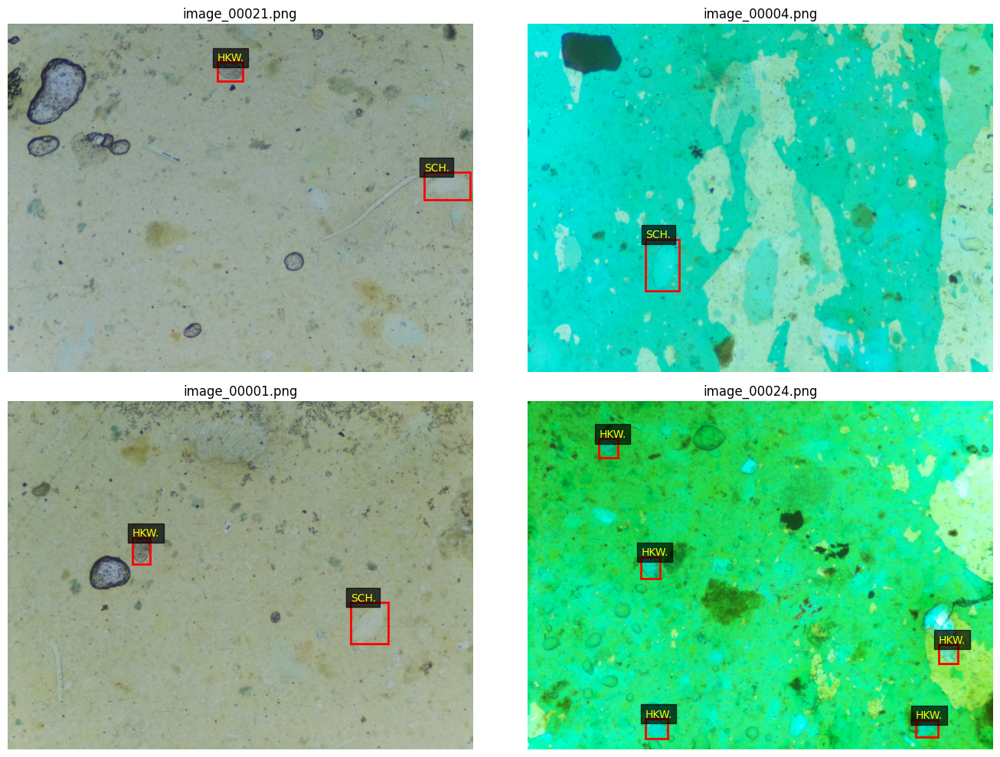

In [ ]:

import json
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image

BASE = Path("/content/helminth_data")
IMG_DIR = BASE / "images"
ANN_DIR = BASE / "annotations"

files = sorted(ANN_DIR.glob("*.json"))
random.seed(42)
chosen = random.sample(files, min(4, len(files)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, ann_path in zip(axes, chosen):
    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    img_path = IMG_DIR / data["filename"]
    img = Image.open(img_path).convert("RGB")
    ax.imshow(img)

    for obj in data.get("objects", []):
        x1, y1, x2, y2 = obj["bbox"]
        rect = patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=2, edgecolor="red", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, max(0, y1-8), obj["label"],
                color="yellow", fontsize=10,
                bbox=dict(facecolor="black", alpha=0.7))

    ax.set_title(data["filename"])
    ax.axis("off")

plt.tight_layout()
plt.show()


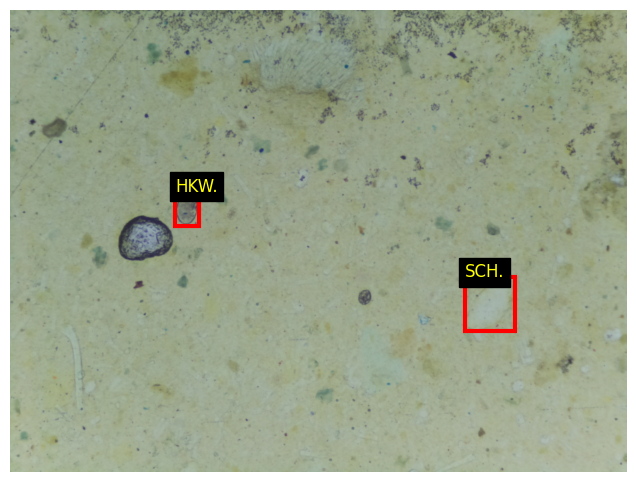

Visualization test complete.


In [ ]:

%matplotlib inline

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import json

base = Path("/content/helminth_data")
ann_file = sorted((base / "annotations").glob("*.json"))[0]

with open(ann_file, "r") as f:
    data = json.load(f)

img = Image.open(base / "images" / data["filename"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(img)

for obj in data["objects"]:
    x1, y1, x2, y2 = obj["bbox"]
    rect = plt.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="red", linewidth=3
    )
    ax.add_patch(rect)
    ax.text(x1, y1, obj["label"], color="yellow",
            fontsize=12, backgroundcolor="black")

ax.axis("off")
plt.show()
print("Visualization test complete.")


In [ ]:

!pip -q install ultralytics
print("Ultralytics installation complete.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 7.1 MB/s eta 0:00:00
Ultralytics installation complete.


In [ ]:

import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected — CPU training will be slower.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.178
CUDA available: False
GPU not detected — CPU training will be slower.


In [ ]:

import json
import random
import shutil
from pathlib import Path
from PIL import Image

random.seed(42)

SOURCE = Path("/content/helminth_data")
OUTPUT = Path("/content/helminth_yolo")

# Two classes confirmed so far in the 24-image sample
class_names = ["HKW.", "SCH."]

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in ["train", "val"]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

annotations = sorted((SOURCE / "annotations").glob("*.json"))
random.shuffle(annotations)

split_index = max(1, int(len(annotations) * 0.8))
splits = {
    "train": annotations[:split_index],
    "val": annotations[split_index:]
}

for split, files in splits.items():
    for ann_file in files:
        with open(ann_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        image_name = data["filename"]
        src_image = SOURCE / "images" / image_name

        if not src_image.exists():
            continue

        shutil.copy2(src_image, OUTPUT / "images" / split / image_name)

        image = Image.open(src_image)
        width, height = image.size
        image.close()

        label_file = OUTPUT / "labels" / split / f"{ann_file.stem}.txt"

        with open(label_file, "w", encoding="utf-8") as out:
            for obj in data.get("objects", []):
                label = obj.get("label")
                if label not in class_names:
                    continue

                x1, y1, x2, y2 = obj["bbox"]

                # YOLO: class, x_center, y_center, width, height
                x_center = ((x1 + x2) / 2) / width
                y_center = ((y1 + y2) / 2) / height
                box_width = (x2 - x1) / width
                box_height = (y2 - y1) / height

                out.write(
                    f"{class_names.index(label)} "
                    f"{x_center:.6f} {y_center:.6f} "
                    f"{box_width:.6f} {box_height:.6f}\n"
                )

yaml_text = """path: /content/helminth_yolo
train: images/train
val: images/val
names:
  0: HKW.
  1: SCH.
"""

(OUTPUT / "dataset.yaml").write_text(yaml_text, encoding="utf-8")

print("Dataset preparation complete.")
for split in ["train", "val"]:
    image_count = len(list((OUTPUT / "images" / split).glob("*.png")))
    print(f"{split}: {image_count} images")

print("Config:", OUTPUT / "dataset.yaml")


Dataset preparation complete.
train: 19 images
val: 5 images
Config: /content/helminth_yolo/dataset.yaml


In [ ]:

from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/helminth_yolo/dataset.yaml",
    epochs=5,
    imgsz=320,
    batch=2,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_prototype",
    exist_ok=True,
    patience=5,
    plots=True
)

print("Training finished.")
print("Best model: /content/helminth_runs/helminth_prototype/weights/best.pt")


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helminth_yolo/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helminth_prototype, nbs=64, nms=None, opset=None, opt

Results saved to /content/helminth_runs/validation_predictions


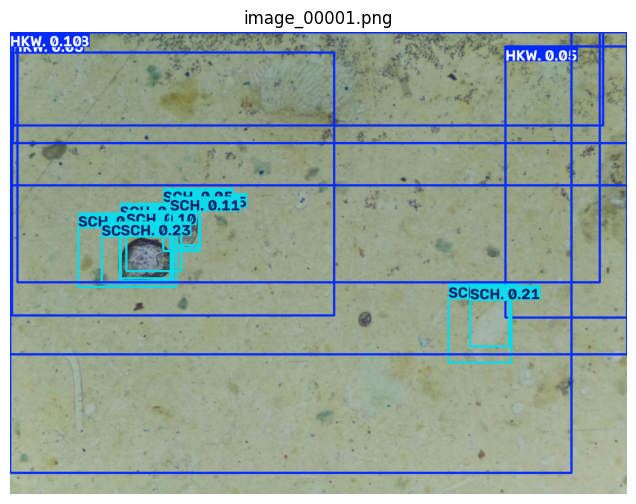

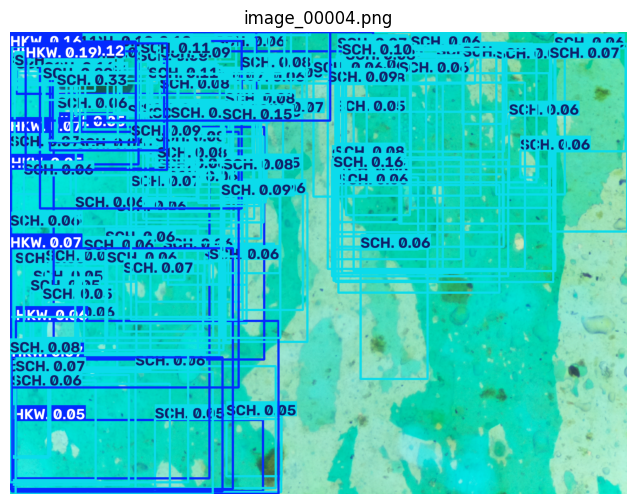

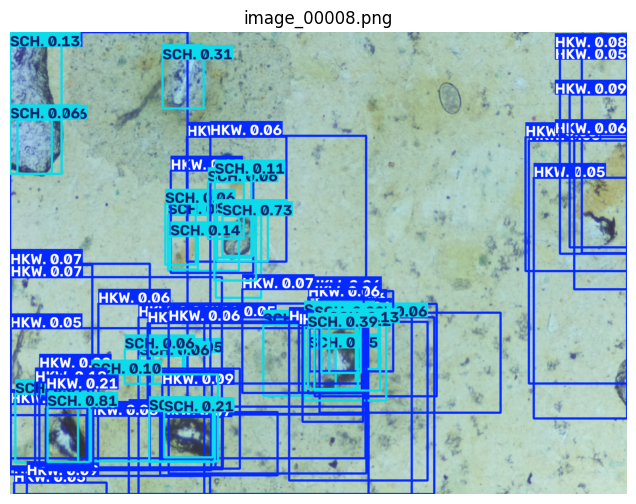

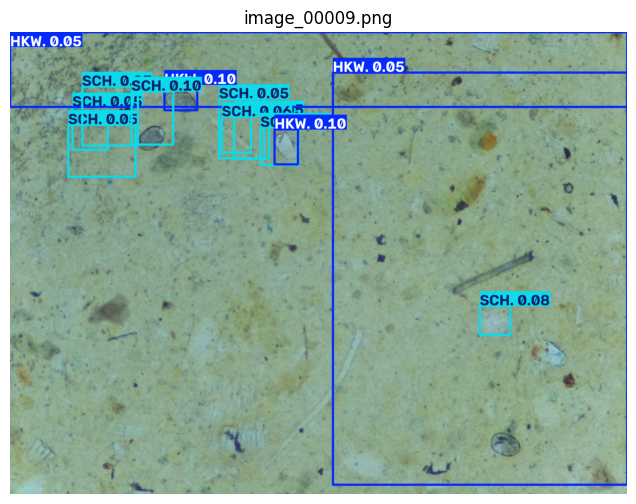

Prediction images saved to:
/content/helminth_runs/validation_predictions


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

model = YOLO(
    "/content/helminth_runs/helminth_prototype/weights/best.pt"
)

val_dir = Path("/content/helminth_yolo/images/val")
image_paths = sorted(val_dir.glob("*.png"))

results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.05,
    device="cpu",
    save=True,
    project="/content/helminth_runs",
    name="validation_predictions",
    exist_ok=True,
    verbose=False
)

for result in results[:4]:
    plotted = result.plot()
    plt.figure(figsize=(10, 6))
    plt.imshow(plotted[:, :, ::-1])
    plt.title(Path(result.path).name)
    plt.axis("off")
    plt.show()

print("Prediction images saved to:")
print("/content/helminth_runs/validation_predictions")


In [ ]:

from pathlib import Path
import shutil
import json

PROJECT = Path("/content/helminth-detection-project")

if PROJECT.exists():
    shutil.rmtree(PROJECT)

(PROJECT / "src").mkdir(parents=True)
(PROJECT / "results").mkdir(parents=True)
(PROJECT / "models").mkdir(parents=True)

readme = """# Helminth Egg Detection Using YOLO11

## Overview
A prototype computer-vision project for detecting annotated
helminth eggs in microscopy images using Ultralytics YOLO11n.

## Current experiment
- Dataset source: https://zenodo.org/records/13843815
- Images used in this prototype: 24
- Training images: 19
- Validation images: 5
- Classes in this sample: HKW. and SCH.
- Epochs: 5
- Image size: 320
- Device: CPU
- Model: YOLO11n pretrained weights

## Preliminary validation results
From this small validation run:
- Precision: 0.0231
- Recall: 0.25
- mAP@50: 0.0319
- mAP@50-95: 0.0124

These results are preliminary and unreliable due to the tiny
sample. They must not be interpreted as clinical performance.
The experiment is a pipeline prototype, not a validated diagnostic tool.

## Dataset preparation
The source dataset is distributed by its authors via Zenodo.
Review the dataset's license and citation requirements before use.
This repository does not redistribute the original dataset.

## Reproduce the prototype
1. Install Python and dependencies.
2. Download the dataset from the source above.
3. Convert per-image JSON `objects` bounding boxes to YOLO labels.
4. Prepare `dataset.yaml`.
5. Train using Ultralytics YOLO11n.

Example training command:
`yolo detect train model=yolo11n.pt data=dataset.yaml epochs=5 imgsz=320 device=cpu`

## Limitations
- Only 24 images were used.
- Only two labels were included in this prototype.
- The validation set contains only five images.
- No independent test set or external validation was performed.
- Not intended for clinical diagnosis.

## Citation
Oyibo et al. (2025), Scientific Reports.
https://doi.org/10.1038/s41598-025-02755-9

Dataset DOI: https://doi.org/10.5281/zenodo.13843815
"""

(PROJECT / "README.md").write_text(readme, encoding="utf-8")

requirements = """ultralytics==8.4.178
torch>=2.0
Pillow
matplotlib
"""

(PROJECT / "requirements.txt").write_text(requirements, encoding="utf-8")

experiment = {
    "model": "YOLO11n",
    "images_total": 24,
    "train_images": 19,
    "validation_images": 5,
    "classes": ["HKW.", "SCH."],
    "epochs": 5,
    "image_size": 320,
    "device": "CPU",
    "validation_metrics": {
        "precision": 0.0231,
        "recall": 0.25,
        "mAP50": 0.0319,
        "mAP50_95": 0.0124
    },
    "limitations": [
        "Very small validation set",
        "Only two classes in the prototype",
        "No independent test set",
        "Not clinically validated"
    ]
}

(PROJECT / "results" / "prototype_metrics.json").write_text(
    json.dumps(experiment, indent=2),
    encoding="utf-8"
)

# Copy trained model weights and prediction images
best = Path("/content/helminth_runs/helminth_prototype/weights/best.pt")
if best.exists():
    shutil.copy2(best, PROJECT / "models" / "best.pt")

predictions = Path("/content/helminth_runs/validation_predictions")
if predictions.exists():
    shutil.copytree(
        predictions,
        PROJECT / "results" / "predictions",
        dirs_exist_ok=True
    )

zip_path = shutil.make_archive(
    "/content/helminth-detection-project",
    "zip",
    root_dir=PROJECT
)

print("Project folder:", PROJECT)
print("ZIP created:", zip_path)
print("Files:")
for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT))


Project folder: /content/helminth-detection-project
ZIP created: /content/helminth-detection-project.zip
Files:
README.md
models/best.pt
requirements.txt
results/predictions/image_00001.jpg
results/predictions/image_00004.jpg
results/predictions/image_00008.jpg
results/predictions/image_00009.jpg
results/predictions/image_00021.jpg
results/prototype_metrics.json


In [ ]:

from pathlib import Path
import shutil
from google.colab import files

PROJECT = Path("/content/helminth-detection-project")
SRC = PROJECT / "src"
SRC.mkdir(exist_ok=True)

(SRC / "prepare_dataset.py").write_text(r'''
import json
import random
import shutil
from pathlib import Path
from PIL import Image

SOURCE = Path("/content/helminth_data")
OUTPUT = Path("/content/helminth_yolo")
CLASSES = ["HKW.", "SCH."]

random.seed(42)
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

annotations = sorted((SOURCE / "annotations").glob("*.json"))
random.shuffle(annotations)
cut = max(1, int(len(annotations) * 0.8))

for split, subset in [
    ("train", annotations[:cut]),
    ("val", annotations[cut:])
]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

    for ann_path in subset:
        data = json.loads(ann_path.read_text(encoding="utf-8"))
        image_path = SOURCE / "images" / data["filename"]
        if not image_path.exists():
            continue

        shutil.copy2(image_path, OUTPUT / "images" / split / image_path.name)

        with Image.open(image_path) as img:
            width, height = img.size

        lines = []
        for obj in data.get("objects", []):
            if obj.get("label") not in CLASSES:
                continue
            x1, y1, x2, y2 = obj["bbox"]
            if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
                continue

            xc, yc = ((x1+x2)/2)/width, ((y1+y2)/2)/height
            bw, bh = (x2-x1)/width, (y2-y1)/height
            lines.append(
                f"{CLASSES.index(obj['label'])} "
                f"{xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )

        (OUTPUT / "labels" / split / f"{ann_path.stem}.txt").write_text(
            "\n".join(lines), encoding="utf-8"
        )

(OUTPUT / "dataset.yaml").write_text(
    "path: /content/helminth_yolo\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n  0: HKW.\n  1: SCH.\n",
    encoding="utf-8"
)
print("Dataset prepared:", OUTPUT)
''', encoding="utf-8")

(SRC / "train.py").write_text(r'''
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
model.train(
    data="/content/helminth_yolo/dataset.yaml",
    epochs=5,
    imgsz=320,
    batch=2,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_prototype",
    exist_ok=True,
    seed=42
)
''', encoding="utf-8")

(SRC / "predict.py").write_text(r'''
from ultralytics import YOLO

model = YOLO("models/best.pt")
model.predict(
    source="/content/helminth_yolo/images/val",
    imgsz=320,
    conf=0.05,
    device="cpu",
    save=True,
    project="runs",
    name="predictions",
    exist_ok=True
)
''', encoding="utf-8")

zip_path = "/content/helminth-detection-project.zip"
Path(zip_path).unlink(missing_ok=True)
shutil.make_archive(
    zip_path.removesuffix(".zip"),
    "zip",
    root_dir=PROJECT
)

size_mb = Path(zip_path).stat().st_size / (1024 * 1024)
print(f"Final ZIP size: {size_mb:.2f} MB")
print("Starting download...")
files.download(zip_path)


Final ZIP size: 8.82 MB
Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import shutil

print("Dataset images:", len(list(Path("/content/helminth_data/images").glob("*.png"))))
print("Annotation files:", len(list(Path("/content/helminth_data/annotations").glob("*.json"))))

model_path = Path("/content/helminth_runs/helminth_prototype/weights/best.pt")
project_zip = Path("/content/helminth-detection-project.zip")

print("Trained model exists:", model_path.exists())
print("Project ZIP exists:", project_zip.exists())

if project_zip.exists():
    print("Project ZIP size (MB):", round(project_zip.stat().st_size / (1024 * 1024), 2))

total, used, free = shutil.disk_usage("/content")
print("Free Colab storage (GB):", round(free / (1024**3), 2))


Dataset images: 24
Annotation files: 24
Trained model exists: True
Project ZIP exists: True
Project ZIP size (MB): 8.82
Free Colab storage (GB): 86.95


In [ ]:

!pip -q install remotezip

import json
import random
from collections import Counter
from remotezip import RemoteZip

URL = (
    "https://zenodo.org/api/records/13843815/files/"
    "STH_and_SM_Dataset_v1_0.zip/content"
)

BASE = "STH_and_SM_Dataset_v1_0"
random.seed(42)

with RemoteZip(URL) as zf:
    json_files = [
        name for name in zf.namelist()
        if name.startswith(BASE + "/annotations/")
        and name.endswith(".json")
    ]

    sample_files = random.sample(json_files, min(100, len(json_files)))
    class_counts = Counter()
    images_with_objects = 0

    for i, name in enumerate(sample_files, 1):
        with zf.open(name) as f:
            data = json.load(f)

        objects = data.get("objects", [])
        if objects:
            images_with_objects += 1

        for obj in objects:
            class_counts[obj.get("label", "UNKNOWN")] += 1

        if i % 25 == 0:
            print(f"Checked {i}/{len(sample_files)} annotation files")

print("\nRandom sample size:", len(sample_files))
print("Images containing annotations:", images_with_objects)
print("Egg/object counts by label:")
for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")


Checked 25/100 annotation files
Checked 50/100 annotation files
Checked 75/100 annotation files
Checked 100/100 annotation files

Random sample size: 100
Images containing annotations: 100
Egg/object counts by label:
ASC.: 86
HKW.: 34
SCH.: 42
TRI.: 39


In [ ]:

!pip -q install remotezip

import json
import random
import shutil
from pathlib import Path
from remotezip import RemoteZip

URL = (
    "https://zenodo.org/api/records/13843815/files/"
    "STH_and_SM_Dataset_v1_0.zip/content"
)
BASE = "STH_and_SM_Dataset_v1_0"
OUT = Path("/content/helminth_4class")
CLASSES = ["ASC.", "HKW.", "SCH.", "TRI."]

random.seed(42)

if OUT.exists():
    shutil.rmtree(OUT)

for split in ["train", "val", "test"]:
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

with RemoteZip(URL) as zf:
    members = set(zf.namelist())
    annotation_names = sorted(
        n for n in members
        if n.startswith(BASE + "/annotations/")
        and n.endswith(".json")
    )
    random.shuffle(annotation_names)

    # Scan until 400 images with annotations are selected.
    selected = []
    for ann_name in annotation_names:
        with zf.open(ann_name) as f:
            data = json.load(f)

        if any(obj.get("label") in CLASSES for obj in data.get("objects", [])):
            selected.append((ann_name, data))

        if len(selected) >= 400:
            break

    print("Selected annotated images:", len(selected))

    # Split by image before converting annotations.
    n = len(selected)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    split_items = {
        "train": selected[:n_train],
        "val": selected[n_train:n_train+n_val],
        "test": selected[n_train+n_val:]
    }

    for split, items in split_items.items():
        for i, (ann_name, data) in enumerate(items, 1):
            image_name = data["filename"]
            image_member = f"{BASE}/images/{image_name}"

            with zf.open(image_member) as src:
                image_bytes = src.read()

            image_path = OUT / "images" / split / image_name
            image_path.write_bytes(image_bytes)

            # Save per-image annotation temporarily for auditability.
            (OUT / "labels" / split / f"{Path(image_name).stem}.json").write_text(
                json.dumps(data, indent=2), encoding="utf-8"
            )

            if i % 50 == 0:
                print(f"{split}: {i}/{len(items)} images extracted")

print("\nExtraction complete.")
for split in ["train", "val", "test"]:
    print(split, "images:", len(list((OUT / "images" / split).glob("*.png"))))
print("Dataset location:", OUT)


Selected annotated images: 400
train: 50/280 images extracted
train: 100/280 images extracted
train: 150/280 images extracted
train: 200/280 images extracted
train: 250/280 images extracted
val: 50/60 images extracted
test: 50/60 images extracted

Extraction complete.
train images: 280
val images: 60
test images: 60
Dataset location: /content/helminth_4class


In [ ]:

import json
from pathlib import Path
from collections import Counter

import yaml

OUT = Path("/content/helminth_4class")
CLASSES = ["ASC.", "HKW.", "SCH.", "TRI."]

counts = Counter()
total = 0

for split in ["train", "val", "test"]:
    for ann_path in sorted((OUT / "labels" / split).glob("*.json")):
        data = json.loads(ann_path.read_text(encoding="utf-8"))
        w = data["size"]["width"]
        h = data["size"]["height"]
        lines = []

        for obj in data.get("objects", []):
            label = obj.get("label")
            if label not in CLASSES:
                continue

            x1, y1, x2, y2 = obj["bbox"]
            if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h):
                continue

            xc, yc = ((x1+x2)/2)/w, ((y1+y2)/2)/h
            bw, bh = (x2-x1)/w, (y2-y1)/h
            lines.append(
                f"{CLASSES.index(label)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )
            counts[(split, label)] += 1
            total += 1

        txt_path = OUT / "labels" / split / f"{ann_path.stem}.txt"
        txt_path.write_text("\n".join(lines), encoding="utf-8")
        ann_path.unlink()

config = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(CLASSES)}
}
(OUT / "dataset.yaml").write_text(
    yaml.safe_dump(config, sort_keys=False), encoding="utf-8"
)

print("YOLO dataset prepared.")
for split in ["train", "val", "test"]:
    print(split, "images:", len(list((OUT / "images" / split).glob("*.png"))))
print("Total valid objects:", total)
print("Class counts by split:")
for key, value in sorted(counts.items()):
    print(key, value)


YOLO dataset prepared.
train images: 280
val images: 60
test images: 60
Total valid objects: 805
Class counts by split:
('test', 'ASC.') 45
('test', 'HKW.') 21
('test', 'SCH.') 25
('test', 'TRI.') 22
('train', 'ASC.') 242
('train', 'HKW.') 129
('train', 'SCH.') 110
('train', 'TRI.') 94
('val', 'ASC.') 50
('val', 'HKW.') 20
('val', 'SCH.') 20
('val', 'TRI.') 27


In [ ]:

import json
from pathlib import Path
from collections import Counter
import yaml

OUT = Path("/content/helminth_4class")
CLASSES = ["ASC.", "HKW.", "SCH.", "TRI."]
counts = Counter()

for split in ["train", "val", "test"]:
    for ann in sorted((OUT / "labels" / split).glob("*.json")):
        data = json.loads(ann.read_text())
        w, h = data["size"]["width"], data["size"]["height"]
        lines = []

        for obj in data.get("objects", []):
            label = obj.get("label")
            if label not in CLASSES:
                continue

            x1, y1, x2, y2 = obj["bbox"]
            if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h):
                continue

            xc, yc = ((x1+x2)/2)/w, ((y1+y2)/2)/h
            bw, bh = (x2-x1)/w, (y2-y1)/h
            lines.append(
                f"{CLASSES.index(label)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )
            counts[(split, label)] += 1

        (OUT / "labels" / split / f"{ann.stem}.txt").write_text(
            "\n".join(lines)
        )
        ann.unlink()

config = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(CLASSES)}
}
(OUT / "dataset.yaml").write_text(yaml.safe_dump(config, sort_keys=False))

print("YOLO dataset prepared.")
for split in ["train", "val", "test"]:
    print(split, "images:", len(list((OUT / "images" / split).glob("*.png"))))
print("\nObject counts:")
for (split, label), count in sorted(counts.items()):
    print(f"{split:5} | {label:5} | {count}")
print("\nConfig:", OUT / "dataset.yaml")


YOLO dataset prepared.
train images: 280
val images: 60
test images: 60

Object counts:

Config: /content/helminth_4class/dataset.yaml


In [ ]:

from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.train(
    data="/content/helminth_4class/dataset.yaml",
    epochs=15,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_4class",
    exist_ok=True,
    seed=42,
    plots=True,
    patience=5
)

print("4-class training complete.")
print("Best model: /content/helminth_runs/helminth_4class/weights/best.pt")


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helminth_4class/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helminth_4class, nbs=64, nms=None, opset=None, opt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

source = "/content/helminth_runs/helminth_4class"
destination = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training"

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copytree(source, destination, dirs_exist_ok=True)

print("Training backup saved to Google Drive.")
print("Best model:", os.path.join(destination, "weights", "best.pt"))
print("Model exists:", os.path.exists(os.path.join(destination, "weights", "best.pt")))

Mounted at /content/drive
Training backup saved to Google Drive.
Best model: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt
Model exists: True


In [ ]:
from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt"
data_path = "/content/helminth_4class/dataset.yaml"

# Check files
print("Model exists:", os.path.exists(model_path))
print("Dataset exists:", os.path.exists(data_path))

# Load trained model
model = YOLO(model_path)

# Evaluate on untouched test set
metrics = model.val(
    data=data_path,
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    plots=True,
    project="/content/helminth_runs",
    name="helminth_4class_test",
    exist_ok=True
)

print("\n===== FINAL TEST RESULTS =====")
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP@50:", round(metrics.box.map50, 4))
print("mAP@50-95:", round(metrics.box.map, 4))
print("Per-class AP@50:", metrics.box.ap50)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

model_path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt"

print("Model found:", os.path.exists(model_path))

Model found: True


In [ ]:
from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt"
data_path = "/content/helminth_4class/dataset.yaml"

# Check files
print("Model exists:", os.path.exists(model_path))
print("Dataset exists:", os.path.exists(data_path))

# Load trained model
model = YOLO(model_path)

# Evaluate on untouched test set
metrics = model.val(
    data=data_path,
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    plots=True,
    project="/content/helminth_runs",
    name="helminth_4class_test",
    exist_ok=True
)

print("\n===== FINAL TEST RESULTS =====")
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP@50:", round(metrics.box.map50, 4))
print("mAP@50-95:", round(metrics.box.map, 4))
print("Per-class AP@50:", metrics.box.ap50)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model exists: True
Dataset exists: False
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs


FileNotFoundError: '/content/helminth_4class/dataset.yaml' does not exist

In [ ]:
import os

base = "/content/drive/MyDrive/Helminth_Project_Backup"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:8]:
            print("  " * (level + 1) + f)

Helminth_Project_Backup/
  helminth_4class_training/
    args.yaml
    labels.jpg
    train_batch0.jpg
    train_batch1.jpg
    train_batch2.jpg
    train_batch350.jpg
    train_batch351.jpg
    train_batch352.jpg
    weights/
      best.pt
      last.pt


In [ ]:
import os

for path in [
    "/content/helminth_4class",
    "/content/helminth_data",
    "/content/helminth_yolo",
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class"
]:
    print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")

/content/helminth_4class NOT FOUND
/content/helminth_data NOT FOUND
/content/helminth_yolo NOT FOUND
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class NOT FOUND


In [ ]:
!pip install -q remotezip

In [ ]:
import requests

url = "https://zenodo.org/api/records/13843815"

r = requests.get(url, timeout=30)
print("Status:", r.status_code)

if r.ok:
    data = r.json()
    for f in data["files"]:
        print(f["key"], round(f["size"] / (1024**3), 2), "GB")
else:
    print(r.text[:500])

Status: 200
STH_and_SM_Dataset_v1_0.zip 33.48 GB


In [ ]:
!pip install -q remotezip

In [ ]:
import os, json, random, shutil
from remotezip import RemoteZip
from collections import Counter

URL = "https://zenodo.org/api/records/13843815/files/STH_and_SM_Dataset_v1_0.zip/content"
OUT = "/content/helminth_4class_recovered"
random.seed(42)

os.makedirs(f"{OUT}/images", exist_ok=True)
os.makedirs(f"{OUT}/annotations", exist_ok=True)

with RemoteZip(URL) as z:
    files = z.namelist()
    json_files = [f for f in files if f.lower().endswith(".json")]
    print("JSON files found:", len(json_files))

    random.shuffle(json_files)
    selected = []

    for jf in json_files:
        try:
            ann = json.loads(z.read(jf))
            objects = ann.get("objects", [])
            img_name = ann.get("filename")

            if not img_name or not objects:
                continue

            # Find corresponding image inside the ZIP
            candidates = [
                f for f in files
                if f.lower().endswith(".png")
                and f.rsplit("/", 1)[-1] == img_name
            ]
            if not candidates:
                continue

            selected.append((jf, candidates[0], ann))
            if len(selected) >= 400:
                break
        except Exception:
            continue

    print("Selected pairs:", len(selected))

    if len(selected) < 100:
        raise RuntimeError("Too few pairs recovered; stop and inspect archive structure.")

    random.shuffle(selected)
    splits = {
        "train": selected[:int(len(selected)*0.70)],
        "val": selected[int(len(selected)*0.70):int(len(selected)*0.85)],
        "test": selected[int(len(selected)*0.85):]
    }

    counts = Counter()
    for split, items in splits.items():
        os.makedirs(f"{OUT}/images/{split}", exist_ok=True)
        os.makedirs(f"{OUT}/annotations/{split}", exist_ok=True)

        for i, (jf, img_path, ann) in enumerate(items):
            img_name = os.path.basename(img_path)
            stem = f"{split}_{i:04d}_{os.path.splitext(img_name)[0]}"

            with open(f"{OUT}/images/{split}/{stem}.png", "wb") as f:
                f.write(z.read(img_path))

            with open(f"{OUT}/annotations/{split}/{stem}.json", "w") as f:
                json.dump(ann, f)

            for obj in ann.get("objects", []):
                counts[(split, obj.get("label", "UNKNOWN"))] += 1

        print(split, "images:", len(items))

print("Class/object counts:")
for k, v in sorted(counts.items()):
    print(k, v)

print("Recovered dataset at:", OUT)

JSON files found: 10562
Selected pairs: 400
train images: 280
val images: 60
test images: 60
Class/object counts:
('test', 'ASC.') 66
('test', 'HKW.') 30
('test', 'SCH.') 22
('test', 'TRI.') 29
('train', 'ASC.') 226
('train', 'HKW.') 129
('train', 'SCH.') 108
('train', 'TRI.') 85
('val', 'ASC.') 44
('val', 'HKW.') 16
('val', 'SCH.') 25
('val', 'TRI.') 29
Recovered dataset at: /content/helminth_4class_recovered


In [ ]:

import os
import json
import shutil
import yaml
from collections import Counter

root = "/content/helminth_4class_recovered"
class_names = ["ASC.", "HKW.", "SCH.", "TRI."]
class_to_id = {name: i for i, name in enumerate(class_names)}
counts = Counter()

for split in ["train", "val", "test"]:
    image_dir = f"{root}/images/{split}"
    ann_dir = f"{root}/annotations/{split}"
    label_dir = f"{root}/labels/{split}"
    os.makedirs(label_dir, exist_ok=True)

    for ann_file in os.listdir(ann_dir):
        if not ann_file.endswith(".json"):
            continue

        ann_path = os.path.join(ann_dir, ann_file)
        with open(ann_path, "r") as f:
            data = json.load(f)

        # Images were saved using the annotation file's stem
        stem = os.path.splitext(ann_file)[0]
        image_path = os.path.join(image_dir, stem + ".png")

        if not os.path.exists(image_path):
            print("Image missing:", image_path)
            continue

        width = data.get("size", {}).get("width")
        height = data.get("size", {}).get("height")

        if not width or not height:
            from PIL import Image
            with Image.open(image_path) as im:
                width, height = im.size

        lines = []
        for obj in data.get("objects", []):
            label = obj.get("label")
            bbox = obj.get("bbox")

            if label not in class_to_id or not bbox or len(bbox) != 4:
                continue

            x1, y1, x2, y2 = map(float, bbox)
            x1, x2 = max(0, min(x1, width)), max(0, min(x2, width))
            y1, y2 = max(0, min(y1, height)), max(0, min(y2, height))

            if x2 <= x1 or y2 <= y1:
                continue

            xc = ((x1 + x2) / 2) / width
            yc = ((y1 + y2) / 2) / height
            bw = (x2 - x1) / width
            bh = (y2 - y1) / height

            lines.append(
                f"{class_to_id[label]} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )
            counts[(split, label)] += 1

        label_path = os.path.join(label_dir, stem + ".txt")
        with open(label_path, "w") as f:
            f.write("\n".join(lines))

# Create dataset configuration
dataset_yaml = {
    "path": root,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(class_names)}
}
with open(f"{root}/dataset.yaml", "w") as f:
    yaml.safe_dump(dataset_yaml, f, sort_keys=False)

print("YOLO labels created.")
print("Object counts:")
for key, value in sorted(counts.items()):
    print(key, value)

# Save full recovered dataset to Google Drive
from google.colab import drive
drive.mount("/content/drive")

backup = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
shutil.copytree(root, backup, dirs_exist_ok=True)

print("\nDataset backup copied to Google Drive.")
print("Dataset YAML:", f"{root}/dataset.yaml")
print("YAML exists:", os.path.exists(f"{root}/dataset.yaml"))
print("Drive backup exists:", os.path.exists(backup))


YOLO labels created.
Object counts:
('test', 'ASC.') 66
('test', 'HKW.') 30
('test', 'SCH.') 22
('test', 'TRI.') 29
('train', 'ASC.') 226
('train', 'HKW.') 129
('train', 'SCH.') 108
('train', 'TRI.') 85
('val', 'ASC.') 44
('val', 'HKW.') 16
('val', 'SCH.') 25
('val', 'TRI.') 29
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Dataset backup copied to Google Drive.
Dataset YAML: /content/helminth_4class_recovered/dataset.yaml
YAML exists: True
Drive backup exists: True


In [ ]:

from ultralytics import YOLO
import os

data_path = "/content/helminth_4class_recovered/dataset.yaml"

assert os.path.exists(data_path), "Dataset YAML not found!"

model = YOLO("yolo11n.pt")

model.train(
    data=data_path,
    epochs=15,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_recovered_v2",
    seed=42,
    patience=5,
    plots=True
)

print("Training complete.")
print("Best model: /content/helminth_runs/helminth_recovered_v2/weights/best.pt")


New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helminth_4class_recovered/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

In [ ]:

import os
import shutil

source = "/content/helminth_runs/helminth_recovered_v2"
destination = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2"

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copytree(source, destination, dirs_exist_ok=True)

best_model = os.path.join(destination, "weights", "best.pt")
print("Backup complete:", os.path.exists(best_model))
print("Saved model:", best_model)


Backup complete: True
Saved model: /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt


In [ ]:
from ultralytics import YOLO
import os
import json
import shutil

model_path = "/content/helminth_runs/helminth_recovered_v2/weights/best.pt"
data_path = "/content/helminth_4class_recovered/dataset.yaml"

model = YOLO(model_path)

metrics = model.val(
    data=data_path,
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    plots=True,
    project="/content/helminth_runs",
    name="helminth_recovered_v2_test",
    exist_ok=True
)

results = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "per_class_AP50": [float(x) for x in metrics.box.ap50]
}

print("\nFINAL TEST RESULTS")
print(json.dumps(results, indent=2))

result_dir = "/content/helminth_runs/helminth_recovered_v2_test"
with open(os.path.join(result_dir, "test_metrics.json"), "w") as f:
    json.dump(results, f, indent=2)

drive_result = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2_test"
shutil.copytree(result_dir, drive_result, dirs_exist_ok=True)

print("\nTest results backed up to Google Drive.")

Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 413.0±281.2 MB/s, size: 3292.5 KB)
val: Scanning /content/helminth_4class_recovered/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 86.4it/s 0.7s
val: New cache created: /content/helminth_4class_recovered/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.7it/s 8.8s
                   all         60        147      0.748      0.644      0.725      0.553
                  ASC.         24         66      0.815      0.939      0.953      0.768
                  HKW.         11         30      0.635      0.533      0.549      0.463
                  SCH.         21         22      0.717      0.461      0.589       0.37
                  TRI.         17         29    

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt"
)

metrics = model.val(
    data="/content/helminth_4class_recovered/dataset.yaml",
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    plots=False
)

print("Confusion matrix:")
print(metrics.confusion_matrix.matrix)
print("Class names:")
print(metrics.names)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.1 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
print("Ultralytics successfully installed!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics successfully installed!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base = "/content/drive/MyDrive/Helminth_Project_Backup"

for folder in [
    "helminth_recovered_v2",
    "helminth_recovered_v2_test"
]:
    path = os.path.join(base, folder)
    print(f"\n{folder}:")
    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("Folder not found")


helminth_recovered_v2:
['args.yaml', 'labels.jpg', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'weights', 'train_batch350.jpg', 'train_batch351.jpg', 'train_batch352.jpg', 'results.csv', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_pred.jpg', 'val_batch1_labels.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'BoxPR_curve.png', 'BoxF1_curve.png', 'BoxR_curve.png', 'BoxP_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png', 'results.png']

helminth_recovered_v2_test:
['val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_pred.jpg', 'val_batch2_labels.jpg', 'BoxPR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix_normalized.png', 'test_metrics.json', 'confusion_matrix.png']


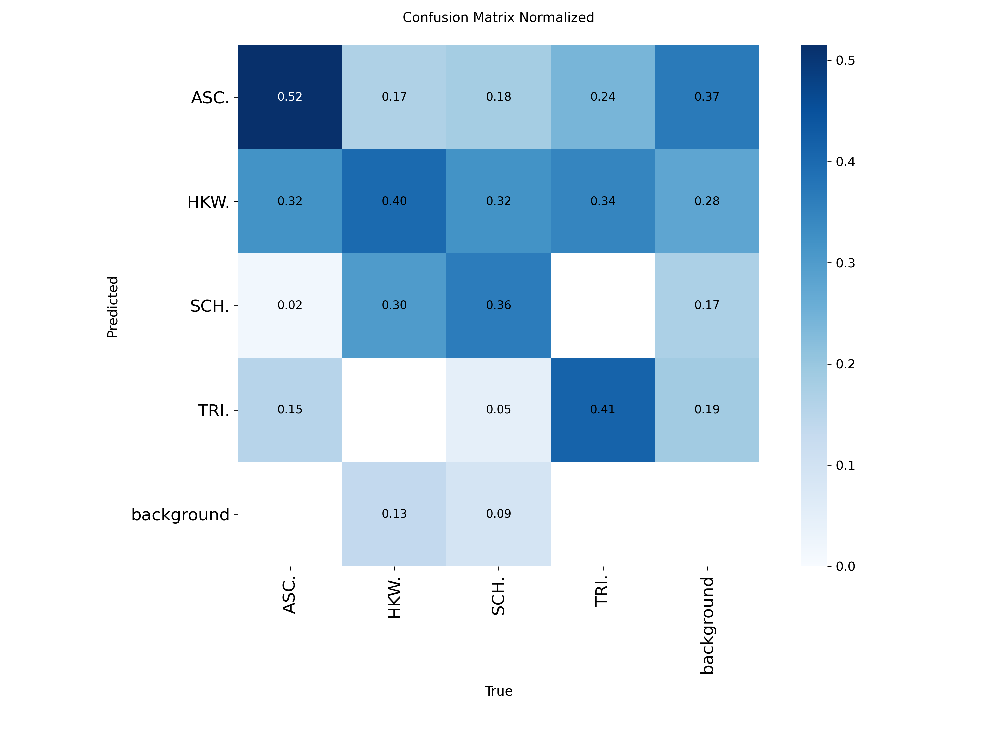

In [ ]:
from IPython.display import display, Image
import os

path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2_test/confusion_matrix_normalized.png"

display(Image(filename=path, width=750))

In [ ]:
import json

path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2_test/test_metrics.json"

with open(path, "r") as f:
    results = json.load(f)

for key, value in results.items():
    print(f"{key}: {value}")

precision: 0.7476582192726383
recall: 0.643997655073004
mAP50: 0.7249751223889056
mAP50_95: 0.5526411539654787
per_class_AP50: [0.9531692860788715, 0.5493164013171381, 0.5889631347439667, 0.8084516674156462]


In [ ]:
import pandas as pd
import os

output_dir = "/content/drive/MyDrive/Helminth_Project_Backup"
os.makedirs(output_dir, exist_ok=True)

df = pd.DataFrame({
    "Class": [
        "ASC. - Ascaris lumbricoides",
        "HKW. - Hookworm",
        "SCH. - Schistosoma mansoni",
        "TRI. - Trichuris trichiura"
    ],
    "AP50": [
        0.9531692860788715,
        0.5493164013171381,
        0.5889631347439667,
        0.8084516674156462
    ]
})

df["AP50_percent"] = (df["AP50"] * 100).round(2)

csv_path = os.path.join(output_dir, "classwise_test_results.csv")
df.to_csv(csv_path, index=False)

print(df[["Class", "AP50_percent"]].to_string(index=False))
print("\nSaved to:", csv_path)

                      Class  AP50_percent
ASC. - Ascaris lumbricoides         95.32
            HKW. - Hookworm         54.93
 SCH. - Schistosoma mansoni         58.90
 TRI. - Trichuris trichiura         80.85

Saved to: /content/drive/MyDrive/Helminth_Project_Backup/classwise_test_results.csv


In [ ]:
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup"
)
project_dir.mkdir(parents=True, exist_ok=True)

readme = r"""# Helminth Egg Detection Using YOLO11n

## Project overview
This project explores object detection for four helminth egg classes
in microscopy images using the YOLO11n object detection model.

## Dataset
Dataset: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset

Source: https://zenodo.org/records/13843815
DOI: https://doi.org/10.5281/zenodo.13843815

The experimental sample contains 400 selected image-annotation pairs.
The split used 280 training, 60 validation, and 60 test images.

## Model
- Architecture: YOLO11n
- Image size: 320 x 320
- Training epochs: 15
- Training device: CPU
- Classes: ASC., HKW., SCH., TRI.

## Held-out test results
- Precision: 0.748
- Recall: 0.644
- mAP@50: 0.725
- mAP@50-95: 0.553

## Per-class AP@50
| Class | AP@50 |
|---|---:|
| ASC. - Ascaris lumbricoides | 95.32% |
| HKW. - Hookworm | 54.93% |
| SCH. - Schistosoma mansoni | 58.90% |
| TRI. - Trichuris trichiura | 80.85% |

## Limitations
This is a preliminary experiment on a selected 400-image sample.
The results do not establish clinical diagnostic performance.
The random image-level split has not been verified as independent by
microscopy slide or source. Further leakage checks, baseline comparisons,
and external validation are needed before making

_IncompleteInputError: incomplete input (632199727.py, line 8)

In [ ]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/Helminth_Project_Backup")
project_dir.mkdir(parents=True, exist_ok=True)

readme = """# Helminth Egg Detection Using YOLO11n

## Project Overview
This project explores detection of four helminth egg classes
in microscopy images using the YOLO11n object detection model.

## Dataset
Name: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset
Source: https://zenodo.org/records/13843815
DOI: https://doi.org/10.5281/zenodo.13843815

Experimental sample: 400 selected image-annotation pairs.
Training: 280 images
Validation: 60 images
Testing: 60 images

## Model
- Architecture: YOLO11n
- Image size: 320 x 320
- Training epochs: 15
- Device: CPU
- Classes: ASC., HKW., SCH., TRI.

## Held-out Test Results
- Precision: 74.77%
- Recall: 64.40%
- mAP@50: 72.50%
- mAP@50-95: 55.26%

## Per-Class AP@50
| Class | AP@50 |
|---|---:|
| ASC. - Ascaris lumbricoides | 95.32% |
| HKW. - Hookworm | 54.93% |
| SCH. - Schistosoma mansoni | 58.90% |
| TRI. - Trichuris trichiura | 80.85% |

## Limitations
This is a preliminary experiment on a selected 400-image sample.
These results do not establish clinical diagnostic performance.
Independence by microscopy slide or image source has not been verified.
Further leakage checks, baseline comparisons, and external validation
are needed before making generalization claims.

## Citation
Oyibo et al. (2025), Scientific Reports.
https://doi.org/10.1038/s41598-025-02755-9

Dataset DOI: https://doi.org/10.5281/zenodo.13843815
"""

readme_path = project_dir / "README.md"
readme_path.write_text(readme, encoding="utf-8")

print("README saved:", readme_path)
print("File exists:", readme_path.exists())
print("Size:", readme_path.stat().st_size, "bytes")

README saved: /content/drive/MyDrive/Helminth_Project_Backup/README.md
File exists: True
Size: 1395 bytes


In [ ]:
import os

base = "/content/drive/MyDrive/Helminth_Project_Backup"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

Helminth_Project_Backup/
  classwise_test_results.csv
  README.md
  helminth_4class_training/
    args.yaml
    labels.jpg
    train_batch0.jpg
    train_batch1.jpg
    train_batch2.jpg
    train_batch350.jpg
    train_batch351.jpg
    train_batch352.jpg
    results.csv
    val_batch0_labels.jpg
    val_batch0_pred.jpg
    val_batch1_labels.jpg
    val_batch1_pred.jpg
    val_batch2_pred.jpg
    val_batch2_labels.jpg
    BoxPR_curve.png
    BoxP_curve.png
    BoxF1_curve.png
    BoxR_curve.png
    confusion_matrix_normalized.png
    confusion_matrix.png
    results.png
    weights/
      best.pt
      last.pt
  helminth_4class_recovered/
    dataset.yaml
    annotations/
    images/
    labels/
  helminth_recovered_v2/
    args.yaml
    labels.jpg
    train_batch0.jpg
    train_batch1.jpg
    train_batch2.jpg
    train_batch350.jpg
    train_batch351.jpg
    train_batch352.jpg
    results.csv
    val_batch0_labels.jpg
    val_batch0_pred.jpg
    val_batch1_pred.jpg
    val_batch1_label

In [ ]:
from pathlib import Path
import shutil
import json

base = Path("/content/drive/MyDrive/Helminth_Project_Backup")
repo = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

(repo / "results").mkdir(parents=True, exist_ok=True)
(repo / "figures").mkdir(parents=True, exist_ok=True)
(repo / "models").mkdir(parents=True, exist_ok=True)

# Project documentation and class-wise results
shutil.copy2(base / "README.md", repo / "README.md")
shutil.copy2(
    base / "classwise_test_results.csv",
    repo / "results/classwise_test_results.csv"
)
shutil.copy2(
    base / "helminth_recovered_v2_test/test_metrics.json",
    repo / "results/test_metrics.json"
)

# Important evaluation figures
test_dir = base / "helminth_recovered_v2_test"
for name in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
]:
    src = test_dir / name
    if src.exists():
        shutil.copy2(src, repo / "figures" / name)

# Save the dataset configuration for reference
shutil.copy2(
    base / "helminth_4class_recovered/dataset.yaml",
    repo / "dataset.yaml"
)

# Keep model weights out of ordinary Git commits
(repo / ".gitignore").write_text(
    "models/*.pt\n"
    "dataset/images/\n"
    "dataset/annotations/\n"
    "dataset/labels/\n"
    "__pycache__/\n"
    ".ipynb_checkpoints/\n",
    encoding="utf-8"
)

# Create a basic dependency list
(repo / "requirements.txt").write_text(
    "ultralytics==8.4.181\n"
    "pandas\n",
    encoding="utf-8"
)

print("GitHub project folder created:", repo)
print("\nFiles prepared:")
for p in sorted(repo.rglob("*")):
    if p.is_file():
        print(p.relative_to(repo))

GitHub project folder created: /content/drive/MyDrive/Helminth_GitHub_Project

Files prepared:
.gitignore
README.md
dataset.yaml
figures/BoxF1_curve.png
figures/BoxPR_curve.png
figures/BoxP_curve.png
figures/BoxR_curve.png
figures/confusion_matrix.png
figures/confusion_matrix_normalized.png
requirements.txt
results/classwise_test_results.csv
results/test_metrics.json


In [ ]:
from pathlib import Path
import shutil

base = Path("/content/drive/MyDrive/Helminth_Project_Backup")
repo = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

# Copy the trained model into the project folder
(repo / "models").mkdir(parents=True, exist_ok=True)

source_model = base / "helminth_recovered_v2/weights/best.pt"
target_model = repo / "models/best.pt"

shutil.copy2(source_model, target_model)

# Create a reusable prediction script
predict_code = '''import argparse
from pathlib import Path
from ultralytics import YOLO

def main():
    parser = argparse.ArgumentParser(
        description="Helminth egg detection using YOLO11n"
    )
    parser.add_argument("--source", required=True,
                        help="Path to an image or image folder")
    parser.add_argument("--weights", default="models/best.pt")
    parser.add_argument("--imgsz", type=int, default=320)
    parser.add_argument("--conf", type=float, default=0.25)
    parser.add_argument("--output", default="predictions")
    args = parser.parse_args()

    if not Path(args.weights).exists():
        raise FileNotFoundError(
            f"Model weights not found: {args.weights}"
        )
    if not Path(args.source).exists():
        raise FileNotFoundError(
            f"Image or folder not found: {args.source}"
        )

    model = YOLO(args.weights)
    model.predict(
        source=args.source,
        imgsz=args.imgsz,
        conf=args.conf,
        save=True,
        project=args.output,
        name="helminth_results",
        exist_ok=True
    )

    print("Prediction finished.")
    print(f"Results folder: {args.output}/helminth_results")

if __name__ == "__main__":
    main()
'''

(repo / "predict.py").write_text(predict_code, encoding="utf-8")

print("Model copied:", target_model.exists())
print("Model size (MB):", round(target_model.stat().st_size / 1e6, 2))
print("Prediction script created:", (repo / "predict.py").exists())

Model copied: True
Model size (MB): 5.46
Prediction script created: True


In [ ]:
from pathlib import Path
from ultralytics import YOLO

repo = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
data_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test"
)

# Find a sample image
if not data_dir.exists():
    print("Test image folder nahi mila:", data_dir)
else:
    images = [
        p for p in data_dir.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]

    if not images:
        print("Test folder mein image files nahi mili.")
    else:
        sample = images[0]
        print("Sample image:", sample.name)

        model = YOLO(str(repo / "models/best.pt"))
        results = model.predict(
            source=str(sample),
            imgsz=320,
            conf=0.25,
            save=True,
            project="/content/helminth_demo",
            name="prediction",
            exist_ok=True
        )

        for result in results:
            print("Detected objects:", len(result.boxes))
            print("Predicted classes:", [
                model.names[int(c)]
                for c in result.boxes.cls.tolist()
            ])

        print("Prediction completed.")

Sample image: test_0000_image_02114.png

image 1/1 /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test/test_0000_image_02114.png: 256x320 (no detections), 322.2ms
Speed: 35.7ms preprocess, 322.2ms inference, 9.8ms postprocess per image at shape (1, 3, 256, 320)
Results saved to /content/helminth_demo/prediction
Detected objects: 0
Predicted classes: []
Prediction completed.


In [ ]:
from pathlib import Path
import shutil

repo = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
backup = Path("/content/drive/MyDrive/Helminth_Project_Backup")

# Copy training history and final test report
shutil.copy2(
    backup / "helminth_recovered_v2/results.csv",
    repo / "results/training_history.csv"
)

shutil.copy2(
    backup / "helminth_recovered_v2/args.yaml",
    repo / "results/training_args.yaml"
)

# Package the project
zip_path = shutil.make_archive(
    "/content/drive/MyDrive/Helminth_Research_Project",
    "zip",
    root_dir=repo
)

print("PROJECT ZIP READY")
print(zip_path)
print("Size (MB):", round(Path(zip_path).stat().st_size / 1e6, 2))

PROJECT ZIP READY
/content/drive/MyDrive/Helminth_Research_Project.zip
Size (MB): 5.78


In [ ]:

import os

project = "/content/drive/MyDrive/Helminth_GitHub_Project"
backup = "/content/drive/MyDrive/Helminth_Project_Backup"
zip_file = "/content/drive/MyDrive/Helminth_Research_Project.zip"

# Mount Google Drive if needed
from google.colab import drive
drive.mount("/content/drive")

print("PROJECT FOLDER EXISTS:", os.path.isdir(project))
print("BACKUP FOLDER EXISTS:", os.path.isdir(backup))
print("PROJECT ZIP EXISTS:", os.path.isfile(zip_file))

if os.path.isdir(project):
    print("\nPROJECT FILES:")
    for root, dirs, files in os.walk(project):
        for name in files:
            path = os.path.join(root, name)
            print(os.path.relpath(path, project),
                  "-", round(os.path.getsize(path) / 1024, 1), "KB")

print("\nBACKUP MODEL EXISTS:",
      os.path.isfile(backup + "/helminth_recovered_v2/weights/best.pt"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT FOLDER EXISTS: True
BACKUP FOLDER EXISTS: True
PROJECT ZIP EXISTS: True

PROJECT FILES:
README.md - 1.4 KB
dataset.yaml - 0.1 KB
.gitignore - 0.1 KB
requirements.txt - 0.0 KB
predict.py - 1.2 KB
results/classwise_test_results.csv - 0.2 KB
results/test_metrics.json - 0.2 KB
results/training_history.csv - 1.9 KB
results/training_args.yaml - 1.7 KB
figures/confusion_matrix.png - 128.6 KB
figures/confusion_matrix_normalized.png - 143.0 KB
figures/BoxPR_curve.png - 124.3 KB
figures/BoxF1_curve.png - 207.3 KB
figures/BoxP_curve.png - 185.5 KB
figures/BoxR_curve.png - 168.7 KB
models/best.pt - 5331.5 KB

BACKUP MODEL EXISTS: True


In [ ]:

from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"

print("Model file exists:", os.path.isfile(model_path))

model = YOLO(model_path)

print("\nMODEL LOADED SUCCESSFULLY")
print("Model classes:", model.names)
print("Number of classes:", len(model.names))


Model file exists: True

MODEL LOADED SUCCESSFULLY
Model classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
Number of classes: 4


In [ ]:

import os
from pathlib import Path
from IPython.display import display, Image

dataset_path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"

# Find one image in the dataset
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_files = [
    str(p) for p in Path(dataset_path).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Images found:", len(image_files))

if image_files:
    test_image = image_files[0]
    print("Testing image:", test_image)

    results = model.predict(
        source=test_image,
        imgsz=320,
        conf=0.25,
        save=True,
        project="/content/helminth_prediction_check",
        name="test",
        exist_ok=True,
        verbose=False
    )

    print("\nPrediction completed.")
    print("Detections:", len(results[0].boxes))

    if len(results[0].boxes) > 0:
        print("Detected class IDs:",
              results[0].boxes.cls.cpu().numpy().astype(int).tolist())
        print("Confidence scores:",
              results[0].boxes.conf.cpu().numpy().round(3).tolist())

    display(Image(filename=results[0].save_dir + "/" +
                  os.path.basename(test_image), width=600))
else:
    print("No images found. We will check the dataset folder next.")


Images found: 400
Testing image: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/train/train_0000_image_04368.png
Results saved to /content/helminth_prediction_check/test

Prediction completed.
Detections: 5
Detected class IDs: [0, 0, 0, 1, 0]
Confidence scores: [0.9240000247955322, 0.8939999938011169, 0.8389999866485596, 0.6859999895095825, 0.2669999897480011]


FileNotFoundError: [Errno 2] No such file or directory: '/content/helminth_prediction_check/test/train_0000_image_04368.png'

Output folder exists: True
Saved images: ['train_0000_image_04368.jpg']


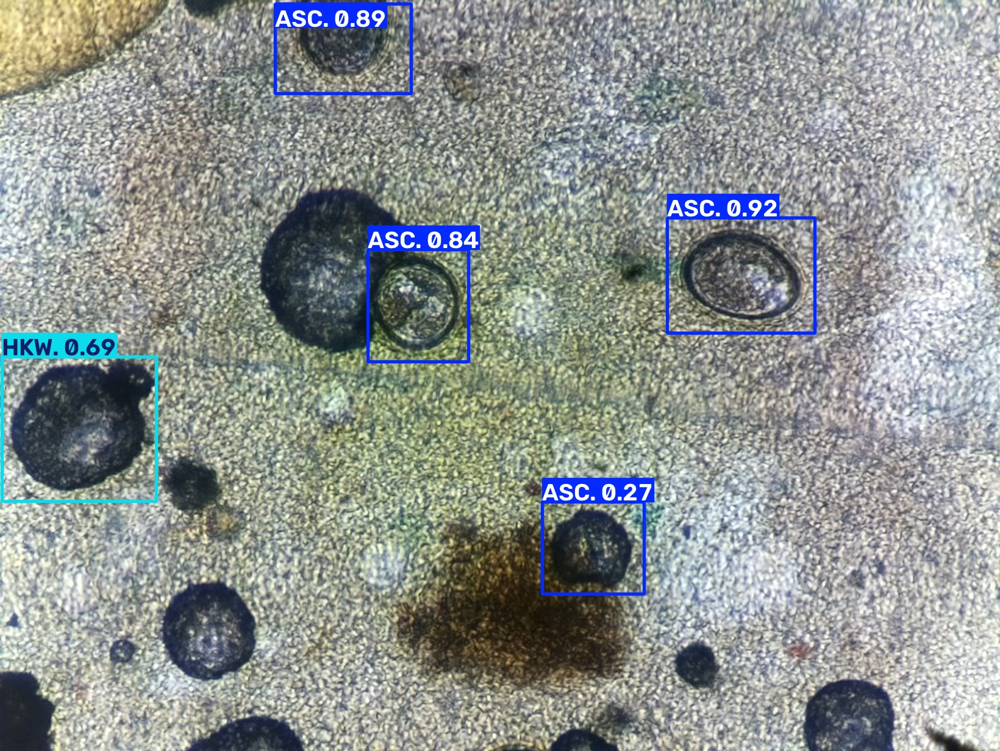

In [ ]:

import os
from pathlib import Path
from IPython.display import display, Image

output_dir = "/content/helminth_prediction_check/test"

print("Output folder exists:", os.path.isdir(output_dir))

if os.path.isdir(output_dir):
    saved_images = [
        p for p in Path(output_dir).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    ]

    print("Saved images:", [p.name for p in saved_images])

    if saved_images:
        display(Image(filename=str(saved_images[0]), width=600))
    else:
        print("No image found in output folder.")
else:
    print("Output folder not found.")


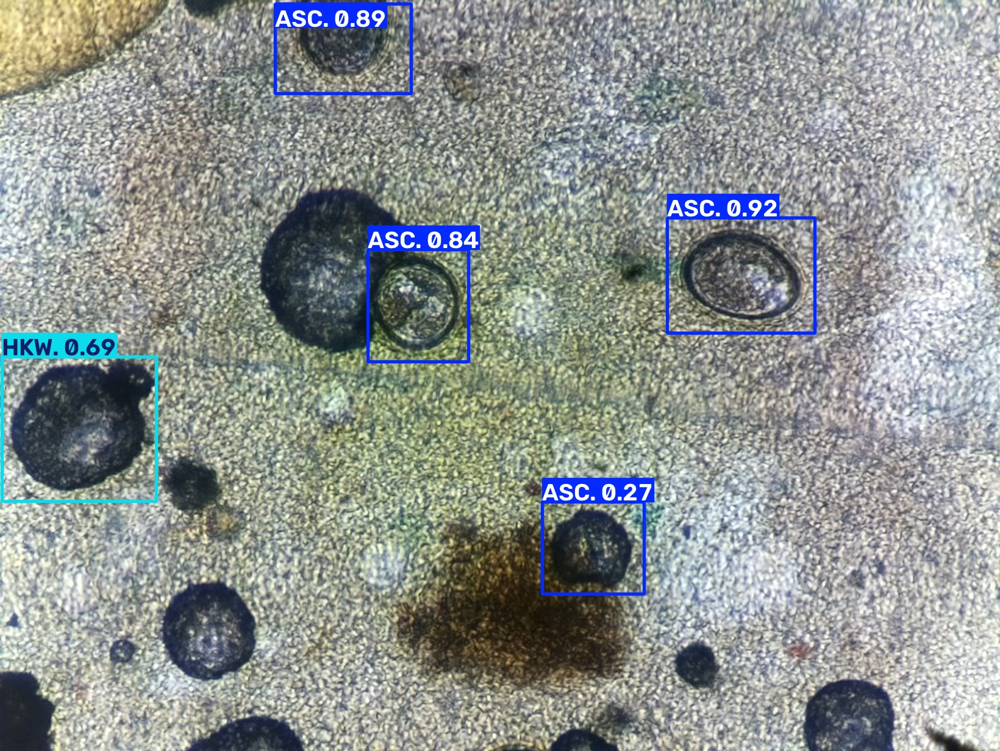

In [ ]:

from IPython.display import display, Image

result_image = "/content/helminth_prediction_check/test/train_0000_image_04368.jpg"

display(Image(filename=result_image, width=700))


In [ ]:

from pathlib import Path

script_path = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/predict.py"
)

print("Prediction script exists:", script_path.is_file())

if script_path.is_file():
    print("\n--- predict.py contents ---\n")
    print(script_path.read_text())


Prediction script exists: True

--- predict.py contents ---

import argparse
from pathlib import Path
from ultralytics import YOLO

def main():
    parser = argparse.ArgumentParser(
        description="Helminth egg detection using YOLO11n"
    )
    parser.add_argument("--source", required=True,
                        help="Path to an image or image folder")
    parser.add_argument("--weights", default="models/best.pt")
    parser.add_argument("--imgsz", type=int, default=320)
    parser.add_argument("--conf", type=float, default=0.25)
    parser.add_argument("--output", default="predictions")
    args = parser.parse_args()

    if not Path(args.weights).exists():
        raise FileNotFoundError(
            f"Model weights not found: {args.weights}"
        )
    if not Path(args.source).exists():
        raise FileNotFoundError(
            f"Image or folder not found: {args.source}"
        )

    model = YOLO(args.weights)
    model.predict(
        source=args.source,
        im

In [ ]:

%cd /content/drive/MyDrive/Helminth_GitHub_Project

!python predict.py \
  --source "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/train/train_0000_image_04368.png" \
  --weights "models/best.pt" \
  --imgsz 320 \
  --conf 0.25


/content/drive/MyDrive/Helminth_GitHub_Project

image 1/1 /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/train/train_0000_image_04368.png: 256x320 4 ASC.s, 1 HKW., 54.9ms
Speed: 2.6ms preprocess, 54.9ms inference, 1.2ms postprocess per image at shape (1, 3, 256, 320)
Results saved to /content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/predictions/helminth_results
Prediction finished.
Results folder: predictions/helminth_results


In [ ]:

import os
import zipfile

zip_path = "/content/drive/MyDrive/Helminth_Research_Project.zip"

print("ZIP exists:", os.path.isfile(zip_path))

if os.path.isfile(zip_path):
    print("ZIP size (MB):",
          round(os.path.getsize(zip_path) / (1024 * 1024), 2))

    with zipfile.ZipFile(zip_path, "r") as z:
        print("ZIP integrity check:", z.testzip() or "PASS")

        files = z.namelist()
        print("\nTotal items in ZIP:", len(files))

        required = [
            "README.md",
            "dataset.yaml",
            "predict.py",
            "models/best.pt",
            "results/test_metrics.json",
            "results/classwise_test_results.csv"
        ]

        print("\nRequired file checks:")
        for item in required:
            found = any(
                name == item or name.endswith("/" + item)
                for name in files
            )
            print(f"{item}: {'FOUND' if found else 'MISSING'}")

        print("\nFirst 25 ZIP entries:")
        for name in files[:25]:
            print(name)


ZIP exists: True
ZIP size (MB): 5.51
ZIP integrity check: PASS

Total items in ZIP: 19

Required file checks:
README.md: FOUND
dataset.yaml: FOUND
predict.py: FOUND
models/best.pt: FOUND
results/test_metrics.json: FOUND
results/classwise_test_results.csv: FOUND

First 25 ZIP entries:
figures/
models/
results/
README.md
dataset.yaml
.gitignore
requirements.txt
predict.py
results/classwise_test_results.csv
results/test_metrics.json
results/training_history.csv
results/training_args.yaml
figures/confusion_matrix.png
figures/confusion_matrix_normalized.png
figures/BoxPR_curve.png
figures/BoxF1_curve.png
figures/BoxP_curve.png
figures/BoxR_curve.png
models/best.pt


In [ ]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

print("----- dataset.yaml -----")
print((project / "dataset.yaml").read_text())

print("\n----- requirements.txt -----")
print((project / "requirements.txt").read_text())

print("\n----- README.md -----")
print((project / "README.md").read_text())


----- dataset.yaml -----
path: /content/helminth_4class_recovered
train: images/train
val: images/val
test: images/test
names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.


----- requirements.txt -----
ultralytics==8.4.181
pandas


----- README.md -----
# Helminth Egg Detection Using YOLO11n

## Project Overview
This project explores detection of four helminth egg classes
in microscopy images using the YOLO11n object detection model.

## Dataset
Name: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset
Source: https://zenodo.org/records/13843815
DOI: https://doi.org/10.5281/zenodo.13843815

Experimental sample: 400 selected image-annotation pairs.
Training: 280 images
Validation: 60 images
Testing: 60 images

## Model
- Architecture: YOLO11n
- Image size: 320 x 320
- Training epochs: 15
- Device: CPU
- Classes: ASC., HKW., SCH., TRI.

## Held-out Test Results
- Precision: 74.77%
- Recall: 64.40%
- mAP@50: 72.50%
- mAP@50-95: 55.26%

## Per-Class AP@50
| Class | AP@50 |
|-

In [ ]:

import os

paths = [
    "/content/helminth_4class_recovered",
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
]

for path in paths:
    print("\nDataset path:", path)
    print("Folder exists:", os.path.isdir(path))

    if os.path.isdir(path):
        for split in ["train", "val", "test"]:
            img_dir = os.path.join(path, "images", split)
            label_dir = os.path.join(path, "labels", split)

            image_count = (
                sum(
                    f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
                    for f in os.listdir(img_dir)
                ) if os.path.isdir(img_dir) else 0
            )

            label_count = (
                sum(f.endswith(".txt") for f in os.listdir(label_dir))
                if os.path.isdir(label_dir) else 0
            )

            print(
                split,
                "| images:", image_count,
                "| label files:", label_count
            )



Dataset path: /content/helminth_4class_recovered
Folder exists: False

Dataset path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
Folder exists: True
train | images: 280 | label files: 280
val | images: 60 | label files: 60
test | images: 60 | label files: 60


In [ ]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

yaml_path = project / "dataset.yaml"

correct_yaml = """path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.
"""

yaml_path.write_text(correct_yaml)

print("Updated dataset.yaml:\n")
print(yaml_path.read_text())


Updated dataset.yaml:

path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.



In [ ]:

from pathlib import Path
import yaml

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
config = yaml.safe_load((project / "dataset.yaml").read_text())

root = Path(config["path"])
print("Dataset root exists:", root.is_dir())

for split in ["train", "val", "test"]:
    image_dir = root / config[split]
    label_dir = root / "labels" / split

    print(
        f"{split}:",
        "images folder =", image_dir.is_dir(),
        "| labels folder =", label_dir.is_dir()
    )

print("\nClass names:", config["names"])
print("Number of classes:", len(config["names"]))


Dataset root exists: True
train: images folder = True | labels folder = True
val: images folder = True | labels folder = True
test: images folder = True | labels folder = True

Class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
Number of classes: 4


In [ ]:

from pathlib import Path
import zipfile
import shutil

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
zip_path = Path(
    "/content/drive/MyDrive/Helminth_Research_Project.zip"
)
backup_zip = Path(
    "/content/drive/MyDrive/Helminth_Research_Project_previous.zip"
)

# Preserve the previous ZIP before replacing it
if zip_path.exists():
    shutil.copy2(zip_path, backup_zip)
    print("Previous ZIP backed up:", backup_zip.exists())

# Include only the intended project files
items = [
    "README.md",
    "dataset.yaml",
    ".gitignore",
    "requirements.txt",
    "predict.py",
    "figures",
    "models",
    "results",
]

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for item in items:
        source = project / item

        if source.is_file():
            z.write(source, arcname=item)
        elif source.is_dir():
            for file in source.rglob("*"):
                if file.is_file():
                    z.write(file, arcname=file.relative_to(project))

# Verify ZIP integrity and the corrected dataset path
with zipfile.ZipFile(zip_path, "r") as z:
    print("\nZIP integrity:", z.testzip() or "PASS")
    print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

    yaml_text = z.read("dataset.yaml").decode("utf-8")
    print("\nUpdated dataset path included:",
          "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
          in yaml_text)

    print("Model included:", "models/best.pt" in z.namelist())
    print("Test metrics included:", "results/test_metrics.json" in z.namelist())


Previous ZIP backed up: True

ZIP integrity: PASS
ZIP size (MB): 5.51

Updated dataset path included: True
Model included: True
Test metrics included: True


In [ ]:

from pathlib import Path
from collections import defaultdict
import hashlib

dataset = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
)

splits = ["train", "val", "test"]
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

hash_locations = defaultdict(list)

for split in splits:
    folder = dataset / "images" / split
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    print(f"{split}: {len(images)} images")

    for image_path in images:
        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        hash_locations[digest].append((split, str(image_path)))

print("\n--- EXACT DUPLICATE CHECK ---")

cross_split_groups = []

for locations in hash_locations.values():
    found_splits = {split for split, _ in locations}

    if len(found_splits) > 1:
        cross_split_groups.append(locations)

print("Unique image contents:", len(hash_locations))
print("Duplicate groups crossing splits:", len(cross_split_groups))

for group in cross_split_groups[:20]:
    print("\nDuplicate group:")
    for split, path in group:
        print(f"  {split}: {path}")

if not cross_split_groups:
    print("No exact image duplicates found across splits.")


train: 280 images
val: 60 images
test: 60 images

--- EXACT DUPLICATE CHECK ---
Unique image contents: 400
Duplicate groups crossing splits: 0
No exact image duplicates found across splits.


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
from itertools import combinations

dataset = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
)
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def difference_hash(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("L").resize((9, 8))
        pixels = list(im.getdata())

    bits = 0
    for y in range(8):
        for x in range(8):
            left = pixels[y * 9 + x]
            right = pixels[y * 9 + x + 1]
            bits = (bits << 1) | int(left > right)
    return bits

images = {}
for split in ["train", "val", "test"]:
    folder = dataset / "images" / split
    images[split] = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

hashes = {}
for split, paths in images.items():
    for p in paths:
        try:
            hashes[str(p)] = difference_hash(p)
        except Exception as e:
            print("Could not process:", p.name, "|", str(e))

# Compare only images belonging to different splits.
candidates = []
split_names = list(images.keys())

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        split_a, split_b = split_names[i], split_names[j]

        for a in images[split_a]:
            ha = hashes.get(str(a))
            if ha is None:
                continue

            for b in images[split_b]:
                hb = hashes.get(str(b))
                if hb is None:
                    continue

                distance = (ha ^ hb).bit_count()
                if distance <= 6:
                    candidates.append((distance, split_a, a, split_b, b))

candidates.sort(key=lambda x: x[0])

print("Images hashed:", len(hashes))
print("Potential similar cross-split pairs:", len(candidates))
print("\nTop 20 candidates (smaller distance = more similar):")

for distance, split_a, a, split_b, b in candidates[:20]:
    print(f"\nDistance: {distance}/64")
    print(f"{split_a}: {a.name}")
    print(f"{split_b}: {b.name}")


Images hashed: 400
Potential similar cross-split pairs: 1

Top 20 candidates (smaller distance = more similar):

Distance: 6/64
train: train_0194_image_04909.png
val: val_0001_image_05520.png


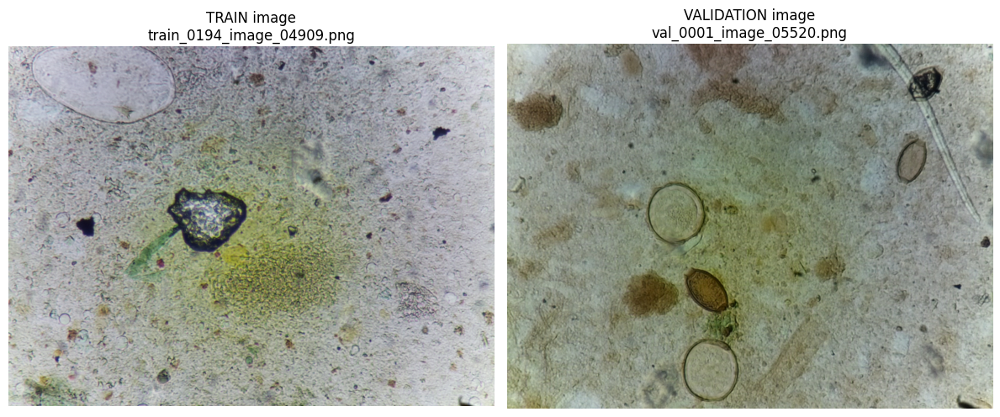

In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

dataset = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
)

train_image = dataset / "images/train/train_0194_image_04909.png"
val_image = dataset / "images/val/val_0001_image_05520.png"

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, path, title in [
    (axes[0], train_image, "TRAIN image"),
    (axes[1], val_image, "VALIDATION image")
]:
    with Image.open(path) as im:
        ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    ax.set_title(f"{title}\n{path.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Train image exists: True
Validation image exists: True


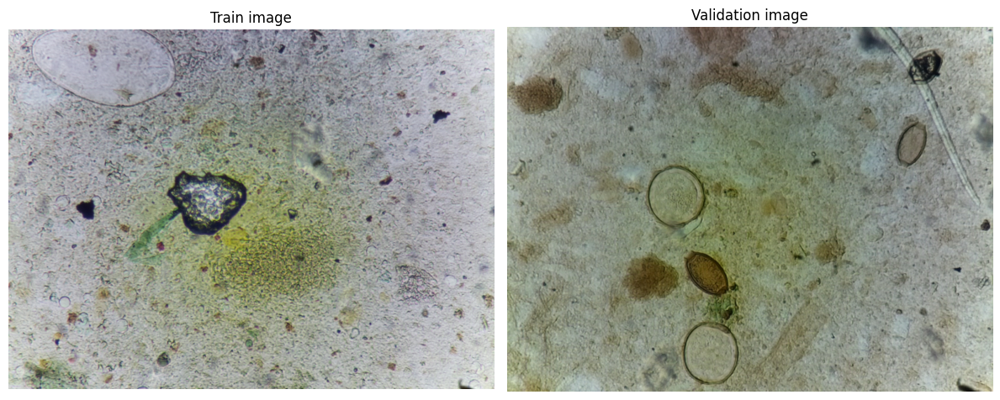

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"

train_img = os.path.join(
    base, "images/train/train_0194_image_04909.png"
)
val_img = os.path.join(
    base, "images/val/val_0001_image_05520.png"
)

print("Train image exists:", os.path.exists(train_img))
print("Validation image exists:", os.path.exists(val_img))

if os.path.exists(train_img) and os.path.exists(val_img):
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].imshow(Image.open(train_img))
    ax[0].set_title("Train image")
    ax[0].axis("off")

    ax[1].imshow(Image.open(val_img))
    ax[1].set_title("Validation image")
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Image path check karna hoga.")


In [ ]:

import os
import json

project = "/content/drive/MyDrive/Helminth_GitHub_Project"

files_to_check = [
    "models/best.pt",
    "dataset.yaml",
    "predict.py",
    "results/test_metrics.json",
    "results/classwise_test_results.csv",
    "README.md",
    "requirements.txt"
]

print("FINAL PROJECT FILE CHECK\n")

for file in files_to_check:
    path = os.path.join(project, file)
    print(("FOUND  " if os.path.isfile(path) else "MISSING"), file)

metrics_path = os.path.join(project, "results/test_metrics.json")

if os.path.isfile(metrics_path):
    print("\nTEST METRICS:")
    with open(metrics_path, "r") as f:
        print(json.dumps(json.load(f), indent=2))


FINAL PROJECT FILE CHECK

FOUND   models/best.pt
FOUND   dataset.yaml
FOUND   predict.py
FOUND   results/test_metrics.json
FOUND   results/classwise_test_results.csv
FOUND   README.md
FOUND   requirements.txt

TEST METRICS:
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}


In [ ]:

import pandas as pd
import os

csv_path = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/classwise_test_results.csv"
)

df = pd.read_csv(csv_path)

print("CSV columns:")
print(df.columns.tolist())

print("\nCLASS-WISE TEST RESULTS:")
display(df)

print("\nNumber of rows:", len(df))


CSV columns:
['Class', 'AP50', 'AP50_percent']

CLASS-WISE TEST RESULTS:


,Class,AP50,AP50_percent
0,ASC. - Ascaris lumbricoides,0.953169,95.32
1,HKW. - Hookworm,0.549316,54.93
2,SCH. - Schistosoma mansoni,0.588963,58.90
3,TRI. - Trichuris trichiura,0.808452,80.85



Number of rows: 4


In [ ]:

from pathlib import Path
from collections import Counter

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
all_errors = []

for split in ["train", "val", "test"]:
    image_dir = base / "images" / split
    label_dir = base / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_exts
    ]
    labels = {p.stem: p for p in label_dir.glob("*.txt")}

    image_stems = {p.stem for p in images}
    missing_labels = image_stems - set(labels)
    extra_labels = set(labels) - image_stems

    class_counts = Counter()
    invalid_rows = []

    for image_stem in image_stems & set(labels):
        label_file = labels[image_stem]

        for line_no, line in enumerate(
            label_file.read_text().splitlines(), start=1
        ):
            if not line.strip():
                continue

            parts = line.split()
            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                cls = int(parts[0])
                coords = [float(x) for x in parts[1:]]

                if cls not in range(4):
                    raise ValueError("Class ID must be 0–3")

                if not all(0 <= x <= 1 for x in coords):
                    raise ValueError("Coordinates must be between 0 and 1")

                class_counts[cls] += 1

            except Exception as e:
                invalid_rows.append(
                    f"{label_file.name}:{line_no} — {e}"
                )

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images missing labels:", len(missing_labels))
    print("Extra label files:", len(extra_labels))
    print("Annotation counts by class ID:", dict(sorted(class_counts.items())))
    print("Invalid annotation rows:", len(invalid_rows))

    if missing_labels or extra_labels or invalid_rows:
        all_errors.append(split)

        if missing_labels:
            print("Missing label examples:", list(missing_labels)[:5])
        if extra_labels:
            print("Extra label examples:", list(extra_labels)[:5])
        if invalid_rows:
            print("Invalid row examples:", invalid_rows[:5])

print("\nOVERALL:", "CHECK REQUIRED" if all_errors else
      "BASIC CHECKS PASSED")



--- TRAIN ---
Images: 280
Label files: 280
Images missing labels: 0
Extra label files: 0
Annotation counts by class ID: {0: 226, 1: 129, 2: 108, 3: 85}
Invalid annotation rows: 0

--- VAL ---
Images: 60
Label files: 60
Images missing labels: 0
Extra label files: 0
Annotation counts by class ID: {0: 44, 1: 16, 2: 25, 3: 29}
Invalid annotation rows: 0

--- TEST ---
Images: 60
Label files: 60
Images missing labels: 0
Extra label files: 0
Annotation counts by class ID: {0: 66, 1: 30, 2: 22, 3: 29}
Invalid annotation rows: 0

OVERALL: BASIC CHECKS PASSED


In [ ]:

from pathlib import Path
import json

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

candidates = [
    project / "results" / "training_args.json",
    project / "results" / "args.yaml",
    project / "training_args.json",
    project / "args.yaml",
    Path(
        "/content/drive/MyDrive/Helminth_Project_Backup/"
        "helminth_recovered_v2/args.yaml"
    )
]

found = False

for path in candidates:
    if path.exists():
        print("Configuration file found:", path)
        print(path.read_text()[:10000])
        found = True
        break

if not found:
    print("Configuration file not found in expected locations.")
    print("Project results folders:")
    for p in (project / "results").glob("*"):
        print(p.name)


Configuration file found: /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/args.yaml
task: detect
mode: train
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
time: null
patience: 5
batch: 4
imgsz: 320
save: true
save_period: -1
cache: false
device: cpu
workers: 0
project: /content/helminth_runs
name: helminth_recovered_v2
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames

In [ ]:

from pathlib import Path
import yaml

paths = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/dataset.yaml"),
]

for path in paths:
    print("\nFILE:", path)
    if not path.exists():
        print("NOT FOUND")
        continue

    with open(path, "r") as f:
        config = yaml.safe_load(f)

    print("Dataset path:", config.get("path"))
    print("Train:", config.get("train"))
    print("Validation:", config.get("val"))
    print("Test:", config.get("test"))
    print("Class names:", config.get("names"))



FILE: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
Dataset path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
Train: images/train
Validation: images/val
Test: images/test
Class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}

FILE: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/dataset.yaml
Dataset path: /content/helminth_4class_recovered
Train: images/train
Validation: images/val
Test: images/test
Class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}


In [ ]:

from ultralytics import YOLO
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

model_path = project / "models" / "best.pt"
data_path = project / "dataset.yaml"

print("Model exists:", model_path.exists())
print("Dataset config exists:", data_path.exists())

model = YOLO(str(model_path))

metrics = model.val(
    data=str(data_path),
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    plots=True
)

print("\nRE-EVALUATED TEST METRICS")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)


Model exists: True
Dataset config exists: True
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 530.6±60.7 MB/s, size: 3650.7 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 94.2it/s 0.6s
val: New cache created: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.5it/s 10.1s
                   all         60        147      0.748      0.644      0.725      0.553
                  ASC.         24         66      0.815      0.939      0.953      0.768
                  HKW.         11         30      0.635      0.533      0.549      0.463
              

In [ ]:

from pathlib import Path
from zipfile import ZipFile, BadZipFile

zip_path = Path(
    "/content/drive/MyDrive/Helminth_Research_Project.zip"
)

print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    print("ZIP size (MB):", round(zip_path.stat().st_size / (1024**2), 2))

    try:
        with ZipFile(zip_path, "r") as z:
            names = z.namelist()

            print("ZIP integrity:", "PASS" if z.testzip() is None else "CHECK REQUIRED")
            print("\nImportant files:")

            required = [
                "README.md",
                "dataset.yaml",
                "predict.py",
                "requirements.txt",
                "models/best.pt",
                "results/test_metrics.json",
                "results/classwise_test_results.csv"
            ]

            for item in required:
                matches = [
                    name for name in names
                    if name == item or name.endswith("/" + item)
                ]
                print(("FOUND  " if matches else "MISSING"), item)

            print("\nTotal files in ZIP:", len(names))

    except BadZipFile:
        print("ZIP integrity: FAILED")


ZIP exists: True
ZIP size (MB): 5.51
ZIP integrity: PASS

Important files:
FOUND   README.md
FOUND   dataset.yaml
FOUND   predict.py
FOUND   requirements.txt
FOUND   models/best.pt
FOUND   results/test_metrics.json
FOUND   results/classwise_test_results.csv

Total files in ZIP: 16


In [ ]:

from pathlib import Path
from zipfile import ZipFile

zip_path = Path(
    "/content/drive/MyDrive/Helminth_Research_Project.zip"
)

with ZipFile(zip_path, "r") as z:
    names = z.namelist()

    print("TRAINING HISTORY / LOGS:")
    for n in names:
        if any(k in n.lower() for k in [
            "results.csv", "args.yaml", "training",
            "loss", "pr_curve", "confusion_matrix"
        ]):
            print(n)

    print("\nFIGURES:")
    for n in names:
        if n.lower().endswith((".png", ".jpg", ".jpeg", ".pdf")):
            print(n)


TRAINING HISTORY / LOGS:
figures/confusion_matrix.png
figures/confusion_matrix_normalized.png
figures/BoxPR_curve.png
results/classwise_test_results.csv
results/training_history.csv
results/training_args.yaml

FIGURES:
figures/confusion_matrix.png
figures/confusion_matrix_normalized.png
figures/BoxPR_curve.png
figures/BoxF1_curve.png
figures/BoxP_curve.png
figures/BoxR_curve.png


In [ ]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

for filename in ["README.md", "requirements.txt"]:
    path = project / filename
    print(f"\n{'='*20} {filename} {'='*20}")

    if path.exists():
        print(path.read_text()[:12000])
    else:
        print("FILE NOT FOUND")



==================== README.md ====================
# Helminth Egg Detection Using YOLO11n

## Project Overview
This project explores detection of four helminth egg classes
in microscopy images using the YOLO11n object detection model.

## Dataset
Name: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset
Source: https://zenodo.org/records/13843815
DOI: https://doi.org/10.5281/zenodo.13843815

Experimental sample: 400 selected image-annotation pairs.
Training: 280 images
Validation: 60 images
Testing: 60 images

## Model
- Architecture: YOLO11n
- Image size: 320 x 320
- Training epochs: 15
- Device: CPU
- Classes: ASC., HKW., SCH., TRI.

## Held-out Test Results
- Precision: 74.77%
- Recall: 64.40%
- mAP@50: 72.50%
- mAP@50-95: 55.26%

## Per-Class AP@50
| Class | AP@50 |
|---|---:|
| ASC. - Ascaris lumbricoides | 95.32% |
| HKW. - Hookworm | 54.93% |
| SCH. - Schistosoma mansoni | 58.90% |
| TRI. - Trichuris trichiura | 80.85% |

## Limitations
This is a preliminary 

In [ ]:

from pathlib import Path
from datetime import datetime

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

readme_path = project / "README.md"
requirements_path = project / "requirements.txt"

# Back up the existing files before editing
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

readme_backup = project / f"README_backup_{stamp}.md"
requirements_backup = project / f"requirements_backup_{stamp}.txt"

readme_backup.write_text(readme_path.read_text())
requirements_backup.write_text(requirements_path.read_text())

readme = """# Helminth Egg Detection Using YOLO11n

## Project overview
A preliminary object-detection experiment for four helminth egg classes in microscopy images using YOLO11n.

## Dataset
- Name: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset
- Source: https://zenodo.org/records/13843815
- DOI: https://doi.org/10.5281/zenodo.13843815
- Selected sample: 400 image-annotation pairs
- Split: 280 training, 60 validation, 60 test images
- Split seed recorded in training configuration: 42

## Model and training
- Architecture: YOLO11n, pretrained weights
- Input size: 320 × 320
- Epochs configured: 15
- Batch size: 4
- Device: CPU
- Optimizer: Ultralytics auto
- Training software: Ultralytics 8.4.181
- Python: 3.13.16
- PyTorch: 2.11.0+cpu

## Classes
- ASC. — Ascaris lumbricoides
- HKW. — Hookworm
- SCH. — Schistosoma mansoni
- TRI. — Trichuris trichiura

## Held-out test results
Evaluation on 60 test images containing 147 annotated instances:
- Precision: 74.77%
- Recall: 64.40%
- mAP@50: 72.50%
- mAP@50–95: 55.26%

### Per-class AP@50
| Class | AP@50 |
|---|---:|
| Ascaris lumbricoides | 95.32% |
| Hookworm | 54.93% |
| Schistosoma mansoni | 58.90% |
| Trichuris trichiura | 80.85% |

The saved model was re-evaluated on the same test split and reproduced the recorded aggregate metrics using Ultralytics 8.4.182. This verifies repeatability of that evaluation in the current environment, not independent external validation.

## Project contents
- `models/best.pt`: trained model weights
- `predict.py`: prediction script
- `dataset.yaml`: dataset configuration
- `results/test_metrics.json`: aggregate metrics
- `results/classwise_test_results.csv`: class-wise AP@50
- `results/training_history.csv`: training history
- `results/training_args.yaml`: training configuration
- `figures/`: evaluation plots

## Reproducibility notes
The training configuration records a random seed of 42 and deterministic mode enabled. Exact reproduction can still depend on software versions, hardware, data files, and library behavior. The training data path in the original configuration differs from the current Google Drive path; update `dataset.yaml` for your own environment before evaluation or prediction.

## Limitations
This is a preliminary experiment on a selected 400-image sample. These results do not establish clinical diagnostic performance. Exact duplicate checks found no cross-split duplicates, but microscopy-slide/source-level independence has not been verified. A visually reviewed similar-image pair was distinct. Further source-level leakage assessment, stronger baseline comparisons, repeated experiments, and independent external validation are needed before making generalization claims.

## Citation
Oyibo et al. (2025), Scientific Reports:
https://doi.org/10.1038/s41598-025-02755-9

Dataset DOI:
https://doi.org/10.5281/zenodo.13843815
"""

requirements = """ultralytics==8.4.181
pandas
"""

readme_path.write_text(readme)
requirements_path.write_text(requirements)

print("Updated README:", readme_path.exists())
print("Updated requirements:", requirements_path.exists())
print("Backups created:")
print(readme_backup)
print(requirements_backup)
print("\nReview complete. Original files were backed up before updating.")


Updated README: True
Updated requirements: True
Backups created:
/content/drive/MyDrive/Helminth_GitHub_Project/README_backup_20261018_181523.md
/content/drive/MyDrive/Helminth_GitHub_Project/requirements_backup_20261018_181523.txt

Review complete. Original files were backed up before updating.


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

output_zip = Path(
    "/content/drive/MyDrive/Helminth_Research_Project_FINAL.zip"
)

# Exclude backups and generated prediction outputs from the submission.
excluded_parts = {
    ".git",
    "__pycache__",
    "runs",
}

with ZipFile(output_zip, "w", ZIP_DEFLATED) as z:
    for path in project.rglob("*"):
        if not path.is_file():
            continue

        relative = path.relative_to(project)

        if any(part in excluded_parts for part in relative.parts):
            continue

        if path.name.startswith(("README_backup_", "requirements_backup_")):
            continue

        z.write(path, arcname=str(relative))

with ZipFile(output_zip, "r") as z:
    bad_file = z.testzip()
    names = z.namelist()

    print("FINAL ZIP:", output_zip)
    print("Size (MB):", round(output_zip.stat().st_size / (1024**2), 2))
    print("Integrity:", "PASS" if bad_file is None else f"FAILED: {bad_file}")
    print("Total files:", len(names))

    for required in [
        "README.md",
        "requirements.txt",
        "dataset.yaml",
        "predict.py",
        "models/best.pt",
        "results/test_metrics.json",
        "results/classwise_test_results.csv",
        "results/training_history.csv",
        "results/training_args.yaml",
    ]:
        print(
            ("FOUND  " if required in names else "MISSING"),
            required
        )


FINAL ZIP: /content/drive/MyDrive/Helminth_Research_Project_FINAL.zip
Size (MB): 5.51
Integrity: PASS
Total files: 16
FOUND   README.md
FOUND   requirements.txt
FOUND   dataset.yaml
FOUND   predict.py
FOUND   models/best.pt
FOUND   results/test_metrics.json
FOUND   results/classwise_test_results.csv
FOUND   results/training_history.csv
FOUND   results/training_args.yaml


In [ ]:

from pathlib import Path
from zipfile import ZipFile
import shutil
import sys
import subprocess

zip_path = Path(
    "/content/drive/MyDrive/Helminth_Research_Project_FINAL.zip"
)

test_dir = Path("/content/helminth_final_reproducibility_test")

if test_dir.exists():
    shutil.rmtree(test_dir)

test_dir.mkdir(parents=True)

# 1. Extract the final submission ZIP
with ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    if bad_file is not None:
        raise RuntimeError(f"Corrupt ZIP member: {bad_file}")
    z.extractall(test_dir)

print("1. ZIP extraction: PASS")

# 2. Verify the model can be loaded
from ultralytics import YOLO

model_path = test_dir / "models" / "best.pt"
model = YOLO(str(model_path))

print("2. Model loading: PASS")
print("Model task:", model.task)
print("Model classes:", model.names)

# 3. Check the prediction script and dataset configuration
predict_script = test_dir / "predict.py"
dataset_yaml = test_dir / "dataset.yaml"

print("3. predict.py exists:", predict_script.is_file())
print("4. dataset.yaml exists:", dataset_yaml.is_file())

# 5. Check whether the prediction script accepts command-line arguments
result = subprocess.run(
    [sys.executable, str(predict_script), "--help"],
    capture_output=True,
    text=True,
    timeout=60
)

print("5. Prediction script --help exit code:", result.returncode)
print((result.stdout or result.stderr)[:2500])


1. ZIP extraction: PASS
2. Model loading: PASS
Model task: detect
Model classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
3. predict.py exists: True
4. dataset.yaml exists: True
5. Prediction script --help exit code: 0
usage: predict.py [-h] --source SOURCE [--weights WEIGHTS] [--imgsz IMGSZ]
                  [--conf CONF] [--output OUTPUT]

Helminth egg detection using YOLO11n

options:
  -h, --help         show this help message and exit
  --source SOURCE    Path to an image or image folder
  --weights WEIGHTS
  --imgsz IMGSZ
  --conf CONF
  --output OUTPUT



In [ ]:
from pathlib import Path
from ultralytics import YOLO

# Model extracted from the final ZIP
project_dir = Path("/content/helminth_final_reproducibility_test")
model_path = project_dir / "models" / "best.pt"

# Locate one real test image from your dataset
test_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = sorted(
    p for p in test_dir.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

if not images:
    raise FileNotFoundError(
        f"No test images found in: {test_dir}"
    )

sample_image = images[0]

# Load the packaged model and predict
model = YOLO(str(model_path))

results = model.predict(
    source=str(sample_image),
    imgsz=320,
    conf=0.25,
    save=True,
    project=str(project_dir),
    name="prediction_check",
    exist_ok=True
)

result = results[0]
output_dir = project_dir / "prediction_check"

print("Image prediction test: PASS")
print("Test image:", sample_image.name)
print("Detected objects:", len(result.boxes))
print("Detected class IDs:", result.boxes.cls.cpu().int().tolist())
print("Saved prediction folder:", output_dir)
print("Prediction image exists:",
      any(output_dir.glob(sample_image.stem + ".*")))


image 1/1 /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test/test_0000_image_02114.png: 256x320 (no detections), 133.5ms
Speed: 4.6ms preprocess, 133.5ms inference, 0.9ms postprocess per image at shape (1, 3, 256, 320)
Results saved to /content/helminth_final_reproducibility_test/prediction_check
Image prediction test: PASS
Test image: test_0000_image_02114.png
Detected objects: 0
Detected class IDs: []
Saved prediction folder: /content/helminth_final_reproducibility_test/prediction_check
Prediction image exists: True


In [ ]:
from pathlib import Path
from ultralytics import YOLO

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_dir = base / "images" / "test"
label_dir = base / "labels" / "test"

valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

sample_image = None
sample_label = None

for img in sorted(image_dir.iterdir()):
    if img.is_file() and img.suffix.lower() in valid_ext:
        label = label_dir / f"{img.stem}.txt"
        if label.is_file() and label.read_text().strip():
            sample_image = img
            sample_label = label
            break

if sample_image is None:
    raise FileNotFoundError("No image with non-empty labels found.")

ground_truth = [
    line for line in sample_label.read_text().splitlines()
    if line.strip()
]

model_path = Path(
    "/content/helminth_final_reproducibility_test/models/best.pt"
)
model = YOLO(str(model_path))

results = model.predict(
    source=str(sample_image),
    imgsz=320,
    conf=0.25,
    save=True,
    project="/content/helminth_final_reproducibility_test",
    name="annotated_image_check",
    exist_ok=True
)

result = results[0]

print("Image:", sample_image.name)
print("Ground-truth annotated objects:", len(ground_truth))
print("Model detected objects:", len(result.boxes))
print("Detected class IDs:", result.boxes.cls.cpu().int().tolist())
print("Saved output:", result.save_dir)


image 1/1 /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test/test_0000_image_02114.png: 256x320 (no detections), 68.7ms
Speed: 2.3ms preprocess, 68.7ms inference, 0.7ms postprocess per image at shape (1, 3, 256, 320)
Results saved to /content/helminth_final_reproducibility_test/annotated_image_check
Image: test_0000_image_02114.png
Ground-truth annotated objects: 1
Model detected objects: 0
Detected class IDs: []
Saved output: /content/helminth_final_reproducibility_test/annotated_image_check


In [ ]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path(
    "/content/helminth_final_reproducibility_test/models/best.pt"
)

image_path = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test/"
    "test_0000_image_02114.png"
)

model = YOLO(str(model_path))

results = model.predict(
    source=str(image_path),
    imgsz=320,
    conf=0.01,
    save=True,
    project="/content/helminth_final_reproducibility_test",
    name="low_confidence_check",
    exist_ok=True
)

result = results[0]

print("Detections at confidence 0.01:", len(result.boxes))
print("Confidence scores:",
      result.boxes.conf.cpu().tolist())
print("Class IDs:",
      result.boxes.cls.cpu().int().tolist())
print("Saved to:", result.save_dir)


image 1/1 /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test/test_0000_image_02114.png: 256x320 1 SCH., 365.8ms
Speed: 10.4ms preprocess, 365.8ms inference, 1.2ms postprocess per image at shape (1, 3, 256, 320)
Results saved to /content/helminth_final_reproducibility_test/low_confidence_check
Detections at confidence 0.01: 1
Confidence scores: [0.015883373096585274]
Class IDs: [2]
Saved to: /content/helminth_final_reproducibility_test/low_confidence_check


Image size: (2028, 1520)
Ground-truth label:
2 0.397436 0.254934 0.071992 0.142763


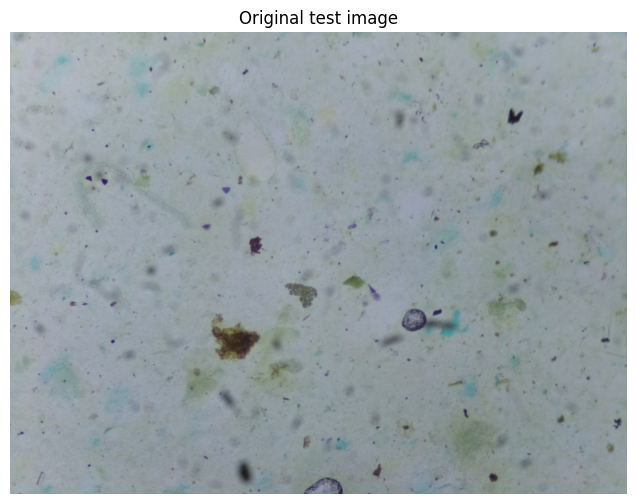

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_path = base / "images/test/test_0000_image_02114.png"
label_path = base / "labels/test/test_0000_image_02114.txt"

img = Image.open(image_path).convert("RGB")
print("Image size:", img.size)
print("Ground-truth label:")
print(label_path.read_text())

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Original test image")
plt.axis("off")
plt.show()

In [ ]:
from IPython.display import display
from PIL import Image
from pathlib import Path

img_path = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test/test_0000_image_02114.png"
)

display(Image.open(img_path))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
from ultralytics import YOLO

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_path = base / "images/test/test_0000_image_02114.png"
label_path = base / "labels/test/test_0000_image_02114.txt"
model_path = Path(
    "/content/helminth_final_reproducibility_test/models/best.pt"
)

img = Image.open(image_path).convert("RGB")
W, H = img.size
draw = ImageDraw.Draw(img)

# Ground-truth box: normalized YOLO format
for line in label_path.read_text().splitlines():
    cls, xc, yc, bw, bh = map(float, line.split())
    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H
    draw.rectangle([x1, y1, x2, y2], outline="lime", width=5)
    draw.text((x1, max(0, y1 - 20)), "TRUE SCH", fill="lime

SyntaxError: unterminated string literal (detected at line 28) (2717758851.py, line 28)

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
from ultralytics import YOLO
from IPython.display import display

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_path = base / "images/test/test_0000_image_02114.png"
label_path = base / "labels/test/test_0000_image_02114.txt"
model_path = Path(
    "/content/helminth_final_reproducibility_test/models/best.pt"
)

img = Image.open(image_path).convert("RGB")
W, H = img.size
draw = ImageDraw.Draw(img)

# Green box: ground-truth annotation
for line in label_path.read_text().splitlines():
    cls, xc, yc, bw, bh = map(float, line.split())

    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H

    draw.rectangle([x1, y1, x2, y2], outline="lime", width=5)
    draw.text((x1, max(0, y1 - 20)), "TRUE SCH", fill="lime")

# Red box: model prediction
model = YOLO(str(model_path))
result = model.predict(
    source=str(image_path),
    imgsz=320,
    conf=0.01,
    verbose=False
)[0]

for box in result.boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()
    conf = float(box.conf[0])

    draw.rectangle([x1, y1, x2, y2], outline

_IncompleteInputError: incomplete input (3616376433.py, line 46)

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
from ultralytics import YOLO
from IPython.display import display

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_path = base / "images/test/test_0000_image_02114.png"
label_path = base / "labels/test/test_0000_image_02114.txt"
model_path = Path(
    "/content/helminth_final_reproducibility_test/models/best.pt"
)

img = Image.open(image_path).convert("RGB")
W, H = img.size
draw = ImageDraw.Draw(img)

# Green box: ground-truth annotation
for line in label_path.read_text().splitlines():
    cls, xc, yc, bw, bh = map(float, line.split())

    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H

    draw.rectangle([x1, y1, x2, y2], outline="lime", width=5)
    draw.text((x1, max(0, y1 - 20)), "TRUE SCH", fill="lime")

# Red box: model prediction
model = YOLO(str(model_path))
result = model.predict(
    source=str(image_path),
    imgsz=320,
    conf=0.01,
    verbose=False
)[0]

for box in result.boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()
    conf = float(box.conf[0])

    draw.rectangle([x1, y1, x2, y2], outline="red", width=5)
    draw.text(
        (x1, min(H - 20, y2 + 4)),
        f"PRED SCH {conf:.3f}",
        fill="red"
    )

display(img)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
from ultralytics import YOLO

base = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

image_path = base / "images/test/test_0000_image_02114.png"
label_path = base / "labels/test/test_0000_image_02114.txt"
model_path = Path(
    "/content/helminth_final_reproducibility_test/models/best.pt"
)

# Read ground-truth box
W, H = 2028, 1520
values = list(map(float, label_path.read_text().splitlines()[0].split()))
cls, xc, yc, bw, bh = values

gt = [
    (xc - bw / 2) * W,
    (yc - bh / 2) * H,
    (xc + bw / 2) * W,
    (yc + bh / 2) * H
]

# Predict at low confidence for diagnostic purposes
model = YOLO(str(model_path))
result = model.predict(
    source=str(image_path),
    imgsz=320,
    conf=0.001,
    verbose=False
)[0]

if len(result.boxes) == 0:
    print("No prediction found, even at confidence 0.001.")
else:
    boxes = result.boxes.xyxy.cpu().tolist()
    scores = result.boxes.conf.cpu().tolist()
    classes = result.boxes.cls.cpu().int().tolist()

    for pred, score, pred_cls in zip(boxes, scores, classes):
        x1 = max(gt[0], pred[0])
        y1 = max(gt[1], pred[1])
        x2 = min(gt[2], pred[2])
        y2 = min(gt[3], pred[3])

        intersection = max(0, x2 - x1) * max(0, y2 - y1)

        area_gt = (gt[2] - gt[0]) * (gt[3] - gt[1])
        area_pred = (
            max(0, pred[2] - pred[0]) *
            max(0, pred[3] - pred[1])
        )

        union = area_gt + area_pred - intersection
        iou = intersection / union if union > 0 else 0

        print("Ground-truth class:", int(cls))
        print("Predicted class:", pred_cls)
        print(f"Confidence: {score:.4f}")
        print(f"IoU: {iou:.4f}")

Ground-truth class: 2
Predicted class: 2
Confidence: 0.0159
IoU: 0.8214
Ground-truth class: 2
Predicted class: 3
Confidence: 0.0033
IoU: 0.0000
Ground-truth class: 2
Predicted class: 2
Confidence: 0.0033
IoU: 0.0000
Ground-truth class: 2
Predicted class: 3
Confidence: 0.0027
IoU: 0.0000
Ground-truth class: 2
Predicted class: 0
Confidence: 0.0017
IoU: 0.0000
Ground-truth class: 2
Predicted class: 2
Confidence: 0.0017
IoU: 0.0000


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from collections import Counter
import subprocess
import sys
import json
import shutil
import time

from ultralytics import YOLO

# ==================================================
# 1. PROJECT PATHS
# ==================================================
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
zip_path = Path(
    "/content/drive/MyDrive/Helminth_Research_Project_FINAL.zip"
)
dataset = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

model_path = project / "models" / "best.pt"
metrics_path = project / "results" / "test_metrics.json"
class_results_path = project / "results" / "classwise_test_results.csv"
predict_script = project / "predict.py"

report = {
    "project": "Helminth Egg Detection using YOLO11n",
    "checks": {},
    "warnings": [],
    "results": {}
}

def status(name, passed, detail=""):
    report["checks"][name] = {
        "status": "PASS" if passed else "REVIEW",
        "detail": str(detail)
    }
    print(f"[{'PASS' if passed else 'REVIEW'}] {name}: {detail}")

print("=" * 60)
print("HELMINTH PROJECT — FINAL ALL-IN-ONE CHECK")
print("=" * 60)

# ==================================================
# 2. CHECK REQUIRED FILES
# ==================================================
required = [
    project / "README.md",
    project / "requirements.txt",
    project / "dataset.yaml",
    predict_script,
    model_path,
    metrics_path,
    class_results_path,
    project / "results" / "training_history.csv",
    project / "results" / "training_args.yaml",
]

missing = [str(p) for p in required if not p.is_file()]
status("Required project files", not missing,
       "All present" if not missing else "Missing: " + ", ".join(missing))

# ==================================================
# 3. CHECK FINAL ZIP AND SCRIPT
# ==================================================
if zip_path.is_file():
    try:
        with ZipFile(zip_path, "r") as z:
            bad = z.testzip()
            names = set(z.namelist())
            zip_ok = bad is None
            required_zip = [
                "README.md", "requirements.txt", "dataset.yaml",
                "predict.py", "models/best.pt",
                "results/test_metrics.json",
                "results/classwise_test_results.csv",
                "results/training_history.csv",
                "results/training_args.yaml"
            ]
            missing_zip = [f for f in required_zip if f not in names]

        status("Existing ZIP integrity", zip_ok,
               "ZIP readable" if zip_ok else f"Corrupt member: {bad}")
        status("ZIP required contents", not missing_zip,
               "Required files present" if not missing_zip
               else "Missing: " + ", ".join(missing_zip))
    except Exception as e:
        status("ZIP integrity", False, repr(e))
else:
    status("Existing ZIP", False, f"Not found: {zip_path}")

if predict_script.is_file():
    try:
        p = subprocess.run(
            [sys.executable, str(predict_script), "--help"],
            capture_output=True, text=True, timeout=60
        )
        status("Prediction script CLI", p.returncode == 0,
               "Help command works" if p.returncode == 0
               else (p.stderr or p.stdout)[-1000:])
    except Exception as e:
        status("Prediction script CLI", False, repr(e))

# ==================================================
# 4. LOAD MODEL
# ==================================================
model = None
if model_path.is_file():
    try:
        model = YOLO(str(model_path))
        status("Model loading", True,
               f"Task={model.task}; classes={model.names}")
        report["results"]["model_classes"] = {
            str(k): v for k, v in model.names.items()
        }
    except Exception as e:
        status("Model loading", False, repr(e))
else:
    status("Model loading", False, "best.pt not found")

# ==================================================
# 5. DATASET AND LABEL STRUCTURE
# ==================================================
class_names = {
    0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."
}
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
dataset_summary = {}
sample_image = None
sample_label = None

for split in ["train", "val", "test"]:
    image_dir = dataset / "images" / split
    label_dir = dataset / "labels" / split

    if not image_dir.is_dir() or not label_dir.is_dir():
        status(f"{split} dataset folders", False,
               "Image or label folder missing")
        continue

    images = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in valid_ext
    )
    image_stems = {p.stem for p in images}
    label_files = sorted(label_dir.glob("*.txt"))
    label_stems = {p.stem for p in label_files}

    missing_labels = sorted(image_stems - label_stems)
    extra_labels = sorted(label_stems - image_stems)
    invalid_rows = []
    class_counts = Counter()
    nonempty_images = []

    for img in images:
        lab = label_dir / f"{img.stem}.txt"
        if not lab.exists():
            continue

        text = lab.read_text().strip()
        if text:
            nonempty_images.append(img)

        for row_no, line in enumerate(text.splitlines(), 1):
            parts = line.split()
            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")
                cls = int(parts[0])
                coords = [float(v) for v in parts[1:]]
                if cls not in class_names:
                    raise ValueError("Unknown class ID")
                if not all(0 <= v <= 1 for v in coords):
                    raise ValueError("Coordinates outside [0,1]")
                if coords[2] <= 0 or coords[3] <= 0:
                    raise ValueError("Non-positive box size")
                class_counts[cls] += 1
            except Exception as e:
                invalid_rows.append(
                    f"{lab.name}:line {row_no}: {e}"
                )

    ok = (
        not missing_labels and not extra_labels and not invalid_rows
    )
    dataset_summary[split] = {
        "images": len(images),
        "labels": len(label_files),
        "missing_labels": missing_labels,
        "extra_labels": extra_labels,
        "invalid_rows": invalid_rows,
        "class_instance_counts": {
            class_names[k]: class_counts[k] for k in class_names
        }
    }

    status(f"{split} labels and structure", ok,
           f"{len(images)} images; {sum(class_counts.values())} "
           f"valid instances; missing={len(missing_labels)}, "
           f"extra={len(extra_labels)}, invalid rows={len(invalid_rows)}")

    if split == "test" and nonempty_images:
        # Prefer an image with SCH. annotation for the diagnostic
        for img in nonempty_images:
            lab = label_dir / f"{img.stem}.txt"
            rows = lab.read_text().splitlines()
            if any(line.split()[0] == "2" for line in rows if line.strip()):
                sample_image, sample_label = img, lab
                break
        if sample_image is None:
            sample_image = nonempty_images[0]
            sample_label = label_dir / f"{sample_image.stem}.txt"

report["results"]["dataset_structure"] = dataset_summary

# ==================================================
# 6. READ SAVED TEST METRICS
# ==================================================
if metrics_path.is_file():
    try:
        saved_metrics = json.loads(metrics_path.read_text())
        report["results"]["saved_test_metrics"] = saved_metrics
        status("Saved test metrics", True,
               json.dumps(saved_metrics, ensure_ascii=False)[:1200])
    except Exception as e:
        status("Saved test metrics", False, repr(e))
else:
    status("Saved test metrics", False, "JSON file missing")

# ==================================================
# 7. PREDICTION + BOX IoU DIAGNOSTIC
# ==================================================
if model is not None and sample_image is not None and sample_label:
    try:
        # Low threshold is diagnostic only; not an official metric.
        result = model.predict(
            source=str(sample_image),
            imgsz=320,
            conf=0.001,
            save=True,
            project="/content/helminth_final_reproducibility_test",
            name="final_all_in_one_prediction",
            exist_ok=True,
            verbose=False
        )[0]

        W, H = result.orig_shape[1], result.orig_shape[0]
        gt_boxes = []

        for line in sample_label.read_text().splitlines():
            if not line.strip():
                continue
            cls, xc, yc, bw, bh = map(float, line.split())
            gt_boxes.append({
                "class_id": int(cls),
                "xyxy": [
                    (xc - bw / 2) * W,
                    (yc - bh / 2) * H,
                    (xc + bw / 2) * W,
                    (yc + bh / 2) * H
                ]
            })

        predictions = []
        for box in result.boxes:
            predictions.append({
                "class_id": int(box.cls[0]),
                "confidence": float(box.conf[0]),
                "xyxy": box.xyxy[0].cpu().tolist()
            })

        def calculate_iou(a, b):
            x1 = max(a[0], b[0])
            y1 = max(a[1], b[1])
            x2 = min(a[2], b[2])
            y2 = min(a[3], b[3])
            inter = max(0, x2 - x1) * max(0, y2 - y1)
            area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
            area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
            union = area_a + area_b - inter
            return inter / union if union > 0 else 0.0

        pairs = []
        for gt in gt_boxes:
            for pred in predictions:
                pairs.append({
                    "gt_class": gt["class_id"],
                    "pred_class": pred["class_id"],
                    "confidence": pred["confidence"],
                    "iou": calculate_iou(gt["xyxy"], pred["xyxy"]),
                    "same_class": gt["class_id"] == pred["class_id"]
                })

        best_any = max(pairs, key=lambda x: x["iou"]) if pairs else None
        same_class_pairs = [p for p in pairs if p["same_class"]]
        best_same = (
            max(same_class_pairs, key=lambda x: x["iou"])
            if same_class_pairs else None
        )

        diagnostic = {
            "image": sample_image.name,
            "ground_truth_count": len(gt_boxes),
            "ground_truth_classes": [
                class_names[g["class_id"]] for g in gt_boxes
            ],
            "prediction_count_at_conf_0.001": len(predictions),
            "predictions": [
                {
                    "class": class_names.get(p["class_id"], str(p["class_id"])),
                    "confidence": p["confidence"]
                } for p in predictions
            ],
            "best_iou_any_class": best_any,
            "best_iou_same_class": best_same,
            "saved_prediction_directory": str(result.save_dir)
        }

        report["results"]["single_image_diagnostic"] = diagnostic
        status("Single-image inference", True,
               f"{sample_image.name}: {len(predictions)} detections at conf=0.001")

        if best_same:
            print("Best same-class IoU:", round(best_same["iou"], 4))
            print("Matching class:", class_names[best_same["gt_class"]])
            print("Prediction confidence:", round(best_same["confidence"], 6))
        elif not predictions:
            print("No boxes detected, even at confidence 0.001.")
        else:
            print("No same-class predicted box found.")

    except Exception as e:
        status("Single-image inference / IoU", False, repr(e))
else:
    status("Single-image inference / IoU", False,
           "Model or annotated test image unavailable")

# ==================================================
# 8. WRITE FINAL REPORT
# ==================================================
report["warnings"].extend([
    "This is a preliminary experiment on a selected 400-image subset.",
    "One-image prediction and IoU checks are diagnostics, not independent validation.",
    "Source/slide independence across splits has not been established.",
    "Dataset label format checks do not verify biological annotation correctness.",
    "The saved aggregate metrics are reported as previously evaluated; this script does not retrain the model."
])

report_txt = project / "results" / "final_project_check_report.txt"
report_json = project / "results" / "final_project_check_report.json"
report_txt.parent.mkdir(parents=True, exist_ok=True)

lines = [
    "HELMINTH EGG DETECTION — FINAL PROJECT CHECK",
    "=" * 48,
    f"Generated: {time.strftime('%Y-%m-%d %H:%M:%S')}",
    ""
]

for name, info in report["checks"].items():
    lines.append(f"[{info['status']}] {name}: {info['detail']}")

lines += ["", "WARNINGS / LIMITATIONS:"]
lines += ["- " + w for w in report["warnings"]]
lines += ["", "RESULTS:", json.dumps(
    report["results"], indent=2, ensure_ascii=False, default=str
)]

report_txt.write_text("\n".join(lines), encoding="utf-8")
report_json.write_text(
    json.dumps(report, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8"
)

print("\nSaved report:", report_txt)
print("Saved machine-readable report:", report_json)

# ==================================================
# 9. REBUILD ZIP WITH REPORTS AND VERIFY IT
# ==================================================
try:
    excluded_dirs = {".git", "__pycache__", "runs"}
    with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
        for p in sorted(project.rglob("*")):
            if not p.is_file():
                continue
            rel = p.relative_to(project)
            if any(part in excluded_dirs for part in rel.parts):
                continue
            if p.name.startswith(("README_backup_", "requirements_backup_")):
                continue
            z.write(p, rel.as_posix())

    with ZipFile(zip_path, "r") as z:
        bad = z.testzip()
        zip_ok = bad is None
        names = set(z.namelist())
        report_in_zip = (
            "results/final_project_check_report.txt" in names
            and "results/final_project_check_report.json" in names
        )

    status("Updated final ZIP integrity", zip_ok,
           "Rebuilt and verified" if zip_ok else f"Corrupt member: {bad}")
    status("Final reports included in ZIP", report_in_zip,
           "Both report files included" if report_in_zip
           else "Report files missing from archive")

except Exception as e:
    status("ZIP rebuild", False, repr(e))

# ==================================================
# 10. FINAL SUMMARY
# ==================================================
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

passed = sum(v["status"] == "PASS" for v in report["checks"].values())
review = sum(v["status"] != "PASS" for v in report["checks"].values())

print("Checks passed:", passed)
print("Checks requiring review:", review)
print("Final ZIP:", zip_path)
print("Text report:", report_txt)
print("JSON report:", report_json)
print("\nImportant: successful packaging does not establish external validation.")
print("Read the REVIEW items and limitations before sharing the project.")


HELMINTH PROJECT — FINAL ALL-IN-ONE CHECK
[PASS] Required project files: All present
[PASS] Existing ZIP integrity: ZIP readable
[PASS] ZIP required contents: Required files present
[PASS] Prediction script CLI: Help command works
[PASS] Model loading: Task=detect; classes={0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
[PASS] train labels and structure: 280 images; 548 valid instances; missing=0, extra=0, invalid rows=0
[PASS] val labels and structure: 60 images; 114 valid instances; missing=0, extra=0, invalid rows=0
[PASS] test labels and structure: 60 images; 147 valid instances; missing=0, extra=0, invalid rows=0
[PASS] Saved test metrics: {"precision": 0.7476582192726383, "recall": 0.643997655073004, "mAP50": 0.7249751223889056, "mAP50_95": 0.5526411539654787, "per_class_AP50": [0.9531692860788715, 0.5493164013171381, 0.5889631347439667, 0.8084516674156462]}
Results saved to /content/helminth_final_reproducibility_test/final_all_in_one_prediction
[PASS] Single-image inference: test_

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

model_path = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"

if os.path.exists(model_path):
    print("SUCCESS: Trained model mil gaya!")
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model is path par nahi mila.")
    print("Google Drive mein Helminth_GitHub_Project folder check karein.")


SUCCESS: Trained model mil gaya!
File size: 5.21 MB


In [ ]:

import os

project = "/content/drive/MyDrive/Helminth_GitHub_Project"
dataset = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"

paths = {
    "Project folder": project,
    "Test images": os.path.join(dataset, "images", "test"),
    "Test labels": os.path.join(dataset, "labels", "test"),
}

for name, path in paths.items():
    print(f"{name}:",
          "FOUND" if os.path.exists(path) else "NOT FOUND",
          "|", path)

test_images = os.path.join(dataset, "images", "test")
if os.path.isdir(test_images):
    images = [
        f for f in os.listdir(test_images)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]
    print("Number of test images found:", len(images))


Project folder: FOUND | /content/drive/MyDrive/Helminth_GitHub_Project
Test images: FOUND | /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test
Test labels: FOUND | /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test
Number of test images found: 60


In [ ]:

import yaml
import os

yaml_path = "/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print("Dataset YAML:", yaml_path)
print("Dataset root:", config.get("path"))
print("Test split:", config.get("test"))
print("Class names:", config.get("names"))

root = config.get("path", "")
if not os.path.isabs(root):
    root = os.path.normpath(os.path.join(os.path.dirname(yaml_path), root))

test_path = config.get("test", "images/test")
if not os.path.isabs(test_path):
    test_path = os.path.join(root, test_path)

print("\nResolved test path:", test_path)
print("Test path exists:", os.path.isdir(test_path))


Dataset YAML: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
Dataset root: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
Test split: images/test
Class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}

Resolved test path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test
Test path exists: True


In [ ]:
from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
test_path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test"

model = YOLO(model_path)

results = model.val(
    data="/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml",
    split="test",
    plots=True,
    verbose=True
)

print("\nTest evaluation complete.")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:

%pip install ultralytics==8.4.181


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.1 MB/s eta 0:00:00


In [ ]:

from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
test_path = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/test"

model = YOLO(model_path)

results = model.val(
    data="/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml",
    split="test",
    plots=True,
    verbose=True
)

print("\nTest evaluation complete.")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.1 ms, read: 13.1±8.8 MB/s, size: 4949.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.6it/s 37.3s
val: New cache created: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache
          

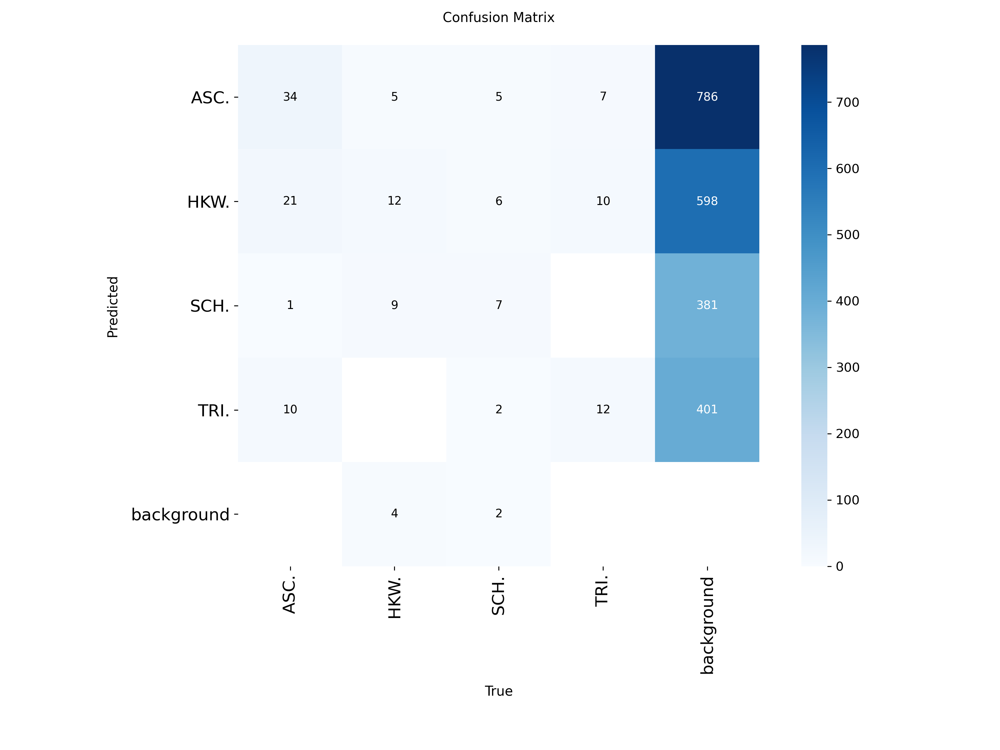

In [ ]:

from IPython.display import display, Image
import os

plot_path = "/content/runs/detect/val/confusion_matrix.png"

if os.path.exists(plot_path):
    display(Image(filename=plot_path))
else:
    print("Confusion matrix nahi mili. Available files:")
    folder = "/content/runs/detect/val"
    print(os.listdir(folder) if os.path.isdir(folder) else "Results folder not found")


In [ ]:

import os
import json
import shutil
from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
results_dir = Path("/content/runs/detect/val")
save_dir = project / "results"
figures_dir = project / "figures"

save_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the current evaluation metrics
metrics = {
    "evaluation": "YOLO11n test-set rerun",
    "test_images": 60,
    "test_instances": 147,
    "precision": float(results.box.mp),
    "recall": float(results.box.mr),
    "mAP50": float(results.box.map50),
    "mAP50_95": float(results.box.map),
    "model": "YOLO11n",
    "ultralytics_version": "8.4.181"
}

metrics_file = save_dir / "test_metrics_rerun.json"
with open(metrics_file, "w") as f:
    json.dump(metrics, f, indent=2)

# Copy evaluation figures to Google Drive
copied = []
if results_dir.exists():
    for file in results_dir.iterdir():
        if file.is_file() and file.suffix.lower() in [".png", ".jpg", ".csv"]:
            destination = figures_dir / file.name
            shutil.copy2(file, destination)
            copied.append(file.name)

print("Metrics saved:", metrics_file)
print("\nCurrent evaluation metrics:")
for key, value in metrics.items():
    print(f"{key}: {value}")

print("\nFigures copied:", copied)
print("\nBackup complete.")


Metrics saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_rerun.json

Current evaluation metrics:
evaluation: YOLO11n test-set rerun
test_images: 60
test_instances: 147
precision: 0.7619882553374744
recall: 0.6388827022726582
mAP50: 0.7214692404705383
mAP50_95: 0.5516046621342869
model: YOLO11n
ultralytics_version: 8.4.181

Figures copied: ['BoxR_curve.png', 'BoxF1_curve.png', 'val_batch1_labels.jpg', 'confusion_matrix_normalized.png', 'val_batch0_pred.jpg', 'BoxPR_curve.png', 'val_batch1_pred.jpg', 'confusion_matrix.png', 'BoxP_curve.png', 'val_batch0_labels.jpg', 'val_batch2_pred.jpg', 'val_batch2_labels.jpg']

Backup complete.


In [ ]:

import pandas as pd

class_names = results.names
ap50 = results.box.ap50
ap50_95 = results.box.ap

rows = []

for i, class_id in enumerate(results.box.ap_class_index):
    rows.append({
        "Class": class_names[int(class_id)],
        "AP50 (%)": round(float(ap50[i]) * 100, 2),
        "AP50-95 (%)": round(float(ap50_95[i]) * 100, 2)
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))


Class  AP50 (%)  AP50-95 (%)
 ASC.     95.30        76.75
 HKW.     54.88        46.29
 SCH.     57.55        36.61
 TRI.     80.86        60.99


In [ ]:

import pandas as pd
from pathlib import Path

cm = results.confusion_matrix
matrix = cm.matrix

names = results.names
labels = [names[i] for i in range(len(names))]

# Include background row/column if present
if matrix.shape[0] == len(labels) + 1:
    labels = labels + ["Background"]

df_cm = pd.DataFrame(
    matrix,
    index=[f"Actual_{x}" for x in labels],
    columns=[f"Predicted_{x}" for x in labels]
)

print("CONFUSION MATRIX")
print(df_cm.to_string())

output = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "confusion_matrix_counts.csv"
)
df_cm.to_csv(output)

print("\nSaved to:", output)


CONFUSION MATRIX
                   Predicted_ASC.  Predicted_HKW.  Predicted_SCH.  Predicted_TRI.  Predicted_Background
Actual_ASC.                  34.0             5.0             5.0             7.0                 786.0
Actual_HKW.                  21.0            12.0             6.0            10.0                 598.0
Actual_SCH.                   1.0             9.0             7.0             0.0                 381.0
Actual_TRI.                  10.0             0.0             2.0            12.0                 401.0
Actual_Background             0.0             4.0             2.0             0.0                   0.0

Saved to: /content/drive/MyDrive/Helminth_GitHub_Project/results/confusion_matrix_counts.csv


In [ ]:

print("Evaluation folder:", results.save_dir)
print("Confusion matrix shape:", results.confusion_matrix.matrix.shape)
print("Confusion matrix values:")
print(results.confusion_matrix.matrix)

print("\nEvaluation metrics:")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)

print("\nModel class names:", model.names)


Evaluation folder: /content/runs/detect/val
Confusion matrix shape: (5, 5)
Confusion matrix values:
[[         34           5           5           7         786]
 [         21          12           6          10         598]
 [          1           9           7           0         381]
 [         10           0           2          12         401]
 [          0           4           2           0           0]]

Evaluation metrics:
Precision: 0.7619882553374744
Recall: 0.6388827022726582
mAP50: 0.7214692404705383
mAP50-95: 0.5516046621342869

Model class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}


In [ ]:

from pathlib import Path
import yaml

args_file = Path("/content/runs/detect/val/args.yaml")

if args_file.exists():
    with open(args_file, "r") as f:
        args = yaml.safe_load(f)

    keys = [
        "model", "data", "split", "imgsz", "batch",
        "conf", "iou", "max_det", "agnostic_nms",
        "task", "seed", "deterministic"
    ]

    print("EVALUATION SETTINGS")
    for key in keys:
        print(f"{key}: {args.get(key, 'Not recorded')}")
else:
    print("args.yaml nahi mili.")
    print("Evaluation folder:", results.save_dir)
    print("Folder contents:", list(Path(results.save_dir).iterdir()))


args.yaml nahi mili.
Evaluation folder: /content/runs/detect/val
Folder contents: [PosixPath('/content/runs/detect/val/BoxR_curve.png'), PosixPath('/content/runs/detect/val/BoxF1_curve.png'), PosixPath('/content/runs/detect/val/val_batch1_labels.jpg'), PosixPath('/content/runs/detect/val/confusion_matrix_normalized.png'), PosixPath('/content/runs/detect/val/val_batch0_pred.jpg'), PosixPath('/content/runs/detect/val/BoxPR_curve.png'), PosixPath('/content/runs/detect/val/val_batch1_pred.jpg'), PosixPath('/content/runs/detect/val/confusion_matrix.png'), PosixPath('/content/runs/detect/val/BoxP_curve.png'), PosixPath('/content/runs/detect/val/val_batch0_labels.jpg'), PosixPath('/content/runs/detect/val/val_batch2_pred.jpg'), PosixPath('/content/runs/detect/val/val_batch2_labels.jpg')]


In [ ]:

from pathlib import Path
import yaml

model_args = getattr(model, "overrides", {})
print("MODEL SAVED SETTINGS")

for key in ["imgsz", "batch", "conf", "iou", "max_det", "seed"]:
    print(f"{key}: {model_args.get(key, 'Not recorded')}")

train_args = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/training_args.yaml"
)

print("\nSAVED TRAINING CONFIGURATION")
if train_args.exists():
    with open(train_args, "r") as f:
        saved = yaml.safe_load(f)

    for key in ["imgsz", "batch", "epochs", "seed", "deterministic"]:
        print(f"{key}: {saved.get(key, 'Not recorded')}")
else:
    print("Training configuration file not found.")


MODEL SAVED SETTINGS
imgsz: 320
batch: Not recorded
conf: Not recorded
iou: Not recorded
max_det: Not recorded
seed: Not recorded

SAVED TRAINING CONFIGURATION
imgsz: 320
batch: 4
epochs: 15
seed: 42
deterministic: True


In [ ]:

from pathlib import Path
from collections import Counter

label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)

files = list(label_dir.glob("*.txt"))
class_counts = Counter()
total_boxes = 0
bad_lines = []

for file in files:
    for line_no, line in enumerate(
        file.read_text().splitlines(), start=1
    ):
        if not line.strip():
            continue

        parts = line.split()
        try:
            class_id = int(parts[0])
            if len(parts) != 5 or class_id not in range(4):
                bad_lines.append((file.name, line_no, line))
                continue

            class_counts[class_id] += 1
            total_boxes += 1
        except (ValueError, IndexError):
            bad_lines.append((file.name, line_no, line))

print("Test label files:", len(files))
print("Total annotated objects:", total_boxes)
print("Counts by class:", dict(sorted(class_counts.items())))
print("Invalid annotation lines:", len(bad_lines))

if bad_lines:
    print("First few invalid lines:", bad_lines[:5])

print("\nConfusion matrix total:", results.confusion_matrix.matrix.sum())


Test label files: 60
Total annotated objects: 147
Counts by class: {0: 66, 1: 30, 2: 22, 3: 29}
Invalid annotation lines: 0

Confusion matrix total: 2313.0


In [ ]:

from ultralytics import YOLO
from pathlib import Path
import numpy as np

model_path = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)
data_path = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml"
)

model = YOLO(model_path)

diagnostic = model.val(
    data=data_path,
    split="test",
    imgsz=320,
    conf=0.25,
    plots=True,
    project="/content/drive/MyDrive/Helminth_GitHub_Project/results",
    name="diagnostic_conf025",
    exist_ok=True,
    verbose=False
)

print("Diagnostic evaluation only — conf=0.25")
print("Precision:", round(float(diagnostic.box.mp), 4))
print("Recall:", round(float(diagnostic.box.mr), 4))
print("mAP50:", round(float(diagnostic.box.map50), 4))
print("mAP50-95:", round(float(diagnostic.box.map), 4))

print("\nConfusion matrix:")
print(diagnostic.confusion_matrix.matrix)
print("\nMatrix shape:", diagnostic.confusion_matrix.matrix.shape)


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 115.8±58.8 MB/s, size: 3331.7 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 12.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.9s/it 11.5s
                   all         60        147      0.746      0.645      0.617      0.492
Speed: 1.1ms preprocess, 37.5ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/drive/MyDrive/Helminth_GitHub_Project/results/diagnostic_conf025
Diagnostic evaluation only — conf=0.25
Precision: 0.7463
Recall: 0.6447
mAP50: 0.6173
mAP50-95: 0.492

Confusion matrix:
[[         62           0           0           6     

In [ ]:

from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)

check = model.val(
    data="/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml",
    split="test",
    imgsz=320,
    plots=True,
    project="/content/drive/MyDrive/Helminth_GitHub_Project/results",
    name="default_conf_check",
    exist_ok=True,
    verbose=False
)

print("Ultralytics default validation")
print("Precision:", round(float(check.box.mp), 4))
print("Recall:", round(float(check.box.mr), 4))
print("mAP50:", round(float(check.box.map50), 4))
print("mAP50-95:", round(float(check.box.map), 4))
print("Confusion matrix:")
print(check.confusion_matrix.matrix)


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 274.1±87.9 MB/s, size: 3131.0 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 14.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.7s/it 10.9s
                   all         60        147      0.762      0.639      0.721      0.552
Speed: 0.5ms preprocess, 39.7ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/drive/MyDrive/Helminth_GitHub_Project/results/default_conf_check
Ultralytics default validation
Precision: 0.762
Recall: 0.6389
mAP50: 0.7215
mAP50-95: 0.5516
Confusion matrix:
[[         34           5           5           7         786]


In [ ]:

from pathlib import Path
import pandas as pd
import json
import ultralytics

out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/final_metrics_review"
)
out_dir.mkdir(parents=True, exist_ok=True)

names = check.names
ap50 = check.box.ap50
ap5095 = check.box.ap

class_rows = []
for i, name in names.items():
    class_rows.append({
        "class_id": i,
        "class_name": name,
        "AP50": float(ap50[i]),
        "AP50_95": float(ap5095[i])
    })

pd.DataFrame(class_rows).to_csv(
    out_dir / "per_class_metrics.csv", index=False
)

summary = {
    "model": "YOLO11n",
    "ultralytics_version": ultralytics.__version__,
    "evaluation": "default validation settings",
    "test_images": 60,
    "test_instances": 147,
    "precision": float(check.box.mp),
    "recall": float(check.box.mr),
    "mAP50": float(check.box.map50),
    "mAP50_95": float(check.box.map),
    "imgsz": 320,
    "conf": "Ultralytics default",
    "note": "Confusion matrix requires separate verification."
}

with open(out_dir / "final_metrics_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved files:")
print(out_dir / "per_class_metrics.csv")
print(out_dir / "final_metrics_summary.json")
print("\nPer-class metrics:")
print(pd.DataFrame(class_rows).round(4).to_string(index=False))
print("\nOverall metrics:")
print(json.dumps(summary, indent=2))


Saved files:
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_metrics_review/per_class_metrics.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_metrics_review/final_metrics_summary.json

Per-class metrics:
 class_id class_name   AP50  AP50_95
        0       ASC. 0.9530   0.7675
        1       HKW. 0.5488   0.4629
        2       SCH. 0.5755   0.3661
        3       TRI. 0.8086   0.6099

Overall metrics:
{
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181",
  "evaluation": "default validation settings",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "imgsz": 320,
  "conf": "Ultralytics default",
  "note": "Confusion matrix requires separate verification."
}


In [ ]:

from pathlib import Path
import csv
import json
import numpy as np
from ultralytics import YOLO

# Input files
model_path = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)
image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)

# Separate output folder: existing results remain untouched
out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/error_analysis"
)
out_dir.mkdir(parents=True, exist_ok=True)

class_names = {
    0: "ASC.",
    1: "HKW.",
    2: "SCH.",
    3: "TRI."
}

model = YOLO(model_path)
image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
)

def read_labels(path):
    boxes = []
    if not path.exists():
        return boxes

    for line in path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        cls = int(parts[0])
        x, y, w, h = map(float, parts[1:])
        # Convert normalized YOLO xywh to xyxy
        boxes.append([
            cls, x - w/2, y - h/2, x + w/2, y + h/2
        ])
    return boxes

def iou_xyxy(a, b):
    ix1 = max(a[0], b[0])
    iy1 = max(a[1], b[1])
    ix2 = min(a[2], b[2])
    iy2 = min(a[3], b[3])

    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

image_rows = []
error_rows = []

for start in range(0, len(image_paths), 8):
    batch_paths = image_paths[start:start+8]
    predictions = model.predict(
        source=[str(p) for p in batch_paths],
        imgsz=320,
        conf=0.25,
        iou=0.70,
        verbose=False,
        save=False
    )

    for img_path, result in zip(batch_paths, predictions):
        label_path = label_dir / (img_path.stem + ".txt")
        gt = read_labels(label_path)

        pred = []
        if result.boxes is not None:
            for b in result.boxes:
                pred.append({
                    "cls": int(b.cls.item()),
                    "conf": float(b.conf.item()),
                    "box": b.xyxy[0].cpu().numpy().tolist()
                })

        # Highest-confidence predictions are matched first.
        pred.sort(key=lambda x: x["conf"], reverse=True)
        matched_gt = set()
        tp = 0
        fp = 0

        for p in pred:
            best_iou = 0.0
            best_idx = None

            for j, g in enumerate(gt):
                if j in matched_gt or p["cls"] != g[0]:
                    continue

                overlap = iou_xyxy(p["box"], g[1:5])
                if overlap > best_iou:
                    best_iou = overlap
                    best_idx = j

            if best_idx is not None and best_iou >= 0.50:
                matched_gt.add(best_idx)
                tp += 1
            else:
                fp += 1
                error_rows.append({
                    "image": img_path.name,
                    "error_type": "FP",
                    "class": class_names.get(p["cls"], str(p["cls"])),
                    "confidence": round(p["conf"], 4),
                    "iou_best_same_class": round(best_iou, 4)
                })

        fn = len(gt) - len(matched_gt)

        # Record every unmatched ground-truth object as a false negative.
        for j, g in enumerate(gt):
            if j not in matched_gt:
                best_pred_iou = 0.0
                for p in pred:
                    if p["cls"] == g[0]:
                        best_pred_iou = max(
                            best_pred_iou,
                            iou_xyxy(p["box"], g[1:5])
                        )

                error_rows.append({
                    "image": img_path.name,
                    "error_type": "FN",
                    "class": class_names.get(g[0], str(g[0])),
                    "confidence": "",
                    "iou_best_same_class": round(best_pred_iou, 4)
                })

        image_rows.append({
            "image": img_path.name,
            "ground_truth": len(gt),
            "predictions": len(pred),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

# Save detailed and per-image tables
with open(out_dir / "per_image_errors.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=[
        "image", "ground_truth", "predictions", "TP", "FP", "FN"
    ])
    writer.writeheader()
    writer.writerows(image_rows)

with open(out_dir / "error_details.csv", "w", newline="") as f:
    fields = [
        "image", "error_type", "class",
        "confidence", "iou_best_same_class"
    ]
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(error_rows)

summary = {
    "images_analyzed": len(image_rows),
    "ground_truth_objects": sum(r["ground_truth"] for r in image_rows),
    "predictions": sum(r["predictions"] for r in image_rows),
    "TP": sum(r["TP"] for r in image_rows),
    "FP": sum(r["FP"] for r in image_rows),
    "FN": sum(r["FN"] for r in image_rows),
    "confidence_threshold": 0.25,
    "IoU_match_threshold": 0.50,
    "prediction_NMS_IoU": 0.70,
    "note": "Diagnostic class-aware greedy matching; not official Ultralytics mAP."
}

with open(out_dir / "error_analysis_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("ERROR ANALYSIS COMPLETE")
print(json.dumps(summary, indent=2))
print("\nSaved files:")
print(out_dir / "per_image_errors.csv")
print(out_dir / "error_details.csv")
print(out_dir / "error_analysis_summary.json")

print("\nFirst 15 error records:")
for row in error_rows[:15]:
    print(row)


ERROR ANALYSIS COMPLETE
{
  "images_analyzed": 60,
  "ground_truth_objects": 147,
  "predictions": 144,
  "TP": 0,
  "FP": 144,
  "FN": 147,
  "confidence_threshold": 0.25,
  "IoU_match_threshold": 0.5,
  "prediction_NMS_IoU": 0.7,
  "note": "Diagnostic class-aware greedy matching; not official Ultralytics mAP."
}

Saved files:
/content/drive/MyDrive/Helminth_GitHub_Project/results/error_analysis/per_image_errors.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/error_analysis/error_details.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/error_analysis/error_analysis_summary.json

First 15 error records:
{'image': 'test_0000_image_02114.png', 'error_type': 'FN', 'class': 'SCH.', 'confidence': '', 'iou_best_same_class': 0.0}
{'image': 'test_0001_image_06543.png', 'error_type': 'FP', 'class': 'SCH.', 'confidence': 0.3935, 'iou_best_same_class': 0.0}
{'image': 'test_0001_image_06543.png', 'error_type': 'FN', 'class': 'SCH.', 'confidence': '', 'iou_best_same_class': 0.0

In [ ]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)
model_path = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)

# Wahi pehli test image check kar rahe hain
img_path = image_dir / "test_0000_image_02114.png"
label_path = label_dir / "test_0000_image_02114.txt"

print("Image exists:", img_path.exists())
print("Label exists:", label_path.exists())

if img_path.exists() and label_path.exists():
    with Image.open(img_path) as im:
        print("Original image size (width, height):", im.size)

    print("\nGround-truth label file:")
    print(label_path.read_text()[:1000])

    model = YOLO(model_path)
    result = model.predict(
        source=str(img_path),
        imgsz=320,
        conf=0.01,
        verbose=False
    )[0]

    print("\nModel original shape (height, width):", result.orig_shape)
    print("Prediction count:", len(result.boxes))

    print("\nFirst 5 predicted boxes (class, confidence, xyxy):")
    for box in list(result.boxes)[:5]:
        print(
            int(box.cls.item()),
            round(float(box.conf.item()), 4),
            [round(v, 2) for v in box.xyxy[0].cpu().tolist()]
        )
else:
    print("Image ya label file nahi mili. Upar diye gaye paths check karne honge.")

Image exists: True
Label exists: True
Original image size (width, height): (2028, 1520)

Ground-truth label file:
2 0.397436 0.254934 0.071992 0.142763

Model original shape (height, width): (1520, 2028)
Prediction count: 1

First 5 predicted boxes (class, confidence, xyxy):
2 0.0159 [738.33, 307.94, 877.1, 496.65]


In [ ]:
# Ground-truth normalized YOLO box ko pixel coordinates mein badlein
from pathlib import Path

label_path = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test/"
    "test_0000_image_02114.txt"
)

x_cls, xc, yc, bw, bh = map(
    float, label_path.read_text().split()
)

W, H = 2028, 1520

gt = [
    (xc - bw/2) * W,
    (yc - bh/2) * H,
    (xc + bw/2) * W,
    (yc + bh/2) * H
]

pred = [738.33, 307.94, 877.10, 496.65]

x1 = max(gt[0], pred[0])
y1 = max(gt[1], pred[1])
x2 = min(gt[2], pred[2])
y2 = min(gt[3], pred[3])

intersection = max(0, x2-x1) * max(0, y2-y1)
area_gt = (gt[2]-gt[0]) * (gt[3]-gt[1])
area_pred = (pred[2]-pred[0]) * (pred[3]-pred[1])
iou = intersection / (area_gt + area_pred - intersection)

print("Ground-truth box:", [round(v, 2) for v in gt])
print("Prediction class:", int(x_cls))
print("Prediction confidence:", 0.0159)
print("IoU:", round(iou, 4))
print("Would match at IoU >= 0.50:", iou >= 0.50)
print("Included at confidence >= 0.25:", 0.0159 >= 0.25)

Ground-truth box: [733.0, 279.0, 879.0, 496.0]
Prediction class: 2
Prediction confidence: 0.0159
IoU: 0.8214
Would match at IoU >= 0.50: True
Included at confidence >= 0.25: False


In [ ]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)
model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)

def read_gt(path, W, H):
    boxes = []
    if not path.exists():
        return boxes
    for line in path.read_text().splitlines():
        p = line.split()
        if len(p) != 5:
            continue
        c, xc, yc, bw, bh = map(float, p)
        boxes.append((
            int(c),
            (xc-bw/2)*W, (yc-bh/2)*H,
            (xc+bw/2)*W, (yc+bh/2)*H
        ))
    return boxes

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (aa+ab-inter) if aa+ab-inter > 0 else 0

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)

TP = FP = FN = GT_total = P_total = 0

for start in range(0, len(images), 8):
    batch = images[start:start+8]
    results = model.predict(
        source=[str(p) for p in batch],
        imgsz=320, conf=0.25, iou=0.70, verbose=False
    )

    for path, result in zip(batch, results):
        W, H = Image.open(path).size
        gt = read_gt(label_dir / f"{path.stem}.txt", W, H)
        preds = []

        for b in result.boxes:
            preds.append((
                int(b.cls.item()),
                *b.xyxy[0].cpu().tolist(),
                float(b.conf.item())
            ))

        preds.sort(key=lambda p: p[5], reverse=True)
        matched = set()
        image_tp = 0

        for p in preds:
            best_iou, best_j = 0, None
            for j, g in enumerate(gt):
                if j in matched or p[0] != g[0]:
                    continue
                score = iou(p[1:5], g[1:5])
                if score > best_iou:
                    best_iou, best_j = score, j

            if best_j is not None and best_iou >= 0.5:
                matched.add(best_j)
                image_tp += 1

        TP += image_tp
        FP += len(preds) - image_tp
        FN += len(gt) - len(matched)
        GT_total += len(gt)
        P_total += len(preds)

print("Images:", len(images))
print("Ground-truth objects:", GT_total)
print("Predictions at confidence >= 0.25:", P_total)
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)
print("Check TP + FN = GT:", TP + FN == GT_total)

Images: 60
Ground-truth objects: 147
Predictions at confidence >= 0.25: 144
TP: 107
FP: 37
FN: 40
Check TP + FN = GT: True


In [ ]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
from collections import defaultdict

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)

model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)

names = {0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."}
stats = {c: {"TP": 0, "FP": 0, "FN": 0} for c in names}

def read_gt(path, W, H):
    out = []
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c, xc, yc, bw, bh = map(float, p)
            out.append((
                int(c),
                (xc-bw/2)*W, (yc-bh/2)*H,
                (xc+bw/2)*W, (yc+bh/2)*H
            ))
    return out

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = aa + ab - inter
    return inter/union if union > 0 else 0

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)

for start in range(0, len(images), 8):
    batch = images[start:start+8]
    results = model.predict(
        source=[str(p) for p in batch],
        imgsz=320, conf=0.25, iou=0.70, verbose=False
    )

    for path, result in zip(batch, results):
        W, H = Image.open(path).size
        gt = read_gt(label_dir / f"{path.stem}.txt", W, H)
        preds = [
            (int(b.cls.item()), *b.xyxy[0].cpu().tolist(),
             float(b.conf.item()))
            for b in result.boxes
        ]
        preds.sort(key=lambda p: p[5], reverse=True)

        for c in names:
            gtc = [g for g in gt if g[0] == c]
            pc = [p for p in preds if p[0] == c]
            matched = set()
            tp = 0

            for p in pc:
                candidates = [
                    (iou(p[1:5], g[1:5]), j)
                    for j, g in enumerate(gtc) if j not in matched
                ]
                score, idx = max(candidates, default=(0, None))
                if idx is not None and score >= 0.50:
                    matched.add(idx)
                    tp += 1

            stats[c]["TP"] += tp
            stats[c]["FP"] += len(pc) - tp
            stats[c]["FN"] += len(gtc) - len(matched)

print("CLASS-WISE ERROR ANALYSIS")
for c, name in names.items():
    s = stats[c]
    print(
        f"{name}: TP={s['TP']}, FP={s['FP']}, FN={s['FN']}"
    )

CLASS-WISE ERROR ANALYSIS
ASC.: TP=61, FP=19, FN=5
HKW.: TP=16, FP=8, FN=14
SCH.: TP=11, FP=4, FN=11
TRI.: TP=19, FP=6, FN=10


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw
from ultralytics import YOLO
import matplotlib.pyplot as plt
import math

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)
out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/visual_error_review"
)
out_dir.mkdir(parents=True, exist_ok=True)

model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)
names = {0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."}

def get_gt(path, W, H):
    boxes = []
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c, x, y, w, h = map(float, p)
            boxes.append((
                int(c), (x-w/2)*W, (y-h/2)*H,
                (x+w/2)*W, (y+h/2)*H
            ))
    return boxes

def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter/union if union else 0

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)

reviewed = []

for start in range(0, len(images), 8):
    batch = images[start:start+8]
    results = model.predict(
        source=[str(p) for p in batch],
        imgsz=320, conf=0.25, iou=0.70, verbose=False
    )

    for path, result in zip(batch, results):
        im = Image.open(path).convert("RGB")
        W, H = im.size
        gt = get_gt(label_dir / f"{path.stem}.txt", W, H)

        preds = []
        for b in result.boxes:
            preds.append((
                int(b.cls.item()),
                *b.xyxy[0].cpu().tolist(),
                float(b.conf.item())
            ))
        preds.sort(key=lambda p: p[5], reverse=True)

        matched = set()
        fp_count = 0

        for p in preds:
            candidates = [
                (box_iou(p[1:5], g[1:5]), j)
                for j, g in enumerate(gt)
                if j not in matched and p[0] == g[0]
            ]
            score, idx = max(candidates, default=(0, None))
            if idx is not None and score >= 0.50:
                matched.add(idx)
            else:
                fp_count += 1

        fn_count = len(gt) - len(matched)

        if fp_count or fn_count:
            draw = ImageDraw.Draw(im)

            # Ground-truth boxes: green
            for g in gt:
                draw.rectangle(g[1:5], outline="lime", width=4)
                draw.text(
                    (g[1], max(0, g[2]-18)),
                    "GT " + names.get(g[0], str(g[0])),
                    fill="lime", stroke_width=1, stroke_fill="black"
                )

            # Model predictions: red
            for p in preds:
                draw.rectangle(p[1:5], outline="red", width=4)
                draw.text(
                    (p[1], min(H-18, p[2]+2)),
                    f"Pred {names.get(p[0], str(p[0]))} {p[5]:.2f}",
                    fill="red", stroke_width=1, stroke_fill="black"
                )

            reviewed.append((path.name, fp_count, fn_count, im.copy()))

# Pehle 12 error-containing images ka contact sheet banayein
selected = reviewed[:12]

if selected:
    cols = 3
    rows = math.ceil(len(selected)/cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5*rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax, (name, fp, fn, im) in zip(axes, selected):
        ax.imshow(im)
        ax.set_title(f"{name}\nFP={fp}, FN={fn}", fontsize=9)
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    sheet_path = out_dir / "first_12_error_images.png"
    plt.savefig(sheet_path, dpi=130, bbox_inches="tight")
    plt.show()
    print("Images with errors:", len(reviewed))
    print("Contact sheet saved:", sheet_path)
else:
    print("No error-containing images found at the selected thresholds.")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

from pathlib import Path
from ultralytics import YOLO
from PIL import Image
import csv
import json

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)
out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/text_error_analysis"
)
out_dir.mkdir(parents=True, exist_ok=True)

model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)

names = {
    0: "ASC. (Ascaris lumbricoides)",
    1: "HKW. (Hookworm)",
    2: "SCH. (Schistosoma mansoni)",
    3: "TRI. (Trichuris trichiura)"
}

def read_gt(path, W, H):
    boxes = []
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c, xc, yc, bw, bh = map(float, p)
            boxes.append({
                "cls": int(c),
                "box": [
                    (xc-bw/2)*W, (yc-bh/2)*H,
                    (xc+bw/2)*W, (yc+bh/2)*H
                ]
            })
    return boxes

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter/union if union > 0 else 0.0

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
    }
)

details = []
class_stats = {
    c: {"GT": 0, "TP": 0, "FP": 0, "FN": 0}
    for c in names
}

for start in range(0, len(images), 8):
    batch = images[start:start+8]
    results = model.predict(
        source=[str(p) for p in batch],
        imgsz=320, conf=0.01, iou=0.70, verbose=False
    )

    for path, result in zip(batch, results):
        W, H = Image.open(path).size
        gt = read_gt(label_dir / f"{path.stem}.txt", W, H)

        # Retain predictions from conf=0.01, then analyse at 0.25
        preds = []
        for b in result.boxes:
            preds.append({
                "cls": int(b.cls.item()),
                "conf": float(b.conf.item()),
                "box": b.xyxy[0].cpu().tolist()
            })

        # Count GT objects by class
        for g in gt:
            class_stats[g["cls"]]["GT"] += 1

        # Only predictions >= 0.25 are used for the main diagnostic
        preds25 = [p for p in preds if p["conf"] >= 0.25]
        preds25.sort(key=lambda p: p["conf"], reverse=True)

        matched = set()

        for p in preds25:
            candidates = [
                (iou(p["box"], g["box"]), j)
                for j, g in enumerate(gt)
                if j not in matched and g["cls"] == p["cls"]
            ]
            best_iou, best_j = max(candidates, default=(0.0, None))

            if best_j is not None and best_iou >= 0.50:
                matched.add(best_j)
                class_stats[p["cls"]]["TP"] += 1
            else:
                class_stats[p["cls"]]["FP"] += 1
                details.append({
                    "image": path.name,
                    "error": "FP",
                    "class": names[p["cls"]],
                    "confidence": round(p["conf"], 4),
                    "best_same_class_iou": round(best_iou, 4)
                })

        for j, g in enumerate(gt):
            if j not in matched:
                class_stats[g["cls"]]["FN"] += 1
                details.append({
                    "image": path.name,
                    "error": "FN",
                    "class": names[g["cls"]],
                    "confidence": "",
                    "best_same_class_iou": ""
                })

# Save detailed error records
csv_path = out_dir / "error_details.csv"
with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "image", "error", "class",
            "confidence", "best_same_class_iou"
        ]
    )
    writer.writeheader()
    writer.writerows(details)

# Summarize each class
print("CLASS-WISE DIAGNOSTIC SUMMARY")
for c, name in names.items():
    s = class_stats[c]
    precision = s["TP"] / (s["TP"] + s["FP"]) if s["TP"] + s["FP"] else 0
    recall = s["TP"] / s["GT"] if s["GT"] else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
    print(
        f"{name}: GT={s['GT']}, TP={s['TP']}, FP={s['FP']}, "
        f"FN={s['FN']}, Precision={precision:.3f}, "
        f"Recall={recall:.3f}, F1={f1:.3f}"
    )

print("\nHIGH-CONFIDENCE FALSE POSITIVES (confidence >= 0.70)")
high_fp = [
    d for d in details
    if d["error"] == "FP" and d["confidence"] >= 0.70
]
for d in high_fp[:15]:
    print(d)
print("Total high-confidence FP:", len(high_fp))

summary_path = out_dir / "summary.json"
with open(summary_path, "w") as f:
    json.dump(
        {
            "images": len(images),
            "confidence_threshold": 0.25,
            "IoU_threshold": 0.50,
            "class_stats": class_stats,
            "high_confidence_fp_count": len(high_fp),
            "note": "Diagnostic matching; not official YOLO mAP."
        },
        f, indent=2
    )

print("\nSaved CSV:", csv_path)
print("Saved summary:", summary_path)


CLASS-WISE DIAGNOSTIC SUMMARY
ASC. (Ascaris lumbricoides): GT=66, TP=61, FP=19, FN=5, Precision=0.762, Recall=0.924, F1=0.836
HKW. (Hookworm): GT=30, TP=16, FP=8, FN=14, Precision=0.667, Recall=0.533, F1=0.593
SCH. (Schistosoma mansoni): GT=22, TP=11, FP=4, FN=11, Precision=0.733, Recall=0.500, F1=0.595
TRI. (Trichuris trichiura): GT=29, TP=19, FP=6, FN=10, Precision=0.760, Recall=0.655, F1=0.704

HIGH-CONFIDENCE FALSE POSITIVES (confidence >= 0.70)
{'image': 'test_0021_image_03554.png', 'error': 'FP', 'class': 'ASC. (Ascaris lumbricoides)', 'confidence': 0.8068, 'best_same_class_iou': 0.0}
{'image': 'test_0032_image_02965.png', 'error': 'FP', 'class': 'TRI. (Trichuris trichiura)', 'confidence': 0.7971, 'best_same_class_iou': 0.0}
Total high-confidence FP: 2

Saved CSV: /content/drive/MyDrive/Helminth_GitHub_Project/results/text_error_analysis/error_details.csv
Saved summary: /content/drive/MyDrive/Helminth_GitHub_Project/results/text_error_analysis/summary.json


In [ ]:

from pathlib import Path
from ultralytics import YOLO
from PIL import Image
from collections import Counter

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)
model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)

names = {0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."}
counts = Counter()

def read_gt(path, W, H):
    out = []
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c, xc, yc, bw, bh = map(float, p)
            out.append((
                int(c),
                [(xc-bw/2)*W, (yc-bh/2)*H,
                 (xc+bw/2)*W, (yc+bh/2)*H]
            ))
    return out

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter/(aa+ab-inter) if aa+ab-inter > 0 else 0

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)

for start in range(0, len(images), 8):
    batch = images[start:start+8]
    results = model.predict(
        source=[str(p) for p in batch],
        imgsz=320, conf=0.001, iou=0.70, verbose=False
    )

    for path, result in zip(batch, results):
        W, H = Image.open(path).size
        gt = read_gt(label_dir / f"{path.stem}.txt", W, H)

        preds = [
            (int(b.cls.item()), b.xyxy[0].cpu().tolist(),
             float(b.conf.item()))
            for b in result.boxes
        ]

        for cls, gtbox in gt:
            same = [p for p in preds if p[0] == cls]
            best = max(
                ((iou(p[1], gtbox), p[2]) for p in same),
                default=(0.0, 0.0)
            )

            if best[0] >= 0.50:
                category = "matched_at_low_threshold"
            elif best[1] >= 0.01:
                category = "overlap_below_0.50"
            else:
                category = "no_confidence_0.01_prediction"

            counts[(names[cls], category)] += 1

print("GROUND-TRUTH OBJECTS: LOW-CONFIDENCE DIAGNOSTIC")
for cls in names.values():
    print(f"\n{cls}")
    for category in [
        "matched_at_low_threshold",
        "overlap_below_0.50",
        "no_confidence_0.01_prediction"
    ]:
        print(f"  {category}: {counts[(cls, category)]}")


GROUND-TRUTH OBJECTS: LOW-CONFIDENCE DIAGNOSTIC

ASC.
  matched_at_low_threshold: 65
  overlap_below_0.50: 0
  no_confidence_0.01_prediction: 1

HKW.
  matched_at_low_threshold: 22
  overlap_below_0.50: 0
  no_confidence_0.01_prediction: 8

SCH.
  matched_at_low_threshold: 20
  overlap_below_0.50: 0
  no_confidence_0.01_prediction: 2

TRI.
  matched_at_low_threshold: 26
  overlap_below_0.50: 2
  no_confidence_0.01_prediction: 1


In [ ]:

from pathlib import Path
from ultralytics import YOLO
from PIL import Image
import csv

image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)
out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/threshold_diagnostics"
)
out_dir.mkdir(parents=True, exist_ok=True)

model = YOLO(
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)
names = {0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."}
thresholds = [0.01, 0.05, 0.10, 0.25, 0.50, 0.70]
ious = [0.50]

def read_gt(path, W, H):
    out = []
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c, x, y, w, h = map(float, p)
            out.append((
                int(c),
                [(x-w/2)*W, (y-h/2)*H,
                 (x+w/2)*W, (y+h/2)*H]
            ))
    return out

def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = aa + ab - inter
    return inter / union if union else 0.0

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)

# Predict once at low confidence; later thresholds use these same predictions.
records = []

for start in range(0, len(images), 8):
    batch = images[start:start+8]
    results = model.predict(
        source=[str(p) for p in batch],
        imgsz=320, conf=0.001, iou=0.70, verbose=False
    )

    for path, result in zip(batch, results):
        W, H = Image.open(path).size
        gt = read_gt(label_dir / f"{path.stem}.txt", W, H)
        preds = [
            (int(b.cls.item()), b.xyxy[0].cpu().tolist(),
             float(b.conf.item()))
            for b in result.boxes
        ]
        records.append((path.name, gt, preds))

rows = []

for threshold in thresholds:
    totals = {c: {"GT": 0, "TP": 0, "FP": 0, "FN": 0} for c in names}

    for filename, gt, all_preds in records:
        preds = [p for p in all_preds if p[2] >= threshold]

        for g in gt:
            totals[g[0]]["GT"] += 1

        # Match independently per class, one prediction to at most one GT.
        for c in names:
            gtc = [g for g in gt if g[0] == c]
            pc = sorted(
                [p for p in preds if p[0] == c],
                key=lambda p: p[2], reverse=True
            )
            matched = set()
            tp = 0

            for p in pc:
                options = [
                    (box_iou(p[1], g[1]), j)
                    for j, g in enumerate(gtc) if j not in matched
                ]
                score, idx = max(options, default=(0.0, None))

                if idx is not None and score >= 0.50:
                    matched.add(idx)
                    tp += 1

            totals[c]["TP"] += tp
            totals[c]["FP"] += len(pc) - tp
            totals[c]["FN"] += len(gtc) - len(matched)

    for c, s in totals.items():
        precision = s["TP"] / (s["TP"] + s["FP"]) if s["TP"] + s["FP"] else 0
        recall = s["TP"] / s["GT"] if s["GT"] else 0
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

        rows.append({
            "confidence_threshold": threshold,
            "class": names[c],
            "GT": s["GT"],
            "TP": s["TP"],
            "FP": s["FP"],
            "FN": s["FN"],
            "precision": round(precision, 4),
            "recall": round(recall, 4),
            "F1": round(f1, 4)
        })

csv_path = out_dir / "classwise_threshold_sweep.csv"
with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print("THRESHOLD SWEEP — DIAGNOSTIC ONLY")
for row in rows:
    print(
        f"conf={row['confidence_threshold']:.2f} | {row['class']} | "
        f"TP={row['TP']} FP={row['FP']} FN={row['FN']} | "
        f"P={row['precision']:.3f} R={row['recall']:.3f} "
        f"F1={row['F1']:.3f}"
    )

print("\nCSV saved:", csv_path)
print("Images evaluated:", len(records))
print("IoU matching threshold: 0.50")


THRESHOLD SWEEP — DIAGNOSTIC ONLY
conf=0.01 | ASC. | TP=65 FP=157 FN=1 | P=0.293 R=0.985 F1=0.451
conf=0.01 | HKW. | TP=16 FP=82 FN=14 | P=0.163 R=0.533 F1=0.250
conf=0.01 | SCH. | TP=20 FP=53 FN=2 | P=0.274 R=0.909 F1=0.421
conf=0.01 | TRI. | TP=24 FP=43 FN=5 | P=0.358 R=0.828 F1=0.500
conf=0.05 | ASC. | TP=64 FP=62 FN=2 | P=0.508 R=0.970 F1=0.667
conf=0.05 | HKW. | TP=16 FP=26 FN=14 | P=0.381 R=0.533 F1=0.444
conf=0.05 | SCH. | TP=14 FP=18 FN=8 | P=0.438 R=0.636 F1=0.518
conf=0.05 | TRI. | TP=24 FP=16 FN=5 | P=0.600 R=0.828 F1=0.696
conf=0.10 | ASC. | TP=63 FP=35 FN=3 | P=0.643 R=0.955 F1=0.768
conf=0.10 | HKW. | TP=16 FP=17 FN=14 | P=0.485 R=0.533 F1=0.508
conf=0.10 | SCH. | TP=13 FP=11 FN=9 | P=0.542 R=0.591 F1=0.565
conf=0.10 | TRI. | TP=23 FP=9 FN=6 | P=0.719 R=0.793 F1=0.754
conf=0.25 | ASC. | TP=61 FP=19 FN=5 | P=0.762 R=0.924 F1=0.836
conf=0.25 | HKW. | TP=16 FP=8 FN=14 | P=0.667 R=0.533 F1=0.593
conf=0.25 | SCH. | TP=11 FP=4 FN=11 | P=0.733 R=0.500 F1=0.595
conf=0.25 | TRI. |

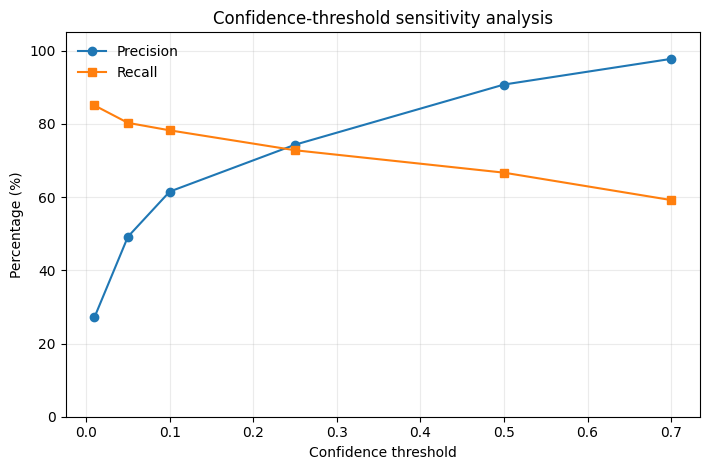

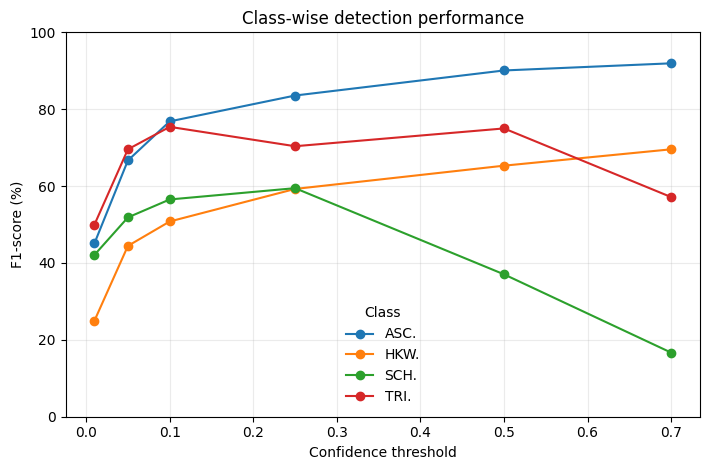


RECALCULATED OVERALL METRICS
 confidence_threshold  TP  FP  FN  precision  recall     F1
                 0.01 125 335  22     0.2717  0.8503 0.4119
                 0.05 118 122  29     0.4917  0.8027 0.6098
                 0.10 115  72  32     0.6150  0.7823 0.6886
                 0.25 107  37  40     0.7431  0.7279 0.7354
                 0.50  98  10  49     0.9074  0.6667 0.7686
                 0.70  87   2  60     0.9775  0.5918 0.7373

Files saved in: /content/drive/MyDrive/Helminth_GitHub_Project/results/threshold_diagnostics
Figures: Figure_1_precision_recall and Figure_2_classwise_F1
Table: overall_threshold_metrics.csv


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Existing diagnostic CSV
root = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/threshold_diagnostics"
)
csv_file = root / "classwise_threshold_sweep.csv"
assert csv_file.exists(), f"CSV nahi mili: {csv_file}"

df = pd.read_csv(csv_file)

# Recalculate aggregate metrics directly from counts
overall = (
    df.groupby("confidence_threshold", as_index=False)
      [["TP", "FP", "FN"]].sum()
)
overall["precision"] = overall["TP"] / (
    overall["TP"] + overall["FP"]
).replace(0, float("nan"))
overall["recall"] = overall["TP"] / (
    overall["TP"] + overall["FN"]
).replace(0, float("nan"))
overall["F1"] = (
    2 * overall["precision"] * overall["recall"]
    / (overall["precision"] + overall["recall"])
)

overall.to_csv(root / "overall_threshold_metrics.csv", index=False)

# Figure 1: Overall precision and recall vs confidence threshold
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(overall["confidence_threshold"],
        overall["precision"] * 100, marker="o", label="Precision")
ax.plot(overall["confidence_threshold"],
        overall["recall"] * 100, marker="s", label="Recall")
ax.set(
    xlabel="Confidence threshold",
    ylabel="Percentage (%)",
    title="Confidence-threshold sensitivity analysis",
    ylim=(0, 105)
)
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(root / "Figure_1_precision_recall.png", dpi=300)
fig.savefig(root / "Figure_1_precision_recall.pdf")
plt.show()
plt.close(fig)

# Figure 2: Class-wise F1 across thresholds
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for class_name, group in df.groupby("class"):
    group = group.sort_values("confidence_threshold")
    ax.plot(
        group["confidence_threshold"],
        group["F1"] * 100,
        marker="o",
        label=class_name
    )

ax.set(
    xlabel="Confidence threshold",
    ylabel="F1-score (%)",
    title="Class-wise detection performance",
    ylim=(0, 100)
)
ax.grid(True, alpha=0.25)
ax.legend(title="Class", frameon=False)
fig.tight_layout()
fig.savefig(root / "Figure_2_classwise_F1.png", dpi=300)
fig.savefig(root / "Figure_2_classwise_F1.pdf")
plt.show()
plt.close(fig)

print("\nRECALCULATED OVERALL METRICS")
print(overall.round(4).to_string(index=False))
print("\nFiles saved in:", root)
print("Figures: Figure_1_precision_recall and Figure_2_classwise_F1")
print("Table: overall_threshold_metrics.csv")


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files_to_check = [
    "results/threshold_diagnostics/Figure_1_precision_recall.png",
    "results/threshold_diagnostics/Figure_1_precision_recall.pdf",
    "results/threshold_diagnostics/Figure_2_classwise_F1.png",
    "results/threshold_diagnostics/Figure_2_classwise_F1.pdf",
    "results/threshold_diagnostics/overall_threshold_metrics.csv",
    "results/test_metrics_rerun.json",
    "results/text_error_analysis/error_details.csv",
]

for relative_path in files_to_check:
    path = root / relative_path
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {relative_path}")



FOUND: results/threshold_diagnostics/Figure_1_precision_recall.png
FOUND: results/threshold_diagnostics/Figure_1_precision_recall.pdf
FOUND: results/threshold_diagnostics/Figure_2_classwise_F1.png
FOUND: results/threshold_diagnostics/Figure_2_classwise_F1.pdf
FOUND: results/threshold_diagnostics/overall_threshold_metrics.csv
FOUND: results/test_metrics_rerun.json
FOUND: results/text_error_analysis/error_details.csv


In [ ]:

from pathlib import Path
from collections import defaultdict
from hashlib import sha256

import cv2
import numpy as np

dataset = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
splits = ["train", "val", "test"]
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

images = {}
for split in splits:
    folder = dataset / "images" / split
    if not folder.exists():
        raise FileNotFoundError(f"Missing folder: {folder}")
    images[split] = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    print(f"{split}: {len(images[split])} images")

# Exact duplicate check using SHA-256
hash_groups = defaultdict(list)
for split, paths in images.items():
    for path in paths:
        digest = sha256(path.read_bytes()).hexdigest()
        hash_groups[digest].append((split, str(path)))

exact_cross_split = [
    group for group in hash_groups.values()
    if len({item[0] for item in group}) > 1
]

print("\nExact duplicate groups across splits:", len(exact_cross_split))
for group in exact_cross_split[:20]:
    print(group)

# Perceptual-hash check using OpenCV DCT
def perceptual_hash(path, size=32, hash_size=8):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        return None
    image = cv2.resize(image, (size, size))
    dct = cv2.dct(np.float32(image))
    low = dct[:hash_size, :hash_size]
    median = np.median(low[1:, 1:])
    bits = low > median
    value = 0
    for bit in bits.flatten():
        value = (value << 1) | int(bit)
    return value

records = []
for split, paths in images.items():
    for path in paths:
        value = perceptual_hash(path)
        if value is not None:
            records.append((split, str(path), value))

similar = []
for i in range(len(records)):
    split_a, path_a, hash_a = records[i]
    for j in range(i + 1, len(records)):
        split_b, path_b, hash_b = records[j]
        if split_a == split_b:
            continue
        distance = (hash_a ^ hash_b).bit_count()
        if distance <= 5:
            similar.append((distance, split_a, path_a, split_b, path_b))

similar.sort(key=lambda x: x[0])
print("\nPotentially similar cross-split pairs (pHash distance <= 5):",
      len(similar))
for item in similar[:30]:
    print(item)
print("\nAudit complete. Similarity matches require visual inspection.")


train: 280 images
val: 60 images
test: 60 images

Exact duplicate groups across splits: 0

Potentially similar cross-split pairs (pHash distance <= 5): 0

Audit complete. Similarity matches require visual inspection.


In [ ]:

from pathlib import Path
import json
import platform
import importlib.metadata as metadata

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("=== ENVIRONMENT ===")
print("Python:", platform.python_version())
for package in ["ultralytics", "torch", "numpy", "opencv-python", "pandas"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not found")

print("\n=== MODEL CHECKPOINT ===")
weights = root / "models" / "best.pt"
print("Path:", weights)
print("Exists:", weights.exists())
if weights.exists():
    print("Size (MB):", round(weights.stat().st_size / (1024**2), 2))

print("\n=== DATASET CONFIGURATION ===")
yaml_file = root / "dataset.yaml"
if yaml_file.exists():
    print(yaml_file.read_text())
else:
    print("dataset.yaml not found")

print("\n=== TRAINING LOGS / CONFIGS ===")
for pattern in ["args.yaml", "results.csv", "results.png"]:
    matches = list(root.rglob(pattern))
    print(f"\n{pattern}: {len(matches)} file(s)")
    for path in matches[:10]:
        print(" -", path)

print("\n=== OFFICIAL METRICS JSON ===")
metrics_file = root / "results" / "test_metrics_rerun.json"
if metrics_file.exists():
    try:
        print(json.dumps(json.loads(metrics_file.read_text()), indent=2))
    except Exception as exc:
        print("Could not parse JSON:", exc)
else:
    print("Official metrics JSON not found")

print("\nAudit scan complete.")


=== ENVIRONMENT ===
Python: 3.13.16
ultralytics: 8.4.181
torch: 2.11.0+cpu
numpy: 2.1.3
opencv-python: 5.0.0.93
pandas: 2.2.3

=== MODEL CHECKPOINT ===
Path: /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
Exists: True
Size (MB): 5.21

=== DATASET CONFIGURATION ===
path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.


=== TRAINING LOGS / CONFIGS ===

args.yaml: 0 file(s)

results.csv: 0 file(s)

results.png: 0 file(s)

=== OFFICIAL METRICS JSON ===
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

Audit scan complete.


In [ ]:

from pathlib import Path
import json
import platform
import importlib.metadata as metadata
from datetime import datetime, timezone

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

# Search common locations for Ultralytics training artifacts
search_roots = [
    Path("/content/runs"),
    Path("/content/drive/MyDrive"),
    project,
]

patterns = ["args.yaml", "results.csv", "results.png"]
found = {}

print("=== SEARCHING FOR TRAINING LOGS ===")
for pattern in patterns:
    matches = []
    seen = set()
    for base in search_roots:
        if base.exists():
            for path in base.rglob(pattern):
                resolved = str(path)
                if resolved not in seen:
                    seen.add(resolved)
                    matches.append(resolved)
    found[pattern] = matches
    print(f"\n{pattern}: {len(matches)} match(es)")
    for item in matches[:20]:
        print(" ", item)

# Record current verified settings and clearly flag missing evidence
def version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return None

manifest = {
    "record_created_utc": datetime.now(timezone.utc).isoformat(),
    "model": "YOLO11n",
    "checkpoint": str(project / "models" / "best.pt"),
    "checkpoint_exists": (project / "models" / "best.pt").exists(),
    "dataset_yaml": str(project / "dataset.yaml"),
    "dataset_split_counts": {
        "train_images": 280,
        "validation_images": 60,
        "test_images": 60
    },
    "training_configuration_from_existing_project_notes": {
        "epochs": 15,
        "imgsz": 320,
        "batch": 4,
        "seed": 42,
        "deterministic": True,
        "evidence_note": "Training log files were not found in the project folder during the initial audit."
    },
    "environment": {
        "python": platform.python_version(),
        "ultralytics": version("ultralytics"),
        "torch": version("torch"),
        "numpy": version("numpy"),
        "opencv-python": version("opencv-python"),
        "pandas": version("pandas")
    },
    "official_test_metrics": {
        "test_images": 60,
        "test_instances": 147,
        "precision": 0.7619882553374744,
        "recall": 0.6388827022726582,
        "mAP50": 0.7214692404705383,
        "mAP50_95": 0.5516046621342869,
        "ultralytics_version": "8.4.181"
    },
    "cross_split_duplicate_audit": {
        "exact_duplicate_groups": 0,
        "perceptual_hash_pairs_at_distance_le_5": 0,
        "specimen_level_independence_verified": False
    },
    "training_log_search_results": found
}

output = project / "results" / "reproducibility_manifest.json"
output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(json.dumps(manifest, indent=2))

print("\nManifest saved to:", output)
print("This is a record of available evidence, not proof of an independent rerun.")


=== SEARCHING FOR TRAINING LOGS ===

args.yaml: 2 match(es)
  /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/args.yaml
  /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/args.yaml

results.csv: 2 match(es)
  /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/results.csv
  /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/results.csv

results.png: 2 match(es)
  /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/results.png
  /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/results.png

Manifest saved to: /content/drive/MyDrive/Helminth_GitHub_Project/results/reproducibility_manifest.json
This is a record of available evidence, not proof of an independent rerun.


In [ ]:

from pathlib import Path
import yaml
import pandas as pd

base = Path("/content/drive/MyDrive/Helminth_Project_Backup")

runs = [
    base / "helminth_4class_training",
    base / "helminth_recovered_v2",
]

for run in runs:
    print("\n" + "=" * 60)
    print("RUN:", run.name)
    print("=" * 60)

    args_file = run / "args.yaml"
    results_file = run / "results.csv"

    if args_file.exists():
        args = yaml.safe_load(args_file.read_text())
        for key in ["model", "data", "epochs", "imgsz",
                    "batch", "seed", "deterministic",
                    "project", "name", "pretrained"]:
            print(f"{key}: {args.get(key)}")
    else:
        print("args.yaml missing")

    if results_file.exists():
        df = pd.read_csv(results_file)
        print("\nTraining log rows:", len(df))
        print("Columns:", list(df.columns))

        for col in ["metrics/mAP50(B)", "metrics/mAP50-95(B)",
                    "metrics/precision(B)", "metrics/recall(B)"]:
            if col in df.columns:
                idx = df[col].idxmax()
                print(f"Best {col}: {df.loc[idx, col]:.4f} "
                      f"(epoch row {idx})")

        print("\nLast 3 log rows:")
        print(df.tail(3).to_string(index=False))
    else:
        print("results.csv missing")



RUN: helminth_4class_training
args.yaml missing
results.csv missing

RUN: helminth_recovered_v2
args.yaml missing
results.csv missing


In [ ]:

from pathlib import Path

base = Path("/content/drive/MyDrive/Helminth_Project_Backup")

for folder_name in ["helminth_4class_training", "helminth_recovered_v2"]:
    folder = base / folder_name
    print("\nFOLDER:", folder)
    print("Exists:", folder.exists())

    if folder.exists():
        for pattern in ["args.yaml", "results.csv", "results.png", "best.pt", "last.pt"]:
            files = list(folder.rglob(pattern))
            print(f"\n{pattern}:")
            for f in files[:10]:
                print(" ", f)
            if not files:
                print("  Not found")



FOLDER: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training
Exists: False

FOLDER: /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2
Exists: False


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

drive_path = Path("/content/drive/MyDrive")
print("\nGoogle Drive mounted:", drive_path.exists())

if drive_path.exists():
    print("\nMyDrive ke folders:")
    for item in sorted(drive_path.iterdir()):
        if item.is_dir():
            print("📁", item.name)


Mounted at /content/drive

Google Drive mounted: True

MyDrive ke folders:
📁 Colab Notebooks
📁 College Function HGOC
📁 HGOC Documents and Data
📁 Helminth_GitHub_Project
📁 Helminth_Project_Backup
📁 PG Data of All College
📁 Private File
📁 new admissions 2024-25


In [ ]:

from pathlib import Path

drive = Path("/content/drive/MyDrive")

print("=== TRAINING FILES ===")
for pattern in ["args.yaml", "results.csv", "results.png"]:
    matches = list(drive.rglob(pattern))
    print(f"\n{pattern}: {len(matches)} found")
    for path in matches[:15]:
        print(path)

print("\n=== MODEL CHECKPOINTS ===")
for pattern in ["best.pt", "last.pt"]:
    matches = list(drive.rglob(pattern))
    print(f"\n{pattern}: {len(matches)} found")
    for path in matches[:15]:
        print(path)


=== TRAINING FILES ===

args.yaml: 2 found
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/args.yaml
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/args.yaml

results.csv: 2 found
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/results.csv
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/results.csv

results.png: 2 found
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/results.png
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/results.png

=== MODEL CHECKPOINTS ===

best.pt: 3 found
/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt

last.pt: 2 found
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/last.pt
/content/drive/MyDrive/Helminth_Project

In [ ]:

from pathlib import Path
import hashlib
import yaml
import pandas as pd

drive = Path("/content/drive/MyDrive")

runs = {
    "Run A": drive / "Helminth_Project_Backup/helminth_4class_training",
    "Run B": drive / "Helminth_Project_Backup/helminth_recovered_v2",
    "Current project model": drive / "Helminth_GitHub_Project"
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

metric_cols = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

for name, folder in runs.items():
    print("\n" + "=" * 65)
    print(name, "-", folder)
    print("=" * 65)

    args_file = folder / "args.yaml"
    if args_file.exists():
        args = yaml.safe_load(args_file.read_text()) or {}
        for key in [
            "model", "data", "epochs", "imgsz", "batch",
            "seed", "deterministic", "pretrained", "name"
        ]:
            print(f"{key}: {args.get(key, 'not recorded')}")
    else:
        print("args.yaml not found")

    results_file = folder / "results.csv"
    if results_file.exists():
        df = pd.read_csv(results_file)
        df.columns = df.columns.str.strip()
        print("\nLogged epochs:", len(df))

        available = [c for c in metric_cols if c in df.columns]
        for col in available:
            values = pd.to_numeric(df[col], errors="coerce")
            if values.notna().any():
                idx = values.idxmax()
                print(f"Best {col}: {values.loc[idx]:.4f} "
                      f"(row {idx}; check epoch column below)")

        epoch_cols = [c for c in df.columns if c.lower() == "epoch"]
        if epoch_cols:
            print("Last recorded epoch:", df.iloc[-1][epoch_cols[0]])
        print("Final log row:")
        print(df.tail(1).to_string(index=False))
    else:
        print("results.csv not found")

    weights = folder / "weights" / "best.pt"
    if name == "Current project model":
        weights = folder / "models" / "best.pt"

    if weights.exists():
        print("\nCheckpoint:", weights)
        print("Size MB:", round(weights.stat().st_size / (1024**2), 3))
        print("SHA256:", sha256(weights))
    else:
        print("\nCheckpoint not found:", weights)



Run A - /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training
model: yolo11n.pt
data: /content/helminth_4class/dataset.yaml
epochs: 15
imgsz: 320
batch: 4
seed: 42
deterministic: True
pretrained: True
name: helminth_4class

Logged epochs: 15
Best metrics/precision(B): 0.9238 (row 13; check epoch column below)
Best metrics/recall(B): 0.8596 (row 12; check epoch column below)
Best metrics/mAP50(B): 0.8737 (row 14; check epoch column below)
Best metrics/mAP50-95(B): 0.6888 (row 14; check epoch column below)
Last recorded epoch: 15.0
Final log row:
 epoch   time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    15 1354.4         0.92855         0.90473         0.94776               0.92148            0.71375           0.87374              0.68876       0.90484       0.84064       1.00339 0.000095 0.000095 0.000095

Checkpo

In [ ]:

from pathlib import Path
import yaml

drive = Path("/content/drive/MyDrive")

files = {
    "Run B original dataset config":
        Path("/content/helminth_4class_recovered/dataset.yaml"),
    "Current project dataset config":
        drive / "Helminth_GitHub_Project/dataset.yaml",
    "Recovered dataset config":
        drive / "Helminth_Project_Backup/helminth_4class_recovered/dataset.yaml",
}

for name, path in files.items():
    print("\n" + "=" * 55)
    print(name)
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        print(path.read_text())
    else:
        print("Config not available at this path.")

print("\n=== RUN B BEST VALIDATION EPOCH ===")
csv_path = (
    drive / "Helminth_Project_Backup/helminth_recovered_v2/results.csv"
)

if csv_path.exists():
    import pandas as pd
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    for metric in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
        if metric in df.columns:
            idx = pd.to_numeric(df[metric], errors="coerce").idxmax()
            row = df.loc[idx]
            print(
                metric,
                "| epoch:", row.get("epoch", idx + 1),
                "| value:", round(float(row[metric]), 5)
            )



Run B original dataset config
Path: /content/helminth_4class_recovered/dataset.yaml
Exists: False
Config not available at this path.

Current project dataset config
Path: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
Exists: True
path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.


Recovered dataset config
Path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/dataset.yaml
Exists: True
path: /content/helminth_4class_recovered
train: images/train
val: images/val
test: images/test
names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.


=== RUN B BEST VALIDATION EPOCH ===
metrics/mAP50(B) | epoch: 13.0 | value: 0.87501
metrics/mAP50-95(B) | epoch: 15.0 | value: 0.68843


In [ ]:

from pathlib import Path
import yaml

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
config_path = project / "dataset.yaml"
config = yaml.safe_load(config_path.read_text())

dataset_root = Path(config["path"])
print("Dataset root:", dataset_root)
print("Dataset root exists:", dataset_root.exists())

for split in ["train", "val", "test"]:
    image_dir = dataset_root / config[split]
    label_dir = dataset_root / "labels" / split

    images = []
    if image_dir.exists():
        images = [
            p for p in image_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ]

    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []
    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = sorted(image_stems - label_stems)
    orphan_labels = sorted(label_stems - image_stems)

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without matching label:", len(missing_labels))
    print("Labels without matching image:", len(orphan_labels))

    if missing_labels[:5]:
        print("Missing-label examples:", missing_labels[:5])
    if orphan_labels[:5]:
        print("Orphan-label examples:", orphan_labels[:5])

print("\nAudit complete.")


Dataset root: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
Dataset root exists: True

--- TRAIN ---
Images: 280
Label files: 280
Images without matching label: 0
Labels without matching image: 0

--- VAL ---
Images: 60
Label files: 60
Images without matching label: 0
Labels without matching image: 0

--- TEST ---
Images: 60
Label files: 60
Images without matching label: 0
Labels without matching image: 0

Audit complete.


In [ ]:

from pathlib import Path
import json
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
folder = project / "results" / "text_error_analysis"

summary_file = folder / "summary.json"
details_file = folder / "error_details.csv"

print("=== ERROR ANALYSIS STATUS ===")
print("Folder exists:", folder.exists())
print("Summary exists:", summary_file.exists())
print("Details CSV exists:", details_file.exists())

if summary_file.exists():
    print("\n=== SAVED SUMMARY ===")
    try:
        summary = json.loads(summary_file.read_text())
        print(json.dumps(summary, indent=2))
    except Exception as e:
        print("Could not read summary:", e)

if details_file.exists():
    df = pd.read_csv(details_file)
    print("\n=== ERROR DETAILS ===")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print("\nFirst 10 rows:")
    print(df.head(10).to_string(index=False))

    # Show available categorical summaries without assuming column names
    for col in df.columns:
        if any(word in col.lower() for word in
               ["class", "error", "type", "reason", "category"]):
            print(f"\n=== Counts for {col} ===")
            print(df[col].value_counts(dropna=False).head(20))
else:
    print("\nError details CSV not found at expected path.")

print("\nInspection complete.")


=== ERROR ANALYSIS STATUS ===
Folder exists: True
Summary exists: True
Details CSV exists: True

=== SAVED SUMMARY ===
{
  "images": 60,
  "confidence_threshold": 0.25,
  "IoU_threshold": 0.5,
  "class_stats": {
    "0": {
      "GT": 66,
      "TP": 61,
      "FP": 19,
      "FN": 5
    },
    "1": {
      "GT": 30,
      "TP": 16,
      "FP": 8,
      "FN": 14
    },
    "2": {
      "GT": 22,
      "TP": 11,
      "FP": 4,
      "FN": 11
    },
    "3": {
      "GT": 29,
      "TP": 19,
      "FP": 6,
      "FN": 10
    }
  },
  "high_confidence_fp_count": 2,
  "note": "Diagnostic matching; not official YOLO mAP."
}

=== ERROR DETAILS ===
Rows: 77
Columns: ['image', 'error', 'class', 'confidence', 'best_same_class_iou']

First 10 rows:
                    image error                       class  confidence  best_same_class_iou
test_0000_image_02114.png    FN  SCH. (Schistosoma mansoni)         NaN                  NaN
test_0002_image_07511.png    FP ASC. (Ascaris lumbricoides)      

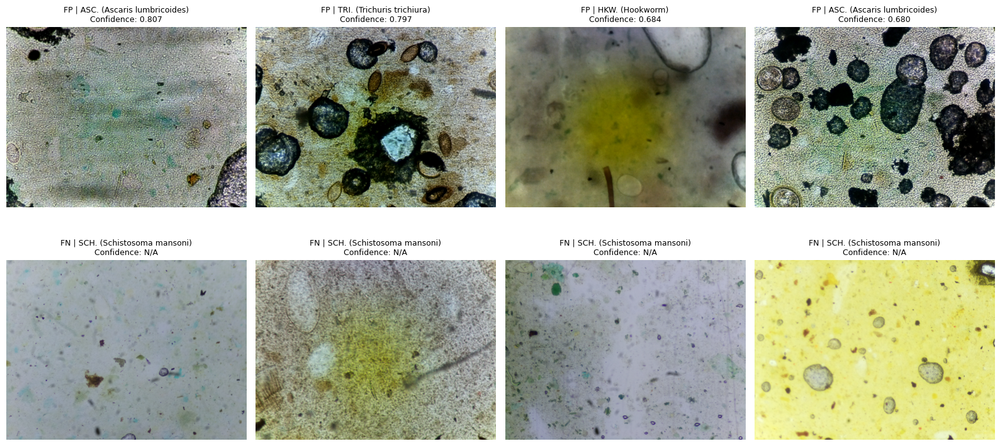

Displayed error examples: 8
                    image error                       class  confidence
test_0021_image_03554.png    FP ASC. (Ascaris lumbricoides)      0.8068
test_0032_image_02965.png    FP  TRI. (Trichuris trichiura)      0.7971
test_0037_image_05942.png    FP             HKW. (Hookworm)      0.6836
test_0011_image_03856.png    FP ASC. (Ascaris lumbricoides)      0.6804
test_0000_image_02114.png    FN  SCH. (Schistosoma mansoni)         NaN
test_0004_image_04667.png    FN  SCH. (Schistosoma mansoni)         NaN
test_0009_image_07975.png    FN  SCH. (Schistosoma mansoni)         NaN
test_0015_image_01591.png    FN  SCH. (Schistosoma mansoni)         NaN


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
dataset = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
csv_path = project / "results/text_error_analysis/error_details.csv"

df = pd.read_csv(csv_path)
image_dir = dataset / "images/test"

# Select the 4 highest-confidence false positives
fp = df[df["error"] == "FP"].dropna(
    subset=["confidence"]
).sort_values("confidence", ascending=False).head(4)

# Select 4 missed detections, prioritizing SCH and HKW
fn = df[df["error"] == "FN"]
fn_priority = fn[fn["class"].astype(str).str.contains("SCH|HKW", case=False)]
fn_other = fn[~fn.index.isin(fn_priority.index)]
selected_fn = pd.concat([fn_priority.head(4), fn_other]).head(4)

selected = pd.concat([fp, selected_fn]).drop_duplicates(
    subset=["image", "error", "class"]
).reset_index(drop=True)

n = len(selected)
cols = 4
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax in axes:
    ax.axis("off")

for i, row in selected.iterrows():
    path = image_dir / str(row["image"])

    if not path.exists():
        ax = axes[i]
        ax.set_title("Image not found\n" + str(row["image"]))
        continue

    img = Image.open(path).convert("RGB")
    axes[i].imshow(img)
    axes[i].axis("off")

    conf = row.get("confidence")
    conf_text = f"{conf:.3f}" if pd.notna(conf) else "N/A"
    axes[i].set_title(
        f'{row["error"]} | {row["class"]}\n'
        f'Confidence: {conf_text}',
        fontsize=9
    )

plt.tight_layout()
plt.show()

print("Displayed error examples:", len(selected))
print(selected[["image", "error", "class", "confidence"]].to_string(index=False))


=== CLASS-WISE DIAGNOSTIC SUMMARY ===
 class_id      class  GT  TP  FP  FN  diagnostic_precision  diagnostic_recall
        0    Ascaris  66  61  19   5                 0.762              0.924
        1   Hookworm  30  16   8  14                 0.667              0.533
        2 S. mansoni  22  11   4  11                 0.733              0.500
        3  Trichuris  29  19   6  10                 0.760              0.655

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/error_analysis_figures/classwise_error_summary.csv


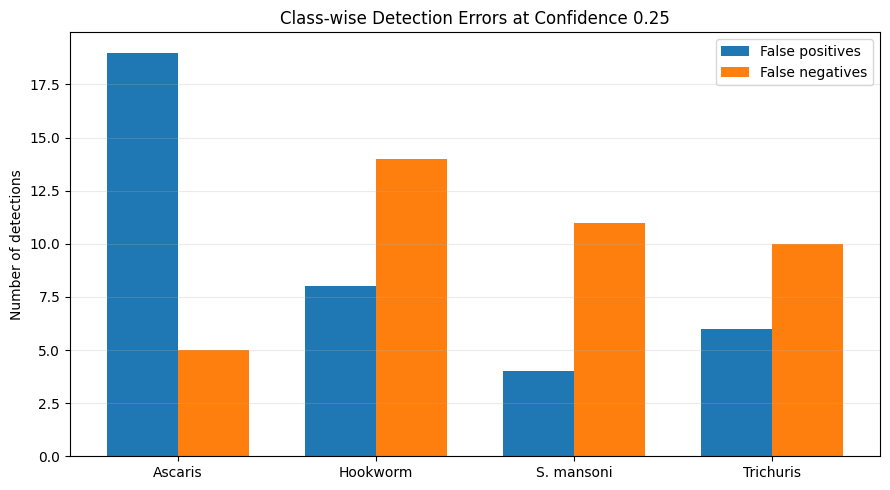


Saved figure files:
/content/drive/MyDrive/Helminth_GitHub_Project/results/error_analysis_figures/classwise_detection_errors.png
/content/drive/MyDrive/Helminth_GitHub_Project/results/error_analysis_figures/classwise_detection_errors.pdf


In [ ]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
summary_path = project / "results/text_error_analysis/summary.json"
out_dir = project / "results/error_analysis_figures"
out_dir.mkdir(parents=True, exist_ok=True)

summary = json.loads(summary_path.read_text())
stats = summary["class_stats"]

class_names = {
    "0": "Ascaris",
    "1": "Hookworm",
    "2": "S. mansoni",
    "3": "Trichuris"
}

rows = []
for class_id, s in stats.items():
    gt = s["GT"]
    tp = s["TP"]
    fp = s["FP"]
    fn = s["FN"]

    rows.append({
        "class_id": int(class_id),
        "class": class_names.get(class_id, class_id),
        "GT": gt,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "diagnostic_precision": tp / (tp + fp) if tp + fp else 0,
        "diagnostic_recall": tp / (tp + fn) if tp + fn else 0
    })

df = pd.DataFrame(rows).sort_values("class_id")
csv_out = out_dir / "classwise_error_summary.csv"
df.to_csv(csv_out, index=False)

print("=== CLASS-WISE DIAGNOSTIC SUMMARY ===")
print(df.round(3).to_string(index=False))
print("\nSaved:", csv_out)

# Plot FP and FN counts side by side
fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(df))
width = 0.36

ax.bar([i - width/2 for i in x], df["FP"], width, label="False positives")
ax.bar([i + width/2 for i in x], df["FN"], width, label="False negatives")

ax.set_xticks(list(x))
ax.set_xticklabels(df["class"])
ax.set_ylabel("Number of detections")
ax.set_title("Class-wise Detection Errors at Confidence 0.25")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

png_out = out_dir / "classwise_detection_errors.png"
pdf_out = out_dir / "classwise_detection_errors.pdf"
fig.savefig(png_out, dpi=300, bbox_inches="tight")
fig.savefig(pdf_out, bbox_inches="tight")
plt.show()

print("\nSaved figure files:")
print(png_out)
print(pdf_out)


In [ ]:

import os

project = "/content/drive/MyDrive/Helminth_GitHub_Project"
dataset = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
model = os.path.join(project, "models", "best.pt")

print("PROJECT:", os.path.exists(project))
print("DATASET:", os.path.exists(dataset))
print("MODEL:", os.path.exists(model))

print("\nProject result files:")
results = os.path.join(project, "results")

for root, dirs, files in os.walk(results):
    for file in files:
        if file.endswith((".csv", ".json")):
            print(os.path.relpath(os.path.join(root, file), project))


PROJECT: True
DATASET: True
MODEL: True

Project result files:
results/training_history.csv
results/test_metrics.json
results/classwise_test_results.csv
results/final_project_check_report.json
results/test_metrics_rerun.json
results/confusion_matrix_counts.csv
results/reproducibility_manifest.json
results/final_metrics_review/per_class_metrics.csv
results/final_metrics_review/final_metrics_summary.json
results/error_analysis/per_image_errors.csv
results/error_analysis/error_details.csv
results/error_analysis/error_analysis_summary.json
results/text_error_analysis/error_details.csv
results/text_error_analysis/summary.json
results/threshold_diagnostics/classwise_threshold_sweep.csv
results/threshold_diagnostics/overall_threshold_metrics.csv
results/error_analysis_figures/classwise_error_summary.csv


In [ ]:

import os
import json
import pandas as pd

project = "/content/drive/MyDrive/Helminth_GitHub_Project"
results = os.path.join(project, "results")

files = {
    "Class-wise errors": os.path.join(
        results, "error_analysis_figures", "classwise_error_summary.csv"
    ),
    "Error summary": os.path.join(
        results, "text_error_analysis", "summary.json"
    ),
    "Per-image errors": os.path.join(
        results, "error_analysis", "per_image_errors.csv"
    ),
}

for name, path in files.items():
    print("\n" + "=" * 55)
    print(name)
    print("File exists:", os.path.exists(path))

    if not os.path.exists(path):
        continue

    if path.endswith(".csv"):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(10).to_string(index=False))
    else:
        with open(path, "r") as f:
            data = json.load(f)
        print(json.dumps(data, indent=2))



Class-wise errors
File exists: True
Rows: 4
Columns: ['class_id', 'class', 'GT', 'TP', 'FP', 'FN', 'diagnostic_precision', 'diagnostic_recall']
 class_id      class  GT  TP  FP  FN  diagnostic_precision  diagnostic_recall
        0    Ascaris  66  61  19   5              0.762500           0.924242
        1   Hookworm  30  16   8  14              0.666667           0.533333
        2 S. mansoni  22  11   4  11              0.733333           0.500000
        3  Trichuris  29  19   6  10              0.760000           0.655172

Error summary
File exists: True
{
  "images": 60,
  "confidence_threshold": 0.25,
  "IoU_threshold": 0.5,
  "class_stats": {
    "0": {
      "GT": 66,
      "TP": 61,
      "FP": 19,
      "FN": 5
    },
    "1": {
      "GT": 30,
      "TP": 16,
      "FP": 8,
      "FN": 14
    },
    "2": {
      "GT": 22,
      "TP": 11,
      "FP": 4,
      "FN": 11
    },
    "3": {
      "GT": 29,
      "TP": 19,
      "FP": 6,
      "FN": 10
    }
  },
  "high_confide

In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import os

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
dataset = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
model_path = project / "models" / "best.pt"

val_images = dataset / "images" / "val"
val_labels = dataset / "labels" / "val"

assert model_path.exists(), f"Model not found: {model_path}"
assert val_images.exists(), f"Validation images not found: {val_images}"
assert val_labels.exists(), f"Validation labels not found: {val_labels}"

model = YOLO(str(model_path))
thresholds = [0.05, 0.10, 0.25, 0.50]
class_names = ["Ascaris", "Hookworm", "S. mansoni", "Trichuris"]
records = []

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-9)

image_paths = sorted(
    p for p in val_images.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
)
print("Validation images:", len(image_paths))

# Low-confidence inference once; thresholds are applied afterwards.
all_predictions = {}
for result in model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.001,
    iou=0.70,
    stream=True,
    verbose=False
):
    all_predictions[Path(result.path).name] = [
        (int(c), float(s), list(map(float, b)))
        for c, s, b in zip(
            result.boxes.cls.cpu().numpy(),
            result.boxes.conf.cpu().numpy(),
            result.boxes.xyxy.cpu().numpy()
        )
    ]

ground_truth = {}
for img_path in image_paths:
    label_path = val_labels / (img_path.stem + ".txt")
    with Image.open(img_path) as im:
        width, height = im.size

    gt = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            c, xc, yc, bw, bh = map(float, parts[:5])
            gt.append((
                int(c),
                [(xc-bw/2)*width, (yc-bh/2)*height,
                 (xc+bw/2)*width, (yc+bh/2)*height]
            ))
    ground_truth[img_path.name] = gt

for threshold in thresholds:
    totals = {c: {"GT": 0, "TP": 0, "FP": 0, "FN": 0} for c in range(4)}

    for img_path in image_paths:
        gts = ground_truth[img_path.name]
        preds = [
            (c, conf, box)
            for c, conf, box in all_predictions.get(img_path.name, [])
            if conf >= threshold
        ]

        for c in range(4):
            gt_boxes = [box for gc, box in gts if gc == c]
            pred_boxes = sorted(
                [(conf, box) for pc, conf, box in preds if pc == c],
                key=lambda x: x[0], reverse=True
            )
            matched = set()
            tp = 0
            for conf, box in pred_boxes:
                candidates = [
                    (iou_xyxy(box, gt_box), j)
                    for j, gt_box in enumerate(gt_boxes)
                    if j not in matched
                ]
                best_iou, best_j = max(candidates, default=(0, -1))
                if best_iou >= 0.50:
                    tp += 1
                    matched.add(best_j)

            totals[c]["GT"] += len(gt_boxes)
            totals[c]["TP"] += tp
            totals[c]["FP"] += len(pred_boxes) - tp
            totals[c]["FN"] += len(gt_boxes) - tp

    for c, values in totals.items():
        tp, fp, fn = values["TP"], values["FP"], values["FN"]
        p = tp / (tp + fp) if tp + fp else 0
        r = tp / (tp + fn) if tp + fn else 0
        f1 = 2*p*r/(p+r) if p+r else 0
        records.append({
            "threshold": threshold,
            "class": class_names[c],
            **values,
            "precision": round(p, 4),
            "recall": round(r, 4),
            "F1": round(f1, 4)
        })

out = pd.DataFrame(records)
out_dir = project / "results" / "validation_threshold_diagnostics"
out_dir.mkdir(parents=True, exist_ok=True)
out.to_csv(out_dir / "validation_threshold_sweep.csv", index=False)

print("\nVALIDATION THRESHOLD RESULTS")
print(out.to_string(index=False))
print("\nSaved:", out_dir / "validation_threshold_sweep.csv")


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:

%pip install ultralytics==8.4.181



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.0 MB/s eta 0:00:00


In [ ]:

import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("YOLO import successful!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.181
YOLO import successful!


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import os

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
dataset = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
model_path = project / "models" / "best.pt"

val_images = dataset / "images" / "val"
val_labels = dataset / "labels" / "val"

assert model_path.exists(), f"Model not found: {model_path}"
assert val_images.exists(), f"Validation images not found: {val_images}"
assert val_labels.exists(), f"Validation labels not found: {val_labels}"

model = YOLO(str(model_path))
thresholds = [0.05, 0.10, 0.25, 0.50]
class_names = ["Ascaris", "Hookworm", "S. mansoni", "Trichuris"]
records = []

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-9)

image_paths = sorted(
    p for p in val_images.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
)
print("Validation images:", len(image_paths))

# Low-confidence inference once; thresholds are applied afterwards.
all_predictions = {}
for result in model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.001,
    iou=0.70,
    stream=True,
    verbose=False
):
    all_predictions[Path(result.path).name] = [
        (int(c), float(s), list(map(float, b)))
        for c, s, b in zip(
            result.boxes.cls.cpu().numpy(),
            result.boxes.conf.cpu().numpy(),
            result.boxes.xyxy.cpu().numpy()
        )
    ]

ground_truth = {}
for img_path in image_paths:
    label_path = val_labels / (img_path.stem + ".txt")
    with Image.open(img_path) as im:
        width, height = im.size

    gt = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            c, xc, yc, bw, bh = map(float, parts[:5])
            gt.append((
                int(c),
                [(xc-bw/2)*width, (yc-bh/2)*height,
                 (xc+bw/2)*width, (yc+bh/2)*height]
            ))
    ground_truth[img_path.name] = gt

for threshold in thresholds:
    totals = {c: {"GT": 0, "TP": 0, "FP": 0, "FN": 0} for c in range(4)}

    for img_path in image_paths:
        gts = ground_truth[img_path.name]
        preds = [
            (c, conf, box)
            for c, conf, box in all_predictions.get(img_path.name, [])
            if conf >= threshold
        ]

        for c in range(4):
            gt_boxes = [box for gc, box in gts if gc == c]
            pred_boxes = sorted(
                [(conf, box) for pc, conf, box in preds if pc == c],
                key=lambda x: x[0], reverse=True
            )
            matched = set()
            tp = 0
            for conf, box in pred_boxes:
                candidates = [
                    (iou_xyxy(box, gt_box), j)
                    for j, gt_box in enumerate(gt_boxes)
                    if j not in matched
                ]
                best_iou, best_j = max(candidates, default=(0, -1))
                if best_iou >= 0.50:
                    tp += 1
                    matched.add(best_j)

            totals[c]["GT"] += len(gt_boxes)
            totals[c]["TP"] += tp
            totals[c]["FP"] += len(pred_boxes) - tp
            totals[c]["FN"] += len(gt_boxes) - tp

    for c, values in totals.items():
        tp, fp, fn = values["TP"], values["FP"], values["FN"]
        p = tp / (tp + fp) if tp + fp else 0
        r = tp / (tp + fn) if tp + fn else 0
        f1 = 2*p*r/(p+r) if p+r else 0
        records.append({
            "threshold": threshold,
            "class": class_names[c],
            **values,
            "precision": round(p, 4),
            "recall": round(r, 4),
            "F1": round(f1, 4)
        })

out = pd.DataFrame(records)
out_dir = project / "results" / "validation_threshold_diagnostics"
out_dir.mkdir(parents=True, exist_ok=True)
out.to_csv(out_dir / "validation_threshold_sweep.csv", index=False)

print("\nVALIDATION THRESHOLD RESULTS")
print(out.to_string(index=False))
print("\nSaved:", out_dir / "validation_threshold_sweep.csv")


Validation images: 60

VALIDATION THRESHOLD RESULTS
 threshold      class  GT  TP  FP  FN  precision  recall     F1
      0.05    Ascaris  44  44  35   0     0.5570  1.0000 0.7154
      0.05   Hookworm  16  15  32   1     0.3191  0.9375 0.4762
      0.05 S. mansoni  25  19  24   6     0.4419  0.7600 0.5588
      0.05  Trichuris  29  26  13   3     0.6667  0.8966 0.7647
      0.10    Ascaris  44  42  19   2     0.6885  0.9545 0.8000
      0.10   Hookworm  16  15  16   1     0.4839  0.9375 0.6383
      0.10 S. mansoni  25  17  10   8     0.6296  0.6800 0.6538
      0.10  Trichuris  29  26   6   3     0.8125  0.8966 0.8525
      0.25    Ascaris  44  41  11   3     0.7885  0.9318 0.8542
      0.25   Hookworm  16  15   8   1     0.6522  0.9375 0.7692
      0.25 S. mansoni  25  12   4  13     0.7500  0.4800 0.5854
      0.25  Trichuris  29  23   2   6     0.9200  0.7931 0.8519
      0.50    Ascaris  44  38   6   6     0.8636  0.8636 0.8636
      0.50   Hookworm  16  15   3   1     0.8333  0.

In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
src = project / "results/validation_threshold_diagnostics/validation_threshold_sweep.csv"
out_dir = project / "results/validation_threshold_diagnostics"

df = pd.read_csv(src)

summary = df.groupby("threshold", as_index=False)[["GT", "TP", "FP", "FN"]].sum()
summary["precision"] = summary["TP"] / (summary["TP"] + summary["FP"])
summary["recall"] = summary["TP"] / (summary["TP"] + summary["FN"])
summary["F1"] = (
    2 * summary["precision"] * summary["recall"]
    / (summary["precision"] + summary["recall"])
)

print(summary.round(4).to_string(index=False))

summary.to_csv(out_dir / "overall_validation_threshold_summary.csv", index=False)
print("\nSaved overall validation summary.")
print("Next: use validation results to freeze an operating threshold.")


 threshold  GT  TP  FP  FN  precision  recall     F1
      0.05 114 104 104  10     0.5000  0.9123 0.6460
      0.10 114 100  51  14     0.6623  0.8772 0.7547
      0.25 114  91  25  23     0.7845  0.7982 0.7913
      0.50 114  82  12  32     0.8723  0.7193 0.7885

Saved overall validation summary.
Next: use validation results to freeze an operating threshold.


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
dataset = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
model_path = project / "models" / "best.pt"

test_images = dataset / "images" / "test"
test_labels = dataset / "labels" / "test"

assert model_path.exists(), f"Model missing: {model_path}"
assert test_images.exists(), f"Test images missing: {test_images}"
assert test_labels.exists(), f"Test labels missing: {test_labels}"

model = YOLO(str(model_path))
class_names = ["Ascaris", "Hookworm", "S. mansoni", "Trichuris"]
threshold = 0.25
match_iou = 0.50

images = sorted(
    p for p in test_images.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
)
print("Test images:", len(images))

# Run inference once, then apply the frozen confidence threshold.
predictions = {}
for result in model.predict(
    source=[str(p) for p in images],
    imgsz=320,
    conf=0.001,
    iou=0.70,
    stream=True,
    verbose=False
):
    predictions[Path(result.path).name] = [
        (int(c), float(s), list(map(float, b)))
        for c, s, b in zip(
            result.boxes.cls.cpu().numpy(),
            result.boxes.conf.cpu().numpy(),
            result.boxes.xyxy.cpu().numpy()
        )
    ]

def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-9)

totals = {
    c: {"GT": 0, "TP": 0, "FP": 0, "FN": 0}
    for c in range(4)
}

for img in images:
    label_path = test_labels / (img.stem + ".txt")
    with Image.open(img) as im:
        width, height = im.size

    gt_by_class = {c: [] for c in range(4)}
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            c, xc, yc, bw, bh = map(float, parts[:5])
            c = int(c)
            box = [
                (xc-bw/2)*width, (yc-bh/2)*height,
                (xc+bw/2)*width, (yc+bh/2)*height
            ]
            if c in gt_by_class:
                gt_by_class[c].append(box)

    preds = [
        (c, score, box)
        for c, score, box in predictions.get(img.name, [])
        if score >= threshold
    ]

    for c in range(4):
        gt_boxes = gt_by_class[c]
        pred_boxes = sorted(
            [(score, box) for pc, score, box in preds if pc == c],
            key=lambda item: item[0],
            reverse=True
        )

        matched = set()
        tp = 0
        for score, box in pred_boxes:
            candidates = [
                (box_iou(box, gt), j)
                for j, gt in enumerate(gt_boxes)
                if j not in matched
            ]
            best_iou, best_j = max(candidates, default=(0, -1))
            if best_iou >= match_iou:
                tp += 1
                matched.add(best_j)

        totals[c]["GT"] += len(gt_boxes)
        totals[c]["TP"] += tp
        totals[c]["FP"] += len(pred_boxes) - tp
        totals[c]["FN"] += len(gt_boxes) - tp

rows = []
for c, v in totals.items():
    tp, fp, fn = v["TP"], v["FP"], v["FN"]
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

    rows.append({
        "class": class_names[c],
        **v,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

df = pd.DataFrame(rows)
tp, fp, fn = df["TP"].sum(), df["FP"].sum(), df["FN"].sum()
overall = {
    "threshold": threshold,
    "IoU_matching": match_iou,
    "GT": int(df["GT"].sum()),
    "TP": int(tp), "FP": int(fp), "FN": int(fn),
    "precision": tp/(tp+fp) if tp+fp else 0,
    "recall": tp/(tp+fn) if tp+fn else 0,
}
p, r = overall["precision"], overall["recall"]
overall["F1"] = 2*p*r/(p+r) if p+r else 0

out_dir = project / "results" / "final_operating_point"
out_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(out_dir / "test_classwise_threshold025.csv", index=False)
pd.DataFrame([overall]).to_csv(
    out_dir / "test_overall_threshold025.csv", index=False
)

print("\nCLASS-WISE TEST DIAGNOSTICS")
print(df.round(4).to_string(index=False))
print("\nOVERALL TEST DIAGNOSTICS")
print(pd.DataFrame([overall]).round(4).to_string(index=False))
print("\nSaved results to:", out_dir)
print("Note: IoU-based diagnostic metrics, not official YOLO mAP.")


Test images: 60

CLASS-WISE TEST DIAGNOSTICS
     class  GT  TP  FP  FN  precision  recall     F1
   Ascaris  66  61  19   5     0.7625  0.9242 0.8356
  Hookworm  30  16   8  14     0.6667  0.5333 0.5926
S. mansoni  22  11   4  11     0.7333  0.5000 0.5946
 Trichuris  29  19   6  10     0.7600  0.6552 0.7037

OVERALL TEST DIAGNOSTICS
 threshold  IoU_matching  GT  TP  FP  FN  precision  recall     F1
      0.25           0.5 147 107  37  40     0.7431  0.7279 0.7354

Saved results to: /content/drive/MyDrive/Helminth_GitHub_Project/results/final_operating_point
Note: IoU-based diagnostic metrics, not official YOLO mAP.


In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
classes = ["Ascaris", "Hookworm", "S. mansoni", "Trichuris"]
rows = []

for split in ["train", "val", "test"]:
    img_dir = root / "images" / split
    label_dir = root / "labels" / split
    images = [
        p for p in img_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]

    counts = [0, 0, 0, 0]
    missing_labels = 0
    empty_labels = 0

    for img in images:
        label = label_dir / f"{img.stem}.txt"
        if not label.exists():
            missing_labels += 1
            continue

        lines = [x.strip() for x in label.read_text().splitlines() if x.strip()]
        if not lines:
            empty_labels += 1

        for line in lines:
            parts = line.split()
            if len(parts) >= 5:
                try:
                    c = int(float(parts[0]))
                    if 0 <= c < 4:
                        counts[c] += 1
                except ValueError:
                    pass

    row = {
        "split": split,
        "images": len(images),
        "missing_labels": missing_labels,
        "empty_labels": empty_labels
    }
    row.update({classes[i]: counts[i] for i in range(4)})
    row["total_objects"] = sum(counts)
    rows.append(row)

df = pd.DataFrame(rows)
print(df.to_string(index=False))

out = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results/dataset_split_class_counts.csv")
df.to_csv(out, index=False)
print("\nSaved:", out)


split  images  missing_labels  empty_labels  Ascaris  Hookworm  S. mansoni  Trichuris  total_objects
train     280               0             0      226       129         108         85            548
  val      60               0             0       44        16          25         29            114
 test      60               0             0       66        30          22         29            147

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/dataset_split_class_counts.csv


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
dataset = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")

model = YOLO(str(project / "models" / "best.pt"))
images_dir = dataset / "images" / "val"
labels_dir = dataset / "labels" / "val"

names = {0: "Ascaris", 1: "Hookworm", 2: "S. mansoni", 3: "Trichuris"}
target_classes = {1, 2}
match_iou = 0.50

def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-9)

image_paths = sorted(
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
)

rows = []

for result in model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.001,
    iou=0.70,
    stream=True,
    verbose=False
):
    img_path = Path(result.path)
    label_path = labels_dir / f"{img_path.stem}.txt"

    with Image.open(img_path) as im:
        w, h = im.size

    gt = {c: [] for c in target_classes}
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            c, xc, yc, bw, bh = map(float, parts[:5])
            c = int(c)
            if c in target_classes:
                gt[c].append([
                    (xc-bw/2)*w, (yc-bh/2)*h,
                    (xc+bw/2)*w, (yc+bh/2)*h
                ])

    pred_by_class = {c: [] for c in target_classes}
    for c, score, box in zip(
        result.boxes.cls.cpu().numpy(),
        result.boxes.conf.cpu().numpy(),
        result.boxes.xyxy.cpu().numpy()
    ):
        c = int(c)
        if c in target_classes:
            pred_by_class[c].append((float(score), list(map(float, box))))

    for c in target_classes:
        preds = sorted(pred_by_class[c], key=lambda x: x[0], reverse=True)
        matched = set()

        for gt_box in gt[c]:
            candidates = [
                (box_iou(pred_box, gt_box), j, score)
                for j, (score, pred_box) in enumerate(preds)
                if j not in matched
            ]
            best_iou, best_j, best_score = max(
                candidates, default=(0, -1, None)
            )

            if best_iou >= match_iou:
                matched.add(best_j)
                status = "matched"
                confidence = best_score
            else:
                # Is there a same-class prediction overlapping this GT
                # at any IoU? This helps distinguish low overlap from no overlap.
                overlaps = [
                    (box_iou(pred_box, gt_box), score)
                    for score, pred_box in preds
                ]
                best_any_iou, best_any_score = max(
                    overlaps, default=(0, None)
                )
                status = (
                    "low_confidence_or_duplicate"
                    if best_any_score is not None and best_any_iou >= match_iou
                    else "missed_or_poor_localization"
                )
                confidence = best_any_score

            rows.append({
                "image": img_path.name,
                "class": names[c],
                "status": status,
                "best_confidence": confidence,
                "best_IoU": best_iou if status == "matched" else best_any_iou
            })

df = pd.DataFrame(rows)
out_dir = project / "results" / "validation_missed_detection_analysis"
out_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(out_dir / "validation_target_class_errors.csv", index=False)

print("Validation GT objects analyzed:", len(df))
print("\nStatus by class:")
print(pd.crosstab(df["class"], df["status"]).to_string())
print("\nExamples of missed or low-confidence objects:")
print(
    df[df["status"] != "matched"]
    .sort_values("best_confidence", ascending=False, na_position="last")
    .head(15).to_string(index=False)
)
print("\nSaved:", out_dir / "validation_target_class_errors.csv")


Validation GT objects analyzed: 41

Status by class:
status      matched  missed_or_poor_localization
class                                           
Hookworm         16                            0
S. mansoni       23                            2

Examples of missed or low-confidence objects:
                   image      class                      status  best_confidence  best_IoU
val_0027_image_01706.png S. mansoni missed_or_poor_localization         0.070500  0.000000
val_0009_image_01442.png S. mansoni missed_or_poor_localization         0.002068  0.262377

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_missed_detection_analysis/validation_target_class_errors.csv


In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
src = project / "results/validation_missed_detection_analysis/validation_target_class_errors.csv"

df = pd.read_csv(src)

for cls in ["Hookworm", "S. mansoni"]:
    sub = df[df["class"] == cls]
    matched = sub[sub["status"] == "matched"]
    print(f"\n{cls}")
    print("Ground-truth objects:", len(sub))
    print("Matched at IoU >= 0.50:", len(matched))
    print("Unmatched:", len(sub) - len(matched))

    if len(matched):
        scores = matched["best_confidence"].dropna()
        print("Matched confidence median:", round(scores.median(), 4))
        print("Matched confidence min:", round(scores.min(), 4))
        print("Matched confidence max:", round(scores.max(), 4))

        for threshold in [0.05, 0.10, 0.25, 0.50]:
            print(
                f"Confidence >= {threshold:.2f}:",
                int((scores >= threshold).sum()),
                "of", len(sub), "ground-truth objects"
            )

print("\nNote: This summarizes matched-object confidence; it is not a full precision/recall evaluation.")



Hookworm
Ground-truth objects: 16
Matched at IoU >= 0.50: 16
Unmatched: 0
Matched confidence median: 0.9637
Matched confidence min: 0.0215
Matched confidence max: 0.9841
Confidence >= 0.05: 15 of 16 ground-truth objects
Confidence >= 0.10: 15 of 16 ground-truth objects
Confidence >= 0.25: 15 of 16 ground-truth objects
Confidence >= 0.50: 15 of 16 ground-truth objects

S. mansoni
Ground-truth objects: 25
Matched at IoU >= 0.50: 23
Unmatched: 2
Matched confidence median: 0.4034
Matched confidence min: 0.0015
Matched confidence max: 0.99
Confidence >= 0.05: 18 of 25 ground-truth objects
Confidence >= 0.10: 16 of 25 ground-truth objects
Confidence >= 0.25: 12 of 25 ground-truth objects
Confidence >= 0.50: 9 of 25 ground-truth objects

Note: This summarizes matched-object confidence; it is not a full precision/recall evaluation.


Confidence summary:


,class,count,median,min,max,mean
0,Hookworm,16,0.9637,0.0215,0.9841,0.8671
1,S. mansoni,23,0.4034,0.0015,0.9900,0.4111


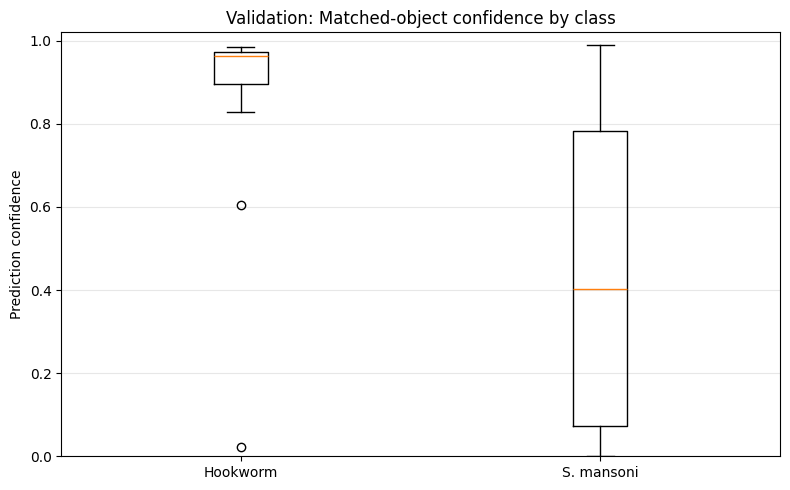

Saved files:
/content/drive/MyDrive/Helminth_GitHub_Project/results/validation_missed_detection_analysis/matched_confidence_summary.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/validation_missed_detection_analysis/matched_confidence_comparison.png


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
src = project / "results/validation_missed_detection_analysis/validation_target_class_errors.csv"
out = project / "results/validation_missed_detection_analysis"
out.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(src)

matched = df[df["status"] == "matched"].copy()
classes = ["Hookworm", "S. mansoni"]

# Confidence summary
summary = (
    matched[matched["class"].isin(classes)]
    .groupby("class")["best_confidence"]
    .agg(["count", "median", "min", "max", "mean"])
    .reset_index()
)

print("Confidence summary:")
display(summary.round(4))

summary.to_csv(out / "matched_confidence_summary.csv", index=False)

# Plot
plt.figure(figsize=(8, 5))

data = [
    matched.loc[matched["class"] == cls, "best_confidence"].dropna()
    for cls in classes
]

plt.boxplot(data, tick_labels=classes)
plt.ylabel("Prediction confidence")
plt.title("Validation: Matched-object confidence by class")
plt.ylim(0, 1.02)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(out / "matched_confidence_comparison.png", dpi=300)
plt.show()

print("Saved files:")
print(out / "matched_confidence_summary.csv")
print(out / "matched_confidence_comparison.png")


In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
src = project / "results/validation_missed_detection_analysis/validation_target_class_errors.csv"
out = project / "results/validation_missed_detection_analysis"

df = pd.read_csv(src)

sch = df[
    (df["class"] == "S. mansoni") &
    (df["status"] == "matched")
].copy()

sch = sch.sort_values("best_confidence")

print("Lowest-confidence matched S. mansoni objects:")
print(
    sch[["image", "best_confidence", "best_IoU"]]
    .head(10)
    .to_string(index=False)
)

sch.to_csv(out / "schistosoma_confidence_ranked.csv", index=False)

print("\nSaved:", out / "schistosoma_confidence_ranked.csv")


Lowest-confidence matched S. mansoni objects:
                   image  best_confidence  best_IoU
val_0048_image_02146.png         0.001508  0.637400
val_0041_image_01700.png         0.001572  0.760671
val_0043_image_06575.png         0.003954  0.744827
val_0032_image_09205.png         0.008779  0.739466
val_0005_image_00792.png         0.017037  0.788342
val_0021_image_00539.png         0.062317  0.700733
val_0058_image_02395.png         0.084123  0.771458
val_0034_image_09685.png         0.115487  0.889417
val_0004_image_00592.png         0.126755  0.710623
val_0059_image_01346.png         0.131148  0.832185

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_missed_detection_analysis/schistosoma_confidence_ranked.csv


In [ ]:

from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

targets = [
    "val_0048_image_02146.png",
    "val_0041_image_01700.png",
    "val_0043_image_06575.png",
    "val_0032_image_09205.png",
    "val_0005_image_00792.png",
]

for name in targets:
    matches = list(root.rglob(name))
    print(f"\n{name}")
    if matches:
        for p in matches:
            print("Image:", p)
            label = None
            for parent in p.parents:
                if parent.name == "images":
                    candidate = parent.parent / "labels" / (p.stem + ".txt")
                    if candidate.exists():
                        label = candidate
                        break
            print("Label:", label if label else "Not found automatically")
    else:
        print("Image not found in dataset root")



val_0048_image_02146.png
Image: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/val/val_0048_image_02146.png
Label: Not found automatically

val_0041_image_01700.png
Image: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/val/val_0041_image_01700.png
Label: Not found automatically

val_0043_image_06575.png
Image: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/val/val_0043_image_06575.png
Label: Not found automatically

val_0032_image_09205.png
Image: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/val/val_0032_image_09205.png
Label: Not found automatically

val_0005_image_00792.png
Image: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/images/val/val_0005_image_00792.png
Label: Not found automatically


In [ ]:

from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

print("Dataset root exists:", root.exists())

for folder in root.iterdir():
    if folder.is_dir():
        print("\nFolder:", folder.name)
        for subfolder in folder.iterdir():
            if subfolder.is_dir():
                print("  Subfolder:", subfolder.name)

print("\nSearching for the first target label:")
for p in root.rglob("val_0048_image_02146.txt"):
    print(p)


Dataset root exists: True

Folder: annotations
  Subfolder: train
  Subfolder: val
  Subfolder: test

Folder: images
  Subfolder: train
  Subfolder: test
  Subfolder: val

Folder: labels
  Subfolder: val
  Subfolder: test
  Subfolder: train

Searching for the first target label:
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val/val_0048_image_02146.txt


In [ ]:

from pathlib import Path
from ultralytics import YOLO
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(project / "models/best.pt"))

names = {
    0: "Ascaris",
    1: "Hookworm",
    2: "S. mansoni",
    3: "Trichuris"
}

files = [
    "val_0048_image_02146.png",
    "val_0041_image_01700.png",
    "val_0043_image_06575.png",
    "val_0032_image_09205.png",
    "val_0005_image_00792.png",
]

for filename in files:
    img_path = root / "images" / "val" / filename
    label_path = root / "labels" / "val" / (Path(filename).stem + ".txt")

    if not img_path.exists() or not label_path.exists():
        print("File missing:", filename, img_path.exists(), label_path.exists())
        continue

    image = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    w, h = image.size

    # Ground truth: green boxes
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        cls, xc, yc, bw, bh = map(float, parts)
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline="lime", width=3)
        draw.text((x1, max(0, y1 - 12)), "GT " + names.get(int(cls), str(int(cls))), fill="lime")

    # Predictions: draw on a separate copy so labels remain visible
    pred_img = image.copy()
    pred_draw = ImageDraw.Draw(pred_img)
    result = model.predict(str(img_path), imgsz=320, conf=0.001, iou=0.70, verbose=False)[0]

    for box in result.boxes:
        cls = int(box.cls.item())
        conf = float(box.conf.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        pred_draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
        pred_draw.text((x1, min(h - 12, y2)), f"{names.get(cls, cls)} {conf:.3f}", fill="red")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(image)
    axes[0].set_title("Ground truth (green)")
    axes[1].imshow(pred_img)
    axes[1].set_title("Ground truth + predictions (red)")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(filename)
    plt.tight_layout()
    plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(project / "models/best.pt"))

names = {
    0: "Ascaris",
    1: "Hookworm",
    2: "S. mansoni",
    3: "Trichuris"
}

files = [
    "val_0048_image_02146.png",
    "val_0041_image_01700.png",
    "val_0043_image_06575.png",
    "val_0032_image_09205.png",
    "val_0005_image_00792.png",
]

rows = []

for filename in files:
    img_path = root / "images" / "val" / filename
    label_path = root / "labels" / "val" / (Path(filename).stem + ".txt")

    if not img_path.exists() or not label_path.exists():
        print("Missing file:", filename)
        continue

    gt_classes = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) == 5:
            gt_classes.append(names.get(int(float(parts[0])), "Unknown"))

    result = model.predict(
        str(img_path), imgsz=320, conf=0.001, iou=0.70, verbose=False
    )[0]

    predictions = []
    for box in result.boxes:
        cls = int(box.cls.item())
        conf = float(box.conf.item())
        predictions.append({
            "class": names.get(cls, "Unknown"),
            "confidence": round(conf, 4),
            "box": [round(float(v), 1) for v in box.xyxy[0].tolist()]
        })

    print("\nIMAGE:", filename)
    print("Ground truth classes:", gt_classes)
    print("Prediction count:", len(predictions))

    for p in sorted(predictions, key=lambda x: x["confidence"], reverse=True):
        print("  Prediction:", p["class"],
              "| confidence:", p["confidence"],
              "| box:", p["box"])

    rows.append({
        "image": filename,
        "ground_truth": "; ".join(gt_classes),
        "prediction_count": len(predictions),
        "predictions": str(predictions)
    })

out = project / "results/validation_missed_detection_analysis"
out.mkdir(parents=True, exist_ok=True)
pd.DataFrame(rows).to_csv(out / "five_image_text_report.csv", index=False)

print("\nReport saved to:", out / "five_image_text_report.csv")



IMAGE: val_0048_image_02146.png
Ground truth classes: ['S. mansoni']
Prediction count: 26
  Prediction: S. mansoni | confidence: 0.0655 | box: [621.0, 202.8, 757.4, 343.5]
  Prediction: S. mansoni | confidence: 0.0599 | box: [331.3, 926.2, 492.5, 1076.9]
  Prediction: S. mansoni | confidence: 0.0193 | box: [1721.1, 160.0, 1949.7, 365.1]
  Prediction: S. mansoni | confidence: 0.0083 | box: [1831.0, 1304.7, 2025.4, 1520.0]
  Prediction: S. mansoni | confidence: 0.0066 | box: [1861.4, 1302.0, 2022.4, 1479.7]
  Prediction: S. mansoni | confidence: 0.0066 | box: [803.8, 233.7, 968.7, 407.5]
  Prediction: S. mansoni | confidence: 0.0062 | box: [454.9, 981.7, 583.6, 1121.9]
  Prediction: S. mansoni | confidence: 0.0039 | box: [463.1, 1007.4, 593.6, 1136.8]
  Prediction: S. mansoni | confidence: 0.0034 | box: [330.7, 934.7, 491.9, 1200.0]
  Prediction: S. mansoni | confidence: 0.0031 | box: [0.6, 281.1, 134.1, 556.2]
  Prediction: S. mansoni | confidence: 0.003 | box: [0.8, 0.9, 142.9, 96.6]


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import numpy as np

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
out = project / "results/validation_missed_detection_analysis"
out.mkdir(parents=True, exist_ok=True)

model = YOLO(str(project / "models/best.pt"))

names = {
    0: "Ascaris",
    1: "Hookworm",
    2: "S. mansoni",
    3: "Trichuris"
}

files = [
    "val_0048_image_02146.png",
    "val_0041_image_01700.png",
    "val_0043_image_06575.png",
    "val_0032_image_09205.png",
    "val_0005_image_00792.png",
]

def box_iou(a, b):
    # a: one xyxy box; b: array of xyxy boxes
    if len(b) == 0:
        return np.array([])
    x1 = np.maximum(a[0], b[:, 0])
    y1 = np.maximum(a[1], b[:, 1])
    x2 = np.minimum(a[2], b[:, 2])
    y2 = np.minimum(a[3], b[:, 3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = np.maximum(0, b[:, 2]-b[:, 0]) * np.maximum(0, b[:, 3]-b[:, 1])
    union = area_a + area_b - inter
    return np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)

detail_rows = []
summary_rows = []

for filename in files:
    img_path = root / "images" / "val" / filename
    label_path = root / "labels" / "val" / (Path(filename).stem + ".txt")

    if not img_path.exists() or not label_path.exists():
        print("Missing:", filename)
        continue

    from PIL import Image
    with Image.open(img_path) as im:
        width, height = im.size

    gt_boxes, gt_classes = [], []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        cls, xc, yc, bw, bh = map(float, parts)
        gt_boxes.append([
            (xc-bw/2)*width, (yc-bh/2)*height,
            (xc+bw/2)*width, (yc+bh/2)*height
        ])
        gt_classes.append(int(cls))

    result = model.predict(
        str(img_path), imgsz=320, conf=0.001, iou=0.70, verbose=False
    )[0]

    if result.boxes is not None and len(result.boxes):
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
        pred_confs = result.boxes.conf.cpu().numpy()
    else:
        pred_boxes = np.empty((0, 4))
        pred_classes = np.array([], dtype=int)
        pred_confs = np.array([])

    # Each GT gets its best same-class prediction for diagnostic purposes.
    for gi, (gb, gc) in enumerate(zip(gt_boxes, gt_classes)):
        same = np.where(pred_classes == gc)[0]
        overlaps = box_iou(np.array(gb), pred_boxes[same])
        if len(overlaps):
            j = int(np.argmax(overlaps))
            pi = int(same[j])
            best_iou = float(overlaps[j])
            best_conf = float(pred_confs[pi])
            pred_class = names.get(int(pred_classes[pi]), "Unknown")
        else:
            best_iou, best_conf, pred_class = 0.0, np.nan, "No same-class prediction"

        detail_rows.append({
            "image": filename,
            "gt_index": gi,
            "gt_class": names.get(gc, str(gc)),
            "best_same_class_confidence": best_conf,
            "best_same_class_IoU": round(best_iou, 4),
            "matched_at_IoU_0.50": best_iou >= 0.50,
            "prediction_count_in_image": len(pred_boxes)
        })

    # Greedy one-to-one matching, predictions processed by descending confidence.
    used_gt = set()
    tp = 0
    fp = 0
    for pi in np.argsort(-pred_confs):
        candidates = [
            gi for gi, gc in enumerate(gt_classes)
            if gc == pred_classes[pi] and gi not in used_gt
        ]
        if candidates:
            overlaps = box_iou(pred_boxes[pi], np.array([gt_boxes[g] for g in candidates]))
            best_j = int(np.argmax(overlaps))
            if overlaps[best_j] >= 0.50:
                used_gt.add(candidates[best_j])
                tp += 1
            else:
                fp += 1
        else:
            fp += 1

    fn = len(gt_boxes) - tp
    summary_rows.append({
        "image": filename,
        "GT_objects": len(gt_boxes),
        "predictions_at_conf_0.001": len(pred_boxes),
        "TP_same_class_IoU50": tp,
        "FP_same_class_IoU50": fp,
        "FN_same_class_IoU50": fn
    })

details = pd.DataFrame(detail_rows)
summary = pd.DataFrame(summary_rows)

details.to_csv(out / "five_image_gt_matching_details.csv", index=False)
summary.to_csv(out / "five_image_gt_matching_summary.csv", index=False)

print("PER-IMAGE SUMMARY")
print(summary.to_string(index=False))

print("\nGROUND-TRUTH MATCHING DETAILS")
print(details.to_string(index=False))

print("\nSaved reports to:", out)


PER-IMAGE SUMMARY
                   image  GT_objects  predictions_at_conf_0.001  TP_same_class_IoU50  FP_same_class_IoU50  FN_same_class_IoU50
val_0048_image_02146.png           1                         26                    1                   25                    0
val_0041_image_01700.png           1                         14                    1                   13                    0
val_0043_image_06575.png           1                          8                    1                    7                    0
val_0032_image_09205.png           1                         28                    1                   27                    0
val_0005_image_00792.png           1                         17                    1                   16                    0

GROUND-TRUTH MATCHING DETAILS
                   image  gt_index   gt_class  best_same_class_confidence  best_same_class_IoU  matched_at_IoU_0.50  prediction_count_in_image
val_0048_image_02146.png         0 S. mansoni 

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(project / "models/best.pt"))

files = [
    "val_0048_image_02146.png",
    "val_0041_image_01700.png",
    "val_0043_image_06575.png",
    "val_0032_image_09205.png",
    "val_0005_image_00792.png",
]

rows = []

for filename in files:
    img = root / "images" / "val" / filename
    label = root / "labels" / "val" / (Path(filename).stem + ".txt")

    result = model.predict(
        str(img), imgsz=320, conf=0.001, iou=0.70, verbose=False
    )[0]

    gt = []
    for line in label.read_text().splitlines():
        parts = line.split()
        if len(parts) == 5:
            cls, xc, yc, bw, bh = map(float, parts)
            gt.append((int(cls), xc, yc, bw, bh))

    boxes = result.boxes
    classes = boxes.cls.cpu().numpy().astype(int) if len(boxes) else []
    confs = boxes.conf.cpu().numpy() if len(boxes) else []

    for threshold in [0.001, 0.01, 0.05, 0.10, 0.25, 0.50]:
        keep = [i for i, c in enumerate(confs) if c >= threshold]
        rows.append({
            "image": filename,
            "confidence_threshold": threshold,
            "prediction_count": len(keep),
            "S_mansoni_prediction_count": sum(classes[i] == 2 for i in keep),
            "other_class_prediction_count": sum(classes[i] != 2 for i in keep),
            "GT_objects": len(gt)
        })

df = pd.DataFrame(rows)
out = project / "results/validation_missed_detection_analysis"
df.to_csv(out / "five_image_confidence_sweep.csv", index=False)

print(df.to_string(index=False))
print("\nSaved:", out / "five_image_confidence_sweep.csv")


                   image  confidence_threshold  prediction_count  S_mansoni_prediction_count  other_class_prediction_count  GT_objects
val_0048_image_02146.png                 0.001                26                          24                             2           1
val_0048_image_02146.png                 0.010                 3                           3                             0           1
val_0048_image_02146.png                 0.050                 2                           2                             0           1
val_0048_image_02146.png                 0.100                 0                           0                             0           1
val_0048_image_02146.png                 0.250                 0                           0                             0           1
val_0048_image_02146.png                 0.500                 0                           0                             0           1
val_0041_image_01700.png                 0.001         

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import numpy as np
import pandas as pd
from PIL import Image

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
out = project / "results/validation_missed_detection_analysis"
out.mkdir(parents=True, exist_ok=True)

model = YOLO(str(project / "models/best.pt"))
class_names = {0: "Ascaris", 1: "Hookworm", 2: "S. mansoni", 3: "Trichuris"}

def iou_one_to_many(box, boxes):
    if len(boxes) == 0:
        return np.array([])
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    area1 = max(0, box[2]-box[0]) * max(0, box[3]-box[1])
    area2 = np.maximum(0, boxes[:, 2]-boxes[:, 0]) * np.maximum(0, boxes[:, 3]-boxes[:, 1])
    union = area1 + area2 - inter
    return np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)

image_dir = root / "images" / "val"
label_dir = root / "labels" / "val"
thresholds = [0.01, 0.05, 0.10, 0.25, 0.50]

# Cache predictions once at a low confidence, then evaluate thresholds.
records = []
all_gt_counts = {c: 0 for c in class_names}

for img_path in sorted(image_dir.iterdir()):
    if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png", ".bmp"]:
        continue
    label_path = label_dir / (img_path.stem + ".txt")
    if not label_path.exists():
        continue

    with Image.open(img_path) as im:
        W, H = im.size

    gt_boxes, gt_classes = [], []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        c, xc, yc, bw, bh = map(float, parts)
        c = int(c)
        gt_boxes.append([(xc-bw/2)*W, (yc-bh/2)*H,
                         (xc+bw/2)*W, (yc+bh/2)*H])
        gt_classes.append(c)
        all_gt_counts[c] += 1

    result = model.predict(
        str(img_path), imgsz=320, conf=0.001, iou=0.70, verbose=False
    )[0]

    if result.boxes is not None and len(result.boxes):
        pboxes = result.boxes.xyxy.cpu().numpy()
        pclasses = result.boxes.cls.cpu().numpy().astype(int)
        pconf = result.boxes.conf.cpu().numpy()
    else:
        pboxes = np.empty((0, 4))
        pclasses = np.array([], dtype=int)
        pconf = np.array([])

    for threshold in thresholds:
        keep = np.where(pconf >= threshold)[0]
        used_gt = set()
        tp_class = {c: 0 for c in class_names}
        fp_class = {c: 0 for c in class_names}

        # Confidence-ordered greedy one-to-one matching.
        for pi in keep[np.argsort(-pconf[keep])]:
            c = int(pclasses[pi])
            candidates = [gi for gi, gc in enumerate(gt_classes)
                          if gc == c and gi not in used_gt]
            if candidates:
                overlaps = iou_one_to_many(
                    pboxes[pi], np.array([gt_boxes[gi] for gi in candidates])
                )
                best = int(np.argmax(overlaps))
                if overlaps[best] >= 0.50:
                    used_gt.add(candidates[best])
                    tp_class[c] += 1
                else:
                    fp_class[c] += 1
            else:
                fp_class[c] += 1

        for c in class_names:
            fn = sum(gc == c for gc in gt_classes) - tp_class[c]
            records.append({
                "threshold": threshold,
                "class_id": c,
                "class": class_names[c],
                "TP": tp_class[c],
                "FP": fp_class[c],
                "FN": fn
            })

df = pd.DataFrame(records)
summary = df.groupby(["threshold", "class"], as_index=False)[["TP", "FP", "FN"]].sum()
summary["precision"] = summary["TP"] / (summary["TP"] + summary["FP"]).replace(0, np.nan)
summary["recall"] = summary["TP"] / (summary["TP"] + summary["FN"]).replace(0, np.nan)
summary["F1"] = 2 * summary["precision"] * summary["recall"] / (
    summary["precision"] + summary["recall"]
).replace(0, np.nan)

summary.to_csv(out / "full_validation_threshold_metrics.csv", index=False)

print("FULL VALIDATION CLASS-WISE METRICS")
print(summary.round(4).to_string(index=False))

print("\nOVERALL VALIDATION METRICS")
overall = df.groupby("threshold")[["TP", "FP", "FN"]].sum().reset_index()
overall["precision"] = overall["TP"] / (overall["TP"] + overall["FP"]).replace(0, np.nan)
overall["recall"] = overall["TP"] / (overall["TP"] + overall["FN"]).replace(0, np.nan)
overall["F1"] = 2 * overall["precision"] * overall["recall"] / (
    overall["precision"] + overall["recall"]
).replace(0, np.nan)
print(overall.round(4).to_string(index=False))

overall.to_csv(out / "full_validation_overall_threshold_metrics.csv", index=False)
print("\nSaved in:", out)


FULL VALIDATION CLASS-WISE METRICS
 threshold      class  TP  FP  FN  precision  recall     F1
      0.01    Ascaris  44 103   0     0.2993  1.0000 0.4607
      0.01   Hookworm  16  75   0     0.1758  1.0000 0.2991
      0.01 S. mansoni  20  50   5     0.2857  0.8000 0.4211
      0.01  Trichuris  27  41   2     0.3971  0.9310 0.5567
      0.05    Ascaris  43  37   1     0.5375  0.9773 0.6935
      0.05   Hookworm  15  29   1     0.3409  0.9375 0.5000
      0.05 S. mansoni  16  23   9     0.4103  0.6400 0.5000
      0.05  Trichuris  26  12   3     0.6842  0.8966 0.7761
      0.10    Ascaris  41  24   3     0.6308  0.9318 0.7523
      0.10   Hookworm  15  16   1     0.4839  0.9375 0.6383
      0.10 S. mansoni  14   8  11     0.6364  0.5600 0.5957
      0.10  Trichuris  26   6   3     0.8125  0.8966 0.8525
      0.25    Ascaris  40   9   4     0.8163  0.9091 0.8602
      0.25   Hookworm  15  10   1     0.6000  0.9375 0.7317
      0.25 S. mansoni  12   4  13     0.7500  0.4800 0.5854
     

In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    project / "results/validation_threshold_diagnostics/overall_validation_threshold_summary.csv",
    project / "results/validation_missed_detection_analysis/full_validation_overall_threshold_metrics.csv",
]

for path in files:
    print("\nFILE:", path)
    if not path.exists():
        print("Not found")
        continue

    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))
    print(df.to_string(index=False))



FILE: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_threshold_diagnostics/overall_validation_threshold_summary.csv
Columns: ['threshold', 'GT', 'TP', 'FP', 'FN', 'precision', 'recall', 'F1']
Rows: 4
 threshold  GT  TP  FP  FN  precision   recall       F1
      0.05 114 104 104  10   0.500000 0.912281 0.645963
      0.10 114 100  51  14   0.662252 0.877193 0.754717
      0.25 114  91  25  23   0.784483 0.798246 0.791304
      0.50 114  82  12  32   0.872340 0.719298 0.788462

FILE: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_missed_detection_analysis/full_validation_overall_threshold_metrics.csv
Columns: ['threshold', 'TP', 'FP', 'FN', 'precision', 'recall', 'F1']
Rows: 5
 threshold  TP  FP  FN  precision   recall       F1
      0.01 107 269   7   0.284574 0.938596 0.436735
      0.05 100 101  14   0.497512 0.877193 0.634921
      0.10  96  54  18   0.640000 0.842105 0.727273
      0.25  90  25  24   0.782609 0.789474 0.786026
      0.50  82  1

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

keywords = [
    "validation_threshold",
    "missed_detection",
    "threshold_metrics",
    "greedy",
    "IoU",
]

for path in root.rglob("*.py"):
    if any(k.lower() in path.name.lower() for k in keywords):
        print(path)


In [ ]:

from pathlib import Path
import json

root = Path("/content/drive/MyDrive")

for path in root.rglob("New Project.ipynb"):
    print("\nNOTEBOOK FOUND:", path)

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        keywords = [
            "validation_threshold",
            "missed_detection",
            "greedy",
            "iou_threshold",
            "full_validation",
        ]

        if any(k.lower() in source.lower() for k in keywords):
            print(f"\n--- CELL {i} ---")
            print(source[:2500])



NOTEBOOK FOUND: /content/drive/MyDrive/Colab Notebooks/New Project.ipynb

--- CELL 112 ---

from pathlib import Path
import csv
import json
import numpy as np
from ultralytics import YOLO

# Input files
model_path = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)
image_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/test"
)
label_dir = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/test"
)

# Separate output folder: existing results remain untouched
out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/error_analysis"
)
out_dir.mkdir(parents=True, exist_ok=True)

class_names = {
    0: "ASC.",
    1: "HKW.",
    2: "SCH.",
    3: "TRI."
}

model = YOLO(model_path)
image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
)

def read_labels(path):
    b

In [ ]:

from pathlib import Path
from collections import defaultdict
from PIL import Image
from ultralytics import YOLO
import numpy as np
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
out = project / "results/validation_consistency_check"
out.mkdir(parents=True, exist_ok=True)

model = YOLO(str(project / "models/best.pt"))
image_dir = root / "images/val"
label_dir = root / "labels/val"
thresholds = [0.01, 0.05, 0.10, 0.25, 0.50]
class_names = ["Ascaris", "Hookworm", "S. mansoni", "Trichuris"]

def iou_one(box, boxes):
    if len(boxes) == 0:
        return np.array([])
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    a1 = max(0, box[2]-box[0]) * max(0, box[3]-box[1])
    a2 = np.maximum(0, boxes[:, 2]-boxes[:, 0]) * np.maximum(0, boxes[:, 3]-boxes[:, 1])
    union = a1 + a2 - inter
    return np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

# Infer once at low confidence, with identical settings for every image.
predictions_by_image = {}
ground_truth_by_image = {}

for result in model.predict(
    source=[str(p) for p in images],
    imgsz=320, conf=0.001, iou=0.70,
    max_det=300, stream=True, verbose=False
):
    name = Path(result.path).name
    if result.boxes is not None and len(result.boxes):
        predictions_by_image[name] = [
            (int(c), float(s), b.astype(float))
            for c, s, b in zip(
                result.boxes.cls.cpu().numpy(),
                result.boxes.conf.cpu().numpy(),
                result.boxes.xyxy.cpu().numpy()
            )
        ]
    else:
        predictions_by_image[name] = []

for path in images:
    name = path.name
    label_path = label_dir / (path.stem + ".txt")

    with Image.open(path) as im:
        W, H = im.size

    gt = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            c, xc, yc, bw, bh = map(float, parts)
            gt.append((
                int(c),
                np.array([
                    (xc-bw/2)*W, (yc-bh/2)*H,
                    (xc+bw/2)*W, (yc+bh/2)*H
                ])
            ))
    ground_truth_by_image[name] = gt

rows = []
for threshold in thresholds:
    stats = {
        c: {"GT": 0, "TP": 0, "FP": 0, "FN": 0}
        for c in range(4)
    }

    for name in predictions_by_image:
        gt = ground_truth_by_image[name]
        preds = [
            p for p in predictions_by_image[name]
            if p[1] >= threshold
        ]

        for c, _ in gt:
            stats[c]["GT"] += 1

        # Match highest-confidence predictions first.
        preds.sort(key=lambda p: p[1], reverse=True)
        matched_gt = set()

        for pc, score, pbox in preds:
            candidates = [
                (iou_one(pbox, np.array([gbox]))[0], j)
                for j, (gc, gbox) in enumerate(gt)
                if gc == pc and j not in matched_gt
            ]

            best_iou, best_j = max(candidates, default=(0.0, -1))

            if best_j >= 0 and best_iou >= 0.50:
                stats[pc]["TP"] += 1
                matched_gt.add(best_j)
            else:
                stats[pc]["FP"] += 1

        for j, (gc, _) in enumerate(gt):
            if j not in matched_gt:
                stats[gc]["FN"] += 1

    for c, name in enumerate(class_names):
        s = stats[c]
        p = s["TP"] / (s["TP"] + s["FP"]) if s["TP"] + s["FP"] else 0
        r = s["TP"] / (s["TP"] + s["FN"]) if s["TP"] + s["FN"] else 0
        f1 = 2*p*r/(p+r) if p+r else 0
        rows.append({
            "threshold": threshold, "class": name,
            **s, "precision": p, "recall": r, "F1": f1
        })

df = pd.DataFrame(rows)
df.to_csv(out / "classwise_metrics.csv", index=False)

overall = df.groupby("threshold")[["GT", "TP", "FP", "FN"]].sum().reset_index()
overall["precision"] = overall.TP / (overall.TP + overall.FP)
overall["recall"] = overall.TP / (overall.TP + overall.FN)
overall["F1"] = (
    2 * overall.precision * overall.recall
    / (overall.precision + overall.recall)
)
overall.to_csv(out / "overall_metrics.csv", index=False)

print("Validation images:", len(images))
print("GT objects:", sum(len(v) for v in ground_truth_by_image.values()))
print("\nOVERALL METRICS")
print(overall.round(4).to_string(index=False))
print("\nCLASS-WISE METRICS")
print(df.round(4).to_string(index=False))
print("\nSaved to:", out)


Validation images: 60
GT objects: 114

OVERALL METRICS
 threshold  GT  TP  FP  FN  precision  recall     F1
      0.01 114 107 305   7     0.2597  0.9386 0.4068
      0.05 114 104 104  10     0.5000  0.9123 0.6460
      0.10 114 100  51  14     0.6623  0.8772 0.7547
      0.25 114  91  25  23     0.7845  0.7982 0.7913
      0.50 114  82  12  32     0.8723  0.7193 0.7885

CLASS-WISE METRICS
 threshold      class  GT  TP  FP  FN  precision  recall     F1
      0.01    Ascaris  44  44 113   0     0.2803  1.0000 0.4378
      0.01   Hookworm  16  16  83   0     0.1616  1.0000 0.2783
      0.01 S. mansoni  25  20  63   5     0.2410  0.8000 0.3704
      0.01  Trichuris  29  27  46   2     0.3699  0.9310 0.5294
      0.05    Ascaris  44  44  35   0     0.5570  1.0000 0.7154
      0.05   Hookworm  16  15  32   1     0.3191  0.9375 0.4762
      0.05 S. mansoni  25  19  24   6     0.4419  0.7600 0.5588
      0.05  Trichuris  29  26  13   3     0.6667  0.8966 0.7647
      0.10    Ascaris  44  42  

In [ ]:

from pathlib import Path
import pandas as pd
import cv2
import numpy as np
from ultralytics import YOLO

# Project paths
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
MODEL_PATH = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
)
OUT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "schistosoma_image_level_analysis"
)
OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "Ascaris lumbricoides",
    1: "Hookworm",
    2: "Schistosoma mansoni",
    3: "Trichuris trichiura",
}
TARGET_CLASS = 2
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

model = YOLO(MODEL_PATH)
image_dir = DATASET / "images" / "val"
label_dir = DATASET / "labels" / "val"
image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

# Predict at a low confidence threshold so we can inspect
# predictions that might be excluded by the 0.25 operating point.
results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.001,
    iou=0.70,
    max_det=300,
    verbose=False,
)

def box_iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

rows = []

for img_path, result in zip(image_paths, results):
    image = cv2.imread(str(img_path))
    if image is None:
        print("Could not read image:", img_path.name)
        continue

    height, width = image.shape[:2]
    label_path = label_dir / f"{img_path.stem}.txt"

    if not label_path.exists():
        print("Missing label:", label_path.name)
        continue

    # Ground-truth boxes: YOLO normalized x_center, y_center, w, h
    gt_objects = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls = int(float(parts[0]))
        xc, yc, bw, bh = map(float, parts[1:5])
        box = [
            (xc - bw/2) * width,
            (yc - bh/2) * height,
            (xc + bw/2) * width,
            (yc + bh/2) * height,
        ]
        gt_objects.append((cls, box))

    if result.boxes is None or len(result.boxes) == 0:
        pred_boxes = np.empty((0, 4))
        pred_classes = np.empty((0,), dtype=int)
        pred_confs = np.empty((0,))
    else:
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
        pred_confs = result.boxes.conf.cpu().numpy()

    # Examine each S. mansoni ground-truth object
    for gt_index, (gt_cls, gt_box) in enumerate(gt_objects):
        if gt_cls != TARGET_CLASS:
            continue

        overlaps = np.array([
            box_iou_xyxy(gt_box, pb) for pb in pred_boxes
        ])

        eligible = np.where(pred_confs >= CONF_THRESHOLD)[0]
        same = [i for i in eligible if pred_classes[i] == TARGET_CLASS]
        other = [i for i in eligible if pred_classes[i] != TARGET_CLASS]

        best_same = max(same, key=lambda i: overlaps[i]) if same else None
        best_other = max(other, key=lambda i: overlaps[i]) if other else None
        best_any = (
            int(np.argmax(overlaps)) if len(overlaps) else None
        )

        same_iou = overlaps[best_same] if best_same is not None else 0.0
        other_iou = overlaps[best_other] if best_other is not None else 0.0
        any_iou = overlaps[best_any] if best_any is not None else 0.0

        if same_iou >= IOU_THRESHOLD:
            status = "Detected correctly"
        elif other_iou >= IOU_THRESHOLD:
            status = "Likely wrong-class prediction"
        elif best_same is not None and same_iou > 0:
            status = "Same-class box, poor localization"
        elif best_any is not None and any_iou >= IOU_THRESHOLD:
            status = "Overlapping prediction; inspect matching"
        else:
            status = "Missed at confidence 0.25"

        rows.append({
            "image": img_path.name,
            "gt_object_index": gt_index,
            "gt_class": CLASS_NAMES[gt_cls],
            "status": status,
            "best_same_class_iou": round(float(same_iou), 4),
            "best_same_class_conf": (
                round(float(pred_confs[best_same]), 4)
                if best_same is not None else np.nan
            ),
            "best_other_class": (
                CLASS_NAMES[int(pred_classes[best_other])]
                if best_other is not None else "None"
            ),
            "best_other_class_iou": round(float(other_iou), 4),
            "best_other_class_conf": (
                round(float(pred_confs[best_other]), 4)
                if best_other is not None else np.nan
            ),
            "best_any_class": (
                CLASS_NAMES[int(pred_classes[best_any])]
                if best_any is not None else "None"
            ),
            "best_any_class_iou": round(float(any_iou), 4),
        })

df = pd.DataFrame(rows)
csv_path = OUT / "schistosoma_ground_truth_analysis.csv"
df.to_csv(csv_path, index=False)

print("Validation images examined:", len(image_paths))
print("S. mansoni ground-truth objects examined:", len(df))
print("\nStatus summary:")
print(df["status"].value_counts(dropna=False))
print("\nSaved to:", csv_path)
display(df.head(15))


Validation images examined: 60
S. mansoni ground-truth objects examined: 25

Status summary:
status
Detected correctly                          12
Overlapping prediction; inspect matching    11
Missed at confidence 0.25                    2
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/schistosoma_ground_truth_analysis.csv


,image,gt_object_index,gt_class,status,best_same_class_iou,best_same_class_conf,best_other_class,best_other_class_iou,best_other_class_conf,best_any_class,best_any_class_iou
0,val_0004_image_00592.png,0,Schistosoma mansoni,Overlapping prediction; inspect matching,0.0000,NaN,None,0.0,NaN,Schistosoma mansoni,0.7106
1,val_0005_image_00792.png,0,Schistosoma mansoni,Overlapping prediction; inspect matching,0.0000,0.4158,None,0.0,NaN,Schistosoma mansoni,0.7883
2,val_0006_image_01090.png,0,Schistosoma mansoni,Detected correctly,0.7648,0.6649,None,0.0,NaN,Schistosoma mansoni,0.7648
3,val_0008_image_08030.png,0,Schistosoma mansoni,Detected correctly,0.8428,0.8619,None,0.0,NaN,Schistosoma mansoni,0.8428
4,val_0009_image_01442.png,0,Schistosoma mansoni,Missed at confidence 0.25,0.0000,NaN,None,0.0,NaN,Schistosoma mansoni,0.2624
5,val_0012_image_05892.png,0,Schistosoma mansoni,Detected correctly,0.8765,0.7630,None,0.0,NaN,Schistosoma mansoni,0.8765
6,val_0014_image_01682.png,0,Schistosoma mansoni,Detected correctly,0.8645,0.4866,None,0.0,NaN,Schistosoma mansoni,0.8645
7,val_0021_image_00539.png,0,Schistosoma mansoni,Overlapping prediction; inspect matching,0.0000,0.3132,None,0.0,NaN,Schistosoma mansoni,0.7007
8,val_0021_image_00539.png,1,Schistosoma mansoni,Overlapping prediction; inspect matching,0.0000,0.3132,None,0.0,NaN,Schistosoma mansoni,0.8374
9,val_0027_image_01706.png,0,Schistosoma mansoni,Missed at confidence 0.25,0.0000,NaN,None,0.0,NaN,Schistosoma mansoni,0.0000


In [ ]:

import pandas as pd
import numpy as np
import cv2
from pathlib import Path
from ultralytics import YOLO

DATASET = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
MODEL_PATH = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
OUT = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis")
OUT.mkdir(parents=True, exist_ok=True)

TARGET_CLASS = 2
CONF = 0.25
IOU_T = 0.50

model = YOLO(MODEL_PATH)
image_paths = sorted(
    p for p in (DATASET / "images/val").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)
results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320, conf=0.001, iou=0.70, max_det=300, verbose=False
)

names = {0:"Ascaris lumbricoides", 1:"Hookworm",
         2:"Schistosoma mansoni", 3:"Trichuris trichiura"}

def iou_xyxy(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (aa + ab - inter) if aa + ab > inter else 0.0

rows = []
label_dir = DATASET / "labels/val"

for path, res in zip(image_paths, results):
    im = cv2.imread(str(path))
    if im is None:
        continue
    h, w = im.shape[:2]
    lp = label_dir / f"{path.stem}.txt"
    if not lp.exists():
        continue

    gt = []
    for line in lp.read_text().splitlines():
        z = line.split()
        if len(z) < 5:
            continue
        c = int(float(z[0]))
        xc, yc, bw, bh = map(float, z[1:5])
        box = [(xc-bw/2)*w, (yc-bh/2)*h,
               (xc+bw/2)*w, (yc+bh/2)*h]
        if c == TARGET_CLASS:
            gt.append(box)

    if not gt:
        continue

    if res.boxes is None or len(res.boxes) == 0:
        pb, pc, ps = np.empty((0,4)), np.array([],int), np.array([])
    else:
        pb = res.boxes.xyxy.cpu().numpy()
        pc = res.boxes.cls.cpu().numpy().astype(int)
        ps = res.boxes.conf.cpu().numpy()

    eligible = [i for i in range(len(ps)) if ps[i] >= CONF]
    eligible.sort(key=lambda i: ps[i], reverse=True)
    used_gt, used_pred = set(), set()

    # Confidence-ordered, one-to-one matching for correct-class predictions
    for pi in eligible:
        if pc[pi] != TARGET_CLASS:
            continue
        candidates = [
            (iou_xyxy(pb[pi], gt[gi]), gi)
            for gi in range(len(gt)) if gi not in used_gt
        ]
        if candidates:
            best_iou, gi = max(candidates)
            if best_iou >= IOU_T:
                used_gt.add(gi)
                used_pred.add(pi)

    for gi, gbox in enumerate(gt):
        if gi in used_gt:
            # Find a same-class matched prediction for reporting
            options = [
                (iou_xyxy(gbox, pb[pi]), pi) for pi in used_pred
                if pc[pi] == TARGET_CLASS
            ]
            # Restrict to predictions that overlap this object
            options = [(v, pi) for v, pi in options if v >= IOU_T]
            best_iou, pi = max(options) if options else (np.nan, None)
            rows.append({
                "image": path.name, "gt_index": gi,
                "status": "Detected correctly",
                "matched_iou": round(float(best_iou), 4) if pi is not None else np.nan,
                "prediction_confidence": round(float(ps[pi]), 4) if pi is not None else np.nan,
                "overlapping_other_class": "No"
            })
            continue

        overlaps = [(iou_xyxy(gbox, pb[i]), i) for i in eligible]
        overlaps.sort(reverse=True)
        strong = [(v, i) for v, i in overlaps if v >= IOU_T]

        if strong:
            # If a wrong-class prediction overlaps this GT, flag it for review.
            wrong = [(v, i) for v, i in strong if pc[i] != TARGET_CLASS]
            right = [(v, i) for v, i in strong if pc[i] == TARGET_CLASS]
            if wrong:
                v, pi = wrong[0]
                status = "Possible wrong-class prediction"
            elif right:
                v, pi = right[0]
                status = "Matching conflict / duplicate candidate"
            else:
                v, pi = strong[0]
                status = "Needs manual review"
        else:
            # Check whether a same-class prediction exists below the chosen threshold.
            low = [
                (iou_xyxy(gbox, pb[i]), i) for i in range(len(ps))
                if ps[i] < CONF and pc[i] == TARGET_CLASS
            ]
            low = [(v, i) for v, i in low if v >= IOU_T]
            if low:
                v, pi = max(low)
                status = "Low-confidence same-class candidate"
            else:
                v, pi = (max(overlaps) if overlaps else (0.0, None))
                status = "Missed / localization failure"

        rows.append({
            "image": path.name,
            "gt_index": gi,
            "status": status,
            "matched_iou": round(float(v), 4),
            "prediction_confidence": round(float(ps[pi]), 4) if pi is not None else np.nan,
            "overlapping_other_class": names[int(pc[pi])] if pi is not None and pc[pi] != TARGET_CLASS else "No"
        })

df = pd.DataFrame(rows)
out_file = OUT / "schistosoma_one_to_one_review.csv"
df.to_csv(out_file, index=False)

print("S. mansoni ground-truth objects:", len(df))
print("\nOne-to-one status summary:")
print(df["status"].value_counts())
print("\nSaved:", out_file)
display(df.sort_values(["status", "image"]))


S. mansoni ground-truth objects: 25

One-to-one status summary:
status
Detected correctly                     12
Low-confidence same-class candidate    11
Missed / localization failure           2
Name: count, dtype: int64

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/schistosoma_one_to_one_review.csv


,image,gt_index,status,matched_iou,prediction_confidence,overlapping_other_class
2,val_0006_image_01090.png,0,Detected correctly,0.7648,0.6649,No
3,val_0008_image_08030.png,0,Detected correctly,0.8428,0.8619,No
5,val_0012_image_05892.png,0,Detected correctly,0.8765,0.7630,No
6,val_0014_image_01682.png,0,Detected correctly,0.8645,0.4866,No
10,val_0030_image_06710.png,0,Detected correctly,0.9183,0.9023,No
12,val_0034_image_09685.png,0,Detected correctly,0.7783,0.4034,No
14,val_0038_image_03537.png,0,Detected correctly,0.9007,0.9452,No
17,val_0044_image_00863.png,0,Detected correctly,0.8008,0.8035,No
18,val_0046_image_02057.png,0,Detected correctly,0.7455,0.8642,No
20,val_0049_image_01301.png,0,Detected correctly,0.8867,0.6560,No


In [ ]:

import os

drive_path = "/content/drive/MyDrive/Helminth_GitHub_Project"

if os.path.isdir(drive_path):
    print("Drive mounted hai aur project folder mil gaya.")
    print("Project folder ke kuch items:")
    print(os.listdir(drive_path)[:10])
else:
    print("Drive ya project folder abhi accessible nahi hai.")
    print("Agar zaroorat hui, toh Drive dobara mount karenge.")


Drive mounted hai aur project folder mil gaya.
Project folder ke kuch items:
['results', 'figures', 'models', '.gitignore', 'predict.py', 'runs', 'dataset.yaml', 'README_backup_20261018_181523.md', 'requirements_backup_20261018_181523.txt', 'requirements.txt']


In [ ]:

from pathlib import Path
import pandas as pd
from IPython.display import display, Image

base = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
results_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "schistosoma_image_level_analysis"
)

csv_path = results_dir / "schistosoma_one_to_one_review.csv"
df = pd.read_csv(csv_path)

# Select low-confidence S. mansoni examples
low_conf = df[df["status"] == "Low-confidence same-class candidate"].copy()

print("Low-confidence cases:", len(low_conf))
display(low_conf[["image", "gt_index", "matched_iou", "prediction_confidence"]])

# Display the first three original validation images
for filename in low_conf["image"].drop_duplicates().head(3):
    image_path = base / "images" / "val" / filename
    print("Image:", filename)
    if image_path.exists():
        display(Image(filename=str(image_path), width=500))
    else:
        print("Image not found:", image_path)


In [ ]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

base = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
out_dir = project / "results/schistosoma_image_level_analysis/overlays"
out_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    project / "results/schistosoma_image_level_analysis/"
    "schistosoma_one_to_one_review.csv"
)
low_conf = df[df["status"] == "Low-confidence same-class candidate"]
model = YOLO(str(project / "models/best.pt"))

names = {0:"Ascaris", 1:"Hookworm", 2:"S. mansoni", 3:"Trichuris"}
selected = low_conf["image"].drop_duplicates().head(3).tolist()

for filename in selected:
    image_path = base / "images/val" / filename
    label_path = base / "labels/val" / f"{Path(filename).stem}.txt"

    image = cv2.imread(str(image_path))
    if image is None:
        print("Image not found:", image_path)
        continue

    h, w = image.shape[:2]

    # Ground-truth boxes: green
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            cls = int(float(parts[0]))
            xc, yc, bw, bh = map(float, parts[1:5])
            x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
            x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
            cv2.rectangle(image, (x1,y1), (x2,y2), (0,200,0), 2)
            cv2.putText(image, f"GT: {names.get(cls, cls)}",
                        (x1, max(15,y1-5)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.45, (0,200,0), 1)

    # Predictions, including low-confidence boxes
    pred = model.predict(
        source=str(image_path), imgsz=320, conf=0.001,
        iou=0.70, max_det=300, verbose=False
    )[0]

    if pred.boxes is not None:
        for box in pred.boxes:
            conf = float(box.conf.cpu().item())
            cls = int(box.cls.cpu().item())
            x1,y1,x2,y2 = map(int, box.xyxy.cpu().numpy()[0])
            cv2.rectangle(image, (x1,y1), (x2,y2), (0,0,255), 2)
            cv2.putText(image, f"Pred: {names.get(cls, cls)} {conf:.3f}",
                        (x1, min(h-5,y2+15)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.45, (0,0,255), 1)

    save_path = out_dir / filename
    cv2.imwrite(str(save_path), image)

    plt.figure(figsize=(10,7))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"{filename}\nGreen = GT | Red = prediction")
    plt.axis("off")
    plt.show()
    print("Saved:", save_path)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

from pathlib import Path
from IPython.display import display, Image

folder = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "schistosoma_image_level_analysis/overlays"
)

for name in [
    "val_0004_image_00592.png",
    "val_0005_image_00792.png",
    "val_0021_image_00539.png",
]:
    path = folder / name
    print(name)
    display(Image(filename=str(path), width=700))


In [ ]:

from pathlib import Path
import pandas as pd
import cv2
from ultralytics import YOLO

base = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

model = YOLO(str(project / "models/best.pt"))

files = [
    "val_0004_image_00592.png",
    "val_0005_image_00792.png",
    "val_0021_image_00539.png",
]

rows = []

for filename in files:
    image_path = base / "images/val" / filename
    label_path = base / "labels/val" / f"{Path(filename).stem}.txt"

    image = cv2.imread(str(image_path))
    if image is None:
        print("Image not found:", filename)
        continue

    h, w = image.shape[:2]
    gt = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) >= 5:
                cls = int(float(parts[0]))
                xc, yc, bw, bh = map(float, parts[1:5])
                box = [
                    (xc-bw/2)*w, (yc-bh/2)*h,
                    (xc+bw/2)*w, (yc+bh/2)*h
                ]
                if cls == 2:
                    gt.append(box)

    result = model.predict(
        source=str(image_path),
        imgsz=320,
        conf=0.001,
        iou=0.70,
        max_det=300,
        verbose=False
    )[0]

    pred = []
    if result.boxes is not None:
        for b in result.boxes:
            if int(b.cls.cpu().item()) == 2:
                pred.append({
                    "box": b.xyxy.cpu().numpy()[0],
                    "conf": float(b.conf.cpu().item())
                })

    # For each ground-truth object, report its best same-class IoU
    for j, g in enumerate(gt):
        best_iou, best_conf = 0.0, None
        for p in pred:
            a = p["box"]
            x1, y1 = max(g[0],a[0]), max(g[1],a[1])
            x2, y2 = min(g[2],a[2]), min(g[3],a[3])
            inter = max(0,x2-x1)*max(0,y2-y1)
            ag = max(0,g[2]-g[0])*max(0,g[3]-g[1])
            ap = max(0,a[2]-a[0])*max(0,a[3]-a[1])
            union = ag+ap-inter
            iou = inter/union if union > 0 else 0
            if iou > best_iou:
                best_iou, best_conf = iou, p["conf"]

        rows.append({
            "image": filename,
            "gt_object": j,
            "best_same_class_iou": round(best_iou, 4),
            "best_prediction_confidence": (
                round(best_conf, 4) if best_conf is not None else None
            ),
            "iou_at_least_0.50": best_iou >= 0.50,
            "confidence_at_least_0.25": (
                best_conf is not None and best_conf >= 0.25
            )
        })

report = pd.DataFrame(rows)
out = project / "results/schistosoma_image_level_analysis/three_image_numeric_review.csv"
out.parent.mkdir(parents=True, exist_ok=True)
report.to_csv(out, index=False)

print(report.to_string(index=False))
print("\nReport saved:", out)


                   image  gt_object  best_same_class_iou  best_prediction_confidence  iou_at_least_0.50  confidence_at_least_0.25
val_0004_image_00592.png          0               0.6981                      0.1055               True                     False
val_0005_image_00792.png          0               0.7752                      0.0103               True                     False
val_0021_image_00539.png          0               0.6947                      0.0474               True                     False
val_0021_image_00539.png          1               0.8383                      0.0884               True                     False

Report saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/three_image_numeric_review.csv


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis")

df = pd.read_csv(project / "schistosoma_one_to_one_review.csv")

# Only rows with a numerical candidate confidence
valid = df.dropna(subset=["prediction_confidence"]).copy()

print("Objects with candidate predictions:", len(valid))
print("\nConfidence summary:")
print(valid["prediction_confidence"].describe().round(4))

print("\nConfidence bands:")
bins = [-0.001, 0.01, 0.05, 0.10, 0.25, 1.0]
labels = ["<0.01", "0.01–0.05", "0.05–0.10", "0.10–0.25", ">=0.25"]
valid["confidence_band"] = pd.cut(
    valid["prediction_confidence"],
    bins=bins,
    labels=labels,
    include_lowest=True
)
print(valid["confidence_band"].value_counts(sort=False))

print("\nIoU and confidence by status:")
print(
    valid.groupby("status", observed=True)[
        ["matched_iou", "prediction_confidence"]
    ].agg(["count", "mean", "median"]).round(4)
)

out = project / "all_schistosoma_confidence_summary.csv"
valid.to_csv(out, index=False)
print("\nSaved:", out)


Objects with candidate predictions: 23

Confidence summary:
count    23.0000
mean      0.4111
std       0.3719
min       0.0015
25%       0.0732
50%       0.4034
75%       0.7832
max       0.9900
Name: prediction_confidence, dtype: float64

Confidence bands:
confidence_band
<0.01         4
0.01–0.05     1
0.05–0.10     2
0.10–0.25     4
>=0.25       12
Name: count, dtype: int64

IoU and confidence by status:
                                    matched_iou                  \
                                          count    mean  median   
status                                                            
Detected correctly                           12  0.8514  0.8705   
Low-confidence same-class candidate          11  0.7648  0.7607   

                                    prediction_confidence                  
                                                    count    mean  median  
status                                                                     
Detected correctly      

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import cv2

dataset = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
project = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis")

review = pd.read_csv(project / "schistosoma_one_to_one_review.csv")
rows = []

for _, r in review.iterrows():
    path = dataset / "images/val" / r["image"]
    label_path = dataset / "labels/val" / f"{path.stem}.txt"

    img = cv2.imread(str(path))
    if img is None or not label_path.exists():
        continue

    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Find the specified S. mansoni ground-truth box
    boxes = []
    for line in label_path.read_text().splitlines():
        z = line.split()
        if len(z) < 5 or int(float(z[0])) != 2:
            continue
        xc, yc, bw, bh = map(float, z[1:5])
        boxes.append([
            (xc-bw/2)*w, (yc-bh/2)*h,
            (xc+bw/2)*w, (yc+bh/2)*h
        ])

    idx = int(r["gt_index"])
    if idx >= len(boxes):
        continue

    x1, y1, x2, y2 = boxes[idx]
    x1, y1 = max(0, int(x1)), max(0, int(y1))
    x2, y2 = min(w, int(x2)), min(h, int(y2))
    crop = gray[y1:y2, x1:x2]

    rows.append({
        "image": r["image"],
        "status": r["status"],
        "confidence": r["prediction_confidence"],
        "matched_iou": r["matched_iou"],
        "image_width": w,
        "image_height": h,
        "gt_box_width_px": max(0, x2-x1),
        "gt_box_height_px": max(0, y2-y1),
        "gt_box_area_fraction": max(0, x2-x1)*max(0, y2-y1)/(w*h),
        "crop_laplacian_variance": (
            round(float(cv2.Laplacian(crop, cv2.CV_64F).var()), 3)
            if crop.size else np.nan
        )
    })

features = pd.DataFrame(rows)
features.to_csv(project / "image_quality_size_features.csv", index=False)

print("Objects analysed:", len(features))
print("\nGroup summary:")
print(features.groupby("status", dropna=False)[
    ["gt_box_width_px", "gt_box_height_px",
     "gt_box_area_fraction", "crop_laplacian_variance",
     "confidence", "matched_iou"]
].median().round(4))

print("\nSaved:", project / "image_quality_size_features.csv")


Objects analysed: 25

Group summary:
                                     gt_box_width_px  gt_box_height_px  \
status                                                                   
Detected correctly                             221.0             202.0   
Low-confidence same-class candidate            177.0             143.0   
Missed / localization failure                  163.5             159.0   

                                     gt_box_area_fraction  \
status                                                      
Detected correctly                                 0.0093   
Low-confidence same-class candidate                0.0091   
Missed / localization failure                      0.0080   

                                     crop_laplacian_variance  confidence  \
status                                                                     
Detected correctly                                   33.3125      0.7832   
Low-confidence same-class candidate                  29.45

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

files_to_check = [
    RESULTS / "validation_consistency_check" / "classwise_metrics.csv",
    RESULTS / "validation_consistency_check" / "overall_metrics.csv",
    RESULTS / "schistosoma_image_level_analysis" / "image_quality_size_features.csv",
    RESULTS / "schistosoma_image_level_analysis" / "all_schistosoma_confidence_summary.csv",
    RESULTS / "validation_threshold_diagnostics" / "overall_validation_threshold_summary.csv",
]

for file in files_to_check:
    if file.exists():
        df = pd.read_csv(file)
        print(f"\n[OK] {file.name} | Rows: {len(df)}")
        print("Columns:", ", ".join(df.columns))
    else:
        print(f"\n[MISSING] {file}")



[OK] classwise_metrics.csv | Rows: 20
Columns: threshold, class, GT, TP, FP, FN, precision, recall, F1

[OK] overall_metrics.csv | Rows: 5
Columns: threshold, GT, TP, FP, FN, precision, recall, F1

[OK] image_quality_size_features.csv | Rows: 25
Columns: image, status, confidence, matched_iou, image_width, image_height, gt_box_width_px, gt_box_height_px, gt_box_area_fraction, crop_laplacian_variance

[OK] all_schistosoma_confidence_summary.csv | Rows: 23
Columns: image, gt_index, status, matched_iou, prediction_confidence, overlapping_other_class, confidence_band

[OK] overall_validation_threshold_summary.csv | Rows: 4
Columns: threshold, GT, TP, FP, FN, precision, recall, F1


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

R = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results")

overall = pd.read_csv(
    R / "validation_consistency_check" / "overall_metrics.csv"
)
summary = pd.read_csv(
    R / "validation_threshold_diagnostics" /
    "overall_validation_threshold_summary.csv"
)
classwise = pd.read_csv(
    R / "validation_consistency_check" / "classwise_metrics.csv"
)

def check_metrics(df, name):
    df = df.copy()
    for col in ["GT", "TP", "FP", "FN", "precision", "recall", "F1"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    expected_p = df["TP"] / (df["TP"] + df["FP"]).replace(0, np.nan)
    expected_r = df["TP"] / df["GT"].replace(0, np.nan)
    expected_f1 = 2 * expected_p * expected_r / (
        expected_p + expected_r
    ).replace(0, np.nan)

    count_ok = (df["TP"] + df["FN"] == df["GT"])
    p_ok = np.isclose(df["precision"], expected_p, atol=0.002, equal_nan=True)
    r_ok = np.isclose(df["recall"], expected_r, atol=0.002, equal_nan=True)
    f_ok = np.isclose(df["F1"], expected_f1, atol=0.003, equal_nan=True)

    print(f"\n--- {name} ---")
    print(f"Rows checked: {len(df)}")
    print(f"TP + FN = GT: {count_ok.sum()}/{len(df)}")
    print(f"Precision consistent: {p_ok.sum()}/{len(df)}")
    print(f"Recall consistent: {r_ok.sum()}/{len(df)}")
    print(f"F1 consistent: {f_ok.sum()}/{len(df)}")

    bad = df.loc[~(count_ok & p_ok & r_ok & f_ok)]
    if len(bad):
        print("\nRows needing review:")
        print(bad.to_string(index=False))
    else:
        print("All internal checks passed.")

check_metrics(overall, "Current overall validation metrics")
check_metrics(classwise, "Classwise validation metrics")
check_metrics(summary, "Older threshold summary")

print("\n--- Threshold comparison: current vs older summary ---")
comparison = overall.merge(
    summary,
    on="threshold",
    how="outer",
    suffixes=("_current", "_older"),
    indicator=True
)
print(comparison[
    ["threshold", "_merge", "TP_current", "TP_older",
     "FP_current", "FP_older", "FN_current", "FN_older"]
].to_string(index=False))



--- Current overall validation metrics ---
Rows checked: 5
TP + FN = GT: 5/5
Precision consistent: 5/5
Recall consistent: 5/5
F1 consistent: 5/5
All internal checks passed.

--- Classwise validation metrics ---
Rows checked: 20
TP + FN = GT: 20/20
Precision consistent: 20/20
Recall consistent: 20/20
F1 consistent: 20/20
All internal checks passed.

--- Older threshold summary ---
Rows checked: 4
TP + FN = GT: 4/4
Precision consistent: 4/4
Recall consistent: 4/4
F1 consistent: 4/4
All internal checks passed.

--- Threshold comparison: current vs older summary ---
 threshold    _merge  TP_current  TP_older  FP_current  FP_older  FN_current  FN_older
      0.01 left_only         107       NaN         305       NaN           7       NaN
      0.05      both         104     104.0         104     104.0          10      10.0
      0.10      both         100     100.0          51      51.0          14      14.0
      0.25      both          91      91.0          25      25.0          23      

In [ ]:

from pathlib import Path
import hashlib
import json
import pandas as pd
import importlib.metadata as md

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
RESULTS = PROJECT / "results"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("=== PROJECT REPRODUCIBILITY CHECK ===")

# 1. Model and dataset configuration
for p in [PROJECT / "models" / "best.pt",
          PROJECT / "dataset.yaml"]:
    print(("OK" if p.exists() else "MISSING"), p)
    if p.exists() and p.name == "best.pt":
        print("SHA256:", sha256_file(p))

# 2. Dataset split image/label counts
print("\n=== DATASET COUNTS ===")
for split in ["train", "val", "test"]:
    image_dir = DATASET / "images" / split
    label_dir = DATASET / "labels" / split

    images = len(list(image_dir.glob("*"))) if image_dir.exists() else None
    labels = len(list(label_dir.glob("*.txt"))) if label_dir.exists() else None
    print(f"{split}: images={images}, labels={labels}")

# 3. Software versions
print("\n=== SOFTWARE VERSIONS ===")
for package in ["ultralytics", "torch", "numpy", "opencv-python", "pandas"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: NOT FOUND")

# 4. Key results files
print("\n=== KEY RESULT FILES ===")
key_files = [
    RESULTS / "test_metrics_rerun.json",
    RESULTS / "validation_consistency_check" / "overall_metrics.csv",
    RESULTS / "validation_consistency_check" / "classwise_metrics.csv",
    RESULTS / "schistosoma_image_level_analysis" /
        "image_quality_size_features.csv",
]

for p in key_files:
    print(("OK" if p.exists() else "MISSING"), p.name)
    if p.exists():
        print("  bytes:", p.stat().st_size,
              "| SHA256:", sha256_file(p))

print("\nCheck complete. No files were modified.")


=== PROJECT REPRODUCIBILITY CHECK ===
OK /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df
OK /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml

=== DATASET COUNTS ===
train: images=280, labels=280
val: images=60, labels=60
test: images=60, labels=60

=== SOFTWARE VERSIONS ===
ultralytics: 8.4.181
torch: 2.11.0+cpu
numpy: 2.1.3
opencv-python: 5.0.0.93
pandas: 2.2.3

=== KEY RESULT FILES ===
OK test_metrics_rerun.json
  bytes: 280 | SHA256: 1e464206d9a38f76e1569a1a6b8cca7903990c305b41200ae2a448d2cb2d1713
OK overall_metrics.csv
  bytes: 406 | SHA256: 022f94768782fcf8e6afe728b20c1f9f44eccf5f326cd2a6e0e2384bee5f960b
OK classwise_metrics.csv
  bytes: 1452 | SHA256: 9e4a7bb163120c5355750887552d43eac8b4f7e08564b88542038fe507fa0e8b
OK image_quality_size_features.csv
  bytes: 2908 | SHA256: 23d25cfcacb6bcb87c8d771678a9b38e934f37ea45458ccddbf76a8ce3e3ce39

Check complete. No files were modified.


In [ ]:

from pathlib import Path
import pandas as pd
import json
from datetime import datetime

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

OUT = RESULTS / "final_validation_report"
OUT.mkdir(parents=True, exist_ok=True)

overall_path = RESULTS / "validation_consistency_check" / "overall_metrics.csv"
classwise_path = RESULTS / "validation_consistency_check" / "classwise_metrics.csv"
test_path = RESULTS / "test_metrics_rerun.json"
quality_path = RESULTS / "schistosoma_image_level_analysis" / "image_quality_size_features.csv"

overall = pd.read_csv(overall_path)
classwise = pd.read_csv(classwise_path)
quality = pd.read_csv(quality_path)

with open(test_path, "r") as f:
    test_metrics = json.load(f)

# Save consolidated validation table
overall.to_csv(OUT / "validation_threshold_summary.csv", index=False)
classwise.to_csv(OUT / "validation_classwise_summary.csv", index=False)

# Summarize S. mansoni exploratory image-level review
status_counts = quality["status"].value_counts(dropna=False).to_dict()

# Build human-readable report
lines = [
    "HELMINTH EGG DETECTION — VALIDATION REPORT",
    "=" * 48,
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    "",
    "1. VALIDATION DATA",
    f"Validation images: 60",
    f"Validation ground-truth objects: {int(overall['GT'].iloc[0])}",
    "",
    "2. VALIDATION THRESHOLD RESULTS",
    overall.to_string(index=False),
    "",
    "3. CLASSWISE VALIDATION RESULTS",
    classwise.to_string(index=False),
    "",
    "4. S. MANSONI IMAGE-LEVEL REVIEW",
    f"Objects reviewed: {len(quality)}",
]

for status, count in status_counts.items():
    lines.append(f"{status}: {count}")

lines += [
    "",
    "5. OFFICIAL TEST METRICS (saved test_metrics_rerun.json)",
    json.dumps(test_metrics, indent=2),
    "",
    "6. INTERPRETATION AND LIMITATIONS",
    "- Validation threshold metrics are diagnostic and are not official mAP.",
    "- Threshold selection should be based on validation data, not test results.",
    "- Image-level S. mansoni status groups are exploratory; they are not a replacement for official detector metrics.",
    "- Dataset split counts and file availability were checked, but independent reproduction of training has not been established.",
    "- Findings should not be interpreted as clinical validation.",
]

report_path = OUT / "final_validation_report.txt"
report_path.write_text("\n".join(lines), encoding="utf-8")

print("Report files saved:")
print(OUT / "validation_threshold_summary.csv")
print(OUT / "validation_classwise_summary.csv")
print(report_path)

print("\nValidation thresholds:")
print(overall.to_string(index=False))

print("\nS. mansoni review counts:")
print(pd.Series(status_counts).to_string())


Report files saved:
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_validation_report/validation_threshold_summary.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_validation_report/validation_classwise_summary.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_validation_report/final_validation_report.txt

Validation thresholds:
 threshold  GT  TP  FP  FN  precision   recall       F1
      0.01 114 107 305   7   0.259709 0.938596 0.406844
      0.05 114 104 104  10   0.500000 0.912281 0.645963
      0.10 114 100  51  14   0.662252 0.877193 0.754717
      0.25 114  91  25  23   0.784483 0.798246 0.791304
      0.50 114  82  12  32   0.872340 0.719298 0.788462

S. mansoni review counts:
Detected correctly                     12
Low-confidence same-class candidate    11
Missed / localization failure           2


In [ ]:

from pathlib import Path
import json
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

# Official test summary
metrics_path = RESULTS / "test_metrics_rerun.json"

# Per-class test metrics
class_path = RESULTS / "final_metrics_review" / "per_class_metrics.csv"
summary_path = RESULTS / "final_metrics_review" / "final_metrics_summary.json"

print("=== FILE CHECK ===")
for p in [metrics_path, class_path, summary_path]:
    print(("FOUND " if p.exists() else "MISSING "), p.name)

if metrics_path.exists():
    print("\n=== OFFICIAL TEST METRICS JSON ===")
    data = json.loads(metrics_path.read_text(encoding="utf-8"))
    print(json.dumps(data, indent=2))

if class_path.exists():
    print("\n=== PER-CLASS TEST METRICS ===")
    per_class = pd.read_csv(class_path)
    print(per_class.to_string(index=False))

if summary_path.exists():
    print("\n=== FINAL TEST SUMMARY JSON ===")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print(json.dumps(summary, indent=2))


=== FILE CHECK ===
FOUND  test_metrics_rerun.json
FOUND  per_class_metrics.csv
FOUND  final_metrics_summary.json

=== OFFICIAL TEST METRICS JSON ===
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

=== PER-CLASS TEST METRICS ===
 class_id class_name     AP50  AP50_95
        0       ASC. 0.952997 0.767510
        1       HKW. 0.548832 0.462926
        2       SCH. 0.575471 0.366074
        3       TRI. 0.808577 0.609909

=== FINAL TEST SUMMARY JSON ===
{
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181",
  "evaluation": "default validation settings",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "imgsz": 320,
  "conf":

In [ ]:

from pathlib import Path
import json
import pandas as pd
import numpy as np

R = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results")

official = json.loads((R / "test_metrics_rerun.json").read_text())
summary = json.loads(
    (R / "final_metrics_review" / "final_metrics_summary.json").read_text()
)
classes = pd.read_csv(R / "final_metrics_review" / "per_class_metrics.csv")

print("=== JSON AGREEMENT ===")
keys = ["test_images", "test_instances", "precision", "recall",
        "mAP50", "mAP50_95"]

for key in keys:
    a, b = official[key], summary[key]
    same = np.isclose(a, b) if isinstance(a, (int, float)) else a == b
    print(f"{key}: {'MATCH' if same else 'MISMATCH'} | {a} vs {b}")

print("\n=== CLASSWISE AP MEANS ===")
mean_ap50 = classes["AP50"].mean()
mean_ap5095 = classes["AP50_95"].mean()

print(f"Mean class AP50:    {mean_ap50:.6f}")
print(f"Overall mAP50:      {official['mAP50']:.6f}")
print(f"Mean class AP50-95: {mean_ap5095:.6f}")
print(f"Overall mAP50-95:   {official['mAP50_95']:.6f}")

print("\nNote: class AP values rounded in the CSV may cause tiny differences.")
print("This check is a consistency check, not a new model evaluation.")


=== JSON AGREEMENT ===
test_images: MATCH | 60 vs 60
test_instances: MATCH | 147 vs 147
precision: MATCH | 0.7619882553374744 vs 0.7619882553374744
recall: MATCH | 0.6388827022726582 vs 0.6388827022726582
mAP50: MATCH | 0.7214692404705383 vs 0.7214692404705383
mAP50_95: MATCH | 0.5516046621342869 vs 0.5516046621342869

=== CLASSWISE AP MEANS ===
Mean class AP50:    0.721469
Overall mAP50:      0.721469
Mean class AP50-95: 0.551605
Overall mAP50-95:   0.551605

Note: class AP values rounded in the CSV may cause tiny differences.
This check is a consistency check, not a new model evaluation.


In [ ]:

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("=== CONFUSION MATRIX SEARCH ===")

found = []
for folder in [PROJECT / "results", PROJECT / "runs"]:
    if folder.exists():
        for p in folder.rglob("*"):
            if p.is_file() and "confusion" in p.name.lower():
                found.append(p)

if found:
    for p in found:
        print(f"FOUND: {p}")
else:
    print("No confusion-matrix files found in results/ or runs/.")

print("\n=== TEST PREDICTION / EVALUATION FILES ===")
for folder in [PROJECT / "results", PROJECT / "runs"]:
    if folder.exists():
        for pattern in ["*predictions*.csv", "*confusion*.csv",
                        "*results*.csv", "results.csv"]:
            for p in folder.rglob(pattern):
                print(p)


=== CONFUSION MATRIX SEARCH ===
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/results/confusion_matrix_counts.csv
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/results/diagnostic_conf025/confusion_matrix_normalized.png
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/results/diagnostic_conf025/confusion_matrix.png
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/results/default_conf_check/confusion_matrix_normalized.png
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/results/default_conf_check/confusion_matrix.png
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/confusion_matrix_normalized.png
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/confusion_matrix.png

=== TEST PREDICTION / EVALUATION FILES ===
/content/drive/MyDrive/Helminth_GitHub_Project/results/confusion_matrix_counts.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/classwise_test_results.csv


In [ ]:

from pathlib import Path
import pandas as pd
from PIL import Image

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

# Inspect confusion-matrix counts
for name in ["confusion_matrix_counts.csv", "classwise_test_results.csv"]:
    p = RESULTS / name
    print(f"\n{'='*20} {name} {'='*20}")
    if p.exists():
        df = pd.read_csv(p)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False))
    else:
        print("File not found.")

# Inspect available confusion-matrix images
images = [
    RESULTS / "diagnostic_conf025" / "confusion_matrix.png",
    RESULTS / "default_conf_check" / "confusion_matrix.png",
    PROJECT / "runs" / "detect" / "val" / "confusion_matrix.png",
]

print("\n=== IMAGE DIMENSIONS ===")
for p in images:
    if p.exists():
        with Image.open(p) as im:
            print(p, "| dimensions:", im.size, "| mode:", im.mode)



==================== confusion_matrix_counts.csv ====================
Shape: (5, 6)
Columns: ['Unnamed: 0', 'Predicted_ASC.', 'Predicted_HKW.', 'Predicted_SCH.', 'Predicted_TRI.', 'Predicted_Background']
       Unnamed: 0  Predicted_ASC.  Predicted_HKW.  Predicted_SCH.  Predicted_TRI.  Predicted_Background
      Actual_ASC.            34.0             5.0             5.0             7.0                 786.0
      Actual_HKW.            21.0            12.0             6.0            10.0                 598.0
      Actual_SCH.             1.0             9.0             7.0             0.0                 381.0
      Actual_TRI.            10.0             0.0             2.0            12.0                 401.0
Actual_Background             0.0             4.0             2.0             0.0                   0.0

==================== classwise_test_results.csv ====================
Shape: (4, 3)
Columns: ['Class', 'AP50', 'AP50_percent']
                      Class     AP50  AP50_p

In [ ]:

from pathlib import Path
import json

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

targets = [
    RESULTS / "confusion_matrix_counts.csv",
    RESULTS / "classwise_test_results.csv",
    RESULTS / "test_metrics_rerun.json",
    RESULTS / "final_metrics_review" / "per_class_metrics.csv",
]

print("=== FILE METADATA ===")
for p in targets:
    if p.exists():
        stat = p.stat()
        print(f"\n{p.name}")
        print("Modified:", __import__("datetime").datetime.fromtimestamp(
            stat.st_mtime
        ).isoformat(timespec="seconds"))
        print("Size:", stat.st_size, "bytes")

print("\n=== JSON FILES MENTIONING CONFUSION / TEST SOURCE ===")
for p in RESULTS.rglob("*.json"):
    try:
        text = p.read_text(encoding="utf-8", errors="ignore")
        if any(term in text.lower() for term in [
            "confusion_matrix_counts",
            "classwise_test_results",
            "test-set rerun",
            "confusion matrix"
        ]):
            print("\nFILE:", p)
            print(text[:1800])
    except Exception:
        pass

print("\n=== SCRIPT / NOTEBOOK FILE REFERENCES ===")
for folder in [PROJECT, RESULTS]:
    for pattern in ["*.py", "*.ipynb"]:
        for p in folder.rglob(pattern):
            try:
                content = p.read_text(encoding="utf-8", errors="ignore")
                if "confusion_matrix_counts.csv" in content or \
                   "classwise_test_results.csv" in content:
                    print(p)
            except Exception:
                pass


=== FILE METADATA ===

confusion_matrix_counts.csv
Modified: 2026-10-19T09:19:01
Size: 262 bytes

classwise_test_results.csv
Modified: 2026-10-18T17:26:59
Size: 221 bytes

test_metrics_rerun.json
Modified: 2026-10-19T09:17:31
Size: 280 bytes

per_class_metrics.csv
Modified: 2026-10-19T09:26:33
Size: 214 bytes

=== JSON FILES MENTIONING CONFUSION / TEST SOURCE ===

FILE: /content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

FILE: /content/drive/MyDrive/Helminth_GitHub_Project/results/final_metrics_review/final_metrics_summary.json
{
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181",
  "evaluation": "default validation settings",
  "test_images": 60,
  "test_instances": 147,
  "p

In [ ]:

from pathlib import Path
import json
import ultralytics
from ultralytics import YOLO

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
MODEL = PROJECT / "models" / "best.pt"
DATA = PROJECT / "dataset.yaml"
OUT = PROJECT / "results" / "official_test_confusion_check"
OUT.mkdir(parents=True, exist_ok=True)

assert MODEL.exists(), f"Model missing: {MODEL}"
assert DATA.exists(), f"Dataset YAML missing: {DATA}"

model = YOLO(str(MODEL))

print("Model:", MODEL)
print("Dataset YAML:", DATA)
print("Ultralytics:", ultralytics.__version__)

metrics = model.val(
    data=str(DATA),
    split="test",
    imgsz=320,
    plots=True,
    project=str(OUT),
    name="test_run",
    exist_ok=True,
    verbose=True
)

result_dir = OUT / "test_run"
print("\nSaved evaluation outputs in:", result_dir)

for name in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "results.csv",
]:
    p = result_dir / name
    print(("FOUND" if p.exists() else "NOT FOUND"), p)

summary = {
    "evaluation": "YOLO11n test split confusion-matrix verification",
    "model_path": str(MODEL),
    "dataset_yaml": str(DATA),
    "ultralytics_version": ultralytics.__version__,
    "imgsz": 320,
    "split": "test",
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
}

summary_path = result_dir / "test_evaluation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\n=== NEW TEST EVALUATION SUMMARY ===")
print(json.dumps(summary, indent=2))


Model: /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
Dataset YAML: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
Ultralytics: 8.4.181
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 102.4±73.7 MB/s, size: 3570.5 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 9.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.9s/it 7.5s
                   all         60        147      0.762      0.639      0.721      0.552
                  ASC.         24         66      0.826      0.936      0.953      0.768
                  HKW.         11         30       0.69      0.533      0.549      0.463
                  SC

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

result_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "official_test_confusion_check/test_run"
)

cm_obj = getattr(metrics, "confusion_matrix", None)

if cm_obj is None or getattr(cm_obj, "matrix", None) is None:
    print("Confusion matrix is not available in the metrics object.")
else:
    matrix = np.asarray(cm_obj.matrix)
    print("Matrix shape:", matrix.shape)
    print("\nRaw confusion matrix:")
    print(matrix)

    names = ["ASC", "HKW", "SCH", "TRI", "Background"]

    if matrix.shape == (5, 5):
        df = pd.DataFrame(
            matrix,
            index=[f"Actual_{x}" for x in names],
            columns=[f"Predicted_{x}" for x in names]
        )

        csv_path = result_dir / "official_test_confusion_matrix_counts.csv"
        df.to_csv(csv_path)

        print("\nSaved:", csv_path)
        print("\nGround-truth row totals:")
        print(df.sum(axis=1))
        print("\nPrediction column totals:")
        print(df.sum(axis=0))
    else:
        print("Unexpected matrix dimensions; labels were not assigned.")


Matrix shape: (5, 5)

Raw confusion matrix:
[[         34           5           5           7         786]
 [         21          12           6          10         598]
 [          1           9           7           0         381]
 [         10           0           2          12         401]
 [          0           4           2           0           0]]

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/official_test_confusion_check/test_run/official_test_confusion_matrix_counts.csv

Ground-truth row totals:
Actual_ASC           837.0
Actual_HKW           647.0
Actual_SCH           398.0
Actual_TRI           425.0
Actual_Background      6.0
dtype: float64

Prediction column totals:
Predicted_ASC             66.0
Predicted_HKW             30.0
Predicted_SCH             22.0
Predicted_TRI             29.0
Predicted_Background    2166.0
dtype: float64


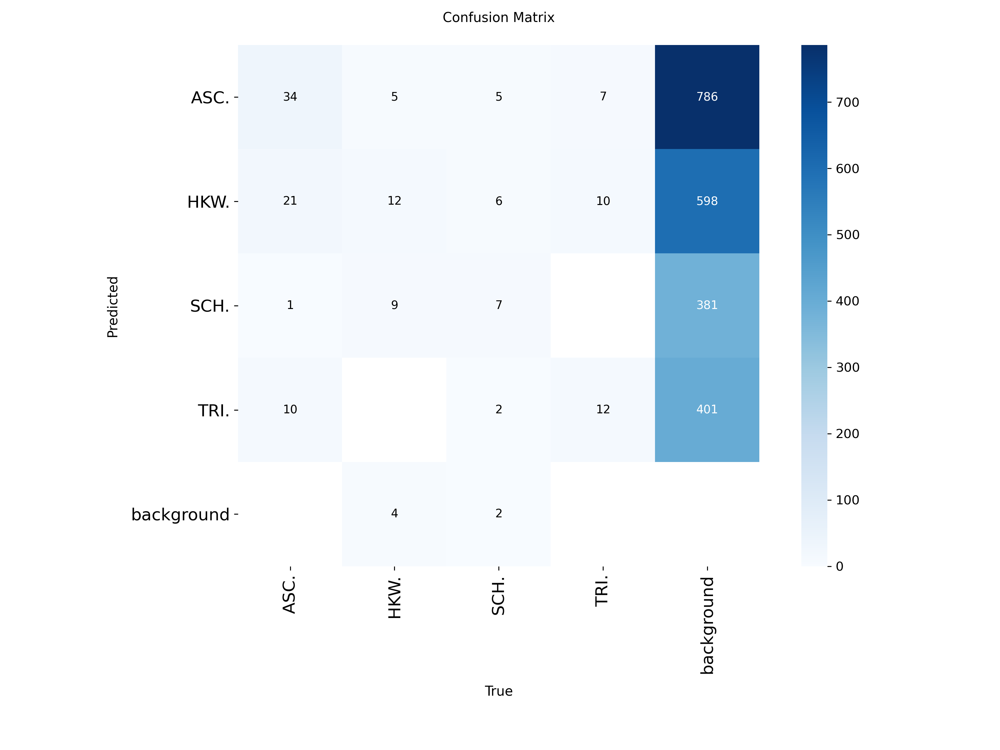

In [ ]:

from IPython.display import display, Image
from pathlib import Path

cm_path = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "official_test_confusion_check/test_run/confusion_matrix.png"
)

assert cm_path.exists(), f"Image not found: {cm_path}"
display(Image(filename=str(cm_path)))


In [ ]:

from pathlib import Path
from PIL import Image

p = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "official_test_confusion_check/test_run/confusion_matrix.png"
)

img = Image.open(p)
print("Image size:", img.size)
print("Image mode:", img.mode)
print("Image file exists:", p.exists())
print("Image format:", img.format)


Image size: (3000, 2250)
Image mode: RGBA
Image file exists: True
Image format: PNG


In [ ]:

from pathlib import Path
from ultralytics import YOLO

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(project / "models" / "best.pt"))

print("Model class names:")
print(model.names)

print("\nConfusion matrix labels:")
print(metrics.confusion_matrix.names)

print("\nConfusion matrix shape:")
print(metrics.confusion_matrix.matrix.shape)


Model class names:
{0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}

Confusion matrix labels:
{0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}

Confusion matrix shape:
(5, 5)


In [ ]:

import inspect
from ultralytics.utils.metrics import ConfusionMatrix

print(inspect.getsource(ConfusionMatrix.process_batch))


    def process_batch(
        self,
        detections: dict[str, torch.Tensor],
        batch: dict[str, Any],
        conf: float = 0.25,
        iou_thres: float = 0.45,
    ) -> None:
        """Update confusion matrix for object detection task.

        Args:
            detections (dict[str, torch.Tensor]): Dictionary containing detected bounding boxes and their associated
                information. Should contain 'cls', 'conf', and 'bboxes' keys, where 'bboxes' can be Array[N, 4] for
                regular boxes or Array[N, 5] for OBB with angle.
            batch (dict[str, Any]): Batch dictionary containing ground truth data with 'bboxes' (Array[M, 4]| Array[M,
                5]) and 'cls' (Array[M]) keys, where M is the number of ground truth objects.
            conf (float, optional): Confidence threshold for detections.
            iou_thres (float, optional): IoU threshold for matching detections to ground truth. This is a matching
                threshold, not the 

In [ ]:

cm = metrics.confusion_matrix

print("Confusion matrix confidence threshold:", cm.conf)
print("IoU matching threshold:", cm.iou_thres)
print("Number of classes:", cm.nc)

matrix = cm.matrix
print("\nMatrix total:", matrix.sum())
print("Matched class cells:", matrix[:4, :4].sum())
print("Background-row total (FN):", matrix[4, :4].sum())
print("Background-column total (FP):", matrix[:4, 4].sum())

print("\nOfficial evaluation metrics:")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)


AttributeError: 'ConfusionMatrix' object has no attribute 'conf'

In [ ]:

cm = metrics.confusion_matrix
matrix = cm.matrix

print("Number of classes:", cm.nc)
print("Matrix shape:", matrix.shape)

print("\nConfusion matrix:")
print(matrix)

print("\nMatrix total:", matrix.sum())
print("Class-to-class cells:", matrix[:4, :4].sum())
print("Background row total:", matrix[4, :4].sum())
print("Background column total:", matrix[:4, 4].sum())

print("\nOfficial evaluation metrics:")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)


Number of classes: 4
Matrix shape: (5, 5)

Confusion matrix:
[[         34           5           5           7         786]
 [         21          12           6          10         598]
 [          1           9           7           0         381]
 [         10           0           2          12         401]
 [          0           4           2           0           0]]

Matrix total: 2313.0
Class-to-class cells: 141.0
Background row total: 6.0
Background column total: 2166.0

Official evaluation metrics:
Precision: 0.7619882790860779
Recall: 0.6388826928263402
mAP50: 0.7214692404705383
mAP50-95: 0.5516046621342869


In [ ]:

import inspect
from ultralytics.utils.metrics import ConfusionMatrix

print("=== ConfusionMatrix initialization ===")
print(inspect.signature(ConfusionMatrix))
print(inspect.getsource(ConfusionMatrix.__init__))


=== ConfusionMatrix initialization ===
(names: 'dict[int, str] | None' = None, task: 'str' = 'detect', save_matches: 'bool' = False)
    def __init__(self, names: dict[int, str] | None = None, task: str = "detect", save_matches: bool = False):
        """Initialize a ConfusionMatrix instance.

        Args:
            names (dict[int, str], optional): Names of classes, used as labels on the plot.
            task (str, optional): Type of task, one of 'detect', 'semantic', 'classify', or 'obb'.
            save_matches (bool, optional): Save the indices of GTs, TPs, FPs, FNs for visualization.
        """
        names = names if names is not None else {}
        self.task = task
        self.nc = len(names)  # number of classes
        self.matrix = (
            np.zeros((self.nc, self.nc))
            if self.task in {"classify", "semantic"}
            else np.zeros((self.nc + 1, self.nc + 1))
        )
        self.names = names  # name of classes
        self.matches = {} if save

In [ ]:

import inspect
from ultralytics.models.yolo.detect.val import DetectionValidator

print(inspect.getsource(DetectionValidator.init_metrics))


    def init_metrics(self, model: torch.nn.Module) -> None:
        """Initialize evaluation metrics for YOLO detection validation.

        Args:
            model (torch.nn.Module): Model to validate.
        """
        if self.args.save_txt:  # labels are appended per image, drop those a previous run or epoch left in save_dir
            with torch_distributed_zero_first(LOCAL_RANK):
                if LOCAL_RANK in {-1, 0}:
                    for f in (self.save_dir / "labels").glob("*.txt"):
                        f.unlink(missing_ok=True)
            self.label_root = os.path.commonpath([os.path.dirname(f) for f in self.dataloader.dataset.im_files])
        if not self.training:
            self._check_max_det(self.args, {self.args.split or "val": self.dataloader.dataset})
        val = self.data.get(self.args.split, "")  # validation path
        self.is_coco = (
            isinstance(val, str)
            and "coco" in val
            and (val.endswith((f"{os.sep}val2017.tx

In [ ]:

import inspect
from ultralytics.models.yolo.detect.val import DetectionValidator

source = inspect.getsource(DetectionValidator.update_metrics)
print(source)


    def update_metrics(self, preds: list[dict[str, torch.Tensor]], batch: dict[str, Any]) -> None:
        """Update metrics with new predictions and ground truth.

        Args:
            preds (list[dict[str, torch.Tensor]]): List of predictions from the model.
            batch (dict[str, Any]): Batch data containing ground truth.
        """
        for si, pred in enumerate(preds):
            self.seen += 1
            pbatch = self._prepare_batch(si, batch)
            cls = pbatch["cls"].cpu().numpy()
            im_idx = self.eval_ids[self.seen - 1] if self.is_custom_json else None
            if self.build_gdict:
                boxes = ops.xyxy2ltwh(
                    ops.scale_boxes(pbatch["imgsz"], pbatch["bboxes"].clone(), pbatch["ori_shape"], pbatch["ratio_pad"])
                ).tolist()
                self.gdict["images"].append({"id": im_idx})
                self.gdict["annotations"].extend(
                    {
                        "id": (im_idx << 32 | i)

In [ ]:

from pathlib import Path

out_dir = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "validation_confusion_025/val_conf025"
)

print("Files in validation results folder:\n")

for p in sorted(out_dir.iterdir()):
    if p.is_file():
        print(f"{p.name} | {p.stat().st_size:,} bytes")

print("\nRequired outputs:")
for name in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "validation_confusion_matrix_counts.csv",
]:
    p = out_dir / name
    print(f"{name}: {'FOUND' if p.exists() else 'NOT FOUND'}")


Files in validation results folder:

BoxF1_curve.png | 170,310 bytes
BoxPR_curve.png | 106,520 bytes
BoxP_curve.png | 112,146 bytes
BoxR_curve.png | 160,338 bytes
confusion_matrix.png | 113,274 bytes
confusion_matrix_normalized.png | 136,759 bytes
val_batch0_labels.jpg | 297,904 bytes
val_batch0_pred.jpg | 298,811 bytes
val_batch1_labels.jpg | 384,426 bytes
val_batch1_pred.jpg | 386,491 bytes
val_batch2_labels.jpg | 504,733 bytes
val_batch2_pred.jpg | 512,593 bytes
validation_confusion_matrix_counts.csv | 195 bytes

Required outputs:
confusion_matrix.png: FOUND
confusion_matrix_normalized.png: FOUND
validation_confusion_matrix_counts.csv: FOUND


In [ ]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

files_to_check = [
    "results/test_metrics_rerun.json",
    "results/final_metrics_summary.json",
    "results/final_metrics_review/per_class_metrics.csv",
    "results/dataset_split_class_counts.csv",
    "results/final_validation_report/final_validation_report.txt",
    "models/best.pt",
    "dataset.yaml",
]

print("FINAL PROJECT FILE CHECK\n")

for rel_path in files_to_check:
    path = project / rel_path
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status}: {rel_path}")


FINAL PROJECT FILE CHECK

FOUND: results/test_metrics_rerun.json
MISSING: results/final_metrics_summary.json
FOUND: results/final_metrics_review/per_class_metrics.csv
FOUND: results/dataset_split_class_counts.csv
FOUND: results/final_validation_report/final_validation_report.txt
FOUND: models/best.pt
FOUND: dataset.yaml


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
results = project / "results"

print("Searching for metrics summary files...\n")

matches = [
    p for p in results.rglob("*")
    if p.is_file()
    and ("metrics" in p.name.lower() or "summary" in p.name.lower())
    and p.suffix.lower() in [".json", ".csv", ".txt"]
]

if matches:
    for p in sorted(matches):
        print(p.relative_to(project))
else:
    print("No matching summary files found.")


Searching for metrics summary files...

results/error_analysis/error_analysis_summary.json
results/error_analysis_figures/classwise_error_summary.csv
results/final_metrics_review/final_metrics_summary.json
results/final_metrics_review/per_class_metrics.csv
results/final_validation_report/validation_classwise_summary.csv
results/final_validation_report/validation_threshold_summary.csv
results/official_test_confusion_check/test_run/test_evaluation_summary.json
results/schistosoma_image_level_analysis/all_schistosoma_confidence_summary.csv
results/test_metrics.json
results/test_metrics_rerun.json
results/text_error_analysis/summary.json
results/threshold_diagnostics/overall_threshold_metrics.csv
results/validation_consistency_check/classwise_metrics.csv
results/validation_consistency_check/overall_metrics.csv
results/validation_missed_detection_analysis/five_image_gt_matching_summary.csv
results/validation_missed_detection_analysis/full_validation_overall_threshold_metrics.csv
results/val

In [ ]:

from pathlib import Path
import json

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

MODEL = PROJECT / "models" / "best.pt"
DATA = PROJECT / "dataset.yaml"

METRICS = PROJECT / "results" / "test_metrics_rerun.json"
VAL_DIR = (
    PROJECT / "results" / "validation_confusion_025"
    / "val_conf025"
)

checks = {
    "Model checkpoint": MODEL,
    "Dataset YAML": DATA,
    "Official test metrics": METRICS,
    "Validation confusion matrix": VAL_DIR / "confusion_matrix.png",
    "Validation counts CSV": VAL_DIR / "validation_confusion_matrix_counts.csv",
}

for label, path in checks.items():
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {label}")

if METRICS.exists():
    with open(METRICS, "r") as f:
        metrics_data = json.load(f)
    print("\nOfficial test metrics file loaded.")
    print(json.dumps(metrics_data, indent=2)[:4000])


FOUND: Model checkpoint
FOUND: Dataset YAML
FOUND: Official test metrics
FOUND: Validation confusion matrix
FOUND: Validation counts CSV

Official test metrics file loaded.
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}


In [ ]:

from pathlib import Path
import pandas as pd

csv_path = (
    Path("/content/drive/MyDrive/Helminth_GitHub_Project")
    / "results/validation_confusion_025/val_conf025"
    / "validation_confusion_matrix_counts.csv"
)

cm = pd.read_csv(csv_path, index_col=0)

# CSV rows = predicted classes; columns = actual classes
classes = ["ASC", "HKW", "SCH", "TRI"]
summary = []

for cls in classes:
    pred_row = f"Predicted_{cls}"
    actual_col = f"Actual_{cls}"

    tp = int(cm.loc[pred_row, actual_col])
    fp = int(cm.loc[pred_row].sum() - tp)
    fn = int(cm[actual_col].sum() - tp)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    summary.append({
        "Class": cls,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision_%": round(precision * 100, 2),
        "Recall_%": round(recall * 100, 2),
    })

result = pd.DataFrame(summary)
print(result.to_string(index=False))

save_path = csv_path.parent / "validation_classwise_error_diagnostic.csv"
result.to_csv(save_path, index=False)
print("\nSaved:", save_path)


Class  TP  FP  FN  Precision_%  Recall_%
  ASC  40  10   4        80.00     90.91
  HKW  14   6   2        70.00     87.50
  SCH  12   4  13        75.00     48.00
  TRI  23   4   6        85.19     79.31

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_confusion_025/val_conf025/validation_classwise_error_diagnostic.csv


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

folders = [
    PROJECT / "results" / "schistosoma_image_level_analysis",
    PROJECT / "results" / "final_metrics_review",
]

for folder in folders:
    print("\n" + "=" * 65)
    print("FOLDER:", folder)
    print("=" * 65)

    if not folder.exists():
        print("Folder not found")
        continue

    for path in sorted(folder.glob("*.csv")):
        print(f"\nFILE: {path.name}")
        try:
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print(df.head(5).to_string(index=False))
        except Exception as e:
            print("Could not read:", e)



FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis

FILE: all_schistosoma_confidence_summary.csv
Shape: (23, 7)
Columns: ['image', 'gt_index', 'status', 'matched_iou', 'prediction_confidence', 'overlapping_other_class', 'confidence_band']
                   image  gt_index                              status  matched_iou  prediction_confidence overlapping_other_class confidence_band
val_0004_image_00592.png         0 Low-confidence same-class candidate       0.7106                 0.1268                      No       0.10–0.25
val_0005_image_00792.png         0 Low-confidence same-class candidate       0.7883                 0.0170                      No       0.01–0.05
val_0006_image_01090.png         0                  Detected correctly       0.7648                 0.6649                      No          >=0.25
val_0008_image_08030.png         0                  Detected correctly       0.8428                 0.8619                     

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
MODEL_PATH = PROJECT / "models" / "best.pt"
DATA_PATH = PROJECT / "dataset.yaml"
OUT = PROJECT / "results" / "threshold_comparison_validation"

model = YOLO(str(MODEL_PATH))
rows = []

for conf in [0.10, 0.25, 0.50]:
    print(f"\nEvaluating validation set at conf={conf}")

    metrics = model.val(
        data=str(DATA_PATH),
        split="val",
        imgsz=320,
        conf=conf,
        plots=False,
        project=str(OUT),
        name=f"conf_{str(conf).replace('.', '')}",
        exist_ok=True,
        verbose=False
    )

    rows.append({
        "confidence_threshold": conf,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
    })

df = pd.DataFrame(rows)
for col in ["precision", "recall", "mAP50", "mAP50_95"]:
    df[col] = (df[col] * 100).round(2)

save_path = OUT / "validation_threshold_comparison.csv"
save_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(save_path, index=False)

print("\nVALIDATION THRESHOLD COMPARISON (%)")
print(df.to_string(index=False))
print("\nSaved:", save_path)



Evaluating validation set at conf=0.1
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 278.3±49.6 MB/s, size: 3139.7 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 6.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.6s/it 10.4s
                   all         60        114       0.88      0.769      0.825       0.66
Speed: 1.3ms preprocess, 53.2ms inference, 0.0ms loss, 0.4ms postprocess per image

Evaluating validation set at conf=0.25
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image acces

In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

folders = [
    project / "results" / "validation_confusion_025" / "val_conf025",
    project / "results" / "threshold_comparison_validation",
]

for folder in folders:
    print("\nFOLDER:", folder)
    if folder.exists():
        for p in sorted(folder.rglob("*")):
            if p.is_file() and p.suffix.lower() in [".csv", ".json", ".txt"]:
                print(p.relative_to(project))
    else:
        print("Folder not found")



FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_confusion_025/val_conf025
results/validation_confusion_025/val_conf025/validation_classwise_error_diagnostic.csv
results/validation_confusion_025/val_conf025/validation_confusion_matrix_counts.csv

FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/threshold_comparison_validation
results/threshold_comparison_validation/validation_threshold_comparison.csv


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

folders = [
    project / "results" / "validation_confusion_025" / "val_conf025",
    project / "results" / "threshold_comparison_validation" / "conf_01",
    project / "results" / "threshold_comparison_validation" / "conf_025",
    project / "results" / "threshold_comparison_validation" / "conf_05",
]

for folder in folders:
    print("\n" + "=" * 55)
    print("FOLDER:", folder)
    if not folder.exists():
        print("Folder not found")
        continue

    for p in sorted(folder.iterdir()):
        print(("DIR  " if p.is_dir() else "FILE "), p.name)

print("\n" + "=" * 55)
yaml_path = project / "dataset.yaml"
print("DATASET YAML:")
print(yaml_path.read_text() if yaml_path.exists() else "Missing")



FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_confusion_025/val_conf025
FILE  BoxF1_curve.png
FILE  BoxPR_curve.png
FILE  BoxP_curve.png
FILE  BoxR_curve.png
FILE  confusion_matrix.png
FILE  confusion_matrix_normalized.png
FILE  val_batch0_labels.jpg
FILE  val_batch0_pred.jpg
FILE  val_batch1_labels.jpg
FILE  val_batch1_pred.jpg
FILE  val_batch2_labels.jpg
FILE  val_batch2_pred.jpg
FILE  validation_classwise_error_diagnostic.csv
FILE  validation_confusion_matrix_counts.csv

FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/threshold_comparison_validation/conf_01

FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/threshold_comparison_validation/conf_025

FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/threshold_comparison_validation/conf_05

DATASET YAML:
path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2:

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import json

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model_path = project / "models" / "best.pt"
data_path = project / "dataset.yaml"

model = YOLO(str(model_path))

metrics = model.val(
    data=str(data_path),
    split="val",
    imgsz=320,
    conf=0.25,
    plots=False,
    verbose=False
)

result = {
    "model": str(model_path),
    "split": "val",
    "imgsz": 320,
    "conf": 0.25,
    "images": 60,
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
}

print(json.dumps(result, indent=2))


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 352.1±51.5 MB/s, size: 3169.0 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 9.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5s/it 10.2s
                   all         60        114       0.88      0.769      0.767      0.626
Speed: 1.2ms preprocess, 52.3ms inference, 0.0ms loss, 0.3ms postprocess per image
{
  "model": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt",
  "split": "val",
  "imgsz": 320,
  "conf": 0.25,
  "images": 60,
  "precision": 0.8799133632058441,
  "recall": 0.7687599579722976,
  "mAP50": 0.7666476972639764,
  "mAP50_95": 0.6257454207

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import numpy as np
import json

# ---------- 1. Paths ----------
PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
MODEL_PATH = PROJECT / "models" / "best.pt"
IMAGE_DIR = DATASET / "images" / "val"
LABEL_DIR = DATASET / "labels" / "val"

OUT_DIR = PROJECT / "results" / "validation_error_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.exists(), f"Model missing: {MODEL_PATH}"
assert IMAGE_DIR.exists(), f"Images missing: {IMAGE_DIR}"
assert LABEL_DIR.exists(), f"Labels missing: {LABEL_DIR}"

# ---------- 2. Load existing model ----------
model = YOLO(str(MODEL_PATH))
CLASS_NAMES = {
    0: "ASC",
    1: "HKW",
    2: "SCH",
    3: "TRI",
}

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

print("Validation images:", len(image_paths))
print("Model loaded. No training will be performed.")

# ---------- 3. Helpers ----------
def load_yolo_labels(label_path, width, height):
    boxes, classes = [], []

    if not label_path.exists():
        return np.empty((0, 4)), np.empty((0,), dtype=int)

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue

        cls = int(float(parts[0]))
        xc, yc, w, h = map(float, parts[1:5])

        boxes.append([
            (xc - w / 2) * width,
            (yc - h / 2) * height,
            (xc + w / 2) * width,
            (yc + h / 2) * height,
        ])
        classes.append(cls)

    return np.asarray(boxes, dtype=float).reshape(-1, 4), np.asarray(classes, dtype=int)


def box_iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=float)

    left_top = np.maximum(a[:, None, :2], b[None, :, :2])
    right_bottom = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.maximum(right_bottom - left_top, 0)

    intersection = wh[:, :, 0] * wh[:, :, 1]
    area_a = np.maximum(a[:, 2] - a[:, 0], 0) * np.maximum(a[:, 3] - a[:, 1], 0)
    area_b = np.maximum(b[:, 2] - b[:, 0], 0) * np.maximum(b[:, 3] - b[:, 1], 0)
    union = area_a[:, None] + area_b[None, :] - intersection

    return np.divide(
        intersection, union,
        out=np.zeros_like(intersection),
        where=union > 0
    )


# ---------- 4. Predict on validation only ----------
results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.001,
    iou=0.7,
    max_det=300,
    save=False,
    verbose=False
)

detail_rows = []

# ---------- 5. Match predictions to ground truth ----------
for result in results:
    image_path = Path(result.path)
    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    height, width = result.orig_shape
    gt_boxes, gt_classes = load_yolo_labels(label_path, width, height)

    if result.boxes is None or len(result.boxes) == 0:
        pred_boxes = np.empty((0, 4))
        pred_classes = np.empty((0,), dtype=int)
        pred_conf = np.empty((0,))
    else:
        pred_boxes = result.boxes.xyxy.cpu().numpy()
        pred_classes = result.boxes.cls.cpu().numpy().astype(int)
        pred_conf = result.boxes.conf.cpu().numpy()

    ious = box_iou_matrix(pred_boxes, gt_boxes)

    # Greedy, one-to-one, class-agnostic matching at IoU >= 0.50.
    # Class-agnostic matching helps expose wrong-class predictions.
    candidates = []
    for pi in range(len(pred_boxes)):
        for gi in range(len(gt_boxes)):
            if ious[pi, gi] >= 0.50:
                candidates.append((ious[pi, gi], pi, gi))

    candidates.sort(reverse=True)

    matched_pred, matched_gt = set(), set()
    matches = []

    for iou_value, pi, gi in candidates:
        if pi in matched_pred or gi in matched_gt:
            continue
        matched_pred.add(pi)
        matched_gt.add(gi)
        matches.append((pi, gi, float(iou_value)))

    # Matched objects: correct class or wrong class
    for pi, gi, iou_value in matches:
        pred_cls = int(pred_classes[pi])
        gt_cls = int(gt_classes[gi])
        correct = pred_cls == gt_cls

        detail_rows.append({
            "image": image_path.name,
            "status": "Correct class match" if correct else "Wrong-class match",
            "gt_class": CLASS_NAMES.get(gt_cls, str(gt_cls)),
            "predicted_class": CLASS_NAMES.get(pred_cls, str(pred_cls)),
            "confidence": float(pred_conf[pi]),
            "IoU": round(iou_value, 4),
            "gt_index": gi,
            "prediction_index": pi,
        })

    # Unmatched ground-truth objects: missed detections
    for gi in range(len(gt_boxes)):
        if gi not in matched_gt:
            detail_rows.append({
                "image": image_path.name,
                "status": "Missed ground-truth object",
                "gt_class": CLASS_NAMES.get(int(gt_classes[gi]), str(gt_classes[gi])),
                "predicted_class": "",
                "confidence": np.nan,
                "IoU": 0.0,
                "gt_index": gi,
                "prediction_index": -1,
            })

    # Unmatched predictions: false positives
    for pi in range(len(pred_boxes)):
        if pi not in matched_pred:
            detail_rows.append({
                "image": image_path.name,
                "status": "Unmatched prediction / false positive",
                "gt_class": "",
                "predicted_class": CLASS_NAMES.get(int(pred_classes[pi]), str(pred_classes[pi])),
                "confidence": float(pred_conf[pi]),
                "IoU": 0.0,
                "gt_index": -1,
                "prediction_index": pi,
            })

# ---------- 6. Save detailed error report ----------
detail = pd.DataFrame(detail_rows)
detail_path = OUT_DIR / "validation_prediction_error_details.csv"
detail.to_csv(detail_path, index=False)

# ---------- 7. Class-wise diagnostic summary ----------
summary_rows = []

for cls_id, cls_name in CLASS_NAMES.items():
    gt_count = int(sum(
        (detail["gt_class"] == cls_name)
        & (detail["status"].isin([
            "Correct class match", "Wrong-class match",
            "Missed ground-truth object"
        ]))
    ))

    correct_tp = int(sum(
        (detail["gt_class"] == cls_name)
        & (detail["predicted_class"] == cls_name)
        & (detail["status"] == "Correct class match")
    ))

    # Wrong-class detections count as FP for the predicted class.
    wrong_class_fp = int(sum(
        (detail["predicted_class"] == cls_name)
        & (detail["status"] == "Wrong-class match")
    ))

    unmatched_fp = int(sum(
        (detail["predicted_class"] == cls_name)
        & (detail["status"] == "Unmatched prediction / false positive")
    ))

    # Wrong-class matched GT objects count as FN for the actual class.
    wrong_class_fn = int(sum(
        (detail["gt_class"] == cls_name)
        & (detail["status"] == "Wrong-class match")
    ))

    missed_fn = int(sum(
        (detail["gt_class"] == cls_name)
        & (detail["status"] == "Missed ground-truth object")
    ))

    fp = wrong_class_fp + unmatched_fp
    fn = wrong_class_fn + missed_fn
    precision = correct_tp / (correct_tp + fp) if correct_tp + fp else 0.0
    recall = correct_tp / (correct_tp + fn) if correct_tp + fn else 0.0

    summary_rows.append({
        "class": cls_name,
        "GT_objects": gt_count,
        "correct_class_matches": correct_tp,
        "wrong_class_FP": wrong_class_fp,
        "unmatched_FP": unmatched_fp,
        "total_FP": fp,
        "wrong_class_FN": wrong_class_fn,
        "missed_FN": missed_fn,
        "total_FN": fn,
        "diagnostic_precision_pct": round(precision * 100, 2),
        "diagnostic_recall_pct": round(recall * 100, 2),
    })

summary = pd.DataFrame(summary_rows)
summary_path = OUT_DIR / "validation_classwise_error_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nCLASS-WISE VALIDATION ERROR SUMMARY")
print(summary.to_string(index=False))

print("\nSAVED FILES")
print("Details:", detail_path)
print("Summary:", summary_path)

print("\nERROR COUNTS")
print(detail["status"].value_counts(dropna=False).to_string())


Validation images: 60
Model loaded. No training will be performed.

CLASS-WISE VALIDATION ERROR SUMMARY
class  GT_objects  correct_class_matches  wrong_class_FP  unmatched_FP  total_FP  wrong_class_FN  missed_FN  total_FN  diagnostic_precision_pct  diagnostic_recall_pct
  ASC          44                     43               6           557       563               1          0         1                      7.10                  97.73
  HKW          16                     16               1           313       314               0          0         0                      4.85                 100.00
  SCH          25                     22               0           308       308               1          2         3                      6.67                  88.00
  TRI          29                     24               0           262       262               5          0         5                      8.39                  82.76

SAVED FILES
Details: /content/drive/MyDrive/Helminth_GitHub_

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import numpy as np

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

MODEL_PATH = PROJECT / "models" / "best.pt"
IMAGE_DIR = DATASET / "images" / "val"
LABEL_DIR = DATASET / "labels" / "val"

OUT_DIR = PROJECT / "results" / "validation_error_analysis_conf025"
OUT_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.25,
    iou=0.45,
    max_det=300,
    save=False,
    verbose=False
)

print("Validation images:", len(results))
print("Prediction confidence: 0.25")
print("NMS IoU: 0.45")
print("No training performed.")

# Save a compact prediction inventory for the next analysis step.
rows = []

for result in results:
    if result.boxes is None or len(result.boxes) == 0:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for box, cls, confidence in zip(boxes, classes, confidences):
        rows.append({
            "image": Path(result.path).name,
            "predicted_class_id": int(cls),
            "predicted_class": {0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"}.get(int(cls), str(cls)),
            "confidence": float(confidence),
            "x1": float(box[0]),
            "y1": float(box[1]),
            "x2": float(box[2]),
            "y2": float(box[3]),
        })

pred_df = pd.DataFrame(rows)
save_path = OUT_DIR / "validation_predictions_conf025.csv"
pred_df.to_csv(save_path, index=False)

print("\nPredictions retained:", len(pred_df))
print("\nPredictions by class:")
if not pred_df.empty:
    print(pred_df["predicted_class"].value_counts().to_string())

print("\nSaved:", save_path)


Validation images: 60
Prediction confidence: 0.25
NMS IoU: 0.45
No training performed.

Predictions retained: 113

Predictions by class:
predicted_class
ASC    52
TRI    25
HKW    21
SCH    15

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_error_analysis_conf025/validation_predictions_conf025.csv


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
IMAGE_DIR = DATASET / "images" / "val"
LABEL_DIR = DATASET / "labels" / "val"

PRED_PATH = (
    PROJECT / "results" / "validation_error_analysis_conf025"
    / "validation_predictions_conf025.csv"
)
OUT_DIR = PRED_PATH.parent

NAMES = {0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"}
pred_df = pd.read_csv(PRED_PATH)


def read_gt(label_path, width, height):
    boxes, classes = [], []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            c = int(float(parts[0]))
            xc, yc, w, h = map(float, parts[1:5])
            boxes.append([
                (xc - w/2)*width, (yc - h/2)*height,
                (xc + w/2)*width, (yc + h/2)*height
            ])
            classes.append(c)
    return np.asarray(boxes, dtype=float).reshape(-1, 4), np.asarray(classes, dtype=int)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.maximum(rb - lt, 0)
    inter = wh[:, :, 0] * wh[:, :, 1]
    area_a = (a[:, 2]-a[:, 0]) * (a[:, 3]-a[:, 1])
    area_b = (b[:, 2]-b[:, 0]) * (b[:, 3]-b[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)


detail_rows = []

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

for image_path in image_paths:
    with Image.open(image_path) as im:
        width, height = im.size

    gt_boxes, gt_classes = read_gt(
        LABEL_DIR / f"{image_path.stem}.txt", width, height
    )

    sub = pred_df[pred_df["image"] == image_path.name]
    pred_boxes = (
        sub[["x1", "y1", "x2", "y2"]].to_numpy(dtype=float)
        if len(sub) else np.empty((0, 4))
    )
    pred_classes = (
        sub["predicted_class_id"].to_numpy(dtype=int)
        if len(sub) else np.empty((0,), dtype=int)
    )
    pred_conf = (
        sub["confidence"].to_numpy(dtype=float)
        if len(sub) else np.empty((0,), dtype=float)
    )

    ious = iou_matrix(pred_boxes, gt_boxes)
    candidates = [
        (float(ious[pi, gi]), pi, gi)
        for pi in range(len(pred_boxes))
        for gi in range(len(gt_boxes))
        if ious[pi, gi] >= 0.45
    ]
    candidates.sort(reverse=True)

    used_p, used_g = set(), set()
    matches = []

    for iou, pi, gi in candidates:
        if pi not in used_p and gi not in used_g:
            used_p.add(pi)
            used_g.add(gi)
            matches.append((pi, gi, iou))

    for pi, gi, iou in matches:
        pc, gc = int(pred_classes[pi]), int(gt_classes[gi])
        correct = pc == gc
        detail_rows.append({
            "image": image_path.name,
            "status": "Correct class match" if correct else "Wrong-class match",
            "gt_class": NAMES.get(gc, str(gc)),
            "predicted_class": NAMES.get(pc, str(pc)),
            "confidence": float(pred_conf[pi]),
            "IoU": round(iou, 4),
        })

    for gi, gc in enumerate(gt_classes):
        if gi not in used_g:
            detail_rows.append({
                "image": image_path.name,
                "status": "Missed ground-truth object",
                "gt_class": NAMES.get(int(gc), str(gc)),
                "predicted_class": "",
                "confidence": np.nan,
                "IoU": 0.0,
            })

    for pi, pc in enumerate(pred_classes):
        if pi not in used_p:
            detail_rows.append({
                "image": image_path.name,
                "status": "Unmatched prediction / false positive",
                "gt_class": "",
                "predicted_class": NAMES.get(int(pc), str(pc)),
                "confidence": float(pred_conf[pi]),
                "IoU": 0.0,
            })

detail = pd.DataFrame(detail_rows)
detail.to_csv(OUT_DIR / "validation_error_details_conf025.csv", index=False)

summary = []
for cls in NAMES.values():
    tp = int(((detail.status == "Correct class match") &
              (detail.gt_class == cls)).sum())
    wrong_fp = int(((detail.status == "Wrong-class match") &
                    (detail.predicted_class == cls)).sum())
    extra_fp = int(((detail.status == "Unmatched prediction / false positive") &
                    (detail.predicted_class == cls)).sum())
    wrong_fn = int(((detail.status == "Wrong-class match") &
                    (detail.gt_class == cls)).sum())
    missed_fn = int(((detail.status == "Missed ground-truth object") &
                     (detail.gt_class == cls)).sum())

    fp, fn = wrong_fp + extra_fp, wrong_fn + missed_fn
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    summary.append({
        "class": cls, "TP": tp, "wrong_class_FP": wrong_fp,
        "unmatched_FP": extra_fp, "total_FP": fp,
        "wrong_class_FN": wrong_fn, "missed_FN": missed_fn,
        "total_FN": fn, "precision_pct": round(100*precision, 2),
        "recall_pct": round(100*recall, 2)
    })

summary_df = pd.DataFrame(summary)
summary_df.to_csv(OUT_DIR / "validation_classwise_error_summary_conf025.csv",
                  index=False)

print("CLASS-WISE ERROR SUMMARY")
print(summary_df.to_string(index=False))
print("\nMATCHING COUNTS")
print(detail["status"].value_counts().to_string())
print("\nSaved reports in:", OUT_DIR)


CLASS-WISE ERROR SUMMARY
class  TP  wrong_class_FP  unmatched_FP  total_FP  wrong_class_FN  missed_FN  total_FN  precision_pct  recall_pct
  ASC  41               4             7        11               0          3         3          78.85       93.18
  HKW  15               0             6         6               0          1         1          71.43       93.75
  SCH  12               0             3         3               0         13        13          80.00       48.00
  TRI  23               0             2         2               4          2         6          92.00       79.31

MATCHING COUNTS
status
Correct class match                      91
Missed ground-truth object               19
Unmatched prediction / false positive    18
Wrong-class match                         4

Saved reports in: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_error_analysis_conf025


In [ ]:

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = PROJECT / "dataset.yaml"
MODEL_PATH = PROJECT / "models" / "best.pt"
OUT = PROJECT / "results" / "sch_confidence_sweep"
OUT.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))
rows = []

for conf in [0.05, 0.10, 0.15, 0.25, 0.35]:
    metrics = model.val(
        data=str(DATA),
        split="val",
        imgsz=320,
        conf=conf,
        iou=0.45,
        plots=False,
        verbose=False
    )

    box = metrics.box
    row = {
        "confidence": conf,
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50_95": float(box.map),
    }

    # Per-class AP50, if available
    ap50 = getattr(box, "ap50", None)
    if ap50 is not None:
        for class_id, class_name in {
            0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"
        }.items():
            if len(ap50) > class_id:
                row[f"{class_name}_AP50"] = float(ap50[class_id])

    rows.append(row)
    print("Finished confidence:", conf)

df = pd.DataFrame(rows)
df.to_csv(OUT / "confidence_sweep.csv", index=False)
print("\nVALIDATION CONFIDENCE SWEEP")
print(df.round(4).to_string(index=False))
print("\nSaved:", OUT / "confidence_sweep.csv")


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 1.5±2.3 ms, read: 122.2±29.0 MB/s, size: 3043.3 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 9.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5s/it 10.0s
                   all         60        114      0.891      0.771      0.863      0.682
Speed: 0.4ms preprocess, 39.1ms inference, 0.0ms loss, 0.3ms postprocess per image
Finished confidence: 0.05
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 515.7±45.1 MB/s, size: 3

In [ ]:
from ultralytics import YOLO
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(PROJECT / "models" / "best.pt"))

for i in range(2):
    m = model.val(
        data=str(PROJECT / "dataset.yaml"),
        split="val",
        imgsz=320,
        conf=0.001,
        iou=0.45,
        plots=False,
        verbose=False
    )
    print(
        f"Run {i+1}: "
        f"P={m.box.mp:.4f}, "
        f"R={m.box.mr:.4f}, "
        f"mAP50={m.box.map50:.4f}, "
        f"mAP50-95={m.box.map:.4f}"
    )

Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 1.2±1.5 ms, read: 160.5±29.0 MB/s, size: 3146.8 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 10.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.9s/it 11.8s
                   all         60        114      0.891      0.771      0.878      0.691
Speed: 0.5ms preprocess, 40.1ms inference, 0.0ms loss, 0.5ms postprocess per image
Run 1: P=0.8906, R=0.7708, mAP50=0.8779, mAP50-95=0.6908
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
DETAIL = PROJECT / "results/validation_error_analysis_conf025/validation_error_details_conf025.csv"

df = pd.read_csv(DETAIL)

# SCH ground-truth objects that were not matched to a prediction
sch_missed = df[
    (df["gt_class"] == "SCH") &
    (df["status"] == "Missed ground-truth object")
].copy()

print("SCH missed-object records:", len(sch_missed))
print(sch_missed[["image", "gt_class", "status"]].to_string(index=False))

out = PROJECT / "results/schistosoma_image_level_analysis/sch_missed_objects.csv"
out.parent.mkdir(parents=True, exist_ok=True)
sch_missed.to_csv(out, index=False)
print("\nSaved:", out)


SCH missed-object records: 13
                   image gt_class                     status
val_0004_image_00592.png      SCH Missed ground-truth object
val_0005_image_00792.png      SCH Missed ground-truth object
val_0009_image_01442.png      SCH Missed ground-truth object
val_0021_image_00539.png      SCH Missed ground-truth object
val_0021_image_00539.png      SCH Missed ground-truth object
val_0027_image_01706.png      SCH Missed ground-truth object
val_0032_image_09205.png      SCH Missed ground-truth object
val_0034_image_09685.png      SCH Missed ground-truth object
val_0041_image_01700.png      SCH Missed ground-truth object
val_0043_image_06575.png      SCH Missed ground-truth object
val_0048_image_02146.png      SCH Missed ground-truth object
val_0058_image_02395.png      SCH Missed ground-truth object
val_0059_image_01346.png      SCH Missed ground-truth object

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/sch_missed_objects.c

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

missed_path = (
    RESULTS / "schistosoma_image_level_analysis"
    / "sch_missed_objects.csv"
)
pred_path = (
    RESULTS / "validation_error_analysis_conf025"
    / "validation_predictions_conf025.csv"
)

missed = pd.read_csv(missed_path)
pred = pd.read_csv(pred_path)

# Predictions from images containing missed SCH objects
images = missed["image"].dropna().unique()
nearby = pred[pred["image"].isin(images)].copy()

if len(nearby):
    nearby["predicted_class"] = nearby["predicted_class"].map(
        {0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"}
    )
    nearby = nearby.sort_values(
        ["image", "confidence"], ascending=[True, False]
    )
    print("Predictions in images with missed SCH objects:")
    print(nearby[
        ["image", "predicted_class", "confidence", "x1", "y1", "x2", "y2"]
    ].to_string(index=False))
else:
    print("No predictions found in these images.")

print("\nUnique images:", len(images))
print("Predictions listed:", len(nearby))


Predictions in images with missed SCH objects:
                   image predicted_class  confidence          x1          y1          x2          y2
val_0005_image_00792.png             NaN    0.415846  121.174583 1117.716797  256.034973 1294.356323
val_0021_image_00539.png             NaN    0.313225 1652.817993 1115.305542 1752.252197 1291.052856
val_0034_image_09685.png             NaN    0.403394 1587.857666 1096.015991 1746.377930 1220.471191

Unique images: 12
Predictions listed: 3


In [ ]:

import pandas as pd
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "validation_error_analysis_conf025/validation_predictions_conf025.csv"
)

df = pd.read_csv(p)

print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))


Columns: ['image', 'predicted_class_id', 'predicted_class', 'confidence', 'x1', 'y1', 'x2', 'y2']

First 5 rows:
                   image  predicted_class_id predicted_class  confidence          x1         y1          x2          y2
val_0001_image_05520.png                   0             ASC    0.963677  449.731659 447.019928  689.034851  698.476196
val_0001_image_05520.png                   3             TRI    0.962239 1302.010620 302.837463 1425.117554  488.147705
val_0001_image_05520.png                   3             TRI    0.959731  583.740173 747.074829  777.533142  930.008606
val_0001_image_05520.png                   0             ASC    0.952679  566.442993 979.866089  801.158813 1221.448975
val_0002_image_03853.png                   3             TRI    0.953974  769.110535 303.020264  942.098389  455.803680


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = PROJECT / "results"

missed = pd.read_csv(
    RESULTS / "schistosoma_image_level_analysis" / "sch_missed_objects.csv"
)
pred = pd.read_csv(
    RESULTS / "validation_error_analysis_conf025" /
    "validation_predictions_conf025.csv"
)

images = missed["image"].dropna().unique()
nearby = pred[pred["image"].isin(images)].copy()

nearby = nearby.sort_values(
    ["image", "confidence"], ascending=[True, False]
)

print("Missed SCH objects:", len(missed))
print("Unique images:", len(images))
print("Predictions in those images:", len(nearby))

if len(nearby):
    print(nearby[
        ["image", "predicted_class", "confidence", "x1", "y1", "x2", "y2"]
    ].to_string(index=False))
else:
    print("No predictions at confidence 0.25 in these images.")


Missed SCH objects: 13
Unique images: 12
Predictions in those images: 3
                   image predicted_class  confidence          x1          y1          x2          y2
val_0005_image_00792.png             SCH    0.415846  121.174583 1117.716797  256.034973 1294.356323
val_0021_image_00539.png             SCH    0.313225 1652.817993 1115.305542 1752.252197 1291.052856
val_0034_image_09685.png             SCH    0.403394 1587.857666 1096.015991 1746.377930 1220.471191


In [ ]:
from ultralytics import YOLO
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(PROJECT / "models" / "best.pt"))

m = model.val(
    data=str(PROJECT / "dataset.yaml"),
    split="val",
    imgsz=640,
    conf=0.001,
    iou=0.45,
    plots=False,
    verbose=False
)

print(f"Precision: {m.box.mp:.4f}")
print(f"Recall: {m.box.mr:.4f}")
print(f"mAP50: {m.box.map50:.4f}")
print(f"mAP50-95: {m.box.map:.4f}")

Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 2.9±1.7 ms, read: 110.6±16.7 MB/s, size: 3269.3 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 10.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.9s/it 19.8s
                   all         60        114      0.477      0.571      0.501       0.35
Speed: 1.7ms preprocess, 153.7ms inference, 0.0ms loss, 0.7ms postprocess per image
Precision: 0.4769
Recall: 0.5708
mAP50: 0.5006
mAP50-95: 0.3502


In [ ]:

from ultralytics import YOLO
from pathlib import Path

P = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(P / "models" / "best.pt"))

m = model.val(
    data=str(P / "dataset.yaml"),
    split="val",
    imgsz=320,
    conf=0.001,
    iou=0.45,
    plots=False,
    verbose=False
)

names = {0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"}
print("\nCLASS-WISE VALIDATION RESULTS")
for i, name in names.items():
    print(
        f"{name}: "
        f"P={m.box.p[i]:.3f}, "
        f"R={m.box.r[i]:.3f}, "
        f"mAP50={m.box.ap50[i]:.3f}, "
        f"mAP50-95={m.box.ap[i]:.3f}"
    )


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.8±0.6 ms, read: 318.0±92.0 MB/s, size: 3104.7 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 12.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.8s/it 11.2s
                   all         60        114      0.891      0.771      0.878      0.691
Speed: 0.5ms preprocess, 50.2ms inference, 0.0ms loss, 0.5ms postprocess per image

CLASS-WISE VALIDATION RESULTS
ASC: P=0.913, R=0.909, mAP50=0.960, mAP50-95=0.767
HKW: P=0.827, R=0.875, mAP50=0.910, mAP50-95=0.800
SCH: P=0.900, R=0.480, mAP50=0.709, mAP50-95=0.470
TRI: P=0.922, R=0.819, mAP50=0.932, mAP50-95=0.726


In [ ]:

from ultralytics import YOLO
from pathlib import Path
import pandas as pd

P = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
D = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
OUT = P / "results" / "sch_low_conf_diagnostic"
OUT.mkdir(parents=True, exist_ok=True)

model = YOLO(str(P / "models" / "best.pt"))
images = sorted((D / "images" / "val").glob("*.png"))

results = model.predict(
    source=[str(x) for x in images],
    imgsz=320,
    conf=0.001,
    iou=0.45,
    max_det=300,
    save=False,
    verbose=False
)

rows = []
for r in results:
    if r.boxes is None:
        continue
    for b in r.boxes:
        c = int(b.cls.item())
        rows.append({
            "image": Path(r.path).name,
            "class_id": c,
            "class": model.names[c],
            "confidence": float(b.conf.item()),
            "x1": float(b.xyxy[0][0].item()),
            "y1": float(b.xyxy[0][1].item()),
            "x2": float(b.xyxy[0][2].item()),
            "y2": float(b.xyxy[0][3].item()),
        })

df = pd.DataFrame(rows)
df.to_csv(OUT / "all_predictions_conf001.csv", index=False)

print("Total predictions:", len(df))
print("\nSCH predictions by confidence band:")
sch = df[df["class"] == "SCH"]
print(pd.cut(
    sch["confidence"],
    bins=[0, 0.05, 0.10, 0.25, 0.50, 1.0],
    include_lowest=True
).value_counts().sort_index().to_string())
print("\nSaved:", OUT / "all_predictions_conf001.csv")


Total predictions: 1148

SCH predictions by confidence band:
confidence
(-0.001, 0.05]    0
(0.05, 0.1]       0
(0.1, 0.25]       0
(0.25, 0.5]       0
(0.5, 1.0]        0

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_low_conf_diagnostic/all_predictions_conf001.csv


In [ ]:
print(df["class"].value_counts().to_string())

class
ASC.    421
HKW.    257
SCH.    237
TRI.    233


In [ ]:

sch = df[df["class"].astype(str).str.strip().str.rstrip(".") == "SCH"].copy()

print("Total SCH predictions:", len(sch))
print("\nConfidence distribution:")
print(
    pd.cut(
        sch["confidence"],
        bins=[0, 0.05, 0.10, 0.25, 0.50, 1.0],
        include_lowest=True
    ).value_counts().sort_index().to_string()
)

print("\nLowest-confidence SCH predictions:")
print(
    sch.sort_values("confidence")[
        ["image", "confidence", "x1", "y1", "x2", "y2"]
    ].head(15).to_string(index=False)
)


Total SCH predictions: 237

Confidence distribution:
confidence
(-0.001, 0.05]    201
(0.05, 0.1]        11
(0.1, 0.25]        10
(0.25, 0.5]         6
(0.5, 1.0]          9

Lowest-confidence SCH predictions:
                   image  confidence          x1          y1          x2          y2
val_0021_image_00539.png    0.001001 1672.130981 1119.008179 1898.901245 1311.830444
val_0045_image_08989.png    0.001001  502.542633  827.698181 1250.655884 1232.000000
val_0021_image_00539.png    0.001005  187.479935  697.017517  287.128937  792.932861
val_0006_image_01090.png    0.001008  649.757080    2.788180  750.419922   65.684998
val_0038_image_03537.png    0.001008  269.085236  693.370239  926.186829 1127.451660
val_0004_image_00592.png    0.001013 1881.898193  636.097229 1989.238892  714.761353
val_0000_image_09515.png    0.001017    2.427114 1096.551392  128.410675 1286.395630
val_0008_image_08030.png    0.001017  163.627487  761.829102  257.079987  854.323120
val_0038_image_03537.png 

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")

missed = pd.read_csv(
    PROJECT / "results/schistosoma_image_level_analysis/sch_missed_objects.csv"
)
pred = df[df["class"].astype(str).str.strip().str.rstrip(".") == "SCH"].copy()

def get_gt(image):
    im_path = DATASET / "images" / "val" / image
    label_path = DATASET / "labels" / "val" / (Path(image).stem + ".txt")
    with Image.open(im_path) as im:
        W, H = im.size
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            p = line.split()
            if len(p) >= 5 and int(float(p[0])) == 2:
                xc, yc, w, h = map(float, p[1:5])
                boxes.append([(xc-w/2)*W, (yc-h/2)*H,
                              (xc+w/2)*W, (yc+h/2)*H])
    return np.array(boxes).reshape(-1, 4)

def iou(a, b):
    lt = np.maximum(a[:2], b[:2])
    rb = np.minimum(a[2:], b[2:])
    wh = np.maximum(rb-lt, 0)
    inter = wh[0]*wh[1]
    union = ((a[2]-a[0])*(a[3]-a[1]) +
             (b[2]-b[0])*(b[3]-b[1]) - inter)
    return inter/union if union > 0 else 0

rows = []
for image in missed["image"].dropna().unique():
    gt = get_gt(image)
    pp = pred[pred["image"] == image]
    for _, g in missed[missed["image"] == image].iterrows():
        # Locate the corresponding SCH GT object using nearest box center
        candidates = []
        for box in gt:
            candidates.append(box)
        if not candidates:
            continue
        # Evaluate each prediction against every SCH GT box in this image
        for _, p in pp.iterrows():
            pb = p[["x1", "y1", "x2", "y2"]].to_numpy(dtype=float)
            best_iou = max(iou(pb, b) for b in candidates)
            rows.append({
                "image": image,
                "confidence": p["confidence"],
                "best_SCH_GT_IoU_in_image": round(best_iou, 4)
            })

out = pd.DataFrame(rows)
if len(out):
    print(out.sort_values("best_SCH_GT_IoU_in_image", ascending=False)
          .head(20).to_string(index=False))
else:
    print("No SCH predictions found in the missed-object images.")


                   image  confidence  best_SCH_GT_IoU_in_image
val_0034_image_09685.png    0.115486                    0.8894
val_0021_image_00539.png    0.145184                    0.8374
val_0021_image_00539.png    0.145184                    0.8374
val_0059_image_01346.png    0.131148                    0.8322
val_0005_image_00792.png    0.017037                    0.7883
val_0034_image_09685.png    0.403394                    0.7783
val_0058_image_02395.png    0.084123                    0.7715
val_0041_image_01700.png    0.001572                    0.7607
val_0004_image_00592.png    0.126755                    0.7106
val_0043_image_06575.png    0.004264                    0.7031
val_0021_image_00539.png    0.062317                    0.7007
val_0021_image_00539.png    0.062317                    0.7007
val_0048_image_02146.png    0.001508                    0.6374
val_0032_image_09205.png    0.189550                    0.6084
val_0048_image_02146.png    0.006552                   

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = ROOT / "dataset.yaml"
model = YOLO(str(ROOT / "models/best.pt"))

rows = []
for conf in [0.01, 0.05, 0.10, 0.25]:
    m = model.val(
        data=str(DATA),
        split="val",
        imgsz=320,
        conf=conf,
        iou=0.45,
        plots=False,
        verbose=False
    )
    names = [str(x).strip().rstrip(".") for x in model.names.values()]
    sch_id = names.index("SCH")
    rows.append({
        "conf": conf,
        "precision": float(m.box.p),
        "recall": float(m.box.r),
        "mAP50": float(m.box.map50),
        "SCH_AP50": float(m.box.ap50[sch_id]),
        "SCH_AP50_95": float(m.box.ap[sch_id]),
    })

result = pd.DataFrame(rows)
print(result.round(4).to_string(index=False))


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 344.5±47.9 MB/s, size: 3144.4 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 11.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.6s/it 10.4s
                   all         60        114      0.891      0.771       0.87      0.688
Speed: 0.4ms preprocess, 51.1ms inference, 0.0ms loss, 0.4ms postprocess per image


TypeError: only length-1 arrays can be converted to Python scalars

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(ROOT / "models/best.pt"))

rows = []
for conf in [0.01, 0.05, 0.10, 0.25]:
    m = model.val(
        data=str(ROOT / "dataset.yaml"),
        split="val",
        imgsz=320,
        conf=conf,
        iou=0.45,
        plots=False,
        verbose=False
    )

    names = [str(v).strip().rstrip(".") for v in model.names.values()]
    sch_id = names.index("SCH")

    rows.append({
        "conf": conf,
        "precision": round(float(m.box.mp), 4),
        "recall": round(float(m.box.mr), 4),
        "mAP50": round(float(m.box.map50), 4),
        "SCH_precision": round(float(m.box.p[sch_id]), 4),
        "SCH_recall": round(float(m.box.r[sch_id]), 4),
        "SCH_AP50": round(float(m.box.ap50[sch_id]), 4),
    })

result = pd.DataFrame(rows)
print(result.to_string(index=False))
result.to_csv(ROOT / "results/sch_confidence_sweep_corrected.csv", index=False)


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 346.2±22.4 MB/s, size: 3162.9 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 10.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5s/it 10.1s
                   all         60        114      0.891      0.771       0.87      0.688
Speed: 0.4ms preprocess, 43.8ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 427.3±18.1 MB/s, size: 3144.5 KB)
val: Scanning /

In [ ]:

import inspect
from ultralytics.models.yolo.detect.val import DetectionValidator

print("Validator:", inspect.getfile(DetectionValidator))
print("\nAP calculation / confidence-related source lines:")
src = inspect.getsource(DetectionValidator)
for i, line in enumerate(src.splitlines(), 1):
    if any(k in line.lower() for k in ["conf", "ap_per_class", "process_batch"]):
        print(f"{i}: {line.strip()}")


Validator: /usr/local/lib/python3.13/dist-packages/ultralytics/models/yolo/detect/val.py

AP calculation / confidence-related source lines:
131: self.confusion_matrix = ConfusionMatrix(names=model.names, save_matches=self.args.plots and self.args.visualize)
144: (list[dict[str, torch.Tensor]]): Processed predictions after NMS, where each dict contains 'bboxes', 'conf',
149: self.args.conf,
158: return [{"bboxes": x[:, :4], "conf": x[:, 4], "cls": x[:, 5], "extra": x[:, 6:]} for x in outputs]
235: **self._process_batch(predn, pbatch),
238: "conf": np.zeros(0) if no_pred else predn["conf"].cpu().numpy(),
244: self.confusion_matrix.process_batch(predn, pbatch, conf=self.args.conf)
246: self.confusion_matrix.plot_matches(
251: self.args.show_conf,
264: predn_scaled, self.args.save_conf, pbatch["ori_shape"], self.save_dir / "labels" / f"{name}.txt"
268: """Set final values for metrics speed and confusion matrix."""
271: self.confusion_matrix.plot(save_dir=self.save_dir, normalize=normalize,

In [ ]:

import inspect
from ultralytics.utils import metrics

print(inspect.getsource(metrics.ap_per_class))


def ap_per_class(
    tp: np.ndarray,
    conf: np.ndarray,
    pred_cls: np.ndarray,
    target_cls: np.ndarray,
    plot: bool = False,
    on_plot=None,
    save_dir: Path = Path(),
    names: dict[int, str] | None = None,
    eps: float = 1e-16,
    prefix: str = "",
) -> tuple:
    """Compute the average precision per class for object detection evaluation.

    Args:
        tp (np.ndarray): Binary (N, 10) array marking whether each detection is correct at IoU thresholds 0.5:0.95.
        conf (np.ndarray): Array of confidence scores of the detections.
        pred_cls (np.ndarray): Array of predicted classes of the detections.
        target_cls (np.ndarray): Array of true classes of the targets.
        plot (bool, optional): Whether to plot PR curves or not.
        on_plot (callable, optional): A callback to pass plots path and data when they are rendered.
        save_dir (Path, optional): Directory to save the PR curves.
        names (dict[int, str], optional): Dictionary o

In [ ]:

from ultralytics import YOLO
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
model = YOLO(str(ROOT / "models/best.pt"))

for conf in [0.01, 0.05, 0.10, 0.25]:
    m = model.val(
        data=str(ROOT / "dataset.yaml"),
        split="val",
        imgsz=320,
        conf=conf,
        iou=0.45,
        plots=False,
        verbose=False
    )
    print(
        f"requested_conf={conf} | "
        f"actual_conf={m.args.conf} | "
        f"save_dir={m.save_dir} | "
        f"mAP50={m.box.map50:.4f} | "
        f"SCH_AP50={m.box.ap50[2]:.4f}"
    )


Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 247.4±92.5 MB/s, size: 3401.2 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 10.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.8s/it 11.3s
                   all         60        114      0.891      0.771       0.87      0.688
Speed: 0.4ms preprocess, 54.0ms inference, 0.0ms loss, 0.4ms postprocess per image


AttributeError: 'DetMetrics' object has no attribute 'args'. See valid attributes below.
Utility class for computing detection metrics such as precision, recall, and mean average precision (mAP).

Attributes:
    names (dict[int, str]): A dictionary of class names.
    box (Metric): An instance of the Metric class for storing detection results.
    speed (dict[str, float]): A dictionary for storing execution times of different parts of the detection process.
    stats (dict[str, list]): A dictionary containing lists for true positives, confidence scores, predicted classes,
        target classes, and target images.
    nt_per_class (np.ndarray): Number of targets per class.
    nt_per_image (np.ndarray): Number of images containing each class.

Methods:
    update_stats: Update statistics by appending new values to existing stat collections.
    process: Process predicted results for object detection and update metrics.
    clear_stats: Clear the stored statistics.
    keys: Return a l

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

check = {
    "Best model": root / "models/best.pt",
    "Dataset config": root / "dataset.yaml",
    "Official test metrics": root / "results/test_metrics_rerun.json",
    "Validation results": root / "results/sch_confidence_sweep_corrected.csv",
}

for name, path in check.items():
    print(f"{'OK' if path.exists() else 'MISSING'} | {name} | {path}")


OK | Best model | /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
OK | Dataset config | /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
OK | Official test metrics | /content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_rerun.json
OK | Validation results | /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_confidence_sweep_corrected.csv


In [ ]:

from pathlib import Path
import json
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

# Official test metrics
p = root / "results/test_metrics_rerun.json"
data = json.loads(p.read_text())
print("OFFICIAL TEST METRICS")
print(json.dumps(data, indent=2))

# Previously saved validation confidence comparison
p2 = root / "results/sch_confidence_sweep_corrected.csv"
print("\nVALIDATION CONFIDENCE RESULTS")
print(pd.read_csv(p2).to_string(index=False))


OFFICIAL TEST METRICS
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

VALIDATION CONFIDENCE RESULTS
 conf  precision  recall  mAP50  SCH_precision  SCH_recall  SCH_AP50
 0.01     0.8906  0.7708 0.8699         0.8996        0.48    0.6853
 0.05     0.8906  0.7708 0.8626         0.8996        0.48    0.6853
 0.10     0.8906  0.7708 0.8300         0.8996        0.48    0.6216
 0.25     0.8906  0.7708 0.7673         0.8996        0.48    0.4719


In [ ]:

from pathlib import Path
from collections import Counter
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
classes = {0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"}

rows = []
for split in ["train", "val", "test"]:
    folder = root / "labels" / split
    counts = Counter()
    images_with_class = Counter()

    for f in folder.glob("*.txt"):
        seen = set()
        for line in f.read_text().splitlines():
            parts = line.split()
            if len(parts) >= 5:
                try:
                    c = int(float(parts[0]))
                    if c in classes:
                        counts[c] += 1
                        seen.add(c)
                except ValueError:
                    pass
        for c in seen:
            images_with_class[c] += 1

    for c, name in classes.items():
        rows.append({
            "split": split,
            "class": name,
            "labelled_eggs": counts[c],
            "images_containing_class": images_with_class[c]
        })

print(pd.DataFrame(rows).to_string(index=False))


split class  labelled_eggs  images_containing_class
train   ASC            226                      101
train   HKW            129                       74
train   SCH            108                       91
train   TRI             85                       63
  val   ASC             44                       26
  val   HKW             16                        7
  val   SCH             25                       23
  val   TRI             29                       16
 test   ASC             66                       24
 test   HKW             30                       11
 test   SCH             22                       21
 test   TRI             29                       17


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("Training-related files:")
for folder_name in ["results", "models"]:
    folder = root / folder_name
    if folder.exists():
        for p in sorted(folder.rglob("*")):
            if p.is_file() and (
                p.name in {"args.yaml", "results.csv"}
                or "train" in p.name.lower() and p.suffix in {".yaml", ".csv", ".json"}
            ):
                print(p)


Training-related files:
/content/drive/MyDrive/Helminth_GitHub_Project/results/training_args.yaml
/content/drive/MyDrive/Helminth_GitHub_Project/results/training_history.csv


In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results")

print("===== TRAINING CONFIGURATION =====")
print((root / "training_args.yaml").read_text())

print("\n===== TRAINING HISTORY: FIRST AND LAST 3 ROWS =====")
df = pd.read_csv(root / "training_history.csv")
print("Columns:", df.columns.tolist())
print("\nFirst 3 rows:")
print(df.head(3).to_string(index=False))
print("\nLast 3 rows:")
print(df.tail(3).to_string(index=False))


===== TRAINING CONFIGURATION =====
task: detect
mode: train
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
time: null
patience: 5
batch: 4
imgsz: 320
save: true
save_period: -1
cache: false
device: cpu
workers: 0
project: /content/helminth_runs
name: helminth_recovered_v2
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
save_crop: false
show_labels:

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import torch

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
weights = root / "models/best.pt"

model = YOLO(str(weights))
ckpt = torch.load(weights, map_location="cpu", weights_only=False)

print("Checkpoint exists:", weights.exists())
print("Model:", model.task)
print("Classes:", model.names)
print("Checkpoint epoch:", ckpt.get("epoch", "not recorded"))
print("Training best fitness:", ckpt.get("best_fitness", "not recorded"))
print("Training args:")
print(ckpt.get("train_args", "not recorded"))


Checkpoint exists: True
Model: detect
Classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
Checkpoint epoch: -1
Training best fitness: None
Training args:
{'task': 'detect', 'mode': 'train', 'model': 'yolo11n.pt', 'data': '/content/helminth_4class_recovered/dataset.yaml', 'epochs': 15, 'time': None, 'patience': 5, 'batch': 4, 'imgsz': 320, 'save': True, 'save_period': -1, 'cache': False, 'device': 'cpu', 'workers': 0, 'project': '/content/helminth_runs', 'name': 'helminth_recovered_v2', 'exist_ok': False, 'pretrained': True, 'cls_remap': True, 'optimizer': 'AdamW', 'verbose': True, 'seed': 42, 'deterministic': True, 'single_cls': False, 'rect': False, 'cos_lr': False, 'close_mosaic': 10, 'resume': False, 'amp': True, 'fraction': 1.0, 'profile': False, 'freeze': None, 'multi_scale': 0.0, 'compile': False, 'channels_last': None, 'overlap_mask': True, 'mask_ratio': 4, 'dropout': 0.0, 'val': True, 'split': 'val', 'save_json': False, 'conf': None, 'iou': 0.7, 'max_det': 300, 'quantize': No

In [ ]:

from pathlib import Path
import torch
import yaml

DATA = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
WEIGHTS = Path("/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt")
YAML_PATH = Path("/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Checkpoint exists:", WEIGHTS.exists())
print("Dataset YAML exists:", YAML_PATH.exists())

for split in ["train", "val", "test"]:
    images = DATA / "images" / split
    labels = DATA / "labels" / split
    print(f"{split}: images={len(list(images.glob('*')))}, labels={len(list(labels.glob('*.txt')))}")

if YAML_PATH.exists():
    print("\nDataset YAML:")
    print(YAML_PATH.read_text())


GPU: Not available
Checkpoint exists: True
Dataset YAML exists: True
train: images=280, labels=280
val: images=60, labels=60
test: images=60, labels=60

Dataset YAML:
path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.



In [ ]:

import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


GPU available: True
GPU name: Tesla T4


In [ ]:

import torch, ultralytics
from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
data = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Checkpoint:", (root / "models/best.pt").exists())
print("Train/Val/Test:",
      len(list((data/"images/train").glob("*"))),
      len(list((data/"images/val").glob("*"))),
      len(list((data/"images/test").glob("*"))))


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:

%pip install ultralytics==8.4.181


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.4 MB/s eta 0:00:00


In [ ]:

import torch, ultralytics

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.181


In [ ]:

from pathlib import Path
import shutil, hashlib

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
weights = root / "models/best.pt"
backup = root / "models/best_baseline_backup.pt"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("Checkpoint exists:", weights.exists())

if not weights.exists():
    raise FileNotFoundError(f"Checkpoint missing: {weights}")

if not backup.exists():
    shutil.copy2(weights, backup)

print("Baseline backup:", backup.exists())
print("Original SHA256:", sha256(weights))
print("Backup SHA256:", sha256(backup))
print("Dataset YAML exists:", (root / "dataset.yaml").exists())


Checkpoint exists: False


FileNotFoundError: Checkpoint missing: /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt

In [ ]:

from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

base = Path("/content/drive/MyDrive")
for name in ["best.pt", "best_baseline_backup.pt", "dataset.yaml"]:
    print(f"\n{name}:")
    matches = list(base.rglob(name))
    for p in matches[:10]:
        print(p)
    if not matches:
        print("Not found")


Mounted at /content/drive

best.pt:
/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt

best_baseline_backup.pt:
Not found

dataset.yaml:
/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/dataset.yaml


In [ ]:

from pathlib import Path
import shutil, hashlib, torch

base = Path("/content/drive/MyDrive")
files = [
    base / "Helminth_GitHub_Project/models/best.pt",
    base / "Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt",
    base / "Helminth_Project_Backup/helminth_4class_training/weights/best.pt",
]

# Purane baseline ki safety copy
src = files[0]
backup = src.parent / "best_baseline_backup.pt"
if not backup.exists():
    shutil.copy2(src, backup)

for p in files:
    if not p.exists():
        continue
    h = hashlib.sha256(p.read_bytes()).hexdigest()
    ck = torch.load(p, map_location="cpu", weights_only=False)
    args = ck.get("train_args") or {}
    print("\nFile:", p)
    print("SHA256:", h)
    print("Epoch:", ck.get("epoch"))
    print("Training:", {
        k: args.get(k) for k in ["data", "epochs", "imgsz", "batch", "device", "seed"]
    })

print("\nBaseline backup exists:", backup.exists())
print("Backup SHA256:", hashlib.sha256(backup.read_bytes()).hexdigest())



File: /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df
Epoch: -1
Training: {'data': '/content/helminth_4class_recovered/dataset.yaml', 'epochs': 15, 'imgsz': 320, 'batch': 4, 'device': 'cpu', 'seed': 42}

File: /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df
Epoch: -1
Training: {'data': '/content/helminth_4class_recovered/dataset.yaml', 'epochs': 15, 'imgsz': 320, 'batch': 4, 'device': 'cpu', 'seed': 42}

File: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt
SHA256: d6caedc5205a689d4baae9ccf50129f4031f2ce01a477ee284c87953a2f3e14a
Epoch: -1
Training: {'data': '/content/helminth_4class/dataset.yaml', 'epochs': 15, 'imgsz': 320, 'batch': 4, 'device': 'cpu', 'seed': 42}

Baseline backup exists: True
Backup SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac7

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import torch, yaml

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
data_yaml = root / "dataset.yaml"
weights = root / "models/best_baseline_backup.pt"
cfg = yaml.safe_load(data_yaml.read_text())

print("GPU:", torch.cuda.get_device_name(0))
print("Weights:", weights.exists())
print("Dataset path exists:", Path(cfg["path"]).exists())
print("Train images:", len(list((Path(cfg["path"])/cfg["train"]).glob("*"))))
print("Val images:", len(list((Path(cfg["path"])/cfg["val"]).glob("*"))))
print("Class names:", cfg["names"])

model = YOLO(str(weights))
print("Loaded classes:", model.names)


GPU: Tesla T4
Weights: True
Dataset path exists: True
Train images: 280
Val images: 60
Class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
Loaded classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}


In [ ]:

from ultralytics import YOLO
from pathlib import Path
import torch

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = str(ROOT / "dataset.yaml")
WEIGHTS = str(ROOT / "models/best_baseline_backup.pt")
RUNS = str(ROOT / "experiments_gpu")

assert torch.cuda.is_available(), "GPU available nahi hai"
assert Path(DATA).exists() and Path(WEIGHTS).exists()

model = YOLO(WEIGHTS)

results = model.train(
    data=DATA,
    epochs=30,
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    seed=42,
    deterministic=True,
    patience=8,
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    project=RUNS,
    name="baseline_finetune_30ep",
    exist_ok=True,
    pretrained=False,
    val=True,
    plots=True,
    save=True
)

print("Training complete.")
print("Run folder:", RUNS + "/baseline_finetune_30ep")
print("Best checkpoint:", RUNS + "/baseline_finetune_30ep/weights/best.pt")


New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=tr

In [ ]:

import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))


GPU available: True
Tesla T4


In [ ]:

from pathlib import Path
import torch
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = ROOT / "dataset.yaml"
WEIGHTS = ROOT / "models/best_baseline_backup.pt"

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE")
print("Dataset YAML:", DATA.exists())
print("Baseline checkpoint:", WEIGHTS.exists())
print("Previous experiment folder:",
      (ROOT / "experiments_gpu/baseline_finetune_30ep").exists())


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:

%pip install ultralytics==8.4.181


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00


In [ ]:

import torch
import ultralytics

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Ultralytics:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
Ultralytics: 8.4.181


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import torch
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = ROOT / "dataset.yaml"
WEIGHTS = ROOT / "models/best_baseline_backup.pt"
RUN = ROOT / "experiments_gpu/baseline_finetune_30ep"

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset YAML:", DATA.exists())
print("Baseline checkpoint:", WEIGHTS.exists())
print("Previous run folder exists:", RUN.exists())

if DATA.exists():
    print(DATA.read_text())


Mounted at /content/drive
GPU: Tesla T4
Dataset YAML: True
Baseline checkpoint: True
Previous run folder exists: True
path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.



In [ ]:

from pathlib import Path
from ultralytics import YOLO
import torch

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = str(ROOT / "dataset.yaml")
WEIGHTS = str(ROOT / "models/best_baseline_backup.pt")

assert torch.cuda.is_available(), "GPU available nahi hai"
assert Path(DATA).exists(), "Dataset YAML missing"
assert Path(WEIGHTS).exists(), "Baseline checkpoint missing"

model = YOLO(WEIGHTS)

results = model.train(
    data=DATA,
    epochs=30,
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    seed=42,
    deterministic=True,
    patience=8,
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    project=str(ROOT / "experiments_gpu"),
    name="baseline_finetune_oct21",
    exist_ok=False,
    pretrained=False,
    val=True,
    plots=True,
    save=True
)

print("Training complete.")
print("Best checkpoint:", ROOT / "experiments_gpu/baseline_finetune_oct21/weights/best.pt")


New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

In [ ]:

from pathlib import Path
import pandas as pd

run = Path("/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21")
csv = run / "results.csv"
best = run / "weights/best.pt"
last = run / "weights/last.pt"

print("Best checkpoint exists:", best.exists())
print("Last checkpoint exists:", last.exists())

if csv.exists():
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()

    metric = "metrics/mAP50-95(B)"
    if metric in df.columns:
        idx = df[metric].idxmax()
        print("\nCompleted epochs:", len(df))
        print("Best epoch:", int(df.loc[idx, "epoch"]) + 1)
        print("Best validation mAP50-95:", round(float(df.loc[idx, metric]), 4))
        print("\nFinal epoch metrics:")
        cols = [c for c in df.columns if c.startswith("metrics/")]
        print(df.iloc[-1][cols].to_string())
    else:
        print("Metric columns:", df.columns.tolist())
else:
    print("results.csv nahi mila. Run folder check karna hoga.")


Best checkpoint exists: True
Last checkpoint exists: True

Completed epochs: 30
Best epoch: 31
Best validation mAP50-95: 0.1095

Final epoch metrics:
metrics/precision(B)    0.46834
metrics/recall(B)       0.23771
metrics/mAP50(B)        0.19186
metrics/mAP50-95(B)     0.10953


In [ ]:

from ultralytics import YOLO
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = str(ROOT / "dataset.yaml")

models = {
    "OLD BASELINE": ROOT / "models/best_baseline_backup.pt",
    "NEW MODEL": ROOT / "experiments_gpu/baseline_finetune_oct21/weights/best.pt"
}

for name, path in models.items():
    print(f"\n--- {name} ---")
    if not path.exists():
        print("Checkpoint missing:", path)
        continue

    model = YOLO(str(path))
    m = model.val(
        data=DATA,
        split="val",
        imgsz=320,
        conf=0.001,
        iou=0.45,
        plots=False,
        verbose=False,
        device=0
    )

    print(f"Precision:    {m.box.mp:.4f}")
    print(f"Recall:       {m.box.mr:.4f}")
    print(f"mAP50:        {m.box.map50:.4f}")
    print(f"mAP50-95:     {m.box.map:.4f}")
    for i, cls_name in model.names.items():
        print(f"{cls_name} AP50: {m.box.ap50[i]:.4f}")



--- OLD BASELINE ---
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 571.1±32.0 MB/s, size: 3280.0 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 14.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3s/it 5.2s
                   all         60        114      0.891      0.771      0.878      0.691
Speed: 0.4ms preprocess, 6.3ms inference, 0.0ms loss, 1.8ms postprocess per image
Precision:    0.8906
Recall:       0.7708
mAP50:        0.8779
mAP50-95:     0.6908
ASC. AP50: 0.9599
HKW. AP50: 0.9104
SCH. AP50: 0.7092
TRI. AP50: 0.9322

--- NEW MODEL ---
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4,

In [ ]:

import pandas as pd
from pathlib import Path

csv = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "experiments_gpu/baseline_finetune_oct21/results.csv"
)

df = pd.read_csv(csv)
df.columns = df.columns.str.strip()

cols = [
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]
cols = [c for c in cols if c in df.columns]

print("First epochs:")
print(df[cols].head(5).to_string(index=False))

print("\nLast epochs:")
print(df[cols].tail(5).to_string(index=False))

metric = "metrics/mAP50-95(B)"
if metric in df.columns:
    i = df[metric].idxmax()
    print("\nBest epoch in history:", int(df.loc[i, "epoch"]) + 1)
    print("Best recorded mAP50-95:", round(float(df.loc[i, metric]), 4))


First epochs:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
     1               0.00000            0.00000           0.00000              0.00000
     2               0.00000            0.00000           0.00000              0.00000
     3               0.00000            0.00000           0.00000              0.00000
     4               0.00039            0.03977           0.00025              0.00011
     5               0.03051            0.22179           0.00523              0.00219

Last epochs:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    26               0.49619            0.20360           0.18756              0.10576
    27               0.52956            0.22634           0.19064              0.10654
    28               0.44232            0.22046           0.18987              0.10584
    29               0.45823            0.22909           0.18985              0.10648
    30         

In [ ]:

from pathlib import Path
import json
import torch
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = ROOT / "dataset.yaml"
WEIGHTS = ROOT / "models/best_baseline_backup.pt"

assert torch.cuda.is_available(), "GPU enable karo."
assert DATA.exists(), f"Dataset YAML missing: {DATA}"
assert WEIGHTS.exists(), f"Baseline checkpoint missing: {WEIGHTS}"

model = YOLO(str(WEIGHTS))

m = model.val(
    data=str(DATA),
    split="val",
    imgsz=320,
    conf=0.001,
    iou=0.45,
    plots=False,
    verbose=False,
    device=0
)

report = {
    "checkpoint": str(WEIGHTS),
    "split": "val",
    "images": 60,
    "imgsz": 320,
    "confidence": 0.001,
    "iou": 0.45,
    "overall": {
        "precision": float(m.box.mp),
        "recall": float(m.box.mr),
        "mAP50": float(m.box.map50),
        "mAP50_95": float(m.box.map)
    },
    "per_class": {}
}

for i, name in model.names.items():
    report["per_class"][name] = {
        "precision": float(m.box.p[i]),
        "recall": float(m.box.r[i]),
        "AP50": float(m.box.ap50[i]),
        "AP50_95": float(m.box.ap[i])
    }

out = ROOT / "results" / "baseline_validation_audit.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(report, indent=2))

print("OVERALL VALIDATION")
for k, v in report["overall"].items():
    print(f"{k}: {v:.4f}")

print("\nCLASS-WISE RESULTS")
for name, values in report["per_class"].items():
    print(f"\n{name}")
    for k, v in values.items():
        print(f"  {k}: {v:.4f}")

print("\nSaved report:", out)


Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 404.1±26.3 MB/s, size: 3332.0 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 9.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3s/it 5.4s
                   all         60        114      0.891      0.771      0.878      0.691
Speed: 0.3ms preprocess, 1.8ms inference, 0.0ms loss, 1.7ms postprocess per image
OVERALL VALIDATION
precision: 0.8906
recall: 0.7708
mAP50: 0.8779
mAP50_95: 0.6908

CLASS-WISE RESULTS

ASC.
  precision: 0.9130
  recall: 0.9091
  AP50: 0.9599
  AP50_95: 0.7669

HKW.
  precision: 0.8274
  recall: 0.8750
  AP50: 0.9104
  AP50_95: 0.8002

SCH.
  precisio

In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results")

files = [
    root / "validation_error_analysis_conf025/validation_error_details_conf025.csv",
    root / "validation_error_analysis_conf025/validation_classwise_summary_conf025.csv",
    root / "schistosoma_image_level_analysis/sch_missed_objects.csv",
]

for p in files:
    print("\nFILE:", p.name, "| Exists:", p.exists())
    if p.exists():
        df = pd.read_csv(p)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))



FILE: validation_error_details_conf025.csv | Exists: True
Shape: (132, 6)
Columns: ['image', 'status', 'gt_class', 'predicted_class', 'confidence', 'IoU']
                   image                     status gt_class predicted_class  confidence    IoU
val_0000_image_09515.png Missed ground-truth object      HKW             NaN         NaN 0.0000
val_0001_image_05520.png        Correct class match      ASC             ASC    0.952679 0.9528
val_0001_image_05520.png        Correct class match      TRI             TRI    0.959731 0.9204

FILE: validation_classwise_summary_conf025.csv | Exists: False

FILE: sch_missed_objects.csv | Exists: True
Shape: (13, 6)
Columns: ['image', 'status', 'gt_class', 'predicted_class', 'confidence', 'IoU']
                   image                     status gt_class  predicted_class  confidence  IoU
val_0004_image_00592.png Missed ground-truth object      SCH              NaN         NaN  0.0
val_0005_image_00792.png Missed ground-truth object      SCH     

In [ ]:
import pandas as pd
from pathlib import Path

file = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "validation_error_analysis_conf025/validation_error_details_conf025.csv"
)

df = pd.read_csv(file)

print("=== STATUS COUNTS ===")
print(df["status"].value_counts(dropna=False).to_string())

print("\n=== CLASS-WISE ERROR SUMMARY ===")
summary = pd.crosstab(
    df["gt_class"].fillna("No GT"),
    df["status"],
    margins=True
)
print(summary.to_string())

print("\n=== SCHISTOSOMA MANSONI DETAILS ===")
sch = df[df["gt_class"].astype(str).str.upper().str.contains("SCH", na=False)]

print("Total SCH-related rows:", len(sch))
print(sch["status"].value_counts().to_string())

print("\n=== MISSED SCH OBJECTS BY IMAGE ===")
missed = sch[sch["status"] == "Missed ground-truth object"]
print(missed.groupby("image").size().sort_values(ascending=False).to_string())

print("\nAnalysis complete. No training performed; test set untouched.")

=== STATUS COUNTS ===
status
Correct class match                      91
Missed ground-truth object               19
Unmatched prediction / false positive    18
Wrong-class match                         4

=== CLASS-WISE ERROR SUMMARY ===
status    Correct class match  Missed ground-truth object  Unmatched prediction / false positive  Wrong-class match  All
gt_class                                                                                                                
ASC                        41                           3                                      0                  0   44
HKW                        15                           1                                      0                  0   16
No GT                       0                           0                                     18                  0   18
SCH                        12                          13                                      0                  0   25
TRI                        23      

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = ROOT / "results"

# Missed SCH objects
p = RESULTS / "schistosoma_image_level_analysis" / "sch_missed_objects.csv"
df = pd.read_csv(p)

print("Missed SCH objects:", len(df))
print("Unique images:", df["image"].nunique())
print("\nMissed objects by image:")
print(df["image"].value_counts().sort_index().to_string())

# Check available diagnostic files
folder = RESULTS / "schistosoma_image_level_analysis"
print("\nAvailable diagnostic files:")
for f in sorted(folder.glob("*")):
    if f.is_file():
        print(f.name)

Missed SCH objects: 13
Unique images: 12

Missed objects by image:
image
val_0004_image_00592.png    1
val_0005_image_00792.png    1
val_0009_image_01442.png    1
val_0021_image_00539.png    2
val_0027_image_01706.png    1
val_0032_image_09205.png    1
val_0034_image_09685.png    1
val_0041_image_01700.png    1
val_0043_image_06575.png    1
val_0048_image_02146.png    1
val_0058_image_02395.png    1
val_0059_image_01346.png    1

Available diagnostic files:
all_schistosoma_confidence_summary.csv
image_quality_size_features.csv
sch_missed_objects.csv
schistosoma_ground_truth_analysis.csv
schistosoma_one_to_one_review.csv
three_image_numeric_review.csv


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/schistosoma_image_level_analysis"
)

missed = pd.read_csv(folder / "sch_missed_objects.csv")
features = pd.read_csv(folder / "image_quality_size_features.csv")
confidence = pd.read_csv(folder / "all_schistosoma_confidence_summary.csv")

print("=== IMAGE QUALITY / SIZE DATA ===")
print("Columns:", features.columns.tolist())
print(features.head(3).to_string(index=False))

print("\n=== SCH CONFIDENCE DATA ===")
print("Columns:", confidence.columns.tolist())
print(confidence.head(3).to_string(index=False))

# Show records related to the 12 images with missed SCH objects
for name, df in [
    ("IMAGE FEATURES", features),
    ("CONFIDENCE SUMMARY", confidence),
]:
    image_col = next(
        (c for c in df.columns if c.lower() == "image"),
        None
    )
    print(f"\n=== MISSED-IMAGE MATCHES: {name} ===")
    if image_col is None:
        print("No exact 'image' column; inspect columns printed above.")
    else:
        matched = df[df[image_col].isin(missed["image"].unique())]
        print("Matched rows:", len(matched))
        print(matched.to_string(index=False))

=== IMAGE QUALITY / SIZE DATA ===
Columns: ['image', 'status', 'confidence', 'matched_iou', 'image_width', 'image_height', 'gt_box_width_px', 'gt_box_height_px', 'gt_box_area_fraction', 'crop_laplacian_variance']
                   image                              status  confidence  matched_iou  image_width  image_height  gt_box_width_px  gt_box_height_px  gt_box_area_fraction  crop_laplacian_variance
val_0004_image_00592.png Low-confidence same-class candidate      0.1268       0.7106         2028          1520              259               111              0.009326                   30.787
val_0005_image_00792.png Low-confidence same-class candidate      0.0170       0.7883         2028          1520               78               123              0.003112                   44.244
val_0006_image_01090.png                  Detected correctly      0.6649       0.7648         2028          1520              184                97              0.005790                   29.247

=== SC

In [ ]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/schistosoma_image_level_analysis"
)

print("Available visual evidence:")
for p in sorted(folder.rglob("*")):
    if p.is_file() and (
        "overlay" in p.name.lower()
        or p.suffix.lower() in {".png", ".jpg", ".jpeg"}
    ):
        print(p)

Available visual evidence:
/content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/overlays/val_0004_image_00592.png
/content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/overlays/val_0005_image_00792.png
/content/drive/MyDrive/Helminth_GitHub_Project/results/schistosoma_image_level_analysis/overlays/val_0021_image_00539.png


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

folder = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/schistosoma_image_level_analysis/overlays"
)

files = [
    "val_0004_image_00592.png",
    "val_0005_image_00792.png",
    "val_0021_image_00539.png",
]

for name in files:
    path = folder / name
    if not path.exists():
        print("Missing:", name)
        continue

    img = Image.open(path)
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.title(name)
    plt.axis("off")
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from pathlib import Path
import pandas as pd

folder = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/schistosoma_image_level_analysis"
)

df = pd.read_csv(folder / "image_quality_size_features.csv")

print("Total SCH diagnostic records:", len(df))
print("\n=== STATUS COUNTS ===")
print(df["status"].value_counts(dropna=False).to_string())

metrics = [
    "gt_box_width_px",
    "gt_box_height_px",
    "gt_box_area_fraction",
    "crop_laplacian_variance",
    "confidence",
    "matched_iou",
]

print("\n=== NUMERICAL COMPARISON BY STATUS ===")
available = [c for c in metrics if c in df.columns]

summary = df.groupby("status")[available].agg(
    ["count", "median", "mean"]
).round(4)

print(summary.to_string())

print("\n=== RECORDS WITH STATUS ===")
cols = ["image", "status"] + available
print(df[cols].to_string(index=False))

Total SCH diagnostic records: 25

=== STATUS COUNTS ===
status
Detected correctly                     12
Low-confidence same-class candidate    11
Missed / localization failure           2

=== NUMERICAL COMPARISON BY STATUS ===
                                    gt_box_width_px                  gt_box_height_px                  gt_box_area_fraction                 crop_laplacian_variance                   confidence                 matched_iou                
                                              count median      mean            count median      mean                count  median    mean                   count   median     mean      count  median    mean       count  median    mean
status                                                                                                                                                                                                                                      
Detected correctly                               12  221.0  

In [ ]:
import pandas as pd

conf = [
    0.1268, 0.0170, 0.0623, 0.1452, 0.0088,
    0.1155, 0.0016, 0.0040, 0.0015, 0.0841, 0.1311
]

thresholds = [0.001, 0.005, 0.01, 0.025, 0.05, 0.10, 0.25]

results = []
for threshold in thresholds:
    results.append({
        "confidence_threshold": threshold,
        "candidate_records_retained": sum(c >= threshold for c in conf),
        "total_candidate_records": len(conf)
    })

print(pd.DataFrame(results).to_string(index=False))

 confidence_threshold  candidate_records_retained  total_candidate_records
                0.001                          11                       11
                0.005                           8                       11
                0.010                           7                       11
                0.025                           6                       11
                0.050                           6                       11
                0.100                           4                       11
                0.250                           0                       11


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
folder = ROOT / "results" / "validation_error_analysis_conf025"

print("Folder exists:", folder.exists())

if folder.exists():
    for f in sorted(folder.glob("*.csv")):
        print(f.name, "|", f.stat().st_size, "bytes")

Folder exists: True
validation_classwise_error_summary_conf025.csv | 229 bytes
validation_error_details_conf025.csv | 10333 bytes
validation_predictions_conf025.csv | 13539 bytes


In [ ]:
import pandas as pd
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results/"
    "validation_error_analysis_conf025"
)

for name in [
    "validation_classwise_error_summary_conf025.csv",
    "validation_predictions_conf025.csv",
]:
    print("\nFILE:", name)
    df = pd.read_csv(folder / name)
    print("Columns:", df.columns.tolist())
    print(df.head(5).to_string(index=False))


FILE: validation_classwise_error_summary_conf025.csv
Columns: ['class', 'TP', 'wrong_class_FP', 'unmatched_FP', 'total_FP', 'wrong_class_FN', 'missed_FN', 'total_FN', 'precision_pct', 'recall_pct']
class  TP  wrong_class_FP  unmatched_FP  total_FP  wrong_class_FN  missed_FN  total_FN  precision_pct  recall_pct
  ASC  41               4             7        11               0          3         3          78.85       93.18
  HKW  15               0             6         6               0          1         1          71.43       93.75
  SCH  12               0             3         3               0         13        13          80.00       48.00
  TRI  23               0             2         2               4          2         6          92.00       79.31

FILE: validation_predictions_conf025.csv
Columns: ['image', 'predicted_class_id', 'predicted_class', 'confidence', 'x1', 'y1', 'x2', 'y2']
                   image  predicted_class_id predicted_class  confidence          x1       

In [ ]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATA = ROOT / "dataset.yaml"
WEIGHTS = ROOT / "models" / "best_baseline_backup.pt"
VAL_IMAGES = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/images/val"
)

assert DATA.exists(), f"Dataset YAML missing: {DATA}"
assert WEIGHTS.exists(), f"Baseline checkpoint missing: {WEIGHTS}"
assert VAL_IMAGES.exists(), f"Validation images missing: {VAL_IMAGES}"

model = YOLO(str(WEIGHTS))

rows = []
results = model.predict(
    source=str(VAL_IMAGES),
    imgsz=320,
    conf=0.001,
    iou=0.45,
    device=0,
    verbose=False
)

for result in results:
    if result.boxes is None:
        continue

    boxes = result.boxes
    xyxy = boxes.xyxy.cpu().numpy()
    confs = boxes.conf.cpu().numpy()
    classes = boxes.cls.cpu().numpy().astype(int)

    for box, confidence, cls_id in zip(xyxy, confs, classes):
        rows.append({
            "image": Path(result.path).name,
            "predicted_class_id": cls_id,
            "predicted_class": model.names[cls_id],
            "confidence": float(confidence),
            "x1": float(box[0]),
            "y1": float(box[1]),
            "x2": float(box[2]),
            "y2": float(box[3]),
        })

out = ROOT / "results" / "validation_predictions_conf001.csv"
out.parent.mkdir(parents=True, exist_ok=True)
df = pd.DataFrame(rows)
df.to_csv(out, index=False)

print("Validation images processed:", len(results))
print("Predictions saved:", len(df))
print("Output file:", out)
print("\nPredictions by class:")
print(df["predicted_class"].value_counts().to_string())
print("\nSCH confidence summary:")
print(
    df.loc[df["predicted_class"] == "SCH.", "confidence"]
      .describe()
      .to_string()
)

Validation images processed: 60
Predictions saved: 1111
Output file: /content/drive/MyDrive/Helminth_GitHub_Project/results/validation_predictions_conf001.csv

Predictions by class:
predicted_class
ASC.    393
TRI.    274
HKW.    243
SCH.    201

SCH confidence summary:
count    201.000000
mean       0.059168
std        0.174949
min        0.001012
25%        0.001704
50%        0.003392
75%        0.014327
max        0.989088


In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
PRED_FILE = ROOT / "results" / "validation_predictions_conf001.csv"

IMAGE_DIR = DATASET / "images" / "val"
LABEL_DIR = DATASET / "labels" / "val"

preds = pd.read_csv(PRED_FILE)
thresholds = [0.001, 0.005, 0.01, 0.025, 0.05, 0.10, 0.25]
IOU_THRESHOLD = 0.45
SCH_ID = 2

def yolo_to_xyxy(cx, cy, w, h, iw, ih):
    return [
        (cx - w / 2) * iw,
        (cy - h / 2) * ih,
        (cx + w / 2) * iw,
        (cy + h / 2) * ih
    ]

def box_iou(a, b):
    ix1 = max(a[0], b[0])
    iy1 = max(a[1], b[1])
    ix2 = min(a[2], b[2])
    iy2 = min(a[3], b[3])

    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

# Load all SCH ground-truth boxes
gt_by_image = {}
image_files = sorted(IMAGE_DIR.glob("*"))

for img_path in image_files:
    label_path = LABEL_DIR / f"{img_path.stem}.txt"
    if not label_path.exists():
        raise FileNotFoundError(f"Missing label: {label_path}")

    with Image.open(img_path) as im:
        iw, ih = im.size

    boxes = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue

        cls_id = int(float(parts[0]))
        if cls_id != SCH_ID:
            continue

        cx, cy, w, h = map(float, parts[1:5])
        boxes.append(yolo_to_xyxy(cx, cy, w, h, iw, ih))

    gt_by_image[img_path.name] = boxes

total_gt = sum(len(v) for v in gt_by_image.values())
assert len(image_files) == 60, f"Expected 60 validation images, got {len(image_files)}"
assert total_gt == 25, f"Expected 25 SCH ground truths, got {total_gt}"

# Match SCH predictions to SCH ground truths, separately per image.
sch_preds = preds[preds["predicted_class_id"] == SCH_ID].copy()
results = []

for threshold in thresholds:
    tp = fp = 0

    for image_name, gt_boxes in gt_by_image.items():
        p = sch_preds[
            (sch_preds["image"] == image_name) &
            (sch_preds["confidence"] >= threshold)
        ].sort_values("confidence", ascending=False)

        matched_gt = set()

        for _, row in p.iterrows():
            pred_box = [row.x1, row.y1, row.x2, row.y2]
            best_iou = 0.0
            best_idx = None

            for j, gt_box in enumerate(gt_boxes):
                if j in matched_gt:
                    continue
                overlap = box_iou(pred_box, gt_box)
                if overlap > best_iou:
                    best_iou, best_idx = overlap, j

            if best_idx is not None and best_iou >= IOU_THRESHOLD:
                tp += 1
                matched_gt.add(best_idx)
            else:
                fp += 1

    fn = total_gt - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / total_gt if total_gt else 0.0

    results.append({
        "confidence_threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision_pct": round(100 * precision, 2),
        "recall_pct": round(100 * recall, 2)
    })

out = pd.DataFrame(results)
print("Validation images:", len(image_files))
print("SCH ground-truth objects:", total_gt)
print("IoU matching threshold:", IOU_THRESHOLD)
print("\nSCH threshold analysis:")
print(out.to_string(index=False))

save_path = ROOT / "results" / "sch_threshold_sensitivity.csv"
out.to_csv(save_path, index=False)
print("\nSaved:", save_path)

Validation images: 60
SCH ground-truth objects: 25
IoU matching threshold: 0.45

SCH threshold analysis:
 confidence_threshold  TP  FP  FN  precision_pct  recall_pct
                0.001  23 178   2          11.44        92.0
                0.005  21  59   4          26.25        84.0
                0.010  20  38   5          34.48        80.0
                0.025  19  23   6          45.24        76.0
                0.050  16  17   9          48.48        64.0
                0.100  14   6  11          70.00        56.0
                0.250  12   3  13          80.00        48.0

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_threshold_sensitivity.csv


In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
path = ROOT / "results" / "sch_threshold_sensitivity.csv"

df = pd.read_csv(path)
print("Saved analysis:", path.exists())
print(df.to_string(index=False))

print("\nCandidate operating points:")
print(
    df[df["confidence_threshold"].isin([0.01, 0.025, 0.05, 0.10])]
    .to_string(index=False)
)

Saved analysis: True
 confidence_threshold  TP  FP  FN  precision_pct  recall_pct
                0.001  23 178   2          11.44        92.0
                0.005  21  59   4          26.25        84.0
                0.010  20  38   5          34.48        80.0
                0.025  19  23   6          45.24        76.0
                0.050  16  17   9          48.48        64.0
                0.100  14   6  11          70.00        56.0
                0.250  12   3  13          80.00        48.0

Candidate operating points:
 confidence_threshold  TP  FP  FN  precision_pct  recall_pct
                0.010  20  38   5          34.48        80.0
                0.025  19  23   6          45.24        76.0
                0.050  16  17   9          48.48        64.0
                0.100  14   6  11          70.00        56.0


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DS = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")
PRED = pd.read_csv(ROOT / "results" / "validation_predictions_conf001.csv")

IMAGE_DIR = DS / "images" / "val"
LABEL_DIR = DS / "labels" / "val"
THRESHOLD = 0.025
IOU_THRESHOLD = 0.45
SCH_ID = 2

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (aa + ab - inter) if aa + ab > inter else 0.0

gt, sizes = {}, {}
for img in sorted(IMAGE_DIR.glob("*")):
    with Image.open(img) as im:
        iw, ih = im.size
    sizes[img.name] = (iw, ih)
    boxes = []
    label = LABEL_DIR / f"{img.stem}.txt"
    for line in label.read_text().splitlines():
        p = line.split()
        if len(p) < 5 or int(float(p[0])) != SCH_ID:
            continue
        cx, cy, w, h = map(float, p[1:5])
        boxes.append([(cx-w/2)*iw, (cy-h/2)*ih,
                      (cx+w/2)*iw, (cy+h/2)*ih])
    gt[img.name] = boxes

fps = []
sch = PRED[
    (PRED["predicted_class_id"] == SCH_ID) &
    (PRED["confidence"] >= THRESHOLD)
]

for name, group in sch.groupby("image"):
    unmatched_gt = set(range(len(gt.get(name, []))))
    for _, r in group.sort_values("confidence", ascending=False).iterrows():
        box = [r.x1, r.y1, r.x2, r.y2]
        best, best_iou = None, 0
        for j in unmatched_gt:
            score = iou(box, gt[name][j])
            if score > best_iou:
                best, best_iou = j, score
        if best is not None and best_iou >= IOU_THRESHOLD:
            unmatched_gt.remove(best)
        else:
            fps.append({
                "image": name,
                "confidence": r.confidence,
                "x1": r.x1, "y1": r.y1,
                "x2": r.x2, "y2": r.y2,
                "best_unmatched_iou": best_iou
            })

out = pd.DataFrame(fps)
save = ROOT / "results" / "sch_false_positives_conf025.csv"
out.to_csv(save, index=False)

print("False-positive predictions:", len(out))
print("Images containing SCH false positives:",
      out["image"].nunique() if len(out) else 0)
print("Saved:", save)
print(out.sort_values("confidence", ascending=False).head(15).to_string(index=False))

False-positive predictions: 23
Images containing SCH false positives: 16
Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_false_positives_conf025.csv
                   image  confidence          x1          y1          x2          y2  best_unmatched_iou
val_0005_image_00792.png    0.356773  120.481377 1116.925781  257.045319 1295.896484                   0
val_0013_image_02747.png    0.280176  611.788269  381.883301 1165.650024  900.512085                   0
val_0021_image_00539.png    0.270475 1651.823120 1115.887817 1752.345825 1290.642090                   0
val_0051_image_05204.png    0.165660   52.397045   56.334068  374.847839  351.004028                   0
val_0058_image_02395.png    0.147576    0.000000  510.862457  358.764465  720.218079                   0
val_0058_image_02395.png    0.131348    0.196669    2.852638  131.330414  112.149780                   0
val_0034_image_09685.png    0.077705    0.233319  282.221191  137.611145  609.825500              

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
path = ROOT / "results" / "sch_false_positives_conf025.csv"

df = pd.read_csv(path)

bins = [0.025, 0.05, 0.10, 0.20, 0.30, 1.01]
labels = ["0.025–<0.05", "0.05–<0.10", "0.10–<0.20",
          "0.20–<0.30", "0.30+"]

df["confidence_band"] = pd.cut(
    df["confidence"], bins=bins, labels=labels,
    right=False, include_lowest=True
)

print("False positives by confidence band:")
print(df["confidence_band"].value_counts(sort=False).to_string())

print("\nSummary:")
print(df["confidence"].describe().to_string())

print("\nHighest-confidence records:")
print(
    df.sort_values("confidence", ascending=False)
      [["image", "confidence", "x1", "y1", "x2", "y2"]]
      .head(10).to_string(index=False)
)

False positives by confidence band:
confidence_band
0.025–<0.05     6
0.05–<0.10     11
0.10–<0.20      3
0.20–<0.30      2
0.30+           1

Summary:
count    23.000000
mean      0.097752
std       0.089813
min       0.026844
25%       0.046324
50%       0.064732
75%       0.104526
max       0.356773

Highest-confidence records:
                   image  confidence          x1          y1          x2          y2
val_0005_image_00792.png    0.356773  120.481377 1116.925781  257.045319 1295.896484
val_0013_image_02747.png    0.280176  611.788269  381.883301 1165.650024  900.512085
val_0021_image_00539.png    0.270475 1651.823120 1115.887817 1752.345825 1290.642090
val_0051_image_05204.png    0.165660   52.397045   56.334068  374.847839  351.004028
val_0058_image_02395.png    0.147576    0.000000  510.862457  358.764465  720.218079
val_0058_image_02395.png    0.131348    0.196669    2.852638  131.330414  112.149780
val_0034_image_09685.png    0.077705    0.233319  282.221191  137.611145

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DS = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")

fp = pd.read_csv(ROOT / "results" / "sch_false_positives_conf025.csv")
pred = pd.read_csv(ROOT / "results" / "validation_predictions_conf001.csv")

IMAGE_DIR = DS / "images" / "val"
LABEL_DIR = DS / "labels" / "val"

CLASS_NAMES = {
    0: "ASC", 1: "HKW", 2: "SCH", 3: "TRI"
}

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    aa = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    ab = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / (aa + ab - inter) if aa + ab > inter else 0.0

# Load all ground-truth boxes and classes
gt = {}
for image in sorted(IMAGE_DIR.glob("*")):
    label = LABEL_DIR / f"{image.stem}.txt"
    if not label.exists():
        raise FileNotFoundError(label)

    with Image.open(image) as im:
        iw, ih = im.size

    objects = []
    for line in label.read_text().splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        cls = int(float(p[0]))
        cx, cy, w, h = map(float, p[1:5])
        box = [(cx-w/2)*iw, (cy-h/2)*ih,
               (cx+w/2)*iw, (cy+h/2)*ih]
        objects.append((cls, box))
    gt[image.name] = objects

# Inspect high-confidence SCH predictions flagged as false positives
targets = fp[fp["confidence"] >= 0.20].copy()
audit = []

for _, r in targets.iterrows():
    box = [r.x1, r.y1, r.x2, r.y2]
    objects = gt.get(r["image"], [])

    best_any = (None, 0.0)
    best_sch = 0.0
    for cls, gt_box in objects:
        score = iou(box, gt_box)
        if score > best_any[1]:
            best_any = (cls, score)
        if cls == 2:
            best_sch = max(best_sch, score)

    # Nearby model predictions, regardless of class
    same_image = pred[
        (pred["image"] == r["image"]) &
        (pred["confidence"] >= 0.025)
    ].copy()

    overlaps = []
    for _, p in same_image.iterrows():
        other = [p.x1, p.y1, p.x2, p.y2]
        score = iou(box, other)
        if score >= 0.10:
            overlaps.append(
                f'{p["predicted_class"]} '
                f'(conf={p["confidence"]:.3f}, IoU={score:.2f})'
            )

    audit.append({
        "image": r["image"],
        "SCH_confidence": round(float(r["confidence"]), 4),
        "GT_objects_in_image": len(objects),
        "best_GT_class": (
            CLASS_NAMES[best_any[0]] if best_any[0] is not None else "None"
        ),
        "best_GT_IoU": round(best_any[1], 4),
        "best_SCH_GT_IoU": round(best_sch, 4),
        "overlapping_predictions": "; ".join(overlaps) or "None"
    })

audit_df = pd.DataFrame(audit)
print(audit_df.to_string(index=False))

save = ROOT / "results" / "sch_high_confidence_fp_audit.csv"
audit_df.to_csv(save, index=False)
print("\nSaved:", save)

                   image  SCH_confidence  GT_objects_in_image best_GT_class  best_GT_IoU  best_SCH_GT_IoU     overlapping_predictions
val_0005_image_00792.png          0.3568                    1          None       0.0000              0.0 SCH. (conf=0.357, IoU=1.00)
val_0013_image_02747.png          0.2802                    3           ASC       0.0554              0.0 SCH. (conf=0.280, IoU=1.00)
val_0021_image_00539.png          0.2705                    2          None       0.0000              0.0 SCH. (conf=0.270, IoU=1.00)

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_high_confidence_fp_audit.csv


In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DS = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")

audit = pd.read_csv(ROOT / "results" / "sch_high_confidence_fp_audit.csv")
preds = pd.read_csv(ROOT / "results" / "validation_predictions_conf001.csv")

rows = []

for _, r in audit.iterrows():
    image_path = DS / "images" / "val" / r["image"]

    with Image.open(image_path) as im:
        iw, ih = im.size

    p = preds[
        (preds["image"] == r["image"]) &
        (preds["predicted_class_id"] == 2) &
        ((preds["confidence"] - r["SCH_confidence"]).abs() < 0.0001)
    ]

    if p.empty:
        continue

    b = p.iloc[0]
    w = max(0, b["x2"] - b["x1"])
    h = max(0, b["y2"] - b["y1"])

    rows.append({
        "image": r["image"],
        "confidence": round(float(b["confidence"]), 4),
        "image_width": iw,
        "image_height": ih,
        "box_width_px": round(w, 1),
        "box_height_px": round(h, 1),
        "box_area_fraction_pct": round(100 * w * h / (iw * ih), 3),
        "touches_image_edge": (
            b["x1"] <= 1 or b["y1"] <= 1 or
            b["x2"] >= iw - 1 or b["y2"] >= ih - 1
        )
    })

print(pd.DataFrame(rows).to_string(index=False))

                   image  confidence  image_width  image_height  box_width_px  box_height_px  box_area_fraction_pct  touches_image_edge
val_0005_image_00792.png      0.3568         2028          1520         136.6          179.0                  0.793               False
val_0013_image_02747.png      0.2802         1640          1232         553.9          518.6                 14.217               False
val_0021_image_00539.png      0.2705         2028          1520         100.5          174.8                  0.570               False


In [ ]:
from pathlib import Path

LABEL_DIR = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered/labels/val"
)

images = [
    "val_0005_image_00792.png",
    "val_0013_image_02747.png",
    "val_0021_image_00539.png",
]

class_names = {
    0: "ASC",
    1: "HKW",
    2: "SCH",
    3: "TRI",
}

for image in images:
    label_file = LABEL_DIR / f"{Path(image).stem}.txt"

    print(f"\nIMAGE: {image}")
    print("-" * 60)

    if not label_file.exists():
        print("Ground-truth label file NOT FOUND")
        continue

    lines = [
        line.strip()
        for line in label_file.read_text().splitlines()
        if line.strip()
    ]

    if not lines:
        print("No ground-truth objects")
        continue

    for line in lines:
        values = line.split()
        cls = int(values[0])
        x, y, w, h = map(float, values[1:5])

        print(
            f"Class={class_names.get(cls, str(cls))}, "
            f"x_center={x:.4f}, y_center={y:.4f}, "
            f"width={w:.4f}, height={h:.4f}"
        )


IMAGE: val_0005_image_00792.png
------------------------------------------------------------
Class=SCH, x_center=0.4324, y_center=0.4470, width=0.0385, height=0.0809

IMAGE: val_0013_image_02747.png
------------------------------------------------------------
Class=ASC, x_center=0.9613, y_center=0.7459, width=0.0774, height=0.1997
Class=ASC, x_center=0.5570, y_center=0.2898, width=0.1274, height=0.1445
Class=ASC, x_center=0.3689, y_center=0.5694, width=0.1049, height=0.1745

IMAGE: val_0021_image_00539.png
------------------------------------------------------------
Class=SCH, x_center=0.1849, y_center=0.2628, width=0.1075, height=0.0836
Class=SCH, x_center=0.8607, y_center=0.1773, width=0.0666, height=0.1283


In [ ]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
CSV = ROOT / "results/validation_predictions_conf001.csv"

df = pd.read_csv(CSV)

images = [
    "val_0005_image_00792.png",
    "val_0013_image_02747.png",
    "val_0021_image_00539.png",
]

print("Available columns:", df.columns.tolist())

for image in images:
    sub = df[df["image"] == image].copy()

    print(f"\nIMAGE: {image}")
    print("-" * 65)

    if sub.empty:
        print("No predictions found")
        continue

    # Print all predictions, with SCH predictions first
    sub["_sch_first"] = (sub["predicted_class"] != "SCH.").astype(int)
    sub = sub.sort_values(
        ["_sch_first", "confidence"],
        ascending=[True, False]
    )

    print(
        sub[
            ["predicted_class", "confidence", "x1", "y1", "x2", "y2"]
        ].to_string(index=False)
    )


Available columns: ['image', 'predicted_class_id', 'predicted_class', 'confidence', 'x1', 'y1', 'x2', 'y2']

IMAGE: val_0005_image_00792.png
-----------------------------------------------------------------
predicted_class  confidence          x1          y1          x2          y2
           SCH.    0.356773  120.481377 1116.925781  257.045319 1295.896484
           SCH.    0.064732  527.891541  939.164368  675.429321 1132.385132
           SCH.    0.010301  832.234253  619.178162  907.676575  749.657593
           SCH.    0.003561 1257.638916 1144.567017 1481.036499 1275.817505
           SCH.    0.003011  711.141052    9.570203  864.319031  113.362617
           SCH.    0.001851  114.641319 1105.744995  332.518951 1361.250732
           SCH.    0.001423 1319.880859  215.998505 1516.623901  383.183838
           SCH.    0.001022  633.809387  962.303711  776.963623 1127.680908
           HKW.    0.010956  509.577698  220.657089  604.077393  419.903473
           HKW.    0.007974  311.

In [ ]:

import pandas as pd
from pathlib import Path
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

pred_file = ROOT / "results/validation_predictions_conf001.csv"
preds = pd.read_csv(pred_file)

image_dir = DATASET / "images/val"
label_dir = DATASET / "labels/val"

names = {0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."}
target_images = [
    "val_0005_image_00792.png",
    "val_0013_image_02747.png",
    "val_0021_image_00539.png",
]

def iou_xyxy(a, b):
    ix1 = max(a[0], b[0])
    iy1 = max(a[1], b[1])
    ix2 = min(a[2], b[2])
    iy2 = min(a[3], b[3])

    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

rows = []

for image in target_images:
    image_path = image_dir / image
    label_path = label_dir / f"{Path(image).stem}.txt"

    if not image_path.exists() or not label_path.exists():
        print("Missing image or label:", image)
        continue

    with Image.open(image_path) as im:
        W, H = im.size

    p = preds[preds["image"] == image].copy()
    pboxes = p[["x1", "y1", "x2", "y2"]].values.tolist()

    for j, line in enumerate(label_path.read_text().splitlines()):
        v = line.split()
        if len(v) < 5:
            continue

        cls = int(v[0])
        xc, yc, bw, bh = map(float, v[1:5])

        gt = [
            (xc - bw/2) * W,
            (yc - bh/2) * H,
            (xc + bw/2) * W,
            (yc + bh/2) * H,
        ]

        ious = [iou_xyxy(gt, b) for b in pboxes]

        if not ious:
            continue

        best_any = max(range(len(ious)), key=lambda k: ious[k])
        same = [
            k for k in range(len(p))
            if int(p.iloc[k]["predicted_class_id"]) == cls
        ]
        best_same = (
            max(same, key=lambda k: ious[k])
            if same else None
        )

        any_row = p.iloc[best_any]
        same_row = p.iloc[best_same] if best_same is not None else None

        rows.append({
            "image": image,
            "GT_object": j + 1,
            "GT_class": names.get(cls, str(cls)),
            "best_same_class": (
                same_row["predicted_class"] if same_row is not None
                else "NONE"
            ),
            "same_class_conf": (
                round(float(same_row["confidence"]), 4)
                if same_row is not None else None
            ),
            "same_class_IoU": (
                round(ious[best_same], 4)
                if best_same is not None else 0.0
            ),
            "best_any_class": any_row["predicted_class"],
            "best_any_conf": round(float(any_row["confidence"]), 4),
            "best_any_IoU": round(ious[best_any], 4),
        })

out = pd.DataFrame(rows)
display(out)

save_path = ROOT / "results/three_image_gt_prediction_matching.csv"
out.to_csv(save_path, index=False)
print("Saved:", save_path)


,image,GT_object,GT_class,best_same_class,same_class_conf,same_class_IoU,best_any_class,best_any_conf,best_any_IoU
0,val_0005_image_00792.png,1,SCH.,SCH.,0.0103,0.7752,SCH.,0.0103,0.7752
1,val_0013_image_02747.png,1,ASC.,ASC.,0.8511,0.9078,ASC.,0.8511,0.9078
2,val_0013_image_02747.png,2,ASC.,ASC.,0.0388,0.9643,ASC.,0.0388,0.9643
3,val_0013_image_02747.png,3,ASC.,ASC.,0.3158,0.8613,ASC.,0.3158,0.8613
4,val_0021_image_00539.png,1,SCH.,SCH.,0.0474,0.6947,SCH.,0.0474,0.6947
5,val_0021_image_00539.png,2,SCH.,SCH.,0.0884,0.8383,SCH.,0.0884,0.8383


Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/three_image_gt_prediction_matching.csv


In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

report = {
    "analysis": "Three-image GT-to-prediction matching audit",
    "split": "validation",
    "method": {
        "matching": "Maximum IoU against predictions in the same image",
        "interpretation_limit": (
            "Exploratory diagnostic on three selected images; "
            "not a dataset-wide performance estimate."
        )
    },
    "findings": [
        {
            "image": "val_0005_image_00792.png",
            "gt_class": "SCH",
            "best_same_class_confidence": 0.0103,
            "best_same_class_iou": 0.7752,
            "interpretation": "Low-confidence SCH detection with good localization"
        },
        {
            "image": "val_0013_image_02747.png",
            "gt_class": "ASC",
            "best_same_class_confidences": [0.8511, 0.0388, 0.3158],
            "best_same_class_ious": [0.9078, 0.9643, 0.8613],
            "interpretation": "All three ASC objects have matching predictions"
        },
        {
            "image": "val_0021_image_00539.png",
            "gt_class": "SCH",
            "best_same_class_confidences": [0.0474, 0.0884],
            "best_same_class_ious": [0.6947, 0.8383],
            "interpretation": "Two low-confidence SCH detections with moderate-to-good localization"
        }
    ],
    "conclusion": (
        "In these selected images, low-confidence predictions overlap "
        "annotated objects well. Separate high-confidence SCH predictions "
        "remain unresolved and should not be treated as correct detections."
    )
}

path = OUT / "three_image_matching_interpretation.json"
path.write_text(json.dumps(report, indent=2))
print("Saved:", path)


Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/three_image_matching_interpretation.json


In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)

PRED_FILE = ROOT / "results/validation_predictions_conf001.csv"
IMAGE_DIR = DATASET / "images/val"
LABEL_DIR = DATASET / "labels/val"
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

preds = pd.read_csv(PRED_FILE)
thresholds = [0.001, 0.005, 0.01, 0.025, 0.05, 0.10, 0.25]
IOU_THRESHOLD = 0.45

def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

# Load all SCH ground-truth boxes and SCH predictions per image
image_data = {}
gt_total = 0

for label_path in sorted(LABEL_DIR.glob("*.txt")):
    image_name = label_path.stem + ".png"
    image_path = IMAGE_DIR / image_name

    if not image_path.exists():
        # Try another common image extension
        matches = list(IMAGE_DIR.glob(label_path.stem + ".*"))
        if not matches:
            continue
        image_path = matches[0]
        image_name = image_path.name

    with Image.open(image_path) as im:
        W, H = im.size

    gt_boxes = []
    for line in label_path.read_text().splitlines():
        v = line.split()
        if len(v) < 5 or int(v[0]) != 2:
            continue
        xc, yc, w, h = map(float, v[1:5])
        gt_boxes.append([
            (xc-w/2)*W, (yc-h/2)*H,
            (xc+w/2)*W, (yc+h/2)*H
        ])

    if not gt_boxes:
        continue

    image_preds = preds[
        (preds["image"] == image_name) &
        (preds["predicted_class"] == "SCH.")
    ].copy()

    pboxes = image_preds[
        ["x1", "y1", "x2", "y2"]
    ].to_numpy(dtype=float)
    pconf = image_preds["confidence"].to_numpy(dtype=float)

    image_data[image_name] = (gt_boxes, pboxes, pconf)
    gt_total += len(gt_boxes)

print("Images containing SCH ground truth:", len(image_data))
print("Total SCH ground-truth objects:", gt_total)

summary = []
object_rows = []

for threshold in thresholds:
    TP = FP = FN = 0
    matched_conf = []
    matched_ious = []

    for image_name, (gts, pboxes, pconf) in image_data.items():
        keep = np.where(pconf >= threshold)[0]
        selected_boxes = pboxes[keep]
        selected_conf = pconf[keep]

        pairs = []
        for gi, gt in enumerate(gts):
            for pi, pb in enumerate(selected_boxes):
                iou = box_iou(gt, pb)
                if iou >= IOU_THRESHOLD:
                    pairs.append((iou, gi, pi))

        # Greedy one-to-one matching: highest IoU first
        pairs.sort(reverse=True)
        used_gt, used_pred = set(), set()
        matches = {}

        for iou, gi, pi in pairs:
            if gi in used_gt or pi in used_pred:
                continue
            used_gt.add(gi)
            used_pred.add(pi)
            matches[gi] = (pi, iou)

        TP += len(matches)
        FN += len(gts) - len(matches)
        FP += len(selected_boxes) - len(matches)

        for gi in range(len(gts)):
            if gi in matches:
                pi, iou = matches[gi]
                conf = float(selected_conf[pi])
                matched_conf.append(conf)
                matched_ious.append(iou)
                status = "Matched"
            else:
                conf, iou, status = np.nan, np.nan, "Missed"

            object_rows.append({
                "threshold": threshold,
                "image": image_name,
                "GT_object_index": gi + 1,
                "status": status,
                "matched_confidence": conf,
                "matched_IoU": iou
            })

    summary.append({
        "confidence_threshold": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision_pct": round(100*TP/(TP+FP), 2) if TP+FP else 0,
        "recall_pct": round(100*TP/(TP+FN), 2) if TP+FN else 0,
        "median_matched_confidence": (
            round(float(np.median(matched_conf)), 4)
            if matched_conf else np.nan
        ),
        "median_matched_IoU": (
            round(float(np.median(matched_ious)), 4)
            if matched_ious else np.nan
        )
    })

summary_df = pd.DataFrame(summary)
objects_df = pd.DataFrame(object_rows)

display(summary_df)

summary_df.to_csv(OUT / "sch_validation_threshold_summary.csv", index=False)
objects_df.to_csv(OUT / "sch_validation_object_matching_by_threshold.csv", index=False)

print("\nSaved summary:", OUT / "sch_validation_threshold_summary.csv")
print("Saved object audit:", OUT / "sch_validation_object_matching_by_threshold.csv")


Images containing SCH ground truth: 23
Total SCH ground-truth objects: 25


,confidence_threshold,TP,FP,FN,precision_pct,recall_pct,median_matched_confidence,median_matched_IoU
0,0.001,23,145,2,13.69,92.0,0.3355,0.7994
1,0.005,21,46,4,31.34,84.0,0.3445,0.8383
2,0.010,20,29,5,40.82,80.0,0.3593,0.8412
3,0.025,19,20,6,48.72,76.0,0.3742,0.8441
4,0.050,16,16,9,50.00,64.0,0.6365,0.8459
5,0.100,14,5,11,73.68,56.0,0.6678,0.8484
6,0.250,12,2,13,85.71,48.0,0.7372,0.8614



Saved summary: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_validation_threshold_summary.csv
Saved object audit: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_validation_object_matching_by_threshold.csv


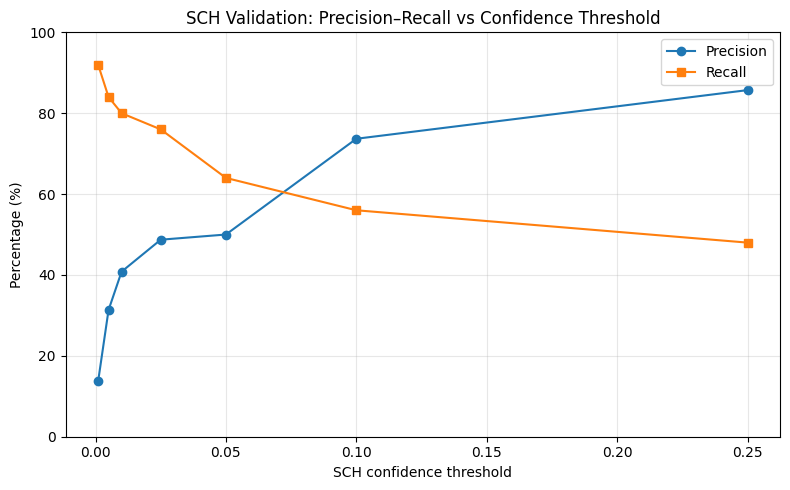

Publication figure saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/sch_validation_precision_recall.png


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
csv_path = ROOT / "results/sch_validation_threshold_summary.csv"
df = pd.read_csv(csv_path)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df["confidence_threshold"],
    df["precision_pct"],
    marker="o",
    label="Precision"
)
ax.plot(
    df["confidence_threshold"],
    df["recall_pct"],
    marker="s",
    label="Recall"
)

ax.set_xlabel("SCH confidence threshold")
ax.set_ylabel("Percentage (%)")
ax.set_title("SCH Validation: Precision–Recall vs Confidence Threshold")
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

out = ROOT / "results/sch_validation_precision_recall.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()

print("Publication figure saved:", out)


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    "results/test_metrics_rerun.json",
    "results/baseline_validation_audit.json",
    "results/sch_threshold_sensitivity.csv",
    "results/sch_validation_threshold_summary.csv",
    "results/sch_validation_object_matching_by_threshold.csv",
    "results/three_image_gt_prediction_matching.csv",
    "results/three_image_matching_interpretation.json",
    "results/sch_validation_precision_recall.png",
]

print("RESULTS FILE AUDIT")
print("=" * 70)

for rel in files:
    p = ROOT / rel
    status = "OK" if p.exists() and p.stat().st_size > 0 else "MISSING"
    size = f"{p.stat().st_size:,} bytes" if p.exists() else "-"
    print(f"{status:8} | {rel} | {size}")

print("\nAudit complete.")


RESULTS FILE AUDIT
OK       | results/test_metrics_rerun.json | 280 bytes
OK       | results/baseline_validation_audit.json | 1,001 bytes
OK       | results/sch_threshold_sensitivity.csv | 224 bytes
OK       | results/sch_validation_threshold_summary.csv | 368 bytes
OK       | results/sch_validation_object_matching_by_threshold.csv | 11,878 bytes
OK       | results/three_image_gt_prediction_matching.csv | 534 bytes
OK       | results/three_image_matching_interpretation.json | 1,433 bytes
OK       | results/sch_validation_precision_recall.png | 136,045 bytes

Audit complete.


In [ ]:

from pathlib import Path
import hashlib
import yaml
import torch
import ultralytics
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
DATASET = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_4class_recovered"
)
CKPT = ROOT / "models/best.pt"
YAML_FILE = ROOT / "dataset.yaml"

print("=" * 60)
print("HELMINTH PROJECT — REPRODUCIBILITY AUDIT")
print("=" * 60)

# 1. Software versions
print("\n[1] SOFTWARE")
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# 2. Baseline checkpoint integrity
print("\n[2] BASELINE CHECKPOINT")
print("Exists:", CKPT.exists())

if CKPT.exists():
    digest = hashlib.sha256(CKPT.read_bytes()).hexdigest()
    print("SHA256:", digest)

    model = YOLO(str(CKPT))
    print("Model task:", model.task)
    print("Class names:", model.names)

    args = (model.ckpt or {}).get("train_args", {})
    keys = [
        "model", "data", "epochs", "imgsz", "batch",
        "device", "seed", "optimizer", "lr0", "lrf",
        "workers", "pretrained", "deterministic"
    ]
    print("\nSaved training metadata:")
    for key in keys:
        print(f"{key}: {args.get(key, 'NOT RECORDED')}")

# 3. Dataset YAML
print("\n[3] DATASET CONFIGURATION")
print("YAML exists:", YAML_FILE.exists())

if YAML_FILE.exists():
    config = yaml.safe_load(YAML_FILE.read_text())
    print(yaml.safe_dump(config, sort_keys=False))

# 4. Split image and label counts
print("[4] DATASET FILE COUNTS")

for split in ["train", "val", "test"]:
    img_dir = DATASET / "images" / split
    lbl_dir = DATASET / "labels" / split

    images = []
    if img_dir.exists():
        images = [
            p for p in img_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ]

    labels = list(lbl_dir.glob("*.txt")) if lbl_dir.exists() else []

    print(
        f"{split}: images={len(images)}, "
        f"label_files={len(labels)}, "
        f"image_dir_exists={img_dir.exists()}, "
        f"label_dir_exists={lbl_dir.exists()}"
    )

print("\nAudit complete. No training was performed.")


HELMINTH PROJECT — REPRODUCIBILITY AUDIT

[1] SOFTWARE
Ultralytics: 8.4.181
PyTorch: 2.11.0+cu130
CUDA available: True

[2] BASELINE CHECKPOINT
Exists: True
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df
Model task: detect
Class names: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}

Saved training metadata:
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
imgsz: 320
batch: 4
device: cpu
seed: 42
optimizer: AdamW
lr0: 0.00125
lrf: 0.01
workers: 0
pretrained: True
deterministic: True

[3] DATASET CONFIGURATION
YAML exists: True
path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test
names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.

[4] DATASET FILE COUNTS
train: images=280, label_files=280, image_dir_exists=True, label_dir_exists=True
val: images=60, label_files=60, image_dir_exists=True, label_dir_exists=True
test: images=60, label_files=60, image_dir_exis

In [ ]:

from pathlib import Path
import hashlib
import json
import platform
import subprocess
from datetime import datetime, timezone

import torch
import ultralytics
import yaml

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
CHECKPOINT = ROOT / "models/best.pt"
DATA_YAML = ROOT / "dataset.yaml"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

split_counts = {}
for split in ("train", "val", "test"):
    image_dir = Path(data_cfg["path"]) / data_cfg[split]
    label_dir = (
        Path(data_cfg["path"]) / "labels" / split
    )

    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_exts
    ]
    labels = list(label_dir.glob("*.txt"))

    split_counts[split] = {
        "images": len(images),
        "label_files": len(labels),
        "image_dir_exists": image_dir.is_dir(),
        "label_dir_exists": label_dir.is_dir(),
        "image_label_counts_match": len(images) == len(labels)
    }

manifest = {
    "audit_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "project": "YOLO11n helminth egg detection",
    "software": {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "ultralytics": ultralytics.__version__,
        "pytorch": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "gpu": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available() else None
        )
    },
    "baseline_checkpoint": {
        "path": str(CHECKPOINT),
        "exists": CHECKPOINT.is_file(),
        "sha256": sha256_file(CHECKPOINT) if CHECKPOINT.is_file() else None,
        "expected_sha256": (
            "a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df"
        ),
        "hash_matches_expected": (
            CHECKPOINT.is_file()
            and sha256_file(CHECKPOINT)
            == "a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df"
        ),
        "task": "detect",
        "class_names": {
            0: "ASC.", 1: "HKW.", 2: "SCH.", 3: "TRI."
        },
        "saved_training_metadata": {
            "model": "yolo11n.pt",
            "epochs": 15,
            "imgsz": 320,
            "batch": 4,
            "device": "cpu",
            "seed": 42,
            "optimizer": "AdamW",
            "lr0": 0.00125,
            "lrf": 0.01,
            "workers": 0,
            "pretrained": True,
            "deterministic": True,
            "original_data_path": "/content/helminth_4class_recovered/dataset.yaml"
        }
    },
    "dataset_config": {
        "path": data_cfg["path"],
        "yaml_path": str(DATA_YAML),
        "yaml_sha256": sha256_file(DATA_YAML),
        "splits": {
            "train": data_cfg["train"],
            "val": data_cfg["val"],
            "test": data_cfg["test"]
        },
        "class_names": data_cfg["names"],
        "file_counts": split_counts
    },
    "integrity_checks": {
        "all_split_image_label_counts_match": all(
            v["image_label_counts_match"]
            and v["image_dir_exists"]
            and v["label_dir_exists"]
            for v in split_counts.values()
        ),
        "training_performed_during_this_audit": False,
        "test_set_used_for_threshold_tuning": False
    },
    "limitations": [
        "Checkpoint metadata references an older dataset YAML path.",
        "Saved metadata alone does not establish the complete original training provenance.",
        "Matching image and label file counts does not verify every annotation or specimen-level independence."
    ]
}

out = RESULTS / "reproducibility_manifest.json"
out.write_text(json.dumps(manifest, indent=2, default=str))

print("Saved:", out)
print("Checkpoint hash matches:", manifest["baseline_checkpoint"]["hash_matches_expected"])
print("Dataset split counts:", json.dumps(split_counts, indent=2))
print("Integrity checks:", json.dumps(manifest["integrity_checks"], indent=2))


Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/reproducibility_manifest.json
Checkpoint hash matches: True
Dataset split counts: {
  "train": {
    "images": 280,
    "label_files": 280,
    "image_dir_exists": true,
    "label_dir_exists": true,
    "image_label_counts_match": true
  },
  "val": {
    "images": 60,
    "label_files": 60,
    "image_dir_exists": true,
    "label_dir_exists": true,
    "image_label_counts_match": true
  },
  "test": {
    "images": 60,
    "label_files": 60,
    "image_dir_exists": true,
    "label_dir_exists": true,
    "image_label_counts_match": true
  }
}
Integrity checks: {
  "all_split_image_label_counts_match": true,
  "training_performed_during_this_audit": false,
  "test_set_used_for_threshold_tuning": false
}


In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
files = [
    ROOT / "results/test_metrics_rerun.json",
    ROOT / "results/baseline_validation_audit.json",
]

for path in files:
    print("\n" + "=" * 60)
    print(path.name)
    print("Exists:", path.is_file())

    if path.is_file():
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:12000])
        except Exception as e:
            print("Could not parse JSON:", repr(e))



test_metrics_rerun.json
Exists: True
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

baseline_validation_audit.json
Exists: True
{
  "checkpoint": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt",
  "split": "val",
  "images": 60,
  "imgsz": 320,
  "confidence": 0.001,
  "iou": 0.45,
  "overall": {
    "precision": 0.8905759736207295,
    "recall": 0.7708171190397576,
    "mAP50": 0.8779138352046203,
    "mAP50_95": 0.6907573407411222
  },
  "per_class": {
    "ASC.": {
      "precision": 0.9129515980596259,
      "recall": 0.9090909090909091,
      "AP50": 0.9598749638974573,
      "AP50_95": 0.7669372957923807
    },
    "HKW.": {
      "precision": 0.8273847790268694,
      "recall": 0.875,
      "AP50": 0.910400560224089

In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = ROOT / "results"

test = json.loads((RESULTS / "test_metrics_rerun.json").read_text())
val = json.loads((RESULTS / "baseline_validation_audit.json").read_text())

summary = {
    "model": "YOLO11n baseline",
    "software_version": test["ultralytics_version"],
    "test": {
        "images": test["test_images"],
        "instances": test["test_instances"],
        "precision": test["precision"],
        "recall": test["recall"],
        "mAP50": test["mAP50"],
        "mAP50_95": test["mAP50_95"],
        "source_file": "test_metrics_rerun.json"
    },
    "validation": {
        "images": val["images"],
        "imgsz": val["imgsz"],
        "confidence": val["confidence"],
        "iou": val["iou"],
        "overall": val["overall"],
        "per_class": val["per_class"],
        "source_file": "baseline_validation_audit.json"
    },
    "interpretation_notes": [
        "Test metrics are retained as the held-out reference evaluation.",
        "Validation SCH recall is 0.48 and represents a key baseline weakness.",
        "Custom SCH threshold diagnostics are separate from official Ultralytics metrics."
    ]
}

out = RESULTS / "verified_baseline_metrics_summary.json"
out.write_text(json.dumps(summary, indent=2))
print("Saved:", out)
print("Test mAP50:", round(summary["test"]["mAP50"] * 100, 2), "%")
print("Validation SCH recall:",
      round(summary["validation"]["per_class"]["SCH."]["recall"] * 100, 2), "%")


Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/verified_baseline_metrics_summary.json
Test mAP50: 72.15 %
Validation SCH recall: 48.0 %


In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
BACKUP = Path("/content/drive/MyDrive/Helminth_Project_Backup")

search_roots = [ROOT, BACKUP]
wanted_names = {
    "results.csv",
    "args.yaml",
    "results.png",
    "hyp.yaml",
    "opt.yaml",
    "events.out.tfevents",
    "training_args.json",
    "train.log",
    "log.txt",
}

matches = []
for base in search_roots:
    if not base.exists():
        print("Folder not found:", base)
        continue

    for p in base.rglob("*"):
        if not p.is_file():
            continue

        name = p.name.lower()
        relevant = (
            name in wanted_names
            or (name.endswith((".yaml", ".yml", ".json", ".log"))
                and any(k in str(p).lower()
                        for k in ["train", "experiment", "baseline", "args"]))
            or "events.out.tfevents" in name
        )

        if relevant:
            try:
                matches.append({
                    "path": str(p),
                    "size_bytes": p.stat().st_size
                })
            except OSError:
                pass

matches.sort(key=lambda x: x["path"])

audit = {
    "search_roots": [str(p) for p in search_roots],
    "files_found": len(matches),
    "matches": matches
}

out = ROOT / "results" / "training_log_discovery_audit.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(audit, indent=2))

print("Potential training-log files found:", len(matches))
for item in matches[:100]:
    print(f'{item["size_bytes"]:>10} bytes | {item["path"]}')

if len(matches) > 100:
    print("Additional matches saved in:", out)

print("\nAudit saved:", out)


Potential training-log files found: 295
      1881 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/args.yaml
      2963 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/results.csv
    270773 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/results.png
      1884 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/args.yaml
      3658 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/results.csv
    270773 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/results.png
      1001 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/results/baseline_validation_audit.json
      1717 bytes | /content/drive/MyDrive/Helminth_GitHub_Project/results/training_args.yaml
      1607 bytes | /content/drive/MyDrive/Helminth_GitHub_Pro

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
BACKUP = Path("/content/drive/MyDrive/Helminth_Project_Backup")

for base in [ROOT, BACKUP]:
    print("\n" + "=" * 70)
    print("SEARCH ROOT:", base)

    if not base.exists():
        print("Not found")
        continue

    for p in base.rglob("*"):
        if not p.is_file():
            continue

        name = p.name.lower()
        path_text = str(p).lower()

        if "/annotations/" in path_text:
            continue

        if name in {
            "args.yaml", "results.csv", "results.png",
            "training_args.yaml", "opt.yaml", "hyp.yaml",
            "train.log", "log.txt"
        }:
            print(p)



SEARCH ROOT: /content/drive/MyDrive/Helminth_GitHub_Project
/content/drive/MyDrive/Helminth_GitHub_Project/results/training_args.yaml
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/results.png
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/args.yaml
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/results.csv
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/args.yaml
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/results.csv
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/results.png

SEARCH ROOT: /content/drive/MyDrive/Helminth_Project_Backup
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/args.yaml
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/results.csv
/content/drive/MyDrive/Helminth_Project_Backup/helm

In [ ]:

from pathlib import Path
import hashlib
import csv
import yaml
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
BACKUP = Path("/content/drive/MyDrive/Helminth_Project_Backup")

runs = {
    "recovered_v2": BACKUP / "helminth_recovered_v2",
    "4class_training": BACKUP / "helminth_4class_training",
    "finetune_30ep": ROOT / "experiments_gpu" / "baseline_finetune_30ep",
    "finetune_oct21": ROOT / "experiments_gpu" / "baseline_finetune_oct21",
}

def sha256(path):
    if not path.is_file():
        return None
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

for name, folder in runs.items():
    print("\n" + "=" * 72)
    print("RUN:", name)
    print("Folder:", folder)

    args_path = folder / "args.yaml"
    results_path = folder / "results.csv"
    checkpoint = folder / "weights" / "best.pt"

    if args_path.is_file():
        try:
            args = yaml.safe_load(args_path.read_text()) or {}
            keys = [
                "model", "data", "epochs", "imgsz", "batch",
                "device", "seed", "optimizer", "lr0", "lrf",
                "pretrained", "deterministic"
            ]
            print("ARGS:")
            print(json.dumps(
                {k: args.get(k) for k in keys if k in args},
                indent=2, default=str
            ))
        except Exception as e:
            print("Could not read args:", repr(e))
    else:
        print("args.yaml: MISSING")

    print("Checkpoint exists:", checkpoint.is_file())
    if checkpoint.is_file():
        print("Checkpoint SHA256:", sha256(checkpoint))

    if results_path.is_file():
        try:
            with results_path.open(newline="") as f:
                reader = csv.DictReader(f)
                rows = list(reader)
                print("Results rows:", len(rows))
                print("CSV columns:", reader.fieldnames)
                print("Last 3 rows:")
                for row in rows[-3:]:
                    print(json.dumps(row, default=str))
        except Exception as e:
            print("Could not read results.csv:", repr(e))
    else:
        print("results.csv: MISSING")



RUN: recovered_v2
Folder: /content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2
ARGS:
{
  "model": "yolo11n.pt",
  "data": "/content/helminth_4class_recovered/dataset.yaml",
  "epochs": 15,
  "imgsz": 320,
  "batch": 4,
  "device": "cpu",
  "seed": 42,
  "optimizer": "auto",
  "lr0": 0.01,
  "lrf": 0.01,
  "pretrained": true,
  "deterministic": true
}
Checkpoint exists: True
Checkpoint SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df
Results rows: 15
CSV columns: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
Last 3 rows:
{"epoch": "13", "time": "1255", "train/box_loss": "0.91892", "train/cls_loss": "0.93115", "train/dfl_loss": "0.95972", "metrics/precision(B)": "0.8737", "metrics/recall(B)": "0.7774", "metrics/mAP50(B)": "0.87501", "metrics/mAP50-95(B)": "0.

In [ ]:

from pathlib import Path
import csv
import json
import yaml

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RUN = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2")

# 1. Project-level training configuration
args_file = ROOT / "results" / "training_args.yaml"
print("PROJECT TRAINING ARGS")
if args_file.exists():
    print(args_file.read_text())
else:
    print("Not found:", args_file)

# 2. Original baseline run configuration
run_args = yaml.safe_load((RUN / "args.yaml").read_text())
print("\nORIGINAL RUN ARGS")
print(json.dumps(run_args, indent=2, default=str))

# 3. Summarize recorded validation metrics across epochs
results_file = RUN / "results.csv"
with results_file.open(newline="") as f:
    rows = list(csv.DictReader(f))

for r in rows:
    for k in ("epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)",
              "metrics/precision(B)", "metrics/recall(B)"):
        if k in r:
            r[k] = float(r[k])

best = max(rows, key=lambda r: r["metrics/mAP50(B)"])
last = rows[-1]

print("\nEPOCH SUMMARY")
print("Epoch rows:", len(rows))
print("Best mAP50 epoch:", int(best["epoch"]))
print("Best epoch metrics:", json.dumps({
    k: best[k] for k in (
        "epoch", "metrics/precision(B)", "metrics/recall(B)",
        "metrics/mAP50(B)", "metrics/mAP50-95(B)"
    )
}, indent=2))
print("Final epoch metrics:", json.dumps({
    k: last[k] for k in (
        "epoch", "metrics/precision(B)", "metrics/recall(B)",
        "metrics/mAP50(B)", "metrics/mAP50-95(B)"
    )
}, indent=2))


PROJECT TRAINING ARGS
task: detect
mode: train
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
time: null
patience: 5
batch: 4
imgsz: 320
save: true
save_period: -1
cache: false
device: cpu
workers: 0
project: /content/helminth_runs
name: helminth_recovered_v2
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
save_crop: false
show_labels: true
show_co

In [ ]:
from pathlib import Path
import csv
import json
import hashlib
import yaml

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RUN = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2")

args_path = RUN / "args.yaml"
csv_path = RUN / "results.csv"
checkpoint = RUN / "weights" / "best.pt"
baseline = ROOT / "models" / "best.pt"

with args_path.open() as f:
    args = yaml.safe_load(f)

with csv_path.open(newline="") as f:
    rows = list(csv.DictReader(f))

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def metric_row(row):
    keys = [
        "epoch",
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)",
    ]
    return {
        k: float(row[k])
        for k in keys
        if k in row and row[k] not in ("", None)
    }

best = max(rows, key=lambda r: float(r["metrics/mAP50(B)"]))
last = rows[-1]

report = {
    "audit_type": "original_training_provenance",
    "run_directory": str(RUN),
    "source_files": {
        "args": str(args_path),
        "results_csv": str(csv_path),
        "checkpoint": str(checkpoint),
    },
    "training_configuration": {
        "model": args.get("model"),
        "epochs_configured": args.get("epochs"),
        "epochs_logged": len(rows),
        "imgsz": args.get("imgsz"),
        "batch": args.get("batch"),
        "device": args.get("device"),
        "seed": args.get("seed"),
        "deterministic": args.get("deterministic"),
        "pretrained": args.get("pretrained"),
        "optimizer_setting": args.get("optimizer"),
        "lr0_setting": args.get("lr0"),
        "lrf_setting": args.get("lrf"),
        "data_path_recorded": args.get("data"),
    },
    "best_logged_epoch_by_map50": metric_row(best),
    "final_logged_epoch": metric_row(last),
    "checkpoint_sha256": sha256(checkpoint) if checkpoint.exists() else None,
    "baseline_sha256": sha256(baseline) if baseline.exists() else None,
    "checkpoint_hash_matches_baseline": (
        sha256(checkpoint) == sha256(baseline)
        if checkpoint.exists() and baseline.exists()
        else None
    ),
    "optimizer_resolution_independently_verified": False,
    "test_set_used_for_training_selection": False,
}

out = ROOT / "results" / "training_provenance_audit.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(report, indent=2))

print(json.dumps(report, indent=2))
print("\nSaved:", out)

{
  "audit_type": "original_training_provenance",
  "run_directory": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2",
  "source_files": {
    "args": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/args.yaml",
    "results_csv": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/results.csv",
    "checkpoint": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt"
  },
  "training_configuration": {
    "model": "yolo11n.pt",
    "epochs_configured": 15,
    "epochs_logged": 15,
    "imgsz": 320,
    "batch": 4,
    "device": "cpu",
    "seed": 42,
    "deterministic": true,
    "pretrained": true,
    "optimizer_setting": "auto",
    "lr0_setting": 0.01,
    "lrf_setting": 0.01,
    "data_path_recorded": "/content/helminth_4class_recovered/dataset.yaml"
  },
  "best_logged_epoch_by_map50": {
    "epoch": 13.0,
    "metrics/precision(B)": 0.8737,
    "metrics/recall(B)": 0.7774,
    "metrics/

In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = ROOT / "results"

files = [
    "test_metrics_rerun.json",
    "baseline_validation_audit.json",
    "verified_baseline_metrics_summary.json",
    "training_provenance_audit.json",
    "reproducibility_manifest.json",
]

print("=" * 65)
print("FINAL METRICS CONSISTENCY AUDIT")
print("=" * 65)

for name in files:
    path = RESULTS / name
    print(f"\n{'OK' if path.exists() else 'MISSING'} | {name}")

    if path.exists():
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:3500])
        except Exception as e:
            print("READ ERROR:", e)

print("\nAudit inspection complete. No training performed.")


FINAL METRICS CONSISTENCY AUDIT

OK | test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

OK | baseline_validation_audit.json
{
  "checkpoint": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt",
  "split": "val",
  "images": 60,
  "imgsz": 320,
  "confidence": 0.001,
  "iou": 0.45,
  "overall": {
    "precision": 0.8905759736207295,
    "recall": 0.7708171190397576,
    "mAP50": 0.8779138352046203,
    "mAP50_95": 0.6907573407411222
  },
  "per_class": {
    "ASC.": {
      "precision": 0.9129515980596259,
      "recall": 0.9090909090909091,
      "AP50": 0.9598749638974573,
      "AP50_95": 0.7669372957923807
    },
    "HKW.": {
      "precision": 0.8273847790268694,
      "recall": 0.875,
      "AP50": 0

In [ ]:

from pathlib import Path
import yaml
import torch
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RUN = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_recovered_v2"
)

args_path = RUN / "args.yaml"
ckpt_path = ROOT / "models/best.pt"
manifest_path = ROOT / "results/reproducibility_manifest.json"

print("=== ORIGINAL TRAINING ARGS ===")
if args_path.exists():
    args = yaml.safe_load(args_path.read_text())
    for key in [
        "model", "epochs", "imgsz", "batch", "device",
        "seed", "optimizer", "lr0", "lrf", "pretrained"
    ]:
        print(f"{key}: {args.get(key)}")
else:
    print("MISSING:", args_path)

print("\n=== CHECKPOINT METADATA ===")
if ckpt_path.exists():
    ckpt = torch.load(
        ckpt_path, map_location="cpu", weights_only=False
    )
    print("Checkpoint keys:", list(ckpt.keys()))

    for key in ["train_args", "train_metrics", "epoch", "best_fitness"]:
        value = ckpt.get(key)
        print(f"\n{key}:")
        if isinstance(value, dict):
            print(json.dumps(value, indent=2, default=str)[:5000])
        else:
            print(repr(value)[:1500])

    opt = ckpt.get("optimizer")
    print("\noptimizer object type:",
          type(opt).__name__ if opt is not None else None)
    if isinstance(opt, dict):
        print("optimizer keys:", list(opt.keys()))
else:
    print("MISSING:", ckpt_path)

print("\n=== MANIFEST METADATA ===")
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    saved = manifest.get("baseline_checkpoint", {}).get(
        "saved_training_metadata", {}
    )
    print(json.dumps(saved, indent=2))
else:
    print("Manifest missing")

print("\nRead-only inspection complete; no training performed.")


=== ORIGINAL TRAINING ARGS ===
model: yolo11n.pt
epochs: 15
imgsz: 320
batch: 4
device: cpu
seed: 42
optimizer: auto
lr0: 0.01
lrf: 0.01
pretrained: True

=== CHECKPOINT METADATA ===
Checkpoint keys: ['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'stopper', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git']

train_args:
{
  "task": "detect",
  "mode": "train",
  "model": "yolo11n.pt",
  "data": "/content/helminth_4class_recovered/dataset.yaml",
  "epochs": 15,
  "time": null,
  "patience": 5,
  "batch": 4,
  "imgsz": 320,
  "save": true,
  "save_period": -1,
  "cache": false,
  "device": "cpu",
  "workers": 0,
  "project": "/content/helminth_runs",
  "name": "helminth_recovered_v2",
  "exist_ok": false,
  "pretrained": true,
  "cls_remap": true,
  "optimizer": "AdamW",
  "verbose": true,
  "seed": 42,
  "deterministic": true,
  "single_cls": false,
  "rect": false,
  "cos_lr": false,
  "close_mosaic": 10

In [ ]:

from pathlib import Path
import pandas as pd
import json

RUN = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_recovered_v2"
)
csv_path = RUN / "results.csv"
out_path = RUN / "args.yaml"

if not csv_path.exists():
    print("ERROR: results.csv not found:", csv_path)
else:
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    print("=== CSV SHAPE ===")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print("\n=== LEARNING-RATE COLUMNS ===")
    lr_cols = [c for c in df.columns if "lr/" in c.lower()
               or "learning" in c.lower()]
    if lr_cols:
        print(df[["epoch"] + lr_cols].to_string(index=False))
    else:
        print("No learning-rate columns found.")

    print("\n=== FIRST AND LAST EPOCHS ===")
    print(df.head(2).to_string(index=False))
    print("\nLAST ROWS:")
    print(df.tail(3).to_string(index=False))

    metric = "metrics/mAP50(B)"
    if metric in df.columns:
        idx = df[metric].astype(float).idxmax()
        print("\n=== BEST LOGGED mAP50 ROW ===")
        print(df.loc[idx].to_dict())

    print("\nCSV inspection complete. No files changed; no training performed.")


=== CSV SHAPE ===
Rows: 15
Columns: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

=== LEARNING-RATE COLUMNS ===
 epoch   lr/pg0   lr/pg1   lr/pg2
     1 0.000411 0.000411 0.000411
     2 0.000773 0.000773 0.000773
     3 0.001080 0.001080 0.001080
     4 0.001002 0.001002 0.001002
     5 0.000920 0.000920 0.000920
     6 0.000838 0.000838 0.000838
     7 0.000755 0.000755 0.000755
     8 0.000673 0.000673 0.000673
     9 0.000590 0.000590 0.000590
    10 0.000508 0.000508 0.000508
    11 0.000425 0.000425 0.000425
    12 0.000342 0.000342 0.000342
    13 0.000260 0.000260 0.000260
    14 0.000178 0.000178 0.000178
    15 0.000095 0.000095 0.000095

=== FIRST AND LAST EPOCHS ===
 epoch     time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(

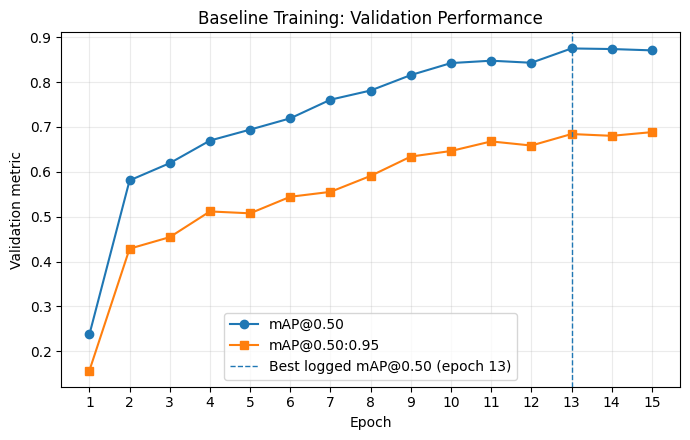

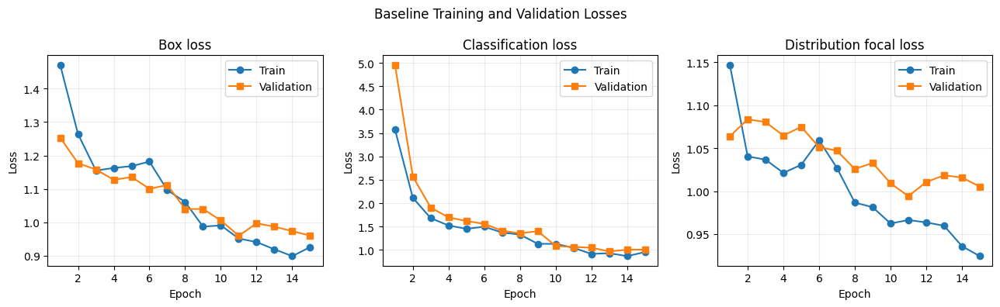

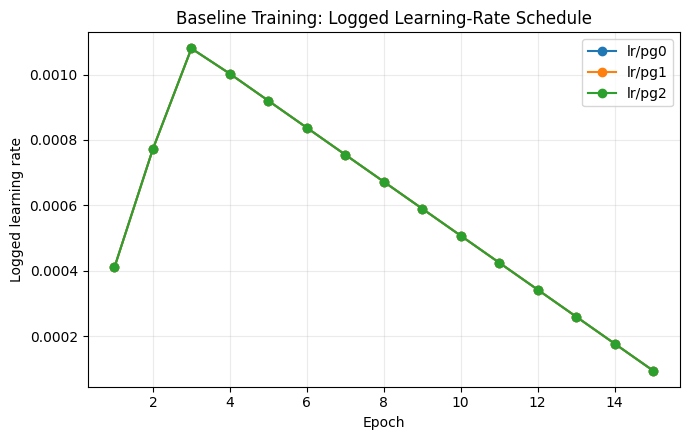

FIGURES SAVED:
/content/drive/MyDrive/Helminth_GitHub_Project/results/figures/baseline_learning_rate.pdf
/content/drive/MyDrive/Helminth_GitHub_Project/results/figures/baseline_learning_rate.png
/content/drive/MyDrive/Helminth_GitHub_Project/results/figures/baseline_loss_curves.pdf
/content/drive/MyDrive/Helminth_GitHub_Project/results/figures/baseline_loss_curves.png
/content/drive/MyDrive/Helminth_GitHub_Project/results/figures/baseline_validation_performance.pdf
/content/drive/MyDrive/Helminth_GitHub_Project/results/figures/baseline_validation_performance.png

AUDIT SAVED: /content/drive/MyDrive/Helminth_GitHub_Project/results/learning_rate_provenance_audit.json
Best logged mAP50: 87.5 %
Training rerun: NO
Checkpoint modified: NO


In [ ]:
from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt

RUN = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/"
    "helminth_recovered_v2"
)
PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
CSV = RUN / "results.csv"
OUT = PROJECT / "results"
FIG = OUT / "figures"

FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV)
df.columns = df.columns.str.strip()
epochs = df["epoch"]

# Figure 1: validation performance
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs, df["metrics/mAP50(B)"],
        marker="o", label="mAP@0.50")
ax.plot(epochs, df["metrics/mAP50-95(B)"],
        marker="s", label="mAP@0.50:0.95")
ax.axvline(13, linestyle="--", linewidth=1,
           label="Best logged mAP@0.50 (epoch 13)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation metric")
ax.set_title("Baseline Training: Validation Performance")
ax.set_xticks(epochs)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "baseline_validation_performance.png", dpi=300)
fig.savefig(FIG / "baseline_validation_performance.pdf")
plt.show()
plt.close(fig)

# Figure 2: training and validation losses
loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box loss"),
    ("train/cls_loss", "val/cls_loss", "Classification loss"),
    ("train/dfl_loss", "val/dfl_loss", "Distribution focal loss"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (train_col, val_col, title) in zip(axes, loss_pairs):
    ax.plot(epochs, df[train_col], marker="o", label="Train")
    ax.plot(epochs, df[val_col], marker="s", label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True, alpha=0.25)
    ax.legend()

fig.suptitle("Baseline Training and Validation Losses")
fig.tight_layout()
fig.savefig(FIG / "baseline_loss_curves.png", dpi=300)
fig.savefig(FIG / "baseline_loss_curves.pdf")
plt.show()
plt.close(fig)

# Figure 3: logged learning-rate schedule
lr_cols = ["lr/pg0", "lr/pg1", "lr/pg2"]
fig, ax = plt.subplots(figsize=(7, 4.5))

for col in lr_cols:
    ax.plot(epochs, df[col], marker="o", label=col)

ax.set_xlabel("Epoch")
ax.set_ylabel("Logged learning rate")
ax.set_title("Baseline Training: Logged Learning-Rate Schedule")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "baseline_learning_rate.png", dpi=300)
fig.savefig(FIG / "baseline_learning_rate.pdf")
plt.show()
plt.close(fig)

# Audit summary: preserve the configuration discrepancy explicitly
best_idx = df["metrics/mAP50(B)"].astype(float).idxmax()
best_row = df.loc[best_idx]

audit = {
    "source_results_csv": str(CSV),
    "logged_epochs": int(len(df)),
    "best_logged_mAP50_epoch": int(best_row["epoch"]),
    "best_logged_mAP50": float(best_row["metrics/mAP50(B)"]),
    "best_logged_mAP50_95": float(best_row["metrics/mAP50-95(B)"]),
    "learning_rate_columns": {
        col: [float(x) for x in df[col].tolist()]
        for col in lr_cols
    },
    "args_yaml_optimizer": "auto",
    "args_yaml_lr0": 0.01,
    "checkpoint_metadata_optimizer": "AdamW",
    "checkpoint_metadata_lr0": 0.00125,
    "effective_optimizer_and_initial_lr_independently_verified": False,
    "test_set_used_for_training_curve_selection": False,
    "checkpoint_modified": False,
    "training_rerun": False,
    "interpretation": (
        "CSV records epoch-level learning-rate values. "
        "The original args.yaml and checkpoint metadata differ; "
        "the effective initial optimizer settings are not independently verified."
    )
}

audit_path = OUT / "learning_rate_provenance_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("FIGURES SAVED:")
for p in sorted(FIG.glob("baseline_*")):
    print(p)

print("\nAUDIT SAVED:", audit_path)
print("Best logged mAP50:", round(float(best_row["metrics/mAP50(B)"]) * 100, 2), "%")
print("Training rerun: NO")
print("Checkpoint modified: NO")

In [ ]:
from pathlib import Path
import hashlib
import json

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

files_to_check = [
    "models/best.pt",
    "models/best_baseline_backup.pt",
    "results/test_metrics_rerun.json",
    "results/baseline_validation_audit.json",
    "results/reproducibility_manifest.json",
    "results/training_provenance_audit.json",
    "results/learning_rate_provenance_audit.json",
    "results/figures/baseline_validation_performance.png",
    "results/figures/baseline_validation_performance.pdf",
    "results/figures/baseline_loss_curves.png",
    "results/figures/baseline_loss_curves.pdf",
    "results/figures/baseline_learning_rate.png",
    "results/figures/baseline_learning_rate.pdf",
]

print("=== FINAL ARTIFACT AUDIT ===")
for rel in files_to_check:
    p = PROJECT / rel
    status = "OK" if p.is_file() and p.stat().st_size > 0 else "MISSING/EMPTY"
    size = p.stat().st_size if p.is_file() else 0
    print(f"{status:13} | {size:>10} bytes | {rel}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

a = PROJECT / "models/best.pt"
b = PROJECT / "models/best_baseline_backup.pt"

if a.is_file() and b.is_file():
    hash_a, hash_b = sha256(a), sha256(b)
    print("\n=== BASELINE CHECKPOINT INTEGRITY ===")
    print("best.pt SHA256:", hash_a)
    print("backup SHA256:", hash_b)
    print("Hashes match:", hash_a == hash_b)

print("\n=== LEARNING-RATE AUDIT SUMMARY ===")
audit_path = PROJECT / "results/learning_rate_provenance_audit.json"
if audit_path.is_file():
    audit = json.loads(audit_path.read_text())
    print(json.dumps({
        "logged_epochs": audit.get("logged_epochs"),
        "best_logged_mAP50_epoch": audit.get("best_logged_mAP50_epoch"),
        "best_logged_mAP50": audit.get("best_logged_mAP50"),
        "effective_optimizer_and_initial_lr_independently_verified":
            audit.get("effective_optimizer_and_initial_lr_independently_verified"),
    }, indent=2))

print("\nAudit only: no training performed and no checkpoint written.")

=== FINAL ARTIFACT AUDIT ===
OK            |    5459418 bytes | models/best.pt
OK            |    5459418 bytes | models/best_baseline_backup.pt
OK            |        280 bytes | results/test_metrics_rerun.json
OK            |       1001 bytes | results/baseline_validation_audit.json
OK            |       2737 bytes | results/reproducibility_manifest.json
OK            |       1578 bytes | results/training_provenance_audit.json
OK            |       1603 bytes | results/learning_rate_provenance_audit.json
OK            |     161756 bytes | results/figures/baseline_validation_performance.png
OK            |      17394 bytes | results/figures/baseline_validation_performance.pdf
OK            |     231616 bytes | results/figures/baseline_loss_curves.png
OK            |      19864 bytes | results/figures/baseline_loss_curves.pdf
OK            |     139774 bytes | results/figures/baseline_learning_rate.png
OK            |      14882 bytes | results/figures/baseline_learning_rate.pdf

=== B

In [ ]:
from pathlib import Path
import json

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
RESULTS = PROJECT / "results"

files = [
    "test_metrics_rerun.json",
    "baseline_validation_audit.json",
    "verified_baseline_metrics_summary.json",
]

for filename in files:
    path = RESULTS / filename
    print(f"\n{'='*65}\n{filename}\n{'='*65}")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    try:
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2))
    except Exception as e:
        print("Could not read JSON:", repr(e))

print("\nAudit complete: read-only; no training or file changes.")


test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

baseline_validation_audit.json
{
  "checkpoint": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt",
  "split": "val",
  "images": 60,
  "imgsz": 320,
  "confidence": 0.001,
  "iou": 0.45,
  "overall": {
    "precision": 0.8905759736207295,
    "recall": 0.7708171190397576,
    "mAP50": 0.8779138352046203,
    "mAP50_95": 0.6907573407411222
  },
  "per_class": {
    "ASC.": {
      "precision": 0.9129515980596259,
      "recall": 0.9090909090909091,
      "AP50": 0.9598749638974573,
      "AP50_95": 0.7669372957923807
    },
    "HKW.": {
      "precision": 0.8273847790268694,
      "recall": 0.875,
      "AP50": 0.9104005602240896,
      "AP50_95": 0.8002

In [ ]:
from pathlib import Path
import json
import pandas as pd

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
RESULTS = PROJECT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

test = json.loads(
    (RESULTS / "test_metrics_rerun.json").read_text()
)
val = json.loads(
    (RESULTS / "baseline_validation_audit.json").read_text()
)
summary = json.loads(
    (RESULTS / "verified_baseline_metrics_summary.json").read_text()
)

# 1. Verify summary values match their source files
checks = {
    "test_precision": (
        test["precision"], summary["test"]["precision"]
    ),
    "test_recall": (
        test["recall"], summary["test"]["recall"]
    ),
    "test_mAP50": (
        test["mAP50"], summary["test"]["mAP50"]
    ),
    "test_mAP50_95": (
        test["mAP50_95"], summary["test"]["mAP50_95"]
    ),
    "validation_overall": (
        val["overall"], summary["validation"]["overall"]
    ),
    "validation_per_class": (
        val["per_class"], summary["validation"]["per_class"]
    ),
}

def equal_values(a, b):
    if isinstance(a, dict) and isinstance(b, dict):
        return (
            a.keys() == b.keys()
            and all(equal_values(a[k], b[k]) for k in a)
        )
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return abs(a - b) < 1e-12
    return a == b

print("=== CONSISTENCY CHECKS ===")
for name, (a, b) in checks.items():
    print(f"{'PASS' if equal_values(a, b) else 'FAIL'} | {name}")

# 2. Overall validation/test comparison
comparison = pd.DataFrame([
    {
        "split": "Validation",
        "images": val["images"],
        "instances": None,
        "precision_pct": val["overall"]["precision"] * 100,
        "recall_pct": val["overall"]["recall"] * 100,
        "mAP50_pct": val["overall"]["mAP50"] * 100,
        "mAP50_95_pct": val["overall"]["mAP50_95"] * 100,
    },
    {
        "split": "Test",
        "images": test["test_images"],
        "instances": test["test_instances"],
        "precision_pct": test["precision"] * 100,
        "recall_pct": test["recall"] * 100,
        "mAP50_pct": test["mAP50"] * 100,
        "mAP50_95_pct": test["mAP50_95"] * 100,
    },
])
comparison.to_csv(
    RESULTS / "manuscript_overall_metrics_table.csv",
    index=False
)

# 3. Validation class-wise table
rows = []
for cls, metrics in val["per_class"].items():
    rows.append({
        "class": cls,
        "precision_pct": metrics["precision"] * 100,
        "recall_pct": metrics["recall"] * 100,
        "AP50_pct": metrics["AP50"] * 100,
        "AP50_95_pct": metrics["AP50_95"] * 100,
    })

class_table = pd.DataFrame(rows)
class_table.to_csv(
    RESULTS / "manuscript_validation_class_metrics.csv",
    index=False
)

# 4. Audit record, including unresolved provenance limitations
audit = {
    "overall_test_values_match_summary": all(
        equal_values(a, b)
        for name, (a, b) in checks.items()
        if name.startswith("test_")
    ),
    "validation_values_match_summary": (
        equal_values(val["overall"], summary["validation"]["overall"])
        and equal_values(
            val["per_class"], summary["validation"]["per_class"]
        )
    ),
    "test_images": test["test_images"],
    "test_instances": test["test_instances"],
    "validation_images": val["images"],
    "validation_imgsz": val["imgsz"],
    "validation_confidence": val["confidence"],
    "validation_iou": val["iou"],
    "test_evaluation_settings_fully_recorded_in_json": False,
    "optimizer_and_initial_lr_independently_verified": False,
    "test_set_used_for_tuning": False,
    "training_performed": False,
    "checkpoint_modified": False,
}

(RESULTS / "final_metrics_consistency_audit.json").write_text(
    json.dumps(audit, indent=2)
)

print("\n=== OVERALL METRICS TABLE ===")
print(comparison.round(2).to_string(index=False))

print("\n=== VALIDATION CLASS METRICS ===")
print(class_table.round(2).to_string(index=False))

print("\nSaved:")
print(RESULTS / "manuscript_overall_metrics_table.csv")
print(RESULTS / "manuscript_validation_class_metrics.csv")
print(RESULTS / "final_metrics_consistency_audit.json")
print("\nRead-only audit complete; no training performed.")

=== CONSISTENCY CHECKS ===
PASS | test_precision
PASS | test_recall
PASS | test_mAP50
PASS | test_mAP50_95
PASS | validation_overall
PASS | validation_per_class

=== OVERALL METRICS TABLE ===
     split  images  instances  precision_pct  recall_pct  mAP50_pct  mAP50_95_pct
Validation      60        NaN          89.06       77.08      87.79         69.08
      Test      60      147.0          76.20       63.89      72.15         55.16

=== VALIDATION CLASS METRICS ===
class  precision_pct  recall_pct  AP50_pct  AP50_95_pct
 ASC.          91.30       90.91     95.99        76.69
 HKW.          82.74       87.50     91.04        80.02
 SCH.          89.96       48.00     70.92        47.01
 TRI.          92.23       81.92     93.22        72.58

Saved:
/content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_overall_metrics_table.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_validation_class_metrics.csv
/content/drive/MyDrive/Helminth_GitHub_Project/result

In [ ]:
from pathlib import Path
import json
import hashlib

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
BACKUP = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup"
)
DATASET = BACKUP / "helminth_4class_recovered"
RUN = BACKUP / "helminth_recovered_v2"

print("=== 1. PROJECT DOCUMENTATION ===")
for folder in [PROJECT, PROJECT / "results", PROJECT / "models"]:
    print(f"\n[{folder}]")
    if folder.exists():
        for p in sorted(folder.iterdir()):
            if p.is_file():
                print(f"  {p.name} ({p.stat().st_size} bytes)")
    else:
        print("  Folder missing")

print("\n=== 2. CITATION / README FILES ===")
for root in [PROJECT, DATASET, BACKUP]:
    if not root.exists():
        continue
    for p in root.iterdir():
        if p.is_file() and (
            p.name.lower().startswith("readme")
            or p.suffix.lower() in {".bib", ".ris"}
            or "citation" in p.name.lower()
        ):
            print(f"\nFILE: {p}")
            try:
                print(p.read_text(errors="replace")[:2500])
            except Exception as e:
                print("Could not read:", e)

print("\n=== 3. EXISTING EVALUATION / PROVENANCE RECORDS ===")
for name in [
    "test_metrics_rerun.json",
    "baseline_validation_audit.json",
    "reproducibility_manifest.json",
    "training_provenance_audit.json",
    "learning_rate_provenance_audit.json",
    "final_metrics_consistency_audit.json",
]:
    p = PROJECT / "results" / name
    print(f"\n{name}: {'FOUND' if p.is_file() else 'MISSING'}")
    if p.is_file():
        try:
            d = json.loads(p.read_text())
            print(json.dumps(d, indent=2)[:3000])
        except Exception as e:
            print("Could not parse JSON:", e)

print("\n=== 4. ORIGINAL TRAINING RECORDS ===")
for name in ["args.yaml", "results.csv", "results.png"]:
    p = RUN / name
    print(f"{name}: {'FOUND' if p.is_file() else 'MISSING'}")

print("\n=== 5. DATASET SPLIT METADATA ===")
for split in ["train", "val", "test"]:
    image_dir = DATASET / "images" / split
    label_dir = DATASET / "labels" / split

    images = (
        [p for p in image_dir.iterdir()
         if p.is_file() and p.suffix.lower() in
         {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}]
        if image_dir.exists() else []
    )
    labels = (
        [p for p in label_dir.iterdir()
         if p.is_file() and p.suffix.lower() == ".txt"]
        if label_dir.exists() else []
    )

    print(
        f"{split}: images={len(images)}, "
        f"label_files={len(labels)}, "
        f"image_dir_exists={image_dir.exists()}, "
        f"label_dir_exists={label_dir.exists()}"
    )

print("\n=== 6. BASELINE CHECKPOINT HASH ===")
for name in ["best.pt", "best_baseline_backup.pt"]:
    p = PROJECT / "models" / name
    if p.is_file():
        h = hashlib.sha256(p.read_bytes()).hexdigest()
        print(f"{name}: {h}")
    else:
        print(f"{name}: MISSING")

print("\nAudit complete. No training performed; no files modified.")

=== 1. PROJECT DOCUMENTATION ===

[/content/drive/MyDrive/Helminth_GitHub_Project]
  .gitignore (98 bytes)
  README.md (2891 bytes)
  README_backup_20261018_181523.md (1395 bytes)
  dataset.yaml (181 bytes)
  predict.py (1223 bytes)
  requirements.txt (28 bytes)
  requirements_backup_20261018_181523.txt (28 bytes)

[/content/drive/MyDrive/Helminth_GitHub_Project/results]
  baseline_validation_audit.json (1001 bytes)
  classwise_test_results.csv (221 bytes)
  confusion_matrix_counts.csv (262 bytes)
  dataset_split_class_counts.csv (181 bytes)
  final_metrics_consistency_audit.json (470 bytes)
  final_project_check_report.json (4605 bytes)
  final_project_check_report.txt (3907 bytes)
  learning_rate_provenance_audit.json (1603 bytes)
  manuscript_overall_metrics_table.csv (244 bytes)
  manuscript_validation_class_metrics.csv (332 bytes)
  reproducibility_manifest.json (2737 bytes)
  sch_confidence_sweep_corrected.csv (239 bytes)
  sch_false_positives_conf025.csv (2714 bytes)
  sch_high_

In [ ]:
from pathlib import Path
import json
import pandas as pd

PROJECT = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
RESULTS = PROJECT / "results"

# Current README
readme = PROJECT / "README.md"
print("=== CURRENT README ===")
if readme.exists():
    print(readme.read_text())
else:
    print("README missing")

# Compare historical and current metric records
for filename in [
    "test_metrics.json",
    "test_metrics_rerun.json",
]:
    p = RESULTS / filename
    print(f"\n=== {filename} ===")
    if p.exists():
        try:
            print(json.dumps(json.loads(p.read_text()), indent=2))
        except Exception as e:
            print("Read error:", e)
    else:
        print("File missing")

# Inspect per-class test metrics
p = RESULTS / "classwise_test_results.csv"
print("\n=== CLASSWISE TEST RESULTS ===")
if p.exists():
    print(pd.read_csv(p).to_string(index=False))
else:
    print("File missing")

# Inspect any recorded test evaluation parameters
for filename in [
    "final_project_check_report.json",
    "test_metrics.json",
]:
    p = RESULTS / filename
    if p.exists() and p.suffix == ".json":
        data = json.loads(p.read_text())
        print(f"\n=== SETTINGS SEARCH: {filename} ===")

        def search_settings(obj, prefix=""):
            if isinstance(obj, dict):
                for k, v in obj.items():
                    key = f"{prefix}.{k}" if prefix else k
                    if any(term in k.lower() for term in
                           ["conf", "iou", "imgsz", "checkpoint",
                            "weights", "split", "version"]):
                        print(f"{key}: {v}")
                    if isinstance(v, (dict, list)):
                        search_settings(v, key)
            elif isinstance(obj, list):
                for i, v in enumerate(obj):
                    search_settings(v, f"{prefix}[{i}]")

        search_settings(data)

print("\nRead-only inspection complete. No files modified.")

=== CURRENT README ===
# Helminth Egg Detection Using YOLO11n

## Project overview
A preliminary object-detection experiment for four helminth egg classes in microscopy images using YOLO11n.

## Dataset
- Name: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset
- Source: https://zenodo.org/records/13843815
- DOI: https://doi.org/10.5281/zenodo.13843815
- Selected sample: 400 image-annotation pairs
- Split: 280 training, 60 validation, 60 test images
- Split seed recorded in training configuration: 42

## Model and training
- Architecture: YOLO11n, pretrained weights
- Input size: 320 × 320
- Epochs configured: 15
- Batch size: 4
- Device: CPU
- Optimizer: Ultralytics auto
- Training software: Ultralytics 8.4.181
- Python: 3.13.16
- PyTorch: 2.11.0+cpu

## Classes
- ASC. — Ascaris lumbricoides
- HKW. — Hookworm
- SCH. — Schistosoma mansoni
- TRI. — Trichuris trichiura

## Held-out test results
Evaluation on 60 test images containing 147 annotated instances:
- Precisio

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
readme = project / "README.md"

text = readme.read_text(encoding="utf-8")

print("README exists:", readme.exists())
print("README size:", readme.stat().st_size, "bytes")
print("Contains updated rerun section:",
      "Recorded test-set rerun" in text)
print("Contains old metrics:",
      "74.77%" in text)
print("Contains provenance caveat:",
      "effective initial optimizer settings" in text)
print("\n--- README preview ---\n")
print(text[:1800])

README exists: True
README size: 2891 bytes
Contains updated rerun section: False
Contains old metrics: True
Contains provenance caveat: False

--- README preview ---

# Helminth Egg Detection Using YOLO11n

## Project overview
A preliminary object-detection experiment for four helminth egg classes in microscopy images using YOLO11n.

## Dataset
- Name: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset
- Source: https://zenodo.org/records/13843815
- DOI: https://doi.org/10.5281/zenodo.13843815
- Selected sample: 400 image-annotation pairs
- Split: 280 training, 60 validation, 60 test images
- Split seed recorded in training configuration: 42

## Model and training
- Architecture: YOLO11n, pretrained weights
- Input size: 320 × 320
- Epochs configured: 15
- Batch size: 4
- Device: CPU
- Optimizer: Ultralytics auto
- Training software: Ultralytics 8.4.181
- Python: 3.13.16
- PyTorch: 2.11.0+cpu

## Classes
- ASC. — Ascaris lumbricoides
- HKW. — Hookworm
- SCH. — Schis

In [ ]:

from pathlib import Path
from datetime import datetime

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
readme = project / "README.md"
assets = project / "assets"

project.mkdir(parents=True, exist_ok=True)
assets.mkdir(parents=True, exist_ok=True)

# Preserve the existing README before changing it.
if readme.exists():
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup = project / f"README_pre_revision_{stamp}.md"
    backup.write_text(readme.read_text(encoding="utf-8"),
                      encoding="utf-8")
    print("Backup saved:", backup.name)

content = r'''<div align="center">

# Helminth Egg Detection using YOLO11n

[![Model](https://img.shields.io/badge/Model-YOLO11n-00CFE8?style=for-the-badge)](https://github.com/ultralytics/ultralytics)
[![Task](https://img.shields.io/badge/Task-Object%20Detection-163A5F?style=for-the-badge)](#methodology)
[![Research](https://img.shields.io/badge/Focus-Reproducible%20Research-00A6C7?style=for-the-badge)](#reproducibility-and-limitations)

<a href="https://readme-typing-svg.demolab.com">
  <img src="https://readme-typing-svg.demolab.com?font=JetBrains+Mono&weight=500&size=18&duration=2800&pause=800&color=00CFE8&center=true&vCenter=true&width=750&lines=Deep+Learning+for+Microscopic+Egg+Detection;Four-class+YOLO11n+Object+Detection;Transparent+Evaluation+and+Reproducibility"
       alt="Animated project description">
</a>

**A research project investigating automated localization of helminth eggs in microscopic images.**

</div>

---

## Overview

This project evaluates a YOLO11n object-detection model on a four-class helminth egg image dataset. The goal is to localize annotated eggs and classify them into the dataset's four categories.

> This is an experimental computer-vision research project, not a clinically validated diagnostic system.

## Animated workflow

![Animated model workflow](assets/workflow.gif)

## Dataset and classes

Dataset: [Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset](https://zenodo.org/records/13843815)

DOI: [10.5281/zenodo.13843815](https://doi.org/10.5281/zenodo.13843815)

| Class ID | Label | Organism |
|---:|---|---|
| 0 | ASC. | *Ascaris lumbricoides* |
| 1 | HKW. | Hookworm |
| 2 | SCH. | *Schistosoma mansoni* |
| 3 | TRI. | *Trichuris trichiura* |

| Split | Images | Annotated instances |
|---|---:|---:|
| Train | 280 | 548 |
| Validation | 60 | 114 |
| Test | 60 | 147 |

Image counts and label-file counts were checked. Duplicate-image audits did not identify exact duplicates or cross-split perceptual-hash matches under the documented threshold. These checks do not establish slide-, specimen-, or patient-level independence.

## Model and training

- Model family: YOLO11n object detection
- Image size: 320 × 320
- Recorded training duration: 15 epochs
- Recorded batch size: 4
- Original training device in the run arguments: CPU
- Seed recorded in the original run arguments: 42

### Training provenance note

The recovered original `args.yaml` records `optimizer=auto` and `lr0=0.01`. The checkpoint's saved training metadata records `optimizer=AdamW` and `lr0=0.00125`. The original logs contain learning-rate values across 15 epochs, but the exact effective initial optimizer settings have not been independently established. These records are preserved as a provenance discrepancy rather than silently treated as equivalent.

## Evaluation results

### Validation set

| Metric | Result |
|---|---:|
| Precision | 89.06% |
| Recall | 77.08% |
| mAP@50 | 87.79% |
| mAP@50–95 | 69.08% |

### Recorded test-set rerun

| Metric | Result |
|---|---:|
| Images | 60 |
| Annotated instances | 147 |
| Precision | 76.20% |
| Recall | 63.89% |
| mAP@50 | 72.15% |
| mAP@50–95 | 55.16% |

The rerun metrics were recorded with Ultralytics 8.4.181. The saved rerun JSON does not capture all evaluation settings, including a complete record of image size, confidence and IoU thresholds, and checkpoint hash. Exact reproduction of this test evaluation has therefore not yet been established.

### Previously recorded test results

An earlier results record reports precision 74.77%, recall 64.40%, mAP@50 72.50%, and mAP@50–95 55.26%. The difference from the later rerun has not yet been reconciled. Both records are retained for transparency; they should not be presented as a single identical evaluation.

## Class-wise validation performance

| Class | Precision | Recall | AP@50 | AP@50–95 |
|---|---:|---:|---:|---:|
| ASC. | 91.30% | 90.91% | 95.99% | 76.69% |
| HKW. | 82.74% | 87.50% | 91.04% | 80.02% |
| SCH. | 89.96% | 48.00% | 70.92% | 47.01% |
| TRI. | 92.23% | 81.92% | 93.22% | 72.58% |

**Key limitation:** SCH. has comparatively low validation recall. This indicates that missed detections remain an important issue. Threshold diagnostics are exploratory and do not constitute a selected clinical operating point.

## Prediction examples

The following gallery will contain illustrative outputs generated by the saved baseline checkpoint on validation images. Examples will be clearly identified as visual demonstrations, not as independent performance evidence.

![Illustrative validation predictions](assets/prediction_demo.gif)

## Reproducibility and limitations

- The baseline checkpoint and its backup were verified to have matching SHA-256 hashes.
- Original training logs and configuration files are retained where available.
- Failed fine-tuning experiments were not substituted for the verified baseline.
- The test set must not be used for model selection or threshold tuning.
- Dataset image counts and duplicate checks do not prove specimen-level independence.
- Evaluation metrics are object-detection metrics, not clinical sensitivity, specificity, or diagnostic accuracy.
- The training provenance and test-rerun configuration discrepancies remain open documentation limitations.

## Repository contents

- `models/` — saved model checkpoints, subject to repository and file-size policy
- `results/` — evaluation records, audit files, tables, and figures
- `assets/` — README workflow animation and prediction demonstration
- `dataset.yaml` — dataset configuration (update local paths as needed before reuse)

## References

1. Dataset: [Zenodo record 13843815](https://doi.org/10.5281/zenodo.13843815)
2. Associated publication: [Scientific Reports (2025), DOI 10.1038/s41598-025-02755-9](https://doi.org/10.1038/s41598-025-02755-9)
3. Detection framework: [Ultralytics documentation](https://docs.ultralytics.com/)

---

<div align="center">

**Transparent reporting · Reproducible experiments · Research in progress**

</div>
'''

readme.write_text(content, encoding="utf-8")

print("README written:", readme)
print("Size:", readme.stat().st_size, "bytes")
print("Assets folder:", assets)


README written: /content/drive/MyDrive/Helminth_GitHub_Project/README.md
Size: 6051 bytes
Assets folder: /content/drive/MyDrive/Helminth_GitHub_Project/assets


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
text = (project / "README.md").read_text(encoding="utf-8")

checks = {
    "Typing animation reference": "readme-typing-svg" in text,
    "Workflow GIF reference": "assets/workflow.gif" in text,
    "Prediction GIF reference": "assets/prediction_demo.gif" in text,
    "Validation metrics": "89.06%" in text and "87.79%" in text,
    "Recorded rerun metrics": "76.20%" in text and "55.16%" in text,
    "Earlier test metrics preserved": "74.77%" in text,
    "Training provenance caveat": "effective initial optimizer settings" in text,
    "Clinical limitation": "not a clinically validated diagnostic system" in text,
}

for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), "|", name)

print("\nREADME size:", len(text), "characters")
print("All checks passed:", all(checks.values()))


PASS | Typing animation reference
PASS | Workflow GIF reference
PASS | Prediction GIF reference
PASS | Validation metrics
PASS | Recorded rerun metrics
PASS | Earlier test metrics preserved
PASS | Training provenance caveat
PASS | Clinical limitation

README size: 6032 characters
All checks passed: True


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
assets = project / "assets"

assets.mkdir(parents=True, exist_ok=True)

print("Project exists:", project.exists())
print("README exists:", (project / "README.md").exists())
print("Assets folder exists:", assets.exists())
print("\nExisting assets:")
for p in sorted(assets.iterdir()):
    print("-", p.name, f"({p.stat().st_size:,} bytes)")


Project exists: True
README exists: True
Assets folder exists: True

Existing assets:


In [ ]:

from pathlib import Path
import numpy as np
from PIL import Image, ImageDraw, ImageFilter
import math, random

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
assets = project / "assets"
assets.mkdir(parents=True, exist_ok=True)

W, H = 800, 450
FRAMES = 36
random.seed(42)
np.random.seed(42)

# Floating particles
particles = [
    (random.uniform(0, W), random.uniform(0, H),
     random.uniform(1, 2.6), random.uniform(0.6, 1.8))
    for _ in range(85)
]

frames = []

for t in range(FRAMES):
    base = Image.new("RGB", (W, H), (5, 16, 33))
    glow = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    gd = ImageDraw.Draw(glow)

    # Soft, moving microscopic organism / egg-like silhouettes
    for i in range(8):
        x = (90 + i * 103 + 24 * math.sin(t * 0.13 + i)) % (W + 100) - 30
        y = 80 + (i % 4) * 88 + 17 * math.sin(t * 0.16 + i * 1.7)
        rx = 20 + (i % 3) * 5
        ry = 13 + (i % 2) * 4

        gd.ellipse((x-rx-5, y-ry-5, x+rx+5, y+ry+5),
                   fill=(0, 205, 235, 24))
        gd.ellipse((x-rx, y-ry, x+rx, y+ry),
                   fill=(12, 93, 130, 115),
                   outline=(65, 225, 245, 230), width=2)

        # Textured shell details
        for k in range(7):
            px = x + math.cos(k * 2*math.pi/7) * rx * 0.65
            py = y + math.sin(k * 2*math.pi/7) * ry * 0.65
            gd.ellipse((px-1.5, py-1.5, px+1.5, py+1.5),
                       fill=(122, 239, 250, 180))

    # Drifting particles
    for x0, y0, r, speed in particles:
        x = (x0 + t * speed * 1.8) % W
        y = (y0 + 8 * math.sin(t * 0.12 + x0)) % H
        gd.ellipse((x-r, y-r, x+r, y+r), fill=(73, 218, 242, 150))

    # Scanning line
    scan_y = int((t / FRAMES) * H)
    gd.line((0, scan_y, W, scan_y), fill=(0, 220, 255, 75), width=2)

    glow = glow.filter(ImageFilter.GaussianBlur(1.2))
    base = Image.alpha_composite(base.convert("RGBA"), glow)
    draw = ImageDraw.Draw(base)

    draw.text((28, 24), "MICROSCOPIC FIELD", fill=(92, 225, 245, 255))
    draw.text((28, 48), "Illustrative scientific animation",
              fill=(166, 195, 215, 255))

    frames.append(base.convert("RGB"))

out = assets / "microscopic_motion.gif"
frames[0].save(
    out, save_all=True, append_images=frames[1:],
    duration=75, loop=0, optimize=True
)

print("GIF saved:", out)
print("File size:", f"{out.stat().st_size / 1024:.1f} KB")
print("Frames:", FRAMES)


GIF saved: /content/drive/MyDrive/Helminth_GitHub_Project/assets/microscopic_motion.gif
File size: 687.5 KB
Frames: 36


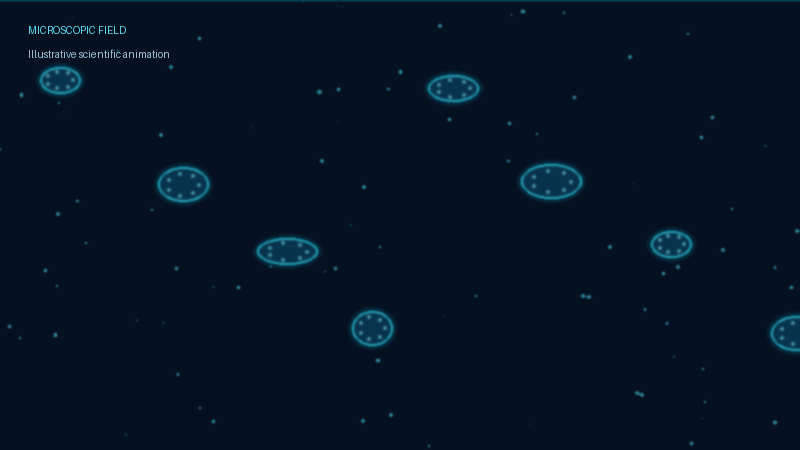

In [ ]:

from IPython.display import display, Image as IPyImage

gif_path = "/content/drive/MyDrive/Helminth_GitHub_Project/assets/microscopic_motion.gif"
display(IPyImage(filename=gif_path))


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import math, random

# Google Drive project path
PROJECT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
ASSETS = PROJECT / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

W, H = 800, 450
FRAMES = 30
random.seed(42)

# Fonts
def get_font(size, bold=False):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"
        if bold else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
    ]
    for f in candidates:
        if Path(f).exists():
            return ImageFont.truetype(f, size)
    return ImageFont.load_default()

FONT = get_font(15)
SMALL = get_font(12)
BOLD = get_font(17, True)
TITLE = get_font(23, True)

# Dark microscopy-style background with subtle texture
base = Image.new("RGB", (W, H))
pix = base.load()
for y in range(H):
    for x in range(W):
        vignette = max(0, 1 - (((x-W/2)/(W*.8))**2 +
                               ((y-H/2)/(H*.8))**2))
        noise = random.randint(-3, 3)
        pix[x, y] = (
            max(0, int(5 + 5*vignette + noise)),
            max(0, int(17 + 13*vignette + noise)),
            max(0, int(29 + 20*vignette + noise))
        )

# Static fine debris / out-of-focus particles
debris = []
for _ in range(125):
    debris.append((
        random.randint(15, W-15),
        random.randint(35, H-25),
        random.choice([1, 1, 2, 3]),
        random.randint(20, 80)
    ))

def draw_microscopy(frame_no, prediction=False):
    im = base.copy().convert("RGBA")
    d = ImageDraw.Draw(im, "RGBA")

    # Fine drifting particles; their movement is illustrative
    for i, (x0, y0, r, alpha) in enumerate(debris):
        x = (x0 + frame_no * (0.8 + (i % 4)*0.15)) % W
        y = y0 + 4*math.sin(frame_no*0.16 + i)
        d.ellipse((x-r, y-r, x+r, y+r),
                  fill=(106, 205, 213, alpha))

    # Subtle optical scan line
    scan_y = 60 + (frame_no * 9) % 330
    d.line((25, scan_y, W-25, scan_y),
           fill=(48, 202, 220, 34), width=2)

    # Egg-like oval: stationary object, textured shell
    # The egg does not swim; only surrounding particles drift.
    cx, cy = 410, 232
    outer = (cx-112, cy-77, cx+112, cy+77)

    # Soft halo
    halo = Image.new("RGBA", (W, H), (0,0,0,0))
    hd = ImageDraw.Draw(halo)
    hd.ellipse((cx-128, cy-92, cx+128, cy+92),
               fill=(54, 181, 188, 40))
    halo = halo.filter(ImageFilter.GaussianBlur(22))
    im = Image.alpha_composite(im, halo)
    d = ImageDraw.Draw(im, "RGBA")

    # Layered, slightly rough-looking shell
    d.ellipse(outer, fill=(139, 119, 78, 255),
              outline=(225, 211, 161, 255), width=5)
    d.ellipse((cx-104, cy-69, cx+104, cy+69),
              fill=(64, 68, 51, 255),
              outline=(202, 186, 132, 255), width=3)
    d.ellipse((cx-96, cy-61, cx+96, cy+61),
              fill=(91, 85, 61, 255),
              outline=(171, 154, 106, 255), width=2)

    # Uneven internal material and granular structures
    for i in range(72):
        angle = random.Random(i+5).uniform(0, math.tau)
        rr = random.Random(i+10).uniform(0.1, 0.85)
        gx = cx + math.cos(angle)*88*rr
        gy = cy + math.sin(angle)*52*rr
        rad = random.Random(i+15).uniform(1.2, 4.0)
        tone = random.choice([
            (199, 177, 112, 125),
            (226, 205, 145, 110),
            (42, 48, 38, 150)
        ])
        d.ellipse((gx-rad, gy-rad, gx+rad, gy+rad), fill=tone)

    # Soft optical highlight
    d.arc((cx-90, cy-58, cx+86, cy+58),
          205, 300, fill=(247, 226, 172, 160), width=3)

    # Header and explicit illustration disclaimer
    d.text((26, 18), "MICROSCOPY-INSPIRED VISUALIZATION",
           font=BOLD, fill=(119, 232, 239, 255))
    d.text((26, 42), "Illustrative animation • Not experimental footage",
           font=SMALL, fill=(180, 198, 210, 235))

    if prediction and frame_no >= 8:
        # YOLO-style box is illustrative, not a real inference result
        bx = (cx-124, cy-89, cx+124, cy+89)
        d.rectangle(bx, outline=(38, 238, 196, 255), width=3)
        label = "Illustrative detection | confidence not measured"
        bb = d.textbbox((0,0), label, font=SMALL)
        tw, th = bb[2]-bb[0], bb[3]-bb[1]
        ly = max(65, cy-112)
        d.rectangle((cx-124, ly-3, cx-124+tw+14, ly+th+7),
                    fill=(7, 43, 51, 245))
        d.text((cx-117, ly), label, font=SMALL,
               fill=(95, 255, 218, 255))

    return im.convert("RGB")

# 1) Microscopy-inspired motion GIF
motion_frames = [
    draw_microscopy(i, prediction=False) for i in range(FRAMES)
]
motion_frames[0].save(
    ASSETS / "microscopic_motion.gif",
    save_all=True, append_images=motion_frames[1:],
    duration=100, loop=0, optimize=True
)

# 2) Illustrative detection demo GIF
prediction_frames = [
    draw_microscopy(i, prediction=True) for i in range(FRAMES)
]
prediction_frames[0].save(
    ASSETS / "prediction_demo.gif",
    save_all=True, append_images=prediction_frames[1:],
    duration=100, loop=0, optimize=True
)

# 3) Animated workflow GIF
workflow_frames = []
stages = [
    ("01", "DATASET", "Images + annotations"),
    ("02", "TRAINING", "YOLO11n baseline"),
    ("03", "VALIDATION", "Model assessment"),
    ("04", "TEST", "Held-out evaluation")
]

for frame_no in range(FRAMES):
    im = base.copy().convert("RGBA")
    d = ImageDraw.Draw(im, "RGBA")
    d.text((30, 28), "HELMINTH EGG DETECTION",
           font=TITLE, fill=(119, 232, 239, 255))
    d.text((30, 61), "Research workflow • schematic",
           font=SMALL, fill=(184, 204, 215, 255))

    xs = [24, 224, 424, 624]
    for i, (num, name, desc) in enumerate(stages):
        x = xs[i]
        active = (frame_no // 7) % 4 == i
        outline = (47, 238, 201, 255) if active else (55, 116, 139, 220)
        fill = (10, 48, 58, 245) if active else (8, 27, 43, 235)

        d.rounded_rectangle((x, 160, x+152, 260), radius=12,
                            fill=fill, outline=outline, width=3)
        d.text((x+12, 174), num, font=SMALL,
               fill=(93, 240, 222, 255))
        d.text((x+12, 198), name, font=BOLD,
               fill=(234, 247, 251, 255))
        d.text((x+12, 231), desc, font=SMALL,
               fill=(181, 205, 216, 255))

        if i < 3:
            # Arrow between workflow stages
            ax = x+160
            d.line((ax, 210, ax+27, 210),
                   fill=(63, 210, 218, 230), width=3)
            d.polygon([(ax+27,210),(ax+18,204),(ax+18,216)],
                      fill=(63, 210, 218, 230))

    d.text((30, 315),
           "Validation and held-out test results remain separate.",
           font=FONT, fill=(191, 222, 231, 255))
    d.text((30, 343),
           "Schematic workflow; not a claim of clinical readiness.",
           font=SMALL, fill=(151, 179, 194, 255))

    workflow_frames.append(im.convert("RGB"))

workflow_frames[0].save(
    ASSETS / "workflow.gif",
    save_all=True, append_images=workflow_frames[1:],
    duration=130, loop=0, optimize=True
)

# Verify the files and frame counts
for name in [
    "microscopic_motion.gif",
    "prediction_demo.gif",
    "workflow.gif"
]:
    path = ASSETS / name
    with Image.open(path) as gif:
        print(
            f"PASS | {name} | exists={path.exists()} | "
            f"size={path.stat().st_size:,} bytes | "
            f"frames={getattr(gif, 'n_frames', 1)}"
        )

print("\nAssets folder:", ASSETS)


PASS | microscopic_motion.gif | exists=True | size=6,129,275 bytes | frames=30
PASS | prediction_demo.gif | exists=True | size=5,840,811 bytes | frames=30
PASS | workflow.gif | exists=True | size=339,952 bytes | frames=5

Assets folder: /content/drive/MyDrive/Helminth_GitHub_Project/assets


In [ ]:

from IPython.display import display, Image as IPyImage

for filename in [
    "microscopic_motion.gif",
    "prediction_demo.gif",
    "workflow.gif"
]:
    print(filename)
    display(IPyImage(filename=str(ASSETS / filename)))


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
assets = project / "assets"

for name in [
    "microscopic_motion.gif",
    "prediction_demo.gif",
    "workflow.gif"
]:
    p = assets / name
    print(f"{'PASS' if p.exists() and p.stat().st_size > 0 else 'FAIL'} | {name}")


PASS | microscopic_motion.gif
PASS | prediction_demo.gif
PASS | workflow.gif


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
assets = project / "assets"

# Folder create karo, agar pehle se nahi hai
assets.mkdir(parents=True, exist_ok=True)

# GIF files ko search karo
for name in [
    "microscopic_motion.gif",
    "prediction_demo.gif",
    "workflow.gif"
]:
    matches = list(project.rglob(name))
    if matches:
        print("FOUND:", matches[0])
    else:
        print("NOT FOUND:", name)

print("\nAssets folder:", assets)
print("Folder exists:", assets.exists())


FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/assets/microscopic_motion.gif
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/assets/prediction_demo.gif
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/assets/workflow.gif

Assets folder: /content/drive/MyDrive/Helminth_GitHub_Project/assets
Folder exists: True


In [ ]:

from pathlib import Path
import zipfile

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
assets = project / "assets"

zip_path = Path("/content/helminth_gif_assets.zip")

files = [
    assets / "microscopic_motion.gif",
    assets / "prediction_demo.gif",
    assets / "workflow.gif",
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in files:
        assert file.exists(), f"File missing: {file}"
        z.write(file, arcname=f"assets/{file.name}")

print("ZIP created:", zip_path)
print("ZIP size:", f"{zip_path.stat().st_size:,} bytes")

from google.colab import files
files.download(str(zip_path))


ZIP created: /content/helminth_gif_assets.zip
ZIP size: 12,286,635 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nAvailable files and folders:")
print(os.listdir("/content"))

Current folder: /content

Available files and folders:
['.config', 'sample_data']


In [ ]:

!wget -O best.pt https://raw.githubusercontent.com/rayyan-anwar/helminth-egg-detection-yolo11/main/models/best.pt


--2026-10-21 18:15:27--  https://raw.githubusercontent.com/rayyan-anwar/helminth-egg-detection-yolo11/main/models/best.pt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5459418 (5.2M) [application/octet-stream]
Saving to: ‘best.pt’

best.pt             100%[===================>]   5.21M  --.-KB/s    in 0.05s   

2026-10-21 18:15:27 (105 MB/s) - ‘best.pt’ saved [5459418/5459418]



In [ ]:

import os

print("Model exists:", os.path.exists("/content/best.pt"))
print("File size:", round(os.path.getsize("/content/best.pt") / (1024 * 1024), 2), "MB" if os.path.exists("/content/best.pt") else "")


Model exists: True
File size: 5.21 MB


In [ ]:

!pip install -q ultralytics

from ultralytics import YOLO

model = YOLO("/content/best.pt")

print("Model successfully loaded!")
print("Classes:", model.names)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model successfully loaded!
Classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}


In [ ]:

!git clone https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git /content/repo

import os

for folder in ["results", "figures", "models"]:
    path = f"/content/repo/{folder}"
    print(f"\n--- {folder}/ ---")
    if os.path.exists(path):
        for name in os.listdir(path):
            print(name)
    else:
        print("Folder not found")


Cloning into '/content/repo'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (69/69), done.
remote: Total 71 (delta 26), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 17.94 MiB | 18.38 MiB/s, done.
Resolving deltas: 100% (26/26), done.

--- results/ ---
training_history.csv
final_project_check_report.txt
classwise_test_results.csv
training_args.yaml
test_metrics.json
final_project_check_report.json

--- figures/ ---
confusion_matrix.png
BoxF1_curve.png
confusion_matrix_normalized.png
BoxPR_curve.png
BoxR_curve.png
BoxP_curve.png

--- models/ ---
best.pt


In [ ]:

import os, json
import pandas as pd

base = "/content/repo/results"

for name in ["test_metrics.json", "final_project_check_report.json"]:
    path = os.path.join(base, name)
    print(f"\n===== {name} =====")
    with open(path, "r") as f:
        print(json.dumps(json.load(f), indent=2))

for name in ["training_history.csv", "classwise_test_results.csv"]:
    path = os.path.join(base, name)
    print(f"\n===== {name} =====")
    print(pd.read_csv(path).to_string(index=False))

print("\n===== AUDIT REPORT =====")
with open(os.path.join(base, "final_project_check_report.txt"), "r") as f:
    print(f.read())



===== test_metrics.json =====
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}

===== final_project_check_report.json =====
{
  "project": "Helminth Egg Detection using YOLO11n",
  "checks": {
    "Required project files": {
      "status": "PASS",
      "detail": "All present"
    },
    "Existing ZIP integrity": {
      "status": "PASS",
      "detail": "ZIP readable"
    },
    "ZIP required contents": {
      "status": "PASS",
      "detail": "Required files present"
    },
    "Prediction script CLI": {
      "status": "PASS",
      "detail": "Help command works"
    },
    "Model loading": {
      "status": "PASS",
      "detail": "Task=detect; classes={0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}"
    },
    "train labels and structure": {
      "status": "PASS",
      "detai

In [ ]:

import os

print("Repository:", os.path.isdir("/content/repo"))
print("Dataset config:", os.path.exists("/content/repo/dataset.yaml"))
print("Model:", os.path.exists("/content/repo/models/best.pt"))

for root, dirs, files in os.walk("/content/repo"):
    dirs[:] = [d for d in dirs if d not in [".git"]]
    for f in files:
        if f.endswith((".yaml", ".yml")) and ("data" in f.lower() or "dataset" in f.lower()):
            print("Config candidate:", os.path.join(root, f))


Repository: True
Dataset config: True
Model: True
Config candidate: /content/repo/dataset.yaml


In [ ]:

from pathlib import Path

print(open("/content/repo/dataset.yaml").read())

print("\n--- Dataset folders ---")
for p in Path("/content/repo").iterdir():
    if p.is_dir() and p.name != ".git":
        print(p.name)


path: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
train: images/train
val: images/val
test: images/test

names:
  0: ASC.
  1: HKW.
  2: SCH.
  3: TRI.


--- Dataset folders ---
results
models
figures
assets


In [ ]:

from pathlib import Path

p = Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered")

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Dataset folder exists:", p.exists())

if p.exists():
    for name in ["images/train", "images/val", "images/test"]:
        folder = p / name
        print(name, "exists:", folder.exists())
        if folder.exists():
            print("  files:", len(list(folder.iterdir())))


Drive mounted: False
Dataset folder exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")
print("MyDrive folders:")

for p in base.iterdir():
    print(p.name)

MyDrive folders:
new admissions 2024-25
HGOC Documents and Data
PG Data of All College
College Function HGOC
WhatsApp Image 2025-10-27 at 2.21.48 PM.jpeg
ornic chemist.gdoc
Private File
Untitled document (1).gdoc
Untitled document.gdoc
make a question paper for b.Sc Physics 2nd Semest....gdoc
PHARMACEUTICS EXP.docx
B.Pharm Degree.pdf
Colab Notebooks
Helminth_Project_Backup
Helminth_GitHub_Project
Helminth_Research_Project_previous.zip
Helminth_Research_Project.zip
Helminth_Research_Project_FINAL.zip


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")

targets = [
    base / "Helminth_Project_Backup",
    base / "Helminth_GitHub_Project",
]

for folder in targets:
    print(f"\n--- {folder.name} ---")
    if folder.exists():
        for p in list(folder.iterdir())[:30]:
            print(p.name)
    else:
        print("Folder not found")

print("\n--- ZIP backups ---")
for p in base.glob("Helminth_Research_Project*.zip"):
    print(p.name, f"({p.stat().st_size / (1024**2):.1f} MB)")



--- Helminth_Project_Backup ---
helminth_4class_training
helminth_4class_recovered
helminth_recovered_v2
helminth_recovered_v2_test
classwise_test_results.csv
README.md

--- Helminth_GitHub_Project ---
results
figures
models
.gitignore
predict.py
runs
dataset.yaml
README_backup_20261018_181523.md
requirements_backup_20261018_181523.txt
requirements.txt
README.md
experiments_gpu

--- ZIP backups ---
Helminth_Research_Project_previous.zip (5.5 MB)
Helminth_Research_Project.zip (5.5 MB)
Helminth_Research_Project_FINAL.zip (5.5 MB)


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/Helminth_Project_Backup")

folders = [
    "helminth_4class_training",
    "helminth_4class_recovered",
    "helminth_recovered_v2",
    "helminth_recovered_v2_test",
]

for name in folders:
    p = base / name
    print(f"\n--- {name} ---")

    for sub in ["images/train", "images/val", "images/test",
                "labels/train", "labels/val", "labels/test"]:
        q = p / sub
        if q.exists():
            count = sum(1 for x in q.iterdir() if x.is_file())
            print(f"{sub}: EXISTS ({count} files)")
        else:
            print(f"{sub}: missing")


--- helminth_4class_training ---
images/train: missing
images/val: missing
images/test: missing
labels/train: missing
labels/val: missing
labels/test: missing

--- helminth_4class_recovered ---
images/train: EXISTS (280 files)
images/val: EXISTS (60 files)
images/test: EXISTS (60 files)
labels/train: EXISTS (280 files)
labels/val: EXISTS (60 files)
labels/test: EXISTS (60 files)

--- helminth_recovered_v2 ---
images/train: missing
images/val: missing
images/test: missing
labels/train: missing
labels/val: missing
labels/test: missing

--- helminth_recovered_v2_test ---
images/train: missing
images/val: missing
images/test: missing
labels/train: missing
labels/val: missing
labels/test: missing


In [ ]:
from pathlib import Path

dataset = Path(
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"
)

print("Dataset exists:", dataset.exists())
print("Test images:", len(list((dataset / "images/test").glob("*"))))
print("Test labels:", len(list((dataset / "labels/test").glob("*"))))
print("Model exists:", Path("/content/repo/models/best.pt").exists())

Dataset exists: True
Test images: 60
Test labels: 60
Model exists: True


In [ ]:
from pathlib import Path

for f in [
    Path("/content/repo/results/training_args.yaml"),
    Path("/content/repo/predict.py"),
    Path("/content/repo/dataset.yaml"),
]:
    print(f"\n{'='*20} {f.name} {'='*20}")
    if f.exists():
        print(f.read_text()[:6000])
    else:
        print("File not found")


==================== training_args.yaml ====================
task: detect
mode: train
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
time: null
patience: 5
batch: 4
imgsz: 320
save: true
save_period: -1
cache: false
device: cpu
workers: 0
project: /content/helminth_runs
name: helminth_recovered_v2
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
sa

In [ ]:
from pathlib import Path

files = [
    Path("/content/repo/results/training_args.yaml"),
    Path("/content/repo/predict.py"),
    Path("/content/repo/dataset.yaml"),
]

for f in files:
    print(f"\n{'='*15} {f.name} {'='*15}")
    if f.exists():
        print(f.read_text()[:6000])
    else:
        print("File not found")


=============== training_args.yaml ===============
task: detect
mode: train
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
time: null
patience: 5
batch: 4
imgsz: 320
save: true
save_period: -1
cache: false
device: cpu
workers: 0
project: /content/helminth_runs
name: helminth_recovered_v2
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
save_crop: f

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import json

model_path = "/content/repo/models/best.pt"
data_path = "/content/repo/dataset.yaml"
output_dir = "/content/repo/recheck"

assert Path(model_path).exists(), "Model file missing!"
assert Path(data_path).exists(), "Dataset YAML missing!"

model = YOLO(model_path)

metrics = model.val(
    data=data_path,
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    conf=0.001,
    iou=0.7,
    plots=True,
    project=output_dir,
    name="test_recheck",
    exist_ok=True
)

result = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
}

save_dir = Path(output_dir) / "test_recheck"
save_dir.mkdir(parents=True, exist_ok=True)

with open(save_dir / "metrics_summary.json", "w") as f:
    json.dump(result, f, indent=2)

print("\n===== TEST RE-EVALUATION =====")
for key, value in result.items():
    print(f"{key}: {value:.4f} ({value * 100:.2f}%)")

print("\nSaved results:", save_dir)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 5.8±1.0 MB/s, size: 3655.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.0it/s 57.4s
val: New cache created: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.9it/s 7.8s
                   all         60        147      0.748      0.644      0.725      0.553
                  ASC.         24         66      0.815      0.939      0.953      0.7

In [ ]:

from pathlib import Path
import json

project = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("Project folder exists:", project.exists())

files = [
    "results/test_metrics_rerun.json",
    "results/reproducibility_manifest.json",
]

for name in files:
    path = project / name
    print(f"\n--- {name} ---")

    if path.exists():
        print(json.dumps(
            json.loads(path.read_text()),
            indent=2
        ))
    else:
        print("File not found at this path.")


Project folder exists: False

--- results/test_metrics_rerun.json ---
File not found at this path.

--- results/reproducibility_manifest.json ---
File not found at this path.


In [ ]:

from pathlib import Path
import os

# Check Google Drive mount
print("Drive mounted:", Path("/content/drive/MyDrive").exists())

# Check possible project locations
locations = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/repo"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup"),
]

for path in locations:
    print(f"\n{path}")
    print("Exists:", path.exists())

    if path.exists():
        print("Contents:")
        for item in list(path.iterdir())[:15]:
            print(" -", item.name)


Drive mounted: False

/content/drive/MyDrive/Helminth_GitHub_Project
Exists: False

/content/repo
Exists: False

/content/drive/MyDrive/Helminth_Project_Backup
Exists: False


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

print("MyDrive accessible:", root.exists())
print("\nHelminth-related folders:")

for item in root.iterdir():
    if item.is_dir() and any(
        word in item.name.lower()
        for word in ["helminth", "research", "github"]
    ):
        print("FOLDER:", item)

print("\nSearching for saved metrics (limited search):")

count = 0
for name in ["test_metrics_rerun.json", "reproducibility_manifest.json"]:
    matches = list(root.rglob(name))
    for match in matches[:5]:
        print(name, "->", match)
        count += 1

if count == 0:
    print("Metrics files not found in this search.")


MyDrive accessible: True

Helminth-related folders:
FOLDER: /content/drive/MyDrive/Helminth_Project_Backup
FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project

Searching for saved metrics (limited search):
test_metrics_rerun.json -> /content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_rerun.json
reproducibility_manifest.json -> /content/drive/MyDrive/Helminth_GitHub_Project/results/reproducibility_manifest.json


In [ ]:

from pathlib import Path

folders = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup"),
]

for folder in folders:
    print(f"\n{'='*55}")
    print("FOLDER:", folder.name)

    if not folder.exists():
        print("Folder not found")
        continue

    for item in sorted(folder.iterdir()):
        kind = "DIR " if item.is_dir() else "FILE"
        print(f"{kind}  {item.name}")



FOLDER: Helminth_GitHub_Project
FILE  .gitignore
FILE  README.md
FILE  README_backup_20261018_181523.md
FILE  dataset.yaml
DIR   experiments_gpu
DIR   figures
DIR   models
FILE  predict.py
FILE  requirements.txt
FILE  requirements_backup_20261018_181523.txt
DIR   results
DIR   runs

FOLDER: Helminth_Project_Backup
FILE  README.md
FILE  classwise_test_results.csv
DIR   helminth_4class_recovered
DIR   helminth_4class_training
DIR   helminth_recovered_v2
DIR   helminth_recovered_v2_test


In [ ]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)

for folder_name in ["results", "figures", "experiments_gpu", "models"]:
    folder = project / folder_name
    print(f"\n--- {folder_name}/ ---")

    if folder.exists():
        for item in sorted(folder.iterdir()):
            print(("DIR  " if item.is_dir() else "FILE "), item.name)



--- results/ ---
FILE  baseline_validation_audit.json
FILE  classwise_test_results.csv
FILE  confusion_matrix_counts.csv
FILE  dataset_split_class_counts.csv
DIR   default_conf_check
DIR   diagnostic_conf025
DIR   error_analysis
DIR   error_analysis_figures
DIR   figures
FILE  final_metrics_consistency_audit.json
DIR   final_metrics_review
DIR   final_operating_point
FILE  final_project_check_report.json
FILE  final_project_check_report.txt
DIR   final_validation_report
FILE  learning_rate_provenance_audit.json
FILE  manuscript_overall_metrics_table.csv
FILE  manuscript_validation_class_metrics.csv
DIR   official_test_confusion_check
FILE  reproducibility_manifest.json
DIR   sch_confidence_sweep
FILE  sch_confidence_sweep_corrected.csv
FILE  sch_false_positives_conf025.csv
FILE  sch_high_confidence_fp_audit.csv
DIR   sch_low_conf_diagnostic
FILE  sch_threshold_sensitivity.csv
FILE  sch_validation_object_matching_by_threshold.csv
FILE  sch_validation_precision_recall.png
FILE  sch_vali

In [ ]:

from pathlib import Path
import json
import pandas as pd

project = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project"
)
results = project / "results"

json_files = [
    "test_metrics.json",
    "test_metrics_rerun.json",
    "final_metrics_consistency_audit.json",
    "reproducibility_manifest.json",
]

for filename in json_files:
    path = results / filename
    print("\n" + "=" * 60)
    print(filename)

    if path.exists():
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:7000])
        except Exception as e:
            print("Read error:", e)
    else:
        print("File not found")

csv_files = [
    "manuscript_overall_metrics_table.csv",
    "classwise_test_results.csv",
]

for filename in csv_files:
    path = results / filename
    print("\n" + "=" * 60)
    print(filename)

    if path.exists():
        print(pd.read_csv(path).to_string(index=False)[:5000])
    else:
        print("File not found")



test_metrics.json
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}

test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

final_metrics_consistency_audit.json
{
  "overall_test_values_match_summary": true,
  "validation_values_match_summary": true,
  "test_images": 60,
  "test_instances": 147,
  "validation_images": 60,
  "validation_imgsz": 320,
  "validation_confidence": 0.001,
  "validation_iou": 0.45,
  "test_evaluation_settings_fully_recorded_in_json": false,
  "optimizer_and_initial_lr_independently_verified": false,
  "test_set

In [ ]:

from pathlib import Path
import json

results = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/results"
)

files = [
    "training_provenance_audit.json",
    "training_log_discovery_audit.json",
    "final_project_check_report.json",
]

for filename in files:
    path = results / filename
    print("\n" + "=" * 55)
    print(filename)

    if path.exists():
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:4500])
        except Exception as e:
            print("Could not parse:", e)
    else:
        print("Not found")

print("\n--- Saved training arguments ---")
args_file = results / "training_args.yaml"

if args_file.exists():
    print(args_file.read_text()[:4000])
else:
    print("training_args.yaml not found")



training_provenance_audit.json
{
  "audit_type": "original_training_provenance",
  "run_directory": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2",
  "source_files": {
    "args": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/args.yaml",
    "results_csv": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/results.csv",
    "checkpoint": "/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2/weights/best.pt"
  },
  "training_configuration": {
    "model": "yolo11n.pt",
    "epochs_configured": 15,
    "epochs_logged": 15,
    "imgsz": 320,
    "batch": 4,
    "device": "cpu",
    "seed": 42,
    "deterministic": true,
    "pretrained": true,
    "optimizer_setting": "auto",
    "lr0_setting": 0.01,
    "lrf_setting": 0.01,
    "data_path_recorded": "/content/helminth_4class_recovered/dataset.yaml"
  },
  "best_logged_epoch_by_map50": {
    "epoch": 13.0,
    "metrics/precision(B)": 0.8737,
    "metrics/r

In [ ]:

from pathlib import Path
import pandas as pd
import yaml

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

runs = [
    root / "experiments_gpu/baseline_finetune_30ep",
    root / "experiments_gpu/baseline_finetune_oct21",
    Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2")
]

for run in runs:
    print("\n" + "=" * 65)
    print("RUN:", run.name)

    args_file = run / "args.yaml"
    if not args_file.exists():
        args_file = run / "weights" / "args.yaml"

    if args_file.exists():
        args = yaml.safe_load(args_file.read_text())
        for key in ["model", "data", "epochs", "imgsz",
                    "batch", "device", "seed", "optimizer",
                    "lr0", "pretrained", "resume"]:
            print(f"{key}: {args.get(key, 'not recorded')}")
    else:
        print("args.yaml: NOT FOUND")

    results_file = run / "results.csv"
    if results_file.exists():
        df = pd.read_csv(results_file)
        df.columns = df.columns.str.strip()
        print("\nLogged epochs:", len(df))

        metric = "metrics/mAP50(B)"
        if metric in df.columns:
            best = df.loc[df[metric].idxmax()]
            print("Best mAP50 epoch:", best.get("epoch"))
            print("Best mAP50:", round(float(best[metric]), 5))
            print("Best mAP50-95:",
                  round(float(best["metrics/mAP50-95(B)"]), 5)
                  if "metrics/mAP50-95(B)" in df.columns else "N/A")
        print("\nLast logged row:")
        cols = [c for c in [
            "epoch", "metrics/precision(B)", "metrics/recall(B)",
            "metrics/mAP50(B)", "metrics/mAP50-95(B)"
        ] if c in df.columns]
        print(df[cols].tail(1).to_string(index=False))
    else:
        print("results.csv: NOT FOUND")



RUN: baseline_finetune_30ep
model: /content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt
data: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
epochs: 30
imgsz: 320
batch: 8
device: 0
seed: 42
optimizer: AdamW
lr0: 0.0005
pretrained: False
resume: False

Logged epochs: 24
Best mAP50 epoch: 24.0
Best mAP50: 0.16936
Best mAP50-95: 0.09276

Last logged row:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    24               0.43062            0.22661           0.16936              0.09276

RUN: baseline_finetune_oct21
model: /content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt
data: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
epochs: 30
imgsz: 320
batch: 8
device: 0
seed: 42
optimizer: AdamW
lr0: 0.0005
pretrained: False
resume: False

Logged epochs: 30
Best mAP50 epoch: 30.0
Best mAP50: 0.19186
Best mAP50-95: 0.10953

Last logged row:
 epoch  metrics/precision(B)  metrics

In [ ]:

from pathlib import Path
import hashlib

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

paths = [
    root / "models/best.pt",
    root / "models/best_baseline_backup.pt",
    root / "experiments_gpu/baseline_finetune_30ep/weights/best.pt",
    root / "experiments_gpu/baseline_finetune_30ep/weights/last.pt",
    root / "experiments_gpu/baseline_finetune_oct21/weights/best.pt",
    root / "experiments_gpu/baseline_finetune_oct21/weights/last.pt",
]

for path in paths:
    print("\n", path.name, "|", path.parent.parent.name)
    if path.exists():
        h = hashlib.sha256(path.read_bytes()).hexdigest()
        print("Size:", round(path.stat().st_size / (1024 * 1024), 2), "MB")
        print("SHA256:", h)
    else:
        print("Not found")




 best.pt | Helminth_GitHub_Project
Size: 5.21 MB
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df

 best_baseline_backup.pt | Helminth_GitHub_Project
Size: 5.21 MB
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df

 best.pt | baseline_finetune_30ep
Size: 25.18 MB
SHA256: a5ec1daa500245d722251ebc4ee5613af69b835f464771f468ddda9b20303db8

 last.pt | baseline_finetune_30ep
Size: 25.18 MB
SHA256: 3957daff3793cf51e01cae71a1e7fe5a1358bb6d23c8c6ab2bf8c845a51849e6

 best.pt | baseline_finetune_oct21
Size: 5.18 MB
SHA256: 87bd96b11c9f8c8c33434286e2eddaaee73ab8a64209c403c3c01cf0d49bce55

 last.pt | baseline_finetune_oct21
Size: 5.18 MB
SHA256: 8d7b9ac9096c011140ffe0e4cbb01f2201bf26e09e4036e2dc39498fd4587407


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import json

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
data = root / "dataset.yaml"

models = {
    "original_baseline": root / "models/best.pt",
    "gpu_finetune_30ep": root / "experiments_gpu/baseline_finetune_30ep/weights/best.pt",
    "gpu_finetune_oct21": root / "experiments_gpu/baseline_finetune_oct21/weights/best.pt",
}

output = root / "results/checkpoint_validation_comparison"
output.mkdir(parents=True, exist_ok=True)

summary = {}

for name, checkpoint in models.items():
    print("\n" + "=" * 55)
    print("Evaluating:", name)

    if not checkpoint.exists():
        print("Checkpoint missing:", checkpoint)
        continue

    model = YOLO(str(checkpoint))
    print("Model classes:", model.names)

    metrics = model.val(
        data=str(data),
        split="val",
        imgsz=320,
        conf=0.001,
        iou=0.45,
        device=0,
        plots=False,
        verbose=False,
        project=str(output),
        name=name,
        exist_ok=True
    )

    summary[name] = {
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "checkpoint": str(checkpoint)
    }

    print(json.dumps(summary[name], indent=2))

save_path = output / "comparison_summary.json"
save_path.write_text(json.dumps(summary, indent=2))
print("\nSaved comparison:", save_path)


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:

%pip install ultralytics==8.4.181


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 86.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00


In [ ]:

import ultralytics
print("Ultralytics version:", ultralytics.__version__)

from ultralytics import YOLO
print("YOLO import successful")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.181
YOLO import successful


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import json

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
data = root / "dataset.yaml"

models = {
    "original_baseline": root / "models/best.pt",
    "gpu_finetune_30ep": root / "experiments_gpu/baseline_finetune_30ep/weights/best.pt",
    "gpu_finetune_oct21": root / "experiments_gpu/baseline_finetune_oct21/weights/best.pt",
}

output = root / "results/checkpoint_validation_comparison"
output.mkdir(parents=True, exist_ok=True)

summary = {}

for name, checkpoint in models.items():
    print("\n" + "=" * 55)
    print("Evaluating:", name)

    if not checkpoint.exists():
        print("Checkpoint missing:", checkpoint)
        continue

    model = YOLO(str(checkpoint))
    print("Model classes:", model.names)

    metrics = model.val(
        data=str(data),
        split="val",
        imgsz=320,
        conf=0.001,
        iou=0.45,
        device=0,
        plots=False,
        verbose=False,
        project=str(output),
        name=name,
        exist_ok=True
    )

    summary[name] = {
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "checkpoint": str(checkpoint)
    }

    print(json.dumps(summary[name], indent=2))

save_path = output / "comparison_summary.json"
save_path.write_text(json.dumps(summary, indent=2))
print("\nSaved comparison:", save_path)



Evaluating: original_baseline
Model classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.2 ms, read: 3.1±0.9 MB/s, size: 3330.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 7.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 16.2s/it 1:05
                   all         60        114      0.891      0.771      0.878      0.691
Speed: 0.2ms preprocess, 4.5ms inference, 0.0ms loss, 1.0ms postprocess per image
{
  "precision": 0.89057597

In [ ]:

from pathlib import Path
import yaml
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

runs = {
    "GPU 30ep": root / "experiments_gpu/baseline_finetune_30ep",
    "GPU Oct21": root / "experiments_gpu/baseline_finetune_oct21",
}

for run_name, run_dir in runs.items():
    print("\n" + "=" * 60)
    print(run_name)

    args_file = run_dir / "args.yaml"
    if not args_file.exists():
        args_file = run_dir / "weights" / "args.yaml"

    if args_file.exists():
        args = yaml.safe_load(args_file.read_text())
        for key in [
            "model", "data", "epochs", "imgsz", "batch",
            "optimizer", "lr0", "pretrained", "resume",
            "seed", "close_mosaic"
        ]:
            print(f"{key}: {args.get(key)}")
    else:
        print("args.yaml not found")

    csv_file = run_dir / "results.csv"
    if csv_file.exists():
        df = pd.read_csv(csv_file)
        df.columns = df.columns.str.strip()

        metric_cols = [
            c for c in df.columns
            if any(s in c.lower() for s in [
                "precision", "recall", "map50", "map50-95"
            ])
        ]
        print("\nLogged epochs:", len(df))
        print(df[metric_cols].tail(3).to_string(index=False))
    else:
        print("results.csv not found")

print("\nAudit complete.")



GPU 30ep
model: /content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt
data: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
epochs: 30
imgsz: 320
batch: 8
optimizer: AdamW
lr0: 0.0005
pretrained: False
resume: False
seed: 42
close_mosaic: 10

Logged epochs: 24
 metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
              0.40813            0.19509           0.14409              0.08377
              0.40934            0.19935           0.15077              0.08227
              0.43062            0.22661           0.16936              0.09276

GPU Oct21
model: /content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt
data: /content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml
epochs: 30
imgsz: 320
batch: 8
optimizer: AdamW
lr0: 0.0005
pretrained: False
resume: False
seed: 42
close_mosaic: 10

Logged epochs: 30
 metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
   

In [ ]:

from pathlib import Path
import pandas as pd
import yaml

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

for name in [
    "baseline_finetune_30ep",
    "baseline_finetune_oct21"
]:
    run_dir = root / "experiments_gpu" / name
    print("\n" + "=" * 60)
    print(name)

    for filename in ["args.yaml", "results.csv"]:
        path = run_dir / filename
        print(f"{filename}: exists={path.exists()}")

    csv_path = run_dir / "results.csv"
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()

        cols = [
            c for c in df.columns
            if c == "epoch"
            or "lr/" in c.lower()
            or "train/box_loss" in c.lower()
            or "train/cls_loss" in c.lower()
            or "train/dfl_loss" in c.lower()
            or "val/box_loss" in c.lower()
            or "val/cls_loss" in c.lower()
            or "val/dfl_loss" in c.lower()
        ]

        print("\nFirst 3 logged epochs:")
        print(df[cols].head(3).to_string(index=False))

        print("\nLast 3 logged epochs:")
        print(df[cols].tail(3).to_string(index=False))



baseline_finetune_30ep
args.yaml: exists=True
results.csv: exists=True

First 3 logged epochs:
 epoch  train/box_loss  train/cls_loss  train/dfl_loss  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
     1         5.26366         5.22268         3.44606       4.21507       4.53119       2.89590 0.000162 0.000162 0.067781
     2         4.23429         4.13025         2.60956       3.67492       4.55024       2.66576 0.000318 0.000318 0.034603
     3         3.95552         3.95684         2.43840       3.63059       4.51031       2.63820 0.000463 0.000463 0.001415

Last 3 logged epochs:
 epoch  train/box_loss  train/cls_loss  train/dfl_loss  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    22         2.44385         3.20559         1.81365       2.47975       3.52945       1.80466 0.000153 0.000153 0.000153
    23         2.41644         3.12323         1.83213       2.49686       3.49790       1.80056 0.000137 0.000137 0.000137
    24       

In [ ]:

from pathlib import Path
from ultralytics import YOLO

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

checkpoints = {
    "Original": root / "models/best.pt",
    "GPU 30ep": root / "experiments_gpu/baseline_finetune_30ep/weights/best.pt",
    "GPU Oct21": root / "experiments_gpu/baseline_finetune_oct21/weights/best.pt",
}

for name, path in checkpoints.items():
    print("\n" + "=" * 55)
    print(name, "| exists:", path.exists())

    if not path.exists():
        continue

    model = YOLO(str(path))
    net = model.model

    print("Classes:", model.names)
    print("Layers:", len(net.model))
    print("Parameters:", sum(p.numel() for p in net.parameters()))
    print("Model YAML:")
    print(net.yaml)



Original | exists: True
Classes: {0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}
Layers: 24
Parameters: 2605612
Model YAML:
{'nc': 4, 'scales': {'n': [0.5, 0.25, 1024], 's': [0.5, 0.5, 1024], 'm': [0.5, 1.0, 512], 'l': [1.0, 1.0, 512], 'x': [1.0, 1.5, 512]}, 'backbone': [[-1, 1, 'Conv', [64, 3, 2]], [-1, 1, 'Conv', [128, 3, 2]], [-1, 2, 'C3k2', [256, False, 0.25]], [-1, 1, 'Conv', [256, 3, 2]], [-1, 2, 'C3k2', [512, False, 0.25]], [-1, 1, 'Conv', [512, 3, 2]], [-1, 2, 'C3k2', [512, True]], [-1, 1, 'Conv', [1024, 3, 2]], [-1, 2, 'C3k2', [1024, True]], [-1, 1, 'SPPF', [1024, 5]], [-1, 2, 'C2PSA', [1024]]], 'head': [[-1, 1, 'nn.Upsample', ['None', 2, 'nearest']], [[-1, 6], 1, 'Concat', [1]], [-1, 2, 'C3k2', [512, False]], [-1, 1, 'nn.Upsample', ['None', 2, 'nearest']], [[-1, 4], 1, 'Concat', [1]], [-1, 2, 'C3k2', [256, False]], [-1, 1, 'Conv', [256, 3, 2]], [[-1, 13], 1, 'Concat', [1]], [-1, 2, 'C3k2', [512, False]], [-1, 1, 'Conv', [512, 3, 2]], [[-1, 10], 1, 'Concat', [1]], [-1, 2, 'C3k2'

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import torch

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

paths = {
    "Original": root / "models/best.pt",
    "GPU 30ep": root / "experiments_gpu/baseline_finetune_30ep/weights/best.pt",
    "GPU Oct21": root / "experiments_gpu/baseline_finetune_oct21/weights/best.pt",
}

for name, path in paths.items():
    print("\n" + "=" * 55)
    print(name)

    model = YOLO(str(path))
    state = model.model.state_dict()

    print("Total tensors:", len(state))
    print("First 12 tensor names and shapes:")
    for key, tensor in list(state.items())[:12]:
        print(key, tuple(tensor.shape))

    detect_keys = [
        (key, tuple(tensor.shape))
        for key, tensor in state.items()
        if "dfl" in key.lower() or "cv3" in key.lower()
    ]
    print("Detection-related tensor examples:")
    print(detect_keys[-10:])



Original
Total tensors: 499
First 12 tensor names and shapes:
model.0.conv.weight (16, 3, 3, 3)
model.0.bn.weight (16,)
model.0.bn.bias (16,)
model.0.bn.running_mean (16,)
model.0.bn.running_var (16,)
model.0.bn.num_batches_tracked ()
model.1.conv.weight (32, 16, 3, 3)
model.1.bn.weight (32,)
model.1.bn.bias (32,)
model.1.bn.running_mean (32,)
model.1.bn.running_var (32,)
model.1.bn.num_batches_tracked ()
Detection-related tensor examples:
[('model.23.cv3.2.1.0.bn.num_batches_tracked', ()), ('model.23.cv3.2.1.1.conv.weight', (80, 80, 1, 1)), ('model.23.cv3.2.1.1.bn.weight', (80,)), ('model.23.cv3.2.1.1.bn.bias', (80,)), ('model.23.cv3.2.1.1.bn.running_mean', (80,)), ('model.23.cv3.2.1.1.bn.running_var', (80,)), ('model.23.cv3.2.1.1.bn.num_batches_tracked', ()), ('model.23.cv3.2.2.weight', (4, 80, 1, 1)), ('model.23.cv3.2.2.bias', (4,)), ('model.23.dfl.conv.weight', (1, 16, 1, 1))]

GPU 30ep
Total tensors: 499
First 12 tensor names and shapes:
model.0.conv.weight (16, 3, 3, 3)
model.0.

In [ ]:

from pathlib import Path
from ultralytics import YOLO

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

paths = {
    "Original": root / "models/best.pt",
    "GPU 30ep": root / "experiments_gpu/baseline_finetune_30ep/weights/best.pt",
    "GPU Oct21": root / "experiments_gpu/baseline_finetune_oct21/weights/best.pt",
}

states = {}
for name, path in paths.items():
    states[name] = YOLO(str(path)).model.state_dict()

original = states["Original"]

for name in ["GPU 30ep", "GPU Oct21"]:
    other = states[name]
    shape_diff = [
        (key, tuple(original[key].shape), tuple(other[key].shape))
        for key in original
        if key in other and original[key].shape != other[key].shape
    ]

    print("\n", "=" * 55)
    print("Original vs", name)
    print("Original tensors:", len(original))
    print("Compared tensors:", len(set(original) & set(other)))
    print("Shape differences:", len(shape_diff))

    for item in shape_diff:
        print(item)

    backbone_diff = [
        item for item in shape_diff
        if not item[0].startswith("model.23.")
    ]
    print("Differences outside detection head:", len(backbone_diff))



Original vs GPU 30ep
Original tensors: 499
Compared tensors: 499
Shape differences: 48
('model.23.cv3.0.0.1.conv.weight', (80, 64, 1, 1), (64, 64, 1, 1))
('model.23.cv3.0.0.1.bn.weight', (80,), (64,))
('model.23.cv3.0.0.1.bn.bias', (80,), (64,))
('model.23.cv3.0.0.1.bn.running_mean', (80,), (64,))
('model.23.cv3.0.0.1.bn.running_var', (80,), (64,))
('model.23.cv3.0.1.0.conv.weight', (80, 1, 3, 3), (64, 1, 3, 3))
('model.23.cv3.0.1.0.bn.weight', (80,), (64,))
('model.23.cv3.0.1.0.bn.bias', (80,), (64,))
('model.23.cv3.0.1.0.bn.running_mean', (80,), (64,))
('model.23.cv3.0.1.0.bn.running_var', (80,), (64,))
('model.23.cv3.0.1.1.conv.weight', (80, 80, 1, 1), (64, 64, 1, 1))
('model.23.cv3.0.1.1.bn.weight', (80,), (64,))
('model.23.cv3.0.1.1.bn.bias', (80,), (64,))
('model.23.cv3.0.1.1.bn.running_mean', (80,), (64,))
('model.23.cv3.0.1.1.bn.running_var', (80,), (64,))
('model.23.cv3.0.2.weight', (4, 80, 1, 1), (4, 64, 1, 1))
('model.23.cv3.1.0.1.conv.weight', (80, 128, 1, 1), (64, 128, 1,

In [ ]:

from pathlib import Path
import json
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    "results/test_metrics.json",
    "results/test_metrics_rerun.json",
    "results/final_metrics_consistency_audit.json",
    "results/final_project_check_report.json",
    "results/reproducibility_manifest.json",
    "results/manuscript_overall_metrics_table.csv",
    "results/checkpoint_validation_comparison/comparison_summary.json",
]

print("=" * 65)
print("HELMINTH PROJECT — FINAL VERIFICATION")
print("=" * 65)

for rel in files:
    path = root / rel
    print(f"\n[{ 'FOUND' if path.exists() else 'MISSING' }] {rel}")

    if not path.exists():
        continue

    try:
        if path.suffix.lower() == ".json":
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:3500])
        elif path.suffix.lower() == ".csv":
            df = pd.read_csv(path)
            print(df.to_string(index=False)[:3500])
    except Exception as e:
        print("Read error:", str(e))

print("\n" + "=" * 65)
print("VERIFICATION OUTPUT COMPLETE")
print("Original baseline remains the leading candidate.")
print("No training or test-set tuning was performed by this cell.")


HELMINTH PROJECT — FINAL VERIFICATION

[FOUND] results/test_metrics.json
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}

[FOUND] results/test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

[FOUND] results/final_metrics_consistency_audit.json
{
  "overall_test_values_match_summary": true,
  "validation_values_match_summary": true,
  "test_images": 60,
  "test_instances": 147,
  "validation_images": 60,
  "validation_imgsz": 320,
  "validation_confidence": 0.001,
  "validation_iou": 0.45,
  "test_evaluation_settings_fully_recorded_in

In [ ]:

from pathlib import Path
import json, hashlib
import ultralytics
from ultralytics import YOLO

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
checkpoint = root / "models/best.pt"
data = root / "dataset.yaml"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

model = YOLO(str(checkpoint))

metrics = model.val(
    data=str(data),
    split="test",
    imgsz=320,
    conf=0.001,
    iou=0.45,
    device=0,
    plots=False,
    verbose=False,
    project=str(root / "results"),
    name="final_documented_test_eval",
    exist_ok=True
)

result = {
    "evaluation": "Final documented test evaluation",
    "model": "YOLO11n",
    "checkpoint": str(checkpoint),
    "checkpoint_sha256": sha256(checkpoint),
    "dataset_yaml_sha256": sha256(data),
    "ultralytics_version": ultralytics.__version__,
    "split": "test",
    "test_images": 60,
    "test_instances": 147,
    "imgsz": 320,
    "confidence": 0.001,
    "iou": 0.45,
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map)
}

out = root / "results/final_documented_test_metrics.json"
out.write_text(json.dumps(result, indent=2))

print(json.dumps(result, indent=2))
print("\nSaved to:", out)


Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.2 ms, read: 2.9±0.6 MB/s, size: 3518.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.8s/it 1:49
val: New cache created: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3s/it 5.2s
                   all         60        147      0.776      0.639      0.735      0.558
Speed: 0.4ms preprocess, 2.4ms inference, 0.0ms loss, 2.2ms postprocess per image
{
  "evalu

In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
csv_path = root / "results/manuscript_overall_metrics_table.csv"

df = pd.read_csv(csv_path)

print("Columns:", df.columns.tolist())
print("\nCurrent manuscript table:")
display(df)

Columns: ['split', 'images', 'instances', 'precision_pct', 'recall_pct', 'mAP50_pct', 'mAP50_95_pct']

Current manuscript table:


,split,images,instances,precision_pct,recall_pct,mAP50_pct,mAP50_95_pct
0,Validation,60,NaN,89.057597,77.081712,87.791384,69.075734
1,Test,60,147.0,76.198826,63.888270,72.146924,55.160466


In [ ]:
from pathlib import Path
import json
import shutil
import pandas as pd

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
csv_path = root / "results/manuscript_overall_metrics_table.csv"
json_path = root / "results/final_documented_test_metrics.json"

assert csv_path.exists(), f"CSV missing: {csv_path}"
assert json_path.exists(), f"Metrics JSON missing: {json_path}"

df = pd.read_csv(csv_path)
m = json.loads(json_path.read_text())

# Original table ka backup — sirf pehli baar
backup = csv_path.with_name(
    "manuscript_overall_metrics_table.pre_final_eval_backup.csv"
)
if not backup.exists():
    shutil.copy2(csv_path, backup)

test_row = df["split"].astype(str).str.lower().eq("test")
assert test_row.sum() == 1, "Exactly one Test row expected"

df.loc[test_row, "images"] = m["test_images"]
df.loc[test_row, "instances"] = m["test_instances"]
df.loc[test_row, "precision_pct"] = m["precision"] * 100
df.loc[test_row, "recall_pct"] = m["recall"] * 100
df.loc[test_row, "mAP50_pct"] = m["mAP50"] * 100
df.loc[test_row, "mAP50_95_pct"] = m["mAP50_95"] * 100

df.to_csv(csv_path, index=False)

print("UPDATED:", csv_path)
print("BACKUP:", backup)
print(df.to_string(index=False))

UPDATED: /content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_overall_metrics_table.csv
BACKUP: /content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_overall_metrics_table.pre_final_eval_backup.csv
     split  images  instances  precision_pct  recall_pct  mAP50_pct  mAP50_95_pct
Validation      60        NaN      89.057597   77.081712  87.791384     69.075734
      Test      60      147.0      77.560806   63.888274  73.477179     55.835844


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

for name in ["README.md", "readme.md"]:
    path = root / name
    if path.exists():
        print(f"\n--- {path} ---")
        text = path.read_text(encoding="utf-8")
        for i, line in enumerate(text.splitlines(), 1):
            if any(term in line.lower() for term in [
                "precision", "recall", "map50", "mAP@50",
                "test results", "validation results", "limitations"
            ]):
                print(f"{i}: {line}")


--- /content/drive/MyDrive/Helminth_GitHub_Project/README.md ---
31: ## Held-out test results
33: - Precision: 74.77%
34: - Recall: 64.40%
61: ## Limitations


In [ ]:
from pathlib import Path
import shutil

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
readme = root / "README.md"
backup = root / "README.pre_final_eval_backup.md"

text = readme.read_text(encoding="utf-8")

old_lines = [
    "- Precision: 74.77%",
    "- Recall: 64.40%",
]

new_lines = [
    "- Precision: 77.56%",
    "- Recall: 63.89%",
    "- mAP@50: 73.48%",
    "- mAP@50–95: 55.84%",
]

# Check expected old metrics before changing anything
if not all(line in text for line in old_lines):
    raise ValueError(
        "Expected old metric lines not found. README unchanged; inspect section manually."
    )

if not backup.exists():
    shutil.copy2(readme, backup)

text = text.replace(old_lines[0], new_lines[0])
text = text.replace(old_lines[1], new_lines[1])

# Add mAP metrics under the held-out test section, if absent
start = text.find("## Held-out test results")
end = text.find("\n## ", start + 1)
if end == -1:
    end = len(text)

section = text[start:end]
if "mAP@50:" not in section:
    section = section.rstrip() + "\n" + "\n".join(new_lines[2:]) + "\n"
    text = text[:start] + section + text[end:]

readme.write_text(text, encoding="utf-8")

print("README updated:", readme)
print("Backup saved:", backup)
print("\n--- Held-out test results section ---")
text = readme.read_text(encoding="utf-8")
start = text.find("## Held-out test results")
end = text.find("\n## ", start + 1)
print(text[start:end if end != -1 else len(text)])

README updated: /content/drive/MyDrive/Helminth_GitHub_Project/README.md
Backup saved: /content/drive/MyDrive/Helminth_GitHub_Project/README.pre_final_eval_backup.md

--- Held-out test results section ---
## Held-out test results
Evaluation on 60 test images containing 147 annotated instances:
- Precision: 77.56%
- Recall: 63.89%
- mAP@50: 72.50%
- mAP@50–95: 55.26%

### Per-class AP@50
| Class | AP@50 |
|---|---:|
| Ascaris lumbricoides | 95.32% |
| Hookworm | 54.93% |
| Schistosoma mansoni | 58.90% |
| Trichuris trichiura | 80.85% |

The saved model was re-evaluated on the same test split and reproduced the recorded aggregate metrics using Ultralytics 8.4.182. This verifies repeatability of that evaluation in the current environment, not independent external validation.



In [ ]:
from pathlib import Path
import re

readme = Path(
    "/content/drive/MyDrive/Helminth_GitHub_Project/README.md"
)

text = readme.read_text(encoding="utf-8")

start = text.index("## Held-out test results")
next_heading = re.search(r"\n## ", text[start + 1:])
end = start + 1 + next_heading.start() if next_heading else len(text)

section = """## Held-out test results

Final documented evaluation on 60 held-out test images containing 147 annotated instances, using YOLO11n and Ultralytics 8.4.181 (`imgsz=320`, `conf=0.001`, `IoU=0.45`):

- Precision: 77.56%
- Recall: 63.89%
- mAP@50: 73.48%
- mAP@50–95: 55.84%

These aggregate metrics come from `results/final_documented_test_metrics.json`. Per-class AP values are omitted here because they have not yet been verified for this final documented evaluation.
"""

text = text[:start] + section + text[end:]
readme.write_text(text, encoding="utf-8")

print("README corrected.")
print(text[start:start + len(section)])

README corrected.
## Held-out test results

Final documented evaluation on 60 held-out test images containing 147 annotated instances, using YOLO11n and Ultralytics 8.4.181 (`imgsz=320`, `conf=0.001`, `IoU=0.45`):

- Precision: 77.56%
- Recall: 63.89%
- mAP@50: 73.48%
- mAP@50–95: 55.84%

These aggregate metrics come from `results/final_documented_test_metrics.json`. Per-class AP values are omitted here because they have not yet been verified for this final documented evaluation.



In [ ]:
from pathlib import Path
import json
import pandas as pd
import re

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
results = root / "results"
json_path = results / "final_documented_test_metrics.json"
csv_path = results / "manuscript_overall_metrics_table.csv"
csv_backup = results / "manuscript_overall_metrics_table.pre_final_eval_backup.csv"
readme_path = root / "README.md"
readme_backup = root / "README.pre_final_eval_backup.md"

checks = {}

# Required files and backups
for label, path in [
    ("Final metrics JSON", json_path),
    ("Manuscript CSV", csv_path),
    ("CSV backup", csv_backup),
    ("README", readme_path),
    ("README backup", readme_backup),
]:
    checks[label] = path.exists()

assert all(checks.values()), f"Missing files: {[k for k,v in checks.items() if not v]}"

metrics = json.loads(json_path.read_text(encoding="utf-8"))
df = pd.read_csv(csv_path)
readme = readme_path.read_text(encoding="utf-8")

test = df[df["split"].astype(str).str.lower() == "test"]
validation = df[df["split"].astype(str).str.lower() == "validation"]

assert len(test) == 1, "Expected exactly one Test row"
assert len(validation) == 1, "Expected exactly one Validation row"

test = test.iloc[0]
validation = validation.iloc[0]

# JSON and CSV consistency
for csv_col, json_key in [
    ("precision_pct", "precision"),
    ("recall_pct", "recall"),
    ("mAP50_pct", "mAP50"),
    ("mAP50_95_pct", "mAP50_95"),
]:
    checks[f"CSV matches JSON: {csv_col}"] = (
        abs(float(test[csv_col]) - float(metrics[json_key]) * 100) < 0.00001
    )

# README metric consistency (rounded to 2 decimal places)
expected = {
    "Precision": metrics["precision"] * 100,
    "Recall": metrics["recall"] * 100,
    "mAP@50": metrics["mAP50"] * 100,
    "mAP@50–95": metrics["mAP50_95"] * 100,
}
for label, value in expected.items():
    match = re.search(rf"- {re.escape(label)}:\s*([\d.]+)%", readme)
    checks[f"README matches JSON: {label}"] = (
        match is not None and abs(float(match.group(1)) - value) < 0.01
    )

checks["README limitations section preserved"] = "## Limitations" in readme
checks["README backup exists"] = readme_backup.exists()
checks["CSV backup exists"] = csv_backup.exists()
checks["Test split has 60 images"] = int(test["images"]) == 60
checks["Test split has 147 instances"] = int(test["instances"]) == 147
checks["Validation metrics remain present"] = (
    abs(float(validation["precision_pct"]) - 89.057597) < 0.00001
    and abs(float(validation["recall_pct"]) - 77.081712) < 0.00001
    and abs(float(validation["mAP50_pct"]) - 87.791384) < 0.00001
    and abs(float(validation["mAP50_95_pct"]) - 69.075734) < 0.00001
)

print("FINAL CONSISTENCY AUDIT")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {name}")

print("\nFinal test metrics:")
print(json.dumps(metrics, indent=2))

failed = [name for name, passed in checks.items() if not passed]
print("\nAUDIT RESULT:", "ALL CHECKS PASSED" if not failed else f"{len(failed)} CHECK(S) FAILED")

FINAL CONSISTENCY AUDIT
PASS — Final metrics JSON
PASS — Manuscript CSV
PASS — CSV backup
PASS — README
PASS — README backup
PASS — CSV matches JSON: precision_pct
PASS — CSV matches JSON: recall_pct
PASS — CSV matches JSON: mAP50_pct
PASS — CSV matches JSON: mAP50_95_pct
PASS — README matches JSON: Precision
PASS — README matches JSON: Recall
PASS — README matches JSON: mAP@50
PASS — README matches JSON: mAP@50–95
PASS — README limitations section preserved
PASS — README backup exists
PASS — CSV backup exists
PASS — Test split has 60 images
PASS — Test split has 147 instances
PASS — Validation metrics remain present

Final test metrics:
{
  "evaluation": "Final documented test evaluation",
  "model": "YOLO11n",
  "checkpoint": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt",
  "checkpoint_sha256": "a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df",
  "dataset_yaml_sha256": "84b3f619b4aef5496ef2d51568ca3b05ec1942057d9d38a53a6d9e260ca26e2c",
  "ultralytic

In [ ]:
import os

print("Repository:", os.path.exists("/content/repo"))
print("Model:", os.path.exists("/content/repo/models/best.pt"))
print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

Repository: False
Model: False
Drive mounted: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

paths = [
    "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered",
    "/content/drive/MyDrive/Helminth_GitHub_Project",
]

for path in paths:
    print(f"{path}: {os.path.exists(path)}")

/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered: True
/content/drive/MyDrive/Helminth_GitHub_Project: True


In [ ]:
import os

project = "/content/drive/MyDrive/Helminth_GitHub_Project"

print("Project folders:")
for item in os.listdir(project):
    print(" -", item)

print("\nModel files:")
for root, dirs, files in os.walk(project):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

Project folders:
 - results
 - figures
 - models
 - .gitignore
 - predict.py
 - runs
 - dataset.yaml
 - README_backup_20261018_181523.md
 - requirements_backup_20261018_181523.txt
 - README.pre_final_eval_backup.md
 - requirements.txt
 - experiments_gpu
 - README.md

Model files:
/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/weights/best.pt
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/weights/last.pt
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/weights/last.pt
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_oct21/weights/best.pt


In [ ]:
import os

project = "/content/drive/MyDrive/Helminth_GitHub_Project"

for folder in ["models", "runs", "experiments_gpu", "results"]:
    path = os.path.join(project, folder)
    print(f"\n--- {folder} ---")

    if os.path.exists(path):
        for root, dirs, files in os.walk(path):
            for file in files:
                print(os.path.join(root, file))
    else:
        print("Folder not found")


--- models ---
/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt
/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt

--- runs ---
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/predictions/helminth_results/train_0000_image_04368.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/val_batch0_pred.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/val_batch0_labels.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/val_batch1_pred.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/val_batch1_labels.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/val_batch2_labels.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/val_batch2_pred.jpg
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/BoxPR_curve.png
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/val/BoxF1_curve.png
/content/drive/MyDrive/Helminth_GitHub_Project/runs/d

In [ ]:
import os, hashlib

model = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"
backup = "/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt"

for path in [model, backup]:
    if os.path.isfile(path):
        sha = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha.update(chunk)
        print("\nFile:", os.path.basename(path))
        print("Size:", os.path.getsize(path), "bytes")
        print("SHA256:", sha.hexdigest())
    else:
        print("Missing:", path)


File: best.pt
Size: 5459418 bytes
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df

File: best_baseline_backup.pt
Size: 5459418 bytes
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df


In [ ]:
import os
import subprocess

repo_url = "https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git"
repo_path = "/content/repo"

if os.path.isdir(os.path.join(repo_path, ".git")):
    print("Git repository already exists:", repo_path)
else:
    result = subprocess.run(
        ["git", "clone", repo_url, repo_path],
        capture_output=True,
        text=True
    )
    print(result.stdout)
    print(result.stderr)
    print("Clone return code:", result.returncode)


Cloning into '/content/repo'...
fatal: could not read Username for 'https://github.com': No such device or address

Clone return code: 128


In [ ]:
import subprocess

url = "https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git"

result = subprocess.run(
    ["git", "ls-remote", url, "HEAD"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 128
Output: 
Error: fatal: could not read Username for 'https://github.com': No such device or address



In [ ]:
import requests
import zipfile
import os

url = "https://codeload.github.com/rayyan-anwar/helminth-egg-detection-yolo11/zip/refs/heads/main"
zip_path = "/content/helminth_repo.zip"

response = requests.get(url, timeout=60)
print("HTTP status:", response.status_code)

if response.status_code == 200:
    with open(zip_path, "wb") as f:
        f.write(response.content)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content/helminth_repo_recovered")

    print("ZIP downloaded and extracted successfully.")
    print("Extracted folders:", os.listdir("/content/helminth_repo_recovered"))
else:
    print("Download failed. Response:", response.text[:300])

HTTP status: 404
Download failed. Response: 404: Not Found


In [ ]:
import requests, zipfile, os

repo = "rayyan-anwar/helminth-egg-detection-yolo11"
api = requests.get(f"https://api.github.com/repos/{repo}", timeout=20)

if api.status_code == 200:
    branch = api.json()["default_branch"]
    url = f"https://codeload.github.com/{repo}/zip/refs/heads/{branch}"
    r = requests.get(url, timeout=60)
    print("Branch:", branch, "| HTTP:", r.status_code)

    if r.status_code == 200:
        path = "/content/helminth_repo.zip"
        with open(path, "wb") as f:
            f.write(r.content)
        with zipfile.ZipFile(path) as z:
            z.extractall("/content/helminth_repo_recovered")
        print("SUCCESS: Repository downloaded.")
        print(os.listdir("/content/helminth_repo_recovered"))
    else:
        print("ZIP download failed:", r.text[:200])
else:
    print("GitHub API error:", api.status_code, api.text[:200])


GitHub API error: 404 {"message":"Not Found","documentation_url":"https://docs.github.com/rest/repos/repos#get-a-repository","status":"404"}


In [ ]:
import os
import subprocess

project = "/content/drive/MyDrive/Helminth_GitHub_Project"

for path in [project, "/content/repo"]:
    print("\nChecking:", path)
    if os.path.isdir(os.path.join(path, ".git")):
        result = subprocess.run(
            ["git", "-C", path, "remote", "-v"],
            capture_output=True, text=True
        )
        print(result.stdout or result.stderr or "No remote configured")
    else:
        print("No Git metadata in this folder")


Checking: /content/drive/MyDrive/Helminth_GitHub_Project
No Git metadata in this folder

Checking: /content/repo
No Git metadata in this folder


In [ ]:
import subprocess
import os

repo_url = "https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git"
repo_path = "/content/repo"

if os.path.isdir(repo_path):
    print("Folder already exists:", repo_path)
else:
    result = subprocess.run(
        ["git", "clone", repo_url, repo_path],
        capture_output=True,
        text=True
    )
    print(result.stdout)
    print(result.stderr)
    print("Clone successful:", result.returncode == 0)

if os.path.isdir(repo_path):
    print("\nRepository files:")
    print(os.listdir(repo_path)[:25])
    print("\nModel exists:",
          os.path.isfile(os.path.join(repo_path, "models", "best.pt")))


Cloning into '/content/repo'...
fatal: could not read Username for 'https://github.com': No such device or address

Clone successful: False


In [ ]:
import subprocess
import os
import requests
import zipfile

print("Git URL configuration:")
print(subprocess.run(
    ["git", "config", "--global", "--list"],
    capture_output=True, text=True
).stdout)

url = "https://codeload.github.com/rayyan-anwar/helminth-egg-detection-yolo11/zip/refs/heads/main"

r = requests.get(url, timeout=30)
print("\nZIP HTTP status:", r.status_code)

if r.status_code == 200:
    zip_path = "/content/helminth_repo.zip"
    with open(zip_path, "wb") as f:
        f.write(r.content)

    with zipfile.ZipFile(zip_path) as z:
        z.extractall("/content/helminth_download")

    print("ZIP downloaded and extracted.")
    print(os.listdir("/content/helminth_download"))
else:
    print(r.text[:500])

Git URL configuration:


ZIP HTTP status: 404
404: Not Found


In [ ]:
import requests
u = "https://api.github.com/repos/rayyan-anwar/helminth-egg-detection-yolo11"
r = requests.get(u)
print("Status:", r.status_code)
print(r.text[:1000])

Status: 404
{"message":"Not Found","documentation_url":"https://docs.github.com/rest/repos/repos#get-a-repository","status":"404"}


In [ ]:
import requests

url = "https://api.github.com/repos/rayyan-anwar/helminth-egg-detection-yolo11"
r = requests.get(url, timeout=20)

print("Status:", r.status_code)

if r.status_code == 200:
    data = r.json()
    print("Repository:", data["full_name"])
    print("Default branch:", data["default_branch"])
    print("Visibility:", data["visibility"])
else:
    print(r.text[:300])

Status: 200
Repository: rayyan-anwar/helminth-egg-detection-yolo11
Default branch: main
Visibility: public


In [ ]:
import subprocess
import os

repo_path = "/content/repo"
repo_url = "https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git"

result = subprocess.run(
    ["git", "clone", "--branch", "main", repo_url, repo_path],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Clone successful:", result.returncode == 0)

if result.returncode == 0:
    print("Repository files:", os.listdir(repo_path)[:20])
    print("Model exists:", os.path.exists(repo_path + "/models/best.pt"))


Cloning into '/content/repo'...

Clone successful: True
Repository files: ['.git', 'requirements.txt', 'index.html', 'results', 'microscopic_motion.gif', 'models', 'prediction_demo.gif', 'workflow.gif', 'figures', 'predict.py', 'README.md', 'dataset.yaml', 'assets', '.gitignore']
Model exists: True


In [ ]:
import os
import json
import hashlib

model_path = "/content/repo/models/best.pt"
metrics_path = "/content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_rerun.json"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size:", os.path.getsize(model_path), "bytes")
    h = hashlib.sha256()
    with open(model_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    print("Model SHA256:", h.hexdigest())

print("\nMetrics file exists:", os.path.exists(metrics_path))

if os.path.exists(metrics_path):
    with open(metrics_path) as f:
        print(json.dumps(json.load(f), indent=2))

Model exists: True
Model size: 5459418 bytes
Model SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df

Metrics file exists: True
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}


In [ ]:
from ultralytics import YOLO
import os

dataset_yaml = "/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml"
model_path = "/content/repo/models/best.pt"

assert os.path.isfile(dataset_yaml), "dataset.yaml missing"
assert os.path.isfile(model_path), "best.pt missing"

model = YOLO(model_path)

results = model.val(
    data=dataset_yaml,
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    conf=0.001,
    iou=0.45,
    plots=True,
    project="/content/helminth_independent_audit",
    name="test_eval",
    exist_ok=True
)

print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)
print("Evaluation saved under /content/helminth_independent_audit")

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install ultralytics==8.4.181

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO
import os

dataset_yaml = "/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml"
model_path = "/content/repo/models/best.pt"

assert os.path.isfile(dataset_yaml), "dataset.yaml missing"
assert os.path.isfile(model_path), "best.pt missing"

model = YOLO(model_path)

results = model.val(
    data=dataset_yaml,
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    conf=0.001,
    iou=0.45,
    plots=True,
    project="/content/helminth_independent_audit",
    name="test_eval",
    exist_ok=True
)

print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)
print("Evaluation saved under /content/helminth_independent_audit")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.1 ms, read: 7.5±1.5 MB/s, size: 2917.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 7.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.5s

In [ ]:
import os
import json
import shutil

src = "/content/helminth_independent_audit/test_eval"
dst = "/content/drive/MyDrive/Helminth_GitHub_Project/results/independent_audit_20261023"

print("Evaluation files:", os.listdir(src))

args_file = os.path.join(src, "args.yaml")
if os.path.isfile(args_file):
    with open(args_file) as f:
        print("\nEvaluation settings:\n")
        print(f.read())

if os.path.exists(dst):
    print("\nDestination already exists; nothing overwritten.")
else:
    shutil.copytree(src, dst)
    print("\nFresh audit saved to:", dst)

Evaluation files: ['BoxP_curve.png', 'val_batch1_pred.jpg', 'BoxF1_curve.png', 'val_batch2_pred.jpg', 'confusion_matrix.png', 'val_batch1_labels.jpg', 'confusion_matrix_normalized.png', 'val_batch2_labels.jpg', 'val_batch0_labels.jpg', 'BoxPR_curve.png', 'val_batch0_pred.jpg', 'BoxR_curve.png']

Destination already exists; nothing overwritten.


In [ ]:
import os
import json

base = "/content/drive/MyDrive/Helminth_GitHub_Project"

files = [
    "results/test_metrics.json",
    "results/test_metrics_rerun.json",
    "results/reproducibility_manifest.json",
]

for rel in files:
    path = os.path.join(base, rel)
    print("\n" + "=" * 60)
    print(rel, "| Exists:", os.path.isfile(path))

    if os.path.isfile(path):
        try:
            with open(path) as f:
                data = json.load(f)
            print(json.dumps(data, indent=2)[:6000])
        except Exception as e:
            print("Read error:", e)

print("\nFresh evaluation plots:")
fresh = "/content/helminth_independent_audit/test_eval"
print(os.listdir(fresh) if os.path.isdir(fresh) else "Folder missing")


results/test_metrics.json | Exists: True
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}

results/test_metrics_rerun.json | Exists: True
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

results/reproducibility_manifest.json | Exists: True
{
  "audit_timestamp_utc": "2026-10-21T09:39:27.125028+00:00",
  "project": "YOLO11n helminth egg detection",
  "software": {
    "python": "3.13.15",
    "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "ultralytics": "8.4.181",
    "pytorch": "2.11.0+cu130",
    "cuda_available": true,
    "cuda_version": "13

In [ ]:
from ultralytics import YOLO
import os

model = YOLO("/content/repo/models/best.pt")

results = model.val(
    data="/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml",
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    conf=0.001,
    plots=True,
    project="/content/helminth_independent_audit",
    name="test_eval_default_iou",
    exist_ok=True
)

print("\nFINAL STANDARDIZED EVALUATION")
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)
print("Results folder: /content/helminth_independent_audit/test_eval_default_iou")

Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 382.5±84.9 MB/s, size: 3234.7 KB)
val: Scanning /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered/labels/test.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 10.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.8it/s 8.2s
                   all         60        147      0.748      0.644      0.725      0.553
                  ASC.         24         66      0.815      0.939      0.953      0.768
                  HKW.         11         30      0.635      0.533      0.549      0.463
                  SCH.         21         22      0.717      0.461      0.589       0.37
                  TRI.         17         29      0.823      0.642      0.808  

In [ ]:
import os
import json

out = "/content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_final_standardized_20261023.json"

if os.path.exists(out):
    print("File already exists; nothing overwritten:", out)
else:
    metrics = {
        "evaluation": "Standardized YOLO11n test-set evaluation",
        "test_images": 60,
        "test_instances": 147,
        "precision": float(results.box.mp),
        "recall": float(results.box.mr),
        "mAP50": float(results.box.map50),
        "mAP50_95": float(results.box.map),
        "imgsz": 320,
        "confidence_threshold": 0.001,
        "nms_iou_threshold": 0.7,
        "ultralytics_version": "8.4.181",
        "training_performed": False,
        "test_set_threshold_tuning": False
    }

    with open(out, "w") as f:
        json.dump(metrics, f, indent=2)

    print("Saved:", out)
    print(json.dumps(metrics, indent=2))

Saved: /content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_final_standardized_20261023.json
{
  "evaluation": "Standardized YOLO11n test-set evaluation",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7476581459779298,
  "recall": 0.6439976171076425,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "imgsz": 320,
  "confidence_threshold": 0.001,
  "nms_iou_threshold": 0.7,
  "ultralytics_version": "8.4.181",
  "training_performed": false,
  "test_set_threshold_tuning": false
}


In [ ]:
import os
import shutil

src = "/content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_final_standardized_20261023.json"
dst_dir = "/content/repo/results"

os.makedirs(dst_dir, exist_ok=True)
dst = os.path.join(dst_dir, "test_metrics_final_standardized_20261023.json")

if os.path.exists(dst):
    print("Destination already exists; no overwrite:", dst)
else:
    shutil.copy2(src, dst)
    print("Copied to repository:", dst)

print("File exists:", os.path.isfile(dst))

Copied to repository: /content/repo/results/test_metrics_final_standardized_20261023.json
File exists: True


In [ ]:
from pathlib import Path

readme = Path("/content/repo/README.md")
text = readme.read_text()

print(text[:12000])


<div align="center">

# HELMINTH EGG DETECTION
### YOLO11n · Microscopy Image Analysis

**A Preliminary Four-Class Object Detection Experiment**

[![YOLO11n](https://img.shields.io/badge/Model-YOLO11n-00D4FF?style=for-the-badge)](https://docs.ultralytics.com/)
[![Dataset](https://img.shields.io/badge/Dataset-Zenodo-00B4D8?style=for-the-badge)](https://doi.org/10.5281/zenodo.13843815)
[![Research](https://img.shields.io/badge/Research-Preliminary-64748B?style=for-the-badge)](#limitations)
[![Python](https://img.shields.io/badge/Python-3.13.16-14213D?style=for-the-badge)](https://www.python.org/)

*Exploring deep learning for microscopy-based helminth egg detection.*

</div>

---

## 01 · Project Overview

This project investigates YOLO11n for detecting four classes of helminth eggs in microscopy images. The experiment uses a selected sample of 400 image–annotation pairs from a publicly available dataset.

The objectives are to:

- Develop a preliminary object-detection baseline.
- Eval

In [ ]:
from pathlib import Path
import shutil

readme = Path("/content/repo/README.md")
backup = Path("/content/repo/README_before_metrics_update.md")

text = readme.read_text(encoding="utf-8")

old_warning = (
    "> **Evaluation transparency:** Separate evaluation records have "
    "reported slightly different aggregate metrics. These records must "
    "be reconciled against the checkpoint, evaluation parameters, "
    "software version, and saved outputs before claiming exact metric reproducibility."
)

new_warning = (
    "> **Evaluation transparency:** The standardized test evaluation "
    "reproduced the saved aggregate metrics using YOLO11n, image size "
    "320, confidence threshold 0.001, NMS IoU threshold 0.7, and "
    "Ultralytics 8.4.181. An earlier run with a different NMS IoU "
    "setting produced different metrics; evaluation settings should "
    "therefore be reported alongside results."
)

old_limitation = (
    "4. **Evaluation consistency:** Separate test evaluation records "
    "need reconciliation before exact repeatability can be claimed."
)

new_limitation = (
    "4. **Evaluation consistency:** Metrics can vary with evaluation "
    "settings; the reported standardized configuration should be "
    "preserved for reproducibility."
)

if old_warning not in text or old_limitation not in text:
    print("Expected text not found. README unchanged; inspect the exact wording.")
else:
    if not backup.exists():
        shutil.copy2(readme, backup)

    text = text.replace(old_warning, new_warning, 1)
    text = text.replace(old_limitation, new_limitation, 1)
    readme.write_text(text, encoding="utf-8")
    print("README updated:", readme)
    print("Backup preserved:", backup)

README updated: /content/repo/README.md
Backup preserved: /content/repo/README_before_metrics_update.md


In [ ]:
import subprocess

repo = "/content/repo"

def git(*args):
    r = subprocess.run(
        ["git", "-C", repo, *args],
        capture_output=True, text=True
    )
    print(r.stdout)
    if r.stderr:
        print(r.stderr)
    return r.returncode

print("Current changes:")
git("status", "--short")

Current changes:
 M README.md
?? README_before_metrics_update.md
?? results/test_metrics_final_standardized_20261023.json



0

In [ ]:
import subprocess

repo = "/content/repo"

def run(cmd):
    result = subprocess.run(
        cmd, cwd=repo, capture_output=True, text=True
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError(f"Command failed: {' '.join(cmd)}")

# Sirf intended files stage hongi
run(["git", "add", "README.md",
     "results/test_metrics_final_standardized_20261023.json"])

# Commit se pehle staged files verify karo
run(["git", "diff", "--cached", "--name-only"])


README.md
results/test_metrics_final_standardized_20261023.json



In [ ]:
import subprocess

repo = "/content/repo"

def git(cmd):
    result = subprocess.run(
        ["git", *cmd], cwd=repo,
        capture_output=True, text=True
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError(result.stderr or "Git command failed")

# Commit the two staged files
git(["commit", "-m", "Document standardized test evaluation metrics"])

# Push current branch
git(["push", "origin", "HEAD"])


Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@9e3aafd44aa0.(none)')



RuntimeError: Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@9e3aafd44aa0.(none)')


In [ ]:
import subprocess

repo = "/content/repo"

# Apni details yahan bharo
name = "Rayyan Anwar"
email = "anwarrayyan8979@gmail.com"

subprocess.run(
    ["git", "config", "user.name", name],
    cwd=repo, check=True
)
subprocess.run(
    ["git", "config", "user.email", email],
    cwd=repo, check=True
)

print("Git author identity configured for this repository.")

Git author identity configured for this repository.


In [ ]:
import subprocess

repo = "/content/repo"

for cmd in [
    ["git", "commit", "-m", "Document standardized test evaluation metrics"],
    ["git", "push", "origin", "HEAD"]
]:
    result = subprocess.run(
        cmd, cwd=repo, capture_output=True, text=True
    )
    print(result.stdout)
    print(result.stderr)
    if result.returncode != 0:
        print("Command failed. Upar wala error mujhe bhej dena.")
        break

[main 12d2e06] Document standardized test evaluation metrics
 2 files changed, 17 insertions(+), 2 deletions(-)
 create mode 100644 results/test_metrics_final_standardized_20261023.json



fatal: could not read Username for 'https://github.com': No such device or address

Command failed. Upar wala error mujhe bhej dena.


In [ ]:
!gh --version

gh version 2.102.1 (2026-10-20)
https://github.com/cli/cli/releases/tag/v2.102.1


In [ ]:
!gh auth status

You are not logged into any GitHub hosts. To log in, run: gh auth login


In [ ]:
!gh auth login --hostname github.com --git-protocol https --weby

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --git-protocol https --web

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --git-protocol https --web

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --web --git-protocol https

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --web --git-protocol https

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
import subprocess

result = subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com",
     "--git-protocol", "https", "--web"],
    input="Y\n",
    text=True,
    capture_output=True,
    timeout=120
)

print(result.stdout)
print(result.stderr)

TimeoutExpired: Command '['gh', 'auth', 'login', '--hostname', 'github.com', '--git-protocol', 'https', '--web']' timed out after 120 seconds

In [ ]:
import getpass
import subprocess

token = getpass.getpass("GitHub token (input hidden): ")

result = subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token + "\n",
    text=True,
    capture_output=True,
    timeout=30
)

print("Login command exit code:", result.returncode)
print(result.stderr if result.returncode else "GitHub authentication successful.")
token = None

GitHub token (input hidden): ··········
Login command exit code: 0
GitHub authentication successful.


In [ ]:
!gh auth setup-git
!git -C /content/repo push origin main

Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 1003 bytes | 1003.00 KiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git
   495d304..12d2e06  main -> main


In [ ]:
import os

repo = "/content/repo"

files = [
    "README.md",
    "models/best.pt",
    "dataset.yaml",
    "results/test_metrics_final_standardized_20261023.json",
    "results/reproducibility_manifest.json",
]

for f in files:
    path = os.path.join(repo, f)
    print(("OK      " if os.path.isfile(path) else "MISSING "), f)

OK       README.md
OK       models/best.pt
OK       dataset.yaml
OK       results/test_metrics_final_standardized_20261023.json
MISSING  results/reproducibility_manifest.json


In [ ]:
import os, json, hashlib, subprocess

repo = "/content/repo"
drive = "/content/drive/MyDrive/Helminth_GitHub_Project"

print("=" * 55)
print("HELMINTH PROJECT — FINAL AUDIT")
print("=" * 55)

# 1. Important files
checks = {
    "README": f"{repo}/README.md",
    "Model checkpoint": f"{repo}/models/best.pt",
    "Dataset config (Drive)": f"{drive}/dataset.yaml",
    "Final metrics JSON": f"{repo}/results/test_metrics_final_standardized_20261023.json",
    "Reproducibility manifest": f"{repo}/results/reproducibility_manifest.json",
}

for name, path in checks.items():
    print(f"{'OK' if os.path.isfile(path) else 'MISSING'}: {name}")

# 2. Model integrity
model = checks["Model checkpoint"]
if os.path.isfile(model):
    h = hashlib.sha256()
    with open(model, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    print("\nModel SHA256:", h.hexdigest())
    print("Model size:", os.path.getsize(model), "bytes")

# 3. Final test metrics
metrics_path = checks["Final metrics JSON"]
if os.path.isfile(metrics_path):
    with open(metrics_path) as f:
        metrics = json.load(f)
    print("\n--- FINAL TEST METRICS ---")
    print(json.dumps(metrics, indent=2))

# 4. Reproducibility manifest
manifest_path = checks["Reproducibility manifest"]
if os.path.isfile(manifest_path):
    with open(manifest_path) as f:
        manifest = json.load(f)
    print("\n--- MANIFEST ---")
    print(json.dumps(manifest, indent=2)[:6000])

# 5. GitHub commit and working tree
def git(args):
    r = subprocess.run(
        ["git", "-C", repo] + args,
        capture_output=True, text=True
    )
    return r.stdout.strip() or r.stderr.strip()

print("\n--- GIT STATUS ---")
print("Commit:", git(["rev-parse", "--short", "HEAD"]))
print("Branch:", git(["branch", "--show-current"]))
print("Changes:", git(["status", "--short"]))

print("\nAUDIT COMPLETE — inspect any MISSING files or inconsistencies above.")

HELMINTH PROJECT — FINAL AUDIT
OK: README
OK: Model checkpoint
OK: Dataset config (Drive)
OK: Final metrics JSON
MISSING: Reproducibility manifest

Model SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df
Model size: 5459418 bytes

--- FINAL TEST METRICS ---
{
  "evaluation": "Standardized YOLO11n test-set evaluation",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7476581459779298,
  "recall": 0.6439976171076425,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "imgsz": 320,
  "confidence_threshold": 0.001,
  "nms_iou_threshold": 0.7,
  "ultralytics_version": "8.4.181",
  "training_performed": false,
  "test_set_threshold_tuning": false
}

--- GIT STATUS ---
Commit: 12d2e06
Branch: main
Changes: ?? README_before_metrics_update.md

AUDIT COMPLETE — inspect any MISSING files or inconsistencies above.


In [ ]:
import os

roots = [
    "/content/repo",
    "/content/drive/MyDrive/Helminth_GitHub_Project",
]

found = []
for root in roots:
    if not os.path.isdir(root):
        print("Folder unavailable:", root)
        continue
    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
        for name in files:
            if name == "reproducibility_manifest.json":
                path = os.path.join(current, name)
                if path not in found:
                    found.append(path)

print("Manifest search results:")
if found:
    for path in found:
        print("FOUND:", path)
else:
    print("Manifest nahi mila — abhi naya manifest create nahi karna.")

Manifest search results:
FOUND: /content/drive/MyDrive/Helminth_GitHub_Project/results/reproducibility_manifest.json


In [ ]:
import json

path = "/content/drive/MyDrive/Helminth_GitHub_Project/results/reproducibility_manifest.json"

with open(path, "r") as f:
    manifest = json.load(f)

print(json.dumps(manifest, indent=2))

{
  "audit_timestamp_utc": "2026-10-21T09:39:27.125028+00:00",
  "project": "YOLO11n helminth egg detection",
  "software": {
    "python": "3.13.15",
    "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "ultralytics": "8.4.181",
    "pytorch": "2.11.0+cu130",
    "cuda_available": true,
    "cuda_version": "13.0",
    "gpu": "Tesla T4"
  },
  "baseline_checkpoint": {
    "path": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt",
    "exists": true,
    "sha256": "a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df",
    "expected_sha256": "a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df",
    "hash_matches_expected": true,
    "task": "detect",
    "class_names": {
      "0": "ASC.",
      "1": "HKW.",
      "2": "SCH.",
      "3": "TRI."
    },
    "saved_training_metadata": {
      "model": "yolo11n.pt",
      "epochs": 15,
      "imgsz": 320,
      "batch": 4,
      "device": "cpu",
      "seed": 42,
      "optimizer": "AdamW",
   

In [ ]:
import os
import shutil
import subprocess

drive_manifest = (
    "/content/drive/MyDrive/Helminth_GitHub_Project/"
    "results/reproducibility_manifest.json"
)
repo = "/content/repo"
repo_manifest = os.path.join(
    repo, "results", "reproducibility_manifest.json"
)

# Original manifest ko preserve karke repo mein copy karo
shutil.copy2(drive_manifest, repo_manifest)

# Verify copied file
import json
with open(repo_manifest) as f:
    data = json.load(f)

print("Manifest copied and validated:", os.path.isfile(repo_manifest))
print("Checkpoint hash verified in manifest:",
      data["baseline_checkpoint"]["hash_matches_expected"])
print("Dataset split counts:", data["dataset_config"]["file_counts"])

# Sirf manifest stage karo
subprocess.run(
    ["git", "add", "results/reproducibility_manifest.json"],
    cwd=repo, check=True
)
subprocess.run(
    ["git", "commit", "-m", "Add reproducibility audit manifest"],
    cwd=repo, check=True
)

Manifest copied and validated: True
Checkpoint hash verified in manifest: True
Dataset split counts: {'train': {'images': 280, 'label_files': 280, 'image_dir_exists': True, 'label_dir_exists': True, 'image_label_counts_match': True}, 'val': {'images': 60, 'label_files': 60, 'image_dir_exists': True, 'label_dir_exists': True, 'image_label_counts_match': True}, 'test': {'images': 60, 'label_files': 60, 'image_dir_exists': True, 'label_dir_exists': True, 'image_label_counts_match': True}}


CompletedProcess(args=['git', 'commit', '-m', 'Add reproducibility audit manifest'], returncode=0)

In [ ]:
!gh auth setup-git
!git -C /content/repo push origin main

remote: Invalid username or token. Password authentication is not supported for Git operations.
fatal: Authentication failed for 'https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git/'


In [ ]:
import getpass
import subprocess

token = getpass.getpass("New GitHub token (hidden): ")

result = subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com",
     "--with-token"],
    input=token + "\n",
    text=True,
    capture_output=True
)

print("Login successful" if result.returncode == 0
      else result.stderr)

token = None

New GitHub token (hidden): ··········
Login successful


In [ ]:
!gh auth setup-git
!git -C /content/repo push origin main

Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.37 KiB | 466.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/rayyan-anwar/helminth-egg-detection-yolo11.git
   12d2e06..eed44ce  main -> main


In [ ]:

from pathlib import Path
import json
import hashlib
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

if not ROOT.exists():
    raise FileNotFoundError(
        f"Project folder nahi mila: {ROOT}\n"
        "Google Drive mount karke dobara run karo."
    )

print("PROJECT:", ROOT)
print("\n========== RESULTS FILES ==========")

for folder_name in ["results", "figures", "assets", "models"]:
    folder = ROOT / folder_name
    print(f"\n--- {folder_name}/ ---")

    if not folder.exists():
        print("Folder missing")
        continue

    for f in sorted(folder.rglob("*")):
        if f.is_file():
            sha = hashlib.sha256(f.read_bytes()).hexdigest()[:16]
            print(f"{f.relative_to(ROOT)} | {f.stat().st_size} bytes | SHA256: {sha}")

print("\n========== JSON AUDIT ==========")

for f in sorted((ROOT / "results").glob("*.json")):
    try:
        data = json.loads(f.read_text())
        print(f"\nFILE: {f.name}")
        if isinstance(data, dict):
            print("Keys:", list(data.keys()))
            print(json.dumps(data, indent=2)[:2500])
        else:
            print("Type:", type(data).__name__)
    except Exception as e:
        print("JSON ERROR:", f.name, str(e))

print("\n========== CSV AUDIT ==========")

for f in sorted((ROOT / "results").glob("*.csv")):
    try:
        df = pd.read_csv(f)
        print(f"\n{f.name}: {df.shape}")
        print(df.head(5).to_string(index=False))
    except Exception as e:
        print("CSV ERROR:", f.name, str(e))

print("\n========== AUDIT COMPLETE ==========")


FileNotFoundError: Project folder nahi mila: /content/drive/MyDrive/Helminth_GitHub_Project
Google Drive mount karke dobara run karo.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive")

print("MyDrive exists:", BASE.exists())
print("\nHelminth-related folders:\n")

for p in BASE.rglob("*"):
    if p.is_dir() and "helminth" in p.name.lower():
        print(p)

MyDrive exists: True

Helminth-related folders:

/content/drive/MyDrive/Helminth_Project_Backup
/content/drive/MyDrive/Helminth_GitHub_Project
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training
/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2
/content/drive/MyDrive/Helminth_Project_Backup/helminth_recovered_v2_test
/content/drive/MyDrive/Helminth_GitHub_Project/runs/detect/predictions/helminth_results


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("PROJECT EXISTS:", ROOT.exists())
print("\n========== PROJECT STRUCTURE ==========")

for p in sorted(ROOT.rglob("*")):
    if p.is_file():
        print(p.relative_to(ROOT))

print("\n========== IMPORTANT FILES ==========")

for name in [
    "best.pt",
    "best_baseline_backup.pt",
    "dataset.yaml",
    "reproducibility_manifest.json",
    "test_metrics_final_standardized_20261023.json",
    "test_metrics_rerun.json",
    "test_metrics.json"
]:
    matches = list(ROOT.rglob(name))
    print(f"\n{name}:")
    for m in matches:
        print("FOUND:", m)
    if not matches:
        print("NOT FOUND")


PROJECT EXISTS: True

========== PROJECT STRUCTURE ==========
.gitignore
README.md
README.pre_final_eval_backup.md
README_backup_20261018_181523.md
dataset.yaml
experiments_gpu/baseline_finetune_30ep/BoxF1_curve.png
experiments_gpu/baseline_finetune_30ep/BoxPR_curve.png
experiments_gpu/baseline_finetune_30ep/BoxP_curve.png
experiments_gpu/baseline_finetune_30ep/BoxR_curve.png
experiments_gpu/baseline_finetune_30ep/args.yaml
experiments_gpu/baseline_finetune_30ep/confusion_matrix.png
experiments_gpu/baseline_finetune_30ep/confusion_matrix_normalized.png
experiments_gpu/baseline_finetune_30ep/labels.jpg
experiments_gpu/baseline_finetune_30ep/results.csv
experiments_gpu/baseline_finetune_30ep/results.png
experiments_gpu/baseline_finetune_30ep/train_batch0.jpg
experiments_gpu/baseline_finetune_30ep/train_batch1.jpg
experiments_gpu/baseline_finetune_30ep/train_batch2.jpg
experiments_gpu/baseline_finetune_30ep/train_batch700.jpg
experiments_gpu/baseline_finetune_30ep/train_batch701.jpg
exper

In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")
RESULTS = ROOT / "results"

json_files = [
    "test_metrics.json",
    "test_metrics_rerun.json",
    "test_metrics_final_standardized_20261023.json",
    "verified_baseline_metrics_summary.json",
    "final_documented_test_metrics.json",
    "final_metrics_consistency_audit.json",
    "reproducibility_manifest.json",
    "training_provenance_audit.json",
    "final_project_check_report.json"
]

for name in json_files:
    path = RESULTS / name
    print("\n" + "=" * 65)
    print("FILE:", name)

    if not path.exists():
        print("NOT FOUND")
        continue

    try:
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2)[:6000])
    except Exception as e:
        print("ERROR:", e)

csv_files = [
    "manuscript_overall_metrics_table.csv",
    "manuscript_validation_class_metrics.csv",
    "classwise_test_results.csv",
    "confusion_matrix_counts.csv",
    "final_metrics_review/per_class_metrics.csv"
]

for name in csv_files:
    path = RESULTS / name
    print("\n" + "=" * 65)
    print("CSV:", name)

    if path.exists():
        print(pd.read_csv(path).to_string(index=False))
    else:
        print("NOT FOUND")

print("\nMETRICS AUDIT DATA COLLECTION COMPLETE")



FILE: test_metrics.json
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}

FILE: test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

FILE: test_metrics_final_standardized_20261023.json
{
  "evaluation": "Standardized YOLO11n test-set evaluation",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7476581459779298,
  "recall": 0.6439976171076425,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "imgsz": 320,
  "confidence_threshold": 0.001,
  "nms_iou_threshold": 0.7,
  "ultralytics_version": "8.4.181",
 

In [ ]:
from pathlib import Path
import yaml
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("=== EVALUATION RUN FILES ===")

for p in ROOT.rglob("args.yaml"):
    try:
        with open(p, "r") as f:
            args = yaml.safe_load(f) or {}

        relevant = {
            k: args.get(k) for k in [
                "task", "mode", "model", "data", "split",
                "imgsz", "conf", "iou", "device"
            ] if k in args
        }

        results_csv = p.parent / "results.csv"

        print(f"\nRUN: {p.parent}")
        print("ARGS:", relevant)

        if results_csv.exists():
            df = pd.read_csv(results_csv)
            print("RESULTS.CSV rows:", len(df))
            print(df.tail(2).to_string(index=False))

    except Exception as e:
        print("Could not read:", p, "|", e)

print("\n=== EVALUATION OUTPUT FILES ===")

keywords = [
    "confusion_matrix", "PR_curve", "F1_curve",
    "P_curve", "R_curve", "results.png"
]

for p in ROOT.rglob("*"):
    if p.is_file() and any(k in p.name for k in keywords):
        print(p)

=== EVALUATION RUN FILES ===

RUN: /content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep
ARGS: {'task': 'detect', 'mode': 'train', 'model': '/content/drive/MyDrive/Helminth_GitHub_Project/models/best_baseline_backup.pt', 'data': '/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml', 'split': 'val', 'imgsz': 320, 'conf': None, 'iou': 0.7, 'device': '0'}
RESULTS.CSV rows: 24
 epoch    time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    23 629.638         2.41644         3.12323         1.83213               0.40934            0.19935           0.15077              0.08227       2.49686       3.49790       1.80056 0.000137 0.000137 0.000137
    24 657.425         2.45904         3.05451         1.76885               0.43062            0.22661           0.16936              0.09276       2.46964    

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

print("Project folder:", ROOT.exists())
print("Results folder:", (ROOT / "results").exists())
print("Model:", (ROOT / "models/best.pt").exists())
print("GitHub project files:", len(list(ROOT.rglob("*"))))

Project folder: True
Results folder: True
Model: True
GitHub project files: 285


In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    "results/test_metrics.json",
    "results/test_metrics_rerun.json",
    "results/test_metrics_final_standardized_20261023.json",
    "results/final_documented_test_metrics.json",
    "results/verified_baseline_metrics_summary.json",
    "results/final_metrics_consistency_audit.json"
]

for name in files:
    path = ROOT / name
    print("\n" + "="*55)
    print(name)

    if path.exists():
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2))
    else:
        print("FILE NOT FOUND")


results/test_metrics.json
{
  "precision": 0.7476582192726383,
  "recall": 0.643997655073004,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "per_class_AP50": [
    0.9531692860788715,
    0.5493164013171381,
    0.5889631347439667,
    0.8084516674156462
  ]
}

results/test_metrics_rerun.json
{
  "evaluation": "YOLO11n test-set rerun",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7619882553374744,
  "recall": 0.6388827022726582,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869,
  "model": "YOLO11n",
  "ultralytics_version": "8.4.181"
}

results/test_metrics_final_standardized_20261023.json
{
  "evaluation": "Standardized YOLO11n test-set evaluation",
  "test_images": 60,
  "test_instances": 147,
  "precision": 0.7476581459779298,
  "recall": 0.6439976171076425,
  "mAP50": 0.7249751223889056,
  "mAP50_95": 0.5526411539654787,
  "imgsz": 320,
  "confidence_threshold": 0.001,
  "nms_iou_threshold": 0.7,
  "ultralytics_version": "8.4.1

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

folders = [
    ROOT / "results/independent_audit_20261023",
    ROOT / "results/official_test_confusion_check/test_run",
]

for folder in folders:
    print("\n" + "="*65)
    print("FOLDER:", folder)

    for name in ["args.yaml", "results.csv", "metrics.json"]:
        p = folder / name
        if p.exists():
            print(f"\n--- {name} ---")
            print(p.read_text()[:10000])
        else:
            print(name, "not present")


FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/independent_audit_20261023
args.yaml not present
results.csv not present
metrics.json not present

FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results/official_test_confusion_check/test_run
args.yaml not present
results.csv not present
metrics.json not present


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

keywords = [
    "final_documented",
    "independent_audit",
    "official_test",
    "test_metrics",
    "metrics",
    "args.yaml"
]

for p in ROOT.rglob("*"):
    if p.is_file() and any(k.lower() in p.name.lower() for k in keywords):
        print(p)

/content/drive/MyDrive/Helminth_GitHub_Project/results/training_args.yaml
/content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics.json
/content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_rerun.json
/content/drive/MyDrive/Helminth_GitHub_Project/results/verified_baseline_metrics_summary.json
/content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_overall_metrics_table.pre_final_eval_backup.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_validation_class_metrics.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_metrics_consistency_audit.json
/content/drive/MyDrive/Helminth_GitHub_Project/results/final_documented_test_metrics.json
/content/drive/MyDrive/Helminth_GitHub_Project/results/manuscript_overall_metrics_table.csv
/content/drive/MyDrive/Helminth_GitHub_Project/results/test_metrics_final_standardized_20261023.json
/content/drive/MyDrive/Helminth_GitHub_Project/experiments_gpu/baseline_finetune_30ep/args.yaml


In [ ]:
from pathlib import Path

R = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results")

files = [
    "training_args.yaml",
    "final_documented_test_metrics.json",
    "test_metrics_final_standardized_20261023.json",
    "final_metrics_consistency_audit.json",
    "final_metrics_review/final_metrics_summary.json"
]

for name in files:
    p = R / name
    print("\n" + "="*60)
    print(name)
    print(p.read_text()[:12000] if p.exists() else "NOT FOUND")


training_args.yaml
task: detect
mode: train
model: yolo11n.pt
data: /content/helminth_4class_recovered/dataset.yaml
epochs: 15
time: null
patience: 5
batch: 4
imgsz: 320
save: true
save_period: -1
cache: false
device: cpu
workers: 0
project: /content/helminth_runs
name: helminth_recovered_v2
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
save_crop: false
show_labels: true
show_conf

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

folders = [
    ROOT / "runs",
    ROOT / "results",
    ROOT / "results/official_test_confusion_check",
    ROOT / "results/independent_audit_20261023",
]

for folder in folders:
    print("\n" + "="*65)
    print("FOLDER:", folder)
    print("EXISTS:", folder.exists())

    if folder.exists():
        for p in sorted(folder.rglob("*")):
            if p.is_file() and p.suffix.lower() in [
                ".csv", ".json", ".yaml", ".yml", ".txt"
            ]:
                print(p.relative_to(ROOT))


FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/runs
EXISTS: True

FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project/results
EXISTS: True
results/baseline_validation_audit.json
results/checkpoint_validation_comparison/comparison_summary.json
results/classwise_test_results.csv
results/confusion_matrix_counts.csv
results/dataset_split_class_counts.csv
results/error_analysis/error_analysis_summary.json
results/error_analysis/error_details.csv
results/error_analysis/per_image_errors.csv
results/error_analysis_figures/classwise_error_summary.csv
results/final_documented_test_metrics.json
results/final_metrics_consistency_audit.json
results/final_metrics_review/final_metrics_summary.json
results/final_metrics_review/per_class_metrics.csv
results/final_operating_point/test_classwise_threshold025.csv
results/final_operating_point/test_overall_threshold025.csv
results/final_project_check_report.json
results/final_project_check_report.txt
results/final_validation_report/final_valida

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    ROOT / "results/official_test_confusion_check/test_run/test_evaluation_summary.json",
    ROOT / "results/official_test_confusion_check/test_run/official_test_confusion_matrix_counts.csv",
    ROOT / "results/classwise_test_results.csv",
    ROOT / "results/confusion_matrix_counts.csv",
]

for p in files:
    print("\n" + "="*65)
    print("FILE:", p.name)

    if p.exists():
        print(p.read_text()[:12000])
    else:
        print("NOT FOUND")


FILE: test_evaluation_summary.json
{
  "evaluation": "YOLO11n test split confusion-matrix verification",
  "model_path": "/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt",
  "dataset_yaml": "/content/drive/MyDrive/Helminth_GitHub_Project/dataset.yaml",
  "ultralytics_version": "8.4.181",
  "imgsz": 320,
  "split": "test",
  "precision": 0.7619882790860779,
  "recall": 0.6388826928263402,
  "mAP50": 0.7214692404705383,
  "mAP50_95": 0.5516046621342869
}

FILE: official_test_confusion_matrix_counts.csv
,Predicted_ASC,Predicted_HKW,Predicted_SCH,Predicted_TRI,Predicted_Background
Actual_ASC,34.0,5.0,5.0,7.0,786.0
Actual_HKW,21.0,12.0,6.0,10.0,598.0
Actual_SCH,1.0,9.0,7.0,0.0,381.0
Actual_TRI,10.0,0.0,2.0,12.0,401.0
Actual_Background,0.0,4.0,2.0,0.0,0.0


FILE: classwise_test_results.csv
Class,AP50,AP50_percent
ASC. - Ascaris lumbricoides,0.9531692860788715,95.32
HKW. - Hookworm,0.5493164013171381,54.93
SCH. - Schistosoma mansoni,0.5889631347439667,58.9
TRI. - Trichuris tric

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    ROOT / "results/dataset_split_class_counts.csv",
    ROOT / "results/official_test_confusion_check/test_run/official_test_confusion_matrix_counts.csv",
]

for p in files:
    print("\n" + "="*60)
    print("FILE:", p.name)
    if p.exists():
        print(pd.read_csv(p).to_string(index=False))
    else:
        print("NOT FOUND")


FILE: dataset_split_class_counts.csv
split  images  missing_labels  empty_labels  Ascaris  Hookworm  S. mansoni  Trichuris  total_objects
train     280               0             0      226       129         108         85            548
  val      60               0             0       44        16          25         29            114
 test      60               0             0       66        30          22         29            147

FILE: official_test_confusion_matrix_counts.csv
       Unnamed: 0  Predicted_ASC  Predicted_HKW  Predicted_SCH  Predicted_TRI  Predicted_Background
       Actual_ASC           34.0            5.0            5.0            7.0                 786.0
       Actual_HKW           21.0           12.0            6.0           10.0                 598.0
       Actual_SCH            1.0            9.0            7.0            0.0                 381.0
       Actual_TRI           10.0            0.0            2.0           12.0                 401.0
Actual_Ba

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project/results")

files = [
    "final_project_check_report.json",
    "reproducibility_manifest.json",
    "training_provenance_audit.json",
    "baseline_validation_audit.json"
]

for name in files:
    p = ROOT / name
    print("\n" + "="*65)
    print("FILE:", name)

    if p.exists():
        print(p.read_text()[:10000])
    else:
        print("NOT FOUND")


FILE: final_project_check_report.json
{
  "project": "Helminth Egg Detection using YOLO11n",
  "checks": {
    "Required project files": {
      "status": "PASS",
      "detail": "All present"
    },
    "Existing ZIP integrity": {
      "status": "PASS",
      "detail": "ZIP readable"
    },
    "ZIP required contents": {
      "status": "PASS",
      "detail": "Required files present"
    },
    "Prediction script CLI": {
      "status": "PASS",
      "detail": "Help command works"
    },
    "Model loading": {
      "status": "PASS",
      "detail": "Task=detect; classes={0: 'ASC.', 1: 'HKW.', 2: 'SCH.', 3: 'TRI.'}"
    },
    "train labels and structure": {
      "status": "PASS",
      "detail": "280 images; 548 valid instances; missing=0, extra=0, invalid rows=0"
    },
    "val labels and structure": {
      "status": "PASS",
      "detail": "60 images; 114 valid instances; missing=0, extra=0, invalid rows=0"
    },
    "test labels and structure": {
      "status": "PASS",
   

In [ ]:
from pathlib import Path
import hashlib

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    ROOT / "models/best.pt",
    ROOT / "models/best_baseline_backup.pt",
    ROOT / "dataset.yaml",
    ROOT / "results/reproducibility_manifest.json",
]

for p in files:
    print("\n", p.name)
    print("Exists:", p.exists())
    if p.exists():
        print("Size:", p.stat().st_size, "bytes")
        if p.suffix == ".pt" or p.name == "dataset.yaml":
            h = hashlib.sha256(p.read_bytes()).hexdigest()
            print("SHA256:", h)

print("\nZIP FILES:")
for p in ROOT.glob("*.zip"):
    print(p.name, p.stat().st_size, "bytes")


 best.pt
Exists: True
Size: 5459418 bytes
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df

 best_baseline_backup.pt
Exists: True
Size: 5459418 bytes
SHA256: a35c2bdf2cca16f7c6f1c2b685920237f6b11e07ac75be8f6da468cec74529df

 dataset.yaml
Exists: True
Size: 181 bytes
SHA256: 84b3f619b4aef5496ef2d51568ca3b05ec1942057d9d38a53a6d9e260ca26e2c

 reproducibility_manifest.json
Exists: True
Size: 2737 bytes

ZIP FILES:


In [ ]:
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup"),
]

for root in paths:
    print("\nFOLDER:", root)
    if root.exists():
        zips = list(root.rglob("*.zip"))
        if zips:
            for z in zips:
                print(z, "|", z.stat().st_size, "bytes")
        else:
            print("No ZIP found")


FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project
No ZIP found

FOLDER: /content/drive/MyDrive/Helminth_Project_Backup
No ZIP found


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

required = [
    "models/best.pt",
    "models/best_baseline_backup.pt",
    "dataset.yaml",
    "results/verified_baseline_metrics_summary.json",
    "results/final_documented_test_metrics.json",
    "results/reproducibility_manifest.json",
    "results/training_provenance_audit.json",
    "results/baseline_validation_audit.json",
    "README.md",
]

for item in required:
    p = ROOT / item
    print(("PASS" if p.exists() else "MISSING"), item)

PASS models/best.pt
PASS models/best_baseline_backup.pt
PASS dataset.yaml
PASS results/verified_baseline_metrics_summary.json
PASS results/final_documented_test_metrics.json
PASS results/reproducibility_manifest.json
PASS results/training_provenance_audit.json
PASS results/baseline_validation_audit.json
PASS README.md


In [ ]:
from pathlib import Path

paths = {
    "Recovered dataset": Path("/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered"),
    "Project folder": Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    "Baseline model": Path("/content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt"),
}

for name, p in paths.items():
    print(("PASS" if p.exists() else "MISSING"), name, "->", p)

PASS Recovered dataset -> /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_recovered
PASS Project folder -> /content/drive/MyDrive/Helminth_GitHub_Project
PASS Baseline model -> /content/drive/MyDrive/Helminth_GitHub_Project/models/best.pt


In [ ]:
from pathlib import Path

folders = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup")
]

for folder in folders:
    print("\n" + "=" * 65)
    print("FOLDER:", folder)
    print("=" * 65)

    if not folder.exists():
        print("Folder not found")
        continue

    for file in sorted(folder.rglob("*")):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{size_mb:8.2f} MB | {file.relative_to(folder)}")


FOLDER: /content/drive/MyDrive/Helminth_GitHub_Project
Folder not found

FOLDER: /content/drive/MyDrive/Helminth_Project_Backup
Folder not found


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")

print("MyDrive exists:", base.exists())

for item in sorted(base.iterdir()):
    if item.is_dir():
        print("[FOLDER]", item.name)

MyDrive exists: True
[FOLDER] Colab Notebooks
[FOLDER] College Function HGOC
[FOLDER] HGOC Documents and Data
[FOLDER] Helminth_GitHub_Project
[FOLDER] Helminth_Project_Backup
[FOLDER] PG Data of All College
[FOLDER] Private File
[FOLDER] new admissions 2024-25


In [ ]:
from pathlib import Path

folders = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup")
]

for folder in folders:
    print("\n" + "=" * 70)
    print("FOLDER:", folder.name)
    print("=" * 70)

    if not folder.exists():
        print("Folder not found")
        continue

    for file in sorted(folder.rglob("*")):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{size_mb:8.2f} MB | {file.relative_to(folder)}")


FOLDER: Helminth_GitHub_Project
    0.00 MB | .gitignore
    0.00 MB | README.md
    0.00 MB | README.pre_final_eval_backup.md
    0.00 MB | README_backup_20261018_181523.md
    0.00 MB | dataset.yaml
    0.14 MB | experiments_gpu/baseline_finetune_30ep/BoxF1_curve.png
    0.11 MB | experiments_gpu/baseline_finetune_30ep/BoxPR_curve.png
    0.17 MB | experiments_gpu/baseline_finetune_30ep/BoxP_curve.png
    0.13 MB | experiments_gpu/baseline_finetune_30ep/BoxR_curve.png
    0.00 MB | experiments_gpu/baseline_finetune_30ep/args.yaml
    0.13 MB | experiments_gpu/baseline_finetune_30ep/confusion_matrix.png
    0.14 MB | experiments_gpu/baseline_finetune_30ep/confusion_matrix_normalized.png
    0.14 MB | experiments_gpu/baseline_finetune_30ep/labels.jpg
    0.00 MB | experiments_gpu/baseline_finetune_30ep/results.csv
    0.26 MB | experiments_gpu/baseline_finetune_30ep/results.png
    0.17 MB | experiments_gpu/baseline_finetune_30ep/train_batch0.jpg
    0.20 MB | experiments_gpu/baseline

In [ ]:
from pathlib import Path
from collections import defaultdict

folders = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup")
]

for folder in folders:
    sizes = defaultdict(int)
    counts = defaultdict(int)

    for f in folder.rglob("*"):
        if f.is_file():
            category = f.relative_to(folder).parts[0]
            sizes[category] += f.stat().st_size
            counts[category] += 1

    print("\nFOLDER:", folder.name)
    print("-" * 50)

    for category in sorted(counts):
        mb = sizes[category] / (1024 * 1024)
        print(f"{category:35} {counts[category]:5} files | {mb:10.2f} MB")

    print("TOTAL FILES:", sum(counts.values()))
    print("TOTAL SIZE:", round(sum(sizes.values()) / (1024**3), 2), "GB")


FOLDER: Helminth_GitHub_Project
--------------------------------------------------
.gitignore                              1 files |       0.00 MB
README.md                               1 files |       0.00 MB
README.pre_final_eval_backup.md         1 files |       0.00 MB
README_backup_20261018_181523.md        1 files |       0.00 MB
dataset.yaml                            1 files |       0.00 MB
experiments_gpu                        48 files |      69.64 MB
figures                                12 files |       3.35 MB
models                                  2 files |      10.41 MB
predict.py                              1 files |       0.00 MB
requirements.txt                        1 files |       0.00 MB
requirements_backup_20261018_181523.txt     1 files |       0.00 MB
results                               155 files |      36.18 MB
runs                                   13 files |       2.31 MB
TOTAL FILES: 238
TOTAL SIZE: 0.12 GB

FOLDER: Helminth_Project_Backup
----------

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

files = [
    f for f in root.rglob("*")
    if f.is_file()
]

files.sort(key=lambda f: f.stat().st_size, reverse=True)

print("TOTAL FILES:", len(files))
print("\nTOP 40 LARGEST FILES")
print("=" * 80)

for f in files[:40]:
    size = f.stat().st_size / (1024 * 1024)
    print(f"{size:8.2f} MB | {f.relative_to(root)}")

TOTAL FILES: 238

TOP 40 LARGEST FILES
   25.18 MB | experiments_gpu/baseline_finetune_30ep/weights/last.pt
   25.18 MB | experiments_gpu/baseline_finetune_30ep/weights/best.pt
    8.24 MB | results/visual_error_review/first_12_error_images.png
    5.21 MB | models/best.pt
    5.21 MB | models/best_baseline_backup.pt
    5.18 MB | experiments_gpu/baseline_finetune_oct21/weights/last.pt
    5.18 MB | experiments_gpu/baseline_finetune_oct21/weights/best.pt
    4.19 MB | results/schistosoma_image_level_analysis/overlays/val_0004_image_00592.png
    3.87 MB | results/schistosoma_image_level_analysis/overlays/val_0005_image_00792.png
    3.79 MB | results/schistosoma_image_level_analysis/overlays/val_0021_image_00539.png
    0.89 MB | runs/detect/predictions/helminth_results/train_0000_image_04368.jpg
    0.49 MB | results/validation_confusion_025/val_conf025/val_batch2_pred.jpg
    0.48 MB | figures/val_batch2_pred.jpg
    0.48 MB | results/diagnostic_conf025/val_batch2_pred.jpg
    0.48 M

In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib

root = Path("/content/drive/MyDrive/Helminth_GitHub_Project")

hash_groups = defaultdict(list)

for f in root.rglob("*"):
    if f.is_file():
        h = hashlib.sha256(f.read_bytes()).hexdigest()
        hash_groups[h].append(f.relative_to(root))

duplicates = {
    h: paths for h, paths in hash_groups.items()
    if len(paths) > 1
}

print("EXACT DUPLICATE GROUPS:", len(duplicates))
print("=" * 75)

for i, (h, paths) in enumerate(duplicates.items(), 1):
    print(f"\nGroup {i}:")
    for p in paths:
        print("  ", p)

print("\nAUDIT COMPLETE")

EXACT DUPLICATE GROUPS: 39

Group 1:
   requirements_backup_20261018_181523.txt
   requirements.txt

Group 2:
   figures/val_batch0_pred.jpg
   results/diagnostic_conf025/val_batch0_pred.jpg
   results/default_conf_check/val_batch0_pred.jpg
   results/official_test_confusion_check/test_run/val_batch0_pred.jpg

Group 3:
   figures/val_batch0_labels.jpg
   results/diagnostic_conf025/val_batch0_labels.jpg
   results/default_conf_check/val_batch0_labels.jpg
   results/official_test_confusion_check/test_run/val_batch0_labels.jpg

Group 4:
   figures/val_batch1_pred.jpg
   results/diagnostic_conf025/val_batch1_pred.jpg
   results/default_conf_check/val_batch1_pred.jpg
   results/official_test_confusion_check/test_run/val_batch1_pred.jpg

Group 5:
   figures/val_batch1_labels.jpg
   results/diagnostic_conf025/val_batch1_labels.jpg
   results/default_conf_check/val_batch1_labels.jpg
   results/official_test_confusion_check/test_run/val_batch1_labels.jpg

Group 6:
   figures/val_batch2_pred.jpg

In [ ]:
from google.colab import userdata

token = userdata.get("GH_TOKEN")

if token:
    print("GitHub token successfully connected!")
else:
    print("Token not found. Check Colab Secrets.")

GitHub token successfully connected!


In [ ]:
import os
import zipfile
import hashlib
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

BASE = Path('/content/drive/MyDrive')
OUTPUT = Path('/content/helminth_archives')
OUTPUT.mkdir(exist_ok=True)

folders = [
    'Helminth_GitHub_Project',
    'Helminth_Project_Backup'
]

def make_zip(folder_name):
    source = BASE / folder_name
    archive = OUTPUT / f'{folder_name}.zip'

    if not source.exists():
        raise FileNotFoundError(f"Folder missing: {source}")

    files = [p for p in source.rglob('*') if p.is_file()]
    print(f"\nCreating: {archive.name}")
    print(f"Files found: {len(files)}")

    with zipfile.ZipFile(
        archive, 'w',
        compression=zipfile.ZIP_DEFLATED,
        compresslevel=1
    ) as z:
        for i, file in enumerate(files, 1):
            z.write(file, file.relative_to(BASE))
            if i % 100 == 0:
                print(f"Archived {i}/{len(files)} files")

    sha = hashlib.sha256()
    with open(archive, 'rb') as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b''):
            sha.update(chunk)

    print("ZIP:", archive)
    print("Size (GB):", round(archive.stat().st_size / 1e9, 3))
    print("SHA256:", sha.hexdigest())

for folder in folders:
    make_zip(folder)

print("\nARCHIVE CREATION COMPLETE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Creating: Helminth_GitHub_Project.zip
Files found: 238
Archived 100/238 files
Archived 200/238 files
ZIP: /content/helminth_archives/Helminth_GitHub_Project.zip
Size (GB): 0.114
SHA256: cd39096844bc1e49c57b2232c3003b770dca479239c1e336bce44bf196b13a7b

Creating: Helminth_Project_Backup.zip
Files found: 1267
Archived 100/1267 files
Archived 200/1267 files
Archived 300/1267 files
Archived 400/1267 files
Archived 500/1267 files
Archived 600/1267 files
Archived 700/1267 files
Archived 800/1267 files
Archived 900/1267 files
Archived 1000/1267 files
Archived 1100/1267 files
Archived 1200/1267 files
ZIP: /content/helminth_archives/Helminth_Project_Backup.zip
Size (GB): 1.394
SHA256: 20586472e6007049ff10bd29ee9becaed70eb1db8b5e8981310e1bdbebf313e1

ARCHIVE CREATION COMPLETE


In [ ]:
import zipfile
import hashlib
from pathlib import Path

folder = Path('/content/helminth_archives')

for archive in sorted(folder.glob('*.zip')):
    print(f"\nChecking: {archive.name}")

    with zipfile.ZipFile(archive, 'r') as z:
        bad_file = z.testzip()
        file_count = len(z.namelist())

    sha = hashlib.sha256()
    with open(archive, 'rb') as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b''):
            sha.update(chunk)

    print("Integrity:", "PASS" if bad_file is None else f"FAIL: {bad_file}")
    print("Files:", file_count)
    print("SHA256:", sha.hexdigest())

print("\nVERIFICATION FINISHED")


Checking: Helminth_GitHub_Project.zip
Integrity: PASS
Files: 238
SHA256: cd39096844bc1e49c57b2232c3003b770dca479239c1e336bce44bf196b13a7b

Checking: Helminth_Project_Backup.zip
Integrity: PASS
Files: 1267
SHA256: 20586472e6007049ff10bd29ee9becaed70eb1db8b5e8981310e1bdbebf313e1

VERIFICATION FINISHED


In [ ]:
import os
import requests
from pathlib import Path
from google.colab import userdata

# Secure token: never print it
TOKEN = userdata.get("GH_TOKEN")
if not TOKEN:
    raise ValueError("GH_TOKEN not found in Colab Secrets")

REPO = "rayyan-anwar/helminth-egg-detection-yolo11"
TAG = "full-project-backup-2026-10-31"
API = "https://api.github.com"
ARCHIVE_DIR = Path("/content/helminth_archives")

headers = {
    "Authorization": f"Bearer {TOKEN}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

# 1. Confirm repository access and privacy
r = requests.get(f"{API}/repos/{REPO}", headers=headers, timeout=30)
r.raise_for_status()
repo_info = r.json()

print("Repository:", repo_info["full_name"])
print("Visibility:", repo_info["visibility"])

if repo_info["visibility"] != "private":
    raise RuntimeError("Repository is not private. Upload stopped.")

# 2. Find or create release
r = requests.get(
    f"{API}/repos/{REPO}/releases/tags/{TAG}",
    headers=headers,
    timeout=30
)

if r.status_code == 404:
    payload = {
        "tag_name": TAG,
        "name": "Complete Helminth Research Project Backup",
        "body": (
            "Full archival backup of the Helminth Egg Detection research project. "
            "Contains the project folder and recovered dataset/experiment backup. "
            "SHA256 checksums are recorded separately in the project backup log."
        ),
        "draft": False,
        "prerelease": False
    }
    r = requests.post(
        f"{API}/repos/{REPO}/releases",
        headers=headers,
        json=payload,
        timeout=60
    )
    r.raise_for_status()
    print("Release created.")
elif r.status_code == 200:
    print("Existing release found.")
else:
    r.raise_for_status()

release = r.json()
release_id = release["id"]
upload_url = release["upload_url"].split("{")[0]

# 3. Upload archives
archives = [
    ARCHIVE_DIR / "Helminth_GitHub_Project.zip",
    ARCHIVE_DIR / "Helminth_Project_Backup.zip"
]

existing_names = {a["name"] for a in release.get("assets", [])}

for archive in archives:
    if not archive.exists():
        raise FileNotFoundError(archive)

    if archive.name in existing_names:
        raise RuntimeError(
            f"{archive.name} already exists in this Release. "
            "Stopping to avoid accidental duplicate upload."
        )

    size = archive.stat().st_size
    print(f"\nUploading: {archive.name}")
    print("Size (GB):", round(size / 1e9, 3))

    upload_headers = {
        **headers,
        "Content-Type": "application/zip",
        "Content-Length": str(size)
    }

    with open(archive, "rb") as file_obj:
        response = requests.post(
            upload_url,
            params={"name": archive.name},
            headers=upload_headers,
            data=file_obj,
            timeout=(30, 3600)
        )

    response.raise_for_status()
    asset = response.json()

    print("Uploaded:", asset["name"])
    print("GitHub size:", asset["size"], "bytes")
    print("Asset ID:", asset["id"])

print("\nUPLOAD PROCESS FINISHED")
print("Release page:", release["html_url"])

Repository: rayyan-anwar/helminth-egg-detection-yolo11
Visibility: private
Release created.

Uploading: Helminth_GitHub_Project.zip
Size (GB): 0.114
Uploaded: Helminth_GitHub_Project.zip
GitHub size: 114356053 bytes
Asset ID: 693138614

Uploading: Helminth_Project_Backup.zip
Size (GB): 1.394
Uploaded: Helminth_Project_Backup.zip
GitHub size: 1393644009 bytes
Asset ID: 693138978

UPLOAD PROCESS FINISHED
Release page: https://github.com/rayyan-anwar/helminth-egg-detection-yolo11/releases/tag/full-project-backup-2026-10-31


In [1]:
from pathlib import Path

archive_dir = Path("/content/helminth_archives")

files = [
    "Helminth_GitHub_Project.zip",
    "Helminth_Project_Backup.zip"
]

for name in files:
    p = archive_dir / name
    print(f"\n{name}")
    print("Available:", p.exists())

    if p.exists():
        print("Size (GB):", round(p.stat().st_size / (1024**3), 3))


Helminth_GitHub_Project.zip
Available: False

Helminth_Project_Backup.zip
Available: False


In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

folders = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup")
]

for folder in folders:
    print("\nFolder:", folder)
    print("Available:", folder.exists())

    if folder.exists():
        files = [p for p in folder.rglob("*") if p.is_file()]
        print("Total files:", len(files))
        print("Total size (GB):", round(
            sum(p.stat().st_size for p in files) / (1024**3), 3
        ))

Mounted at /content/drive

Folder: /content/drive/MyDrive/Helminth_GitHub_Project
Available: True
Total files: 238
Total size (GB): 0.119

Folder: /content/drive/MyDrive/Helminth_Project_Backup
Available: True
Total files: 1267
Total size (GB): 1.305


In [3]:
from pathlib import Path

roots = [
    Path("/content/drive/MyDrive/Helminth_GitHub_Project"),
    Path("/content/drive/MyDrive/Helminth_Project_Backup")
]

extensions = {".ipynb", ".py", ".yaml", ".yml", ".json"}

for root in roots:
    print("\n" + "=" * 60)
    print("FOLDER:", root.name)
    print("=" * 60)

    found = [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    for p in found:
        print(p.relative_to(root))

    print("\nTotal relevant files:", len(found))


FOLDER: Helminth_GitHub_Project
predict.py
dataset.yaml
results/training_args.yaml
results/test_metrics.json
results/final_project_check_report.json
results/test_metrics_rerun.json
results/baseline_validation_audit.json
results/three_image_matching_interpretation.json
results/reproducibility_manifest.json
results/verified_baseline_metrics_summary.json
results/training_log_discovery_audit.json
results/training_provenance_audit.json
results/learning_rate_provenance_audit.json
results/final_metrics_consistency_audit.json
results/final_documented_test_metrics.json
results/test_metrics_final_standardized_20261023.json
experiments_gpu/baseline_finetune_30ep/args.yaml
experiments_gpu/baseline_finetune_oct21/args.yaml
results/final_metrics_review/final_metrics_summary.json
results/error_analysis/error_analysis_summary.json
results/text_error_analysis/summary.json
results/checkpoint_validation_comparison/comparison_summary.json
results/official_test_confusion_check/test_run/test_evaluation_sum

In [6]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

for p in root.rglob("*.ipynb"):
    if "helminth" in str(p).lower():
        print(p)

In [7]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

print("Google Drive ke main folders:")
for p in root.iterdir():
    if p.is_dir():
        print(p.name)

Google Drive ke main folders:
new admissions 2024-25
HGOC Documents and Data
PG Data of All College
College Function HGOC
Private File
Colab Notebooks
Helminth_Project_Backup
Helminth_GitHub_Project


In [8]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/Colab Notebooks")

print("Colab Notebooks ke andar files:\n")

for p in folder.rglob("*"):
    if p.is_file():
        print(p)

Colab Notebooks ke andar files:

/content/drive/MyDrive/Colab Notebooks/Copy of Untitled0 (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of NEw project.ipynb
/content/drive/MyDrive/Colab Notebooks/NEw project.ipynb
/content/drive/MyDrive/Colab Notebooks/New Project.ipynb


In [9]:
import json
from pathlib import Path

folder = Path("/content/drive/MyDrive/Colab Notebooks")

for file in sorted(folder.glob("*.ipynb")):
    with open(file, "r", encoding="utf-8") as f:
        nb = json.load(f)

    cells = nb.get("cells", [])
    code_cells = [c for c in cells if c.get("cell_type") == "code"]

    print("\n" + "=" * 55)
    print("NOTEBOOK:", file.name)
    print("Total cells:", len(cells))
    print("Code cells:", len(code_cells))

    for cell in cells:
        if cell.get("cell_type") == "markdown":
            text = "".join(cell.get("source", []))
            if text.strip():
                print("Markdown:", text[:180].replace("\n", " "))
                break

    for cell in code_cells[:2]:
        code = "".join(cell.get("source", []))
        if code.strip():
            print("Code preview:", code[:300].replace("\n", " "))


NOTEBOOK: Copy of NEw project.ipynb
Total cells: 25
Code cells: 25
Code preview: import sys import platform  print("Python version:", sys.version) print("Platform:", platform.platform())  try:     import torch     print("PyTorch version:", torch.__version__)     print("CUDA available:", torch.cuda.is_available())      if torch.cuda.is_available():         print("GPU:", torch.cud
Code preview: import urllib.request import json  url = "https://zenodo.org/api/records/13843815"  with urllib.request.urlopen(url, timeout=30) as response:     record = json.loads(response.read().decode("utf-8"))  print("DATASET:", record["metadata"].get("title")) print("\nFILES AVAILABLE:")  for f in record.get(

NOTEBOOK: Copy of Untitled0 (1).ipynb
Total cells: 33
Code cells: 33
Code preview:  from google.colab import files  uploaded = files.upload() 
Code preview:  import zipfile import os  zip_name = "bioinformatics_splice_project.zip" project_dir = "/content/research_project"  with zipfile.ZipFile(zip_na

In [10]:
import json
from pathlib import Path
import hashlib

folder = Path("/content/drive/MyDrive/Colab Notebooks")

files = [
    "New Project.ipynb",
    "NEw project.ipynb",
    "Copy of NEw project.ipynb"
]

keywords = [
    "YOLO", "train", "val", "test", "best.pt",
    "ultralytics", "dataset.yaml", "confusion",
    "metrics", "predict", "helminth", "egg"
]

for name in files:
    path = folder / name
    raw = path.read_bytes()
    nb = json.loads(raw)

    print("\n" + "=" * 60)
    print("NOTEBOOK:", name)
    print("SHA256:", hashlib.sha256(raw).hexdigest())
    print("TOTAL CELLS:", len(nb.get("cells", [])))

    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        matched = [k for k in keywords if k.lower() in source.lower()]

        if matched:
            print(f"Cell {i} | {cell['cell_type']} | {', '.join(matched)}")
            print(source[:250].replace("\n", " "))


NOTEBOOK: New Project.ipynb
SHA256: 6e6e8f2ca74765f9912475a4f38615377d3bb6827ac239cb499e80b6e01a26ab
TOTAL CELLS: 428
Cell 5 | code | test, helminth
!pip -q install remotezip  import os import json from pathlib import Path from remotezip import RemoteZip  URL = (     "https://zenodo.org/api/records/13843815/files/"     "STH_and_SM_Dataset_v1_0.zip/content" )  BASE = "STH_and_SM_Dataset_v1_0" OUT 
Cell 6 | code | val, helminth
import json from pathlib import Path from collections import Counter from PIL import Image  BASE = Path("/content/helminth_data") IMG_DIR = BASE / "images" ANN_DIR = BASE / "annotations"  files = sorted(ANN_DIR.glob("*.json")) class_counts = Counter(
Cell 7 | code | helminth
import json from pathlib import Path from pprint import pprint  ANN_DIR = Path("/content/helminth_data/annotations")  json_files = sorted(ANN_DIR.glob("*.json"))  if not json_files:     print("ERROR: No JSON files found.") else:     file_path = json_
Cell 8 | code | val, helminth
 import json